<h1 style="font-size:100px; text-align:center;">PHOTON-ALP CONVERSION VISUALIZATION</h1>

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Ellipse
from matplotlib.lines import Line2D
from matplotlib import animation
from IPython.display import HTML

# ----------------- Params
np.random.seed(7)
W, H = 12, 6.75 
xlim = (-1.0, 1.0)
ylim = (-0.56, 0.56)

fps = 30
duration_s = 1
frames = fps * duration_s

conv_frame = int(frames * 0.45)
y_path_freq = 1.5 * np.pi

def make_starfield(n=300):
    xs = np.random.uniform(xlim[0], xlim[1], n)
    ys = np.random.uniform(ylim[0], ylim[1], n)
    sizes = np.random.uniform(1, 6, n)
    alpha = np.clip(np.random.normal(0.65, 0.15, n), 0.25, 0.9)
    return xs, ys, sizes, alpha

def make_B_lines():
    rng = np.random.default_rng(42)
    lines = []
    n_lines = 8
    ys = np.linspace(-0.4, 0.4, 200)      
    for i in range(n_lines):
        base = -0.15 + i*0.06      
        x = base + 0.02*np.sin(2*np.pi*ys*0.8 + i) \
                  + 0.01*np.sin(6*ys + rng.uniform(0, 2*np.pi))
        lines.append((x, ys))
    return lines

def path_xy(frame):
    x = -0.95 + 1.9 * (frame / (frames - 1))
    y = 0.06*np.sin(y_path_freq * (frame / (frames - 1))) + 0.02*np.sin(5*y_path_freq * (frame / (frames - 1)))
    return x, y

# ----------------- Figure -----------------
fig, ax = plt.subplots(figsize=(W, H))
ax.set_xlim(*xlim); ax.set_ylim(*ylim); ax.set_aspect('equal'); ax.axis('off')
fig.subplots_adjust(0,0,1,1)

# Background
fig.patch.set_facecolor("black") 
ax.set_facecolor("black")         
sx, sy, ss, sa = make_starfield(300)
stars = ax.scatter(sx, sy, s=ss, alpha=sa)

# AGN
agn_core = Circle((xlim[0] + 0.1, 0.02), 0.055, ec='none', fc='black', alpha=1.0)
agn_halo = Circle((xlim[0] + 0.1, 0.02), 0.11, ec='none', fc='yellow', alpha=0.35)
agn_disk = Ellipse((xlim[0] + 0.096, 0.0), 0.26, 0.08, angle=8, ec='none', fc='orange', alpha=0.35)
for p in (agn_halo, agn_core, agn_disk): ax.add_patch(p)

# Cluster clouds
rng_cloud = np.random.default_rng(12)
for r, a in [(0.30, 0.18), (0.22, 0.16), (0.36, 0.12), (0.28, 0.1)]:
    cx = rng_cloud.uniform(-0.05, 0.45)
    cy = rng_cloud.uniform(-0.15, 0.15)
    ax.add_patch(Circle((cx, cy), r, ec='none', fc='deepskyblue', alpha=a))

# B-field lines
B_lines = make_B_lines()
B_artists = [ax.plot(xs, ys, lw=1.0, alpha=0.35)[0] for xs, ys in B_lines]

# Photon & axion glyphs
photon, = ax.plot([], [], marker='o', ms=10, mec='none', mfc='yellow')
photon_glow = Circle((0,0), 0.03, ec='none', fc='yellow', alpha=0.25)
ax.add_patch(photon_glow)

axion, = ax.plot([], [], marker='o', ms=10, mec='none', mfc='red')
axion_glow = Circle((0,0), 0.03, ec='none', fc='red', alpha=0.22)
ax.add_patch(axion_glow)
axion_label = ax.text(0, 0, r"$a$", fontsize=16, ha='center', va='center', alpha=0.0)

# Titles & legend
ax.text(0.5, 0.94, "Photon → Axion conversion in a Galaxy Cluster (artist's impression)",
        ha='center', va='center', transform=ax.transAxes, fontsize=14, alpha=0.95)
ax.text(0.5, 0.90, "AGN photon traverses a magnetized cluster; it converts to an axion",
        ha='center', va='center', transform=ax.transAxes, fontsize=10, alpha=0.75)
legend_elems = [
    Line2D([0], [0], marker='o', color='w', label='Photon', markerfacecolor='yellow', markersize=8),
    Line2D([0], [0], marker='o', color='w', label='Axion (a)', markerfacecolor='red', markersize=8),
]
ax.legend(handles=legend_elems, loc='lower right', frameon=False, fontsize=9)

# ----------------- Animation functions -----------------
def init():
    photon.set_data([], [])
    axion.set_data([], [])
    axion_label.set_alpha(0.0)
    return [photon, axion, photon_glow, axion_glow, axion_label]

def update(frame):
    x, y = path_xy(frame)

    # twinkle stars
    if frame % 4 == 0:
        tw = np.clip(sa + 0.12*np.sin(2*np.pi*(frame/24.0) + np.linspace(0, 2*np.pi, sa.size)), 0.2, 0.95)
        stars.set_alpha(tw)

    # wobble B-lines
    for i, (xs, ys) in enumerate(B_lines):
        wobble = 0.006*np.sin(6*ys + 0.1*frame + i)
        B_artists[i].set_data(xs + wobble, ys)

    if frame < conv_frame:
        photon.set_data([x], [y]); photon.set_alpha(1.0)
        photon_glow.center = (x, y); photon_glow.set_alpha(0.25)
        axion.set_alpha(0.0); axion_glow.set_alpha(0.0); axion_label.set_alpha(0.0)
    elif frame == conv_frame:
        photon.set_alpha(0.0); photon_glow.set_alpha(0.0)
        axion.set_data([x], [y]); axion.set_alpha(1.0)
        axion_glow.center = (x, y); axion_glow.set_alpha(0.4)
        axion_label.set_position((x, y)); axion_label.set_alpha(1.0)
    else:
        axion.set_data([x], [y]); axion.set_alpha(1.0)
        axion_glow.center = (x, y)
        fade = max(0.12, 0.4 - 0.25*((frame - conv_frame)/(frames - conv_frame)))
        axion_glow.set_alpha(fade)
        axion_label.set_position((x, y)); axion_label.set_alpha(0.9)

    return [photon, axion, photon_glow, axion_glow, axion_label] + B_artists

anim = animation.FuncAnimation(fig, update, init_func=init,
                               frames=frames, interval=1000/fps, blit=True)

HTML(anim.to_jshtml())
plt.close(fig)
HTML(anim.to_jshtml())

<h1 style="font-size:100px; text-align:center;">CONSTANT MAGNETIC FIELD</h1>

1.95e-05
At E = 1 TeV:
  Δ_QED = 2.808e-04 kpc^-1
  Δ_CMB = 3.682e-03 kpc^-1


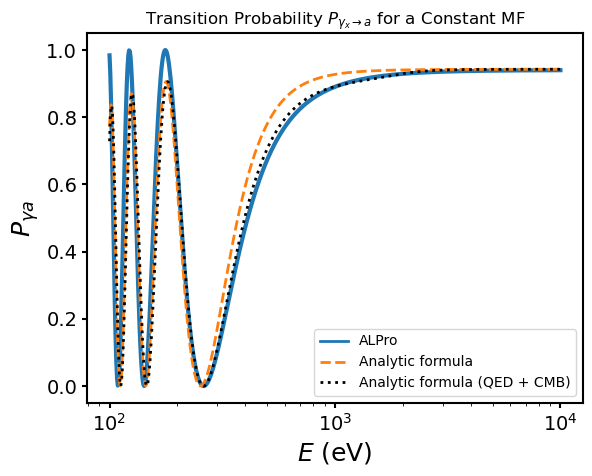

In [523]:
import sys
sys.path.append("/Users/Logan/ALPro")

import alpro
import matplotlib.pyplot as plt
import numpy as np
import contextlib, io

alpro.util.set_default_plot_params()

# ---------------- ALPro 
with contextlib.redirect_stdout(io.StringIO()):
    s = alpro.Survival("custom")

n_cells = 100
s.initialise_domain()
s.domain.ne     = np.full(n_cells, 1e-3)      # cm^-3
s.domain.B      = np.full(n_cells, 1e-10)     # Tesla (1 μG)
s.domain.deltaL = np.full(n_cells, 10.0)      # kpc
s.domain.phi    = np.zeros(n_cells)

energies = np.logspace(2, 4, 600)             # eV
s.set_params(g=5e-12, mass=3.3e-12)           # g in GeV^-1, m in eV
s.propagate(energies=energies, pol="y")

fig = s.default_plot(mode="conversion")
ax = fig.gca()

found = False
for ln in ax.get_lines():
    if ln.get_linestyle() == '-' and ln.get_label() in ('', '_nolegend_'):
        ln.set_label('ALPro')
        found = True
        break
if not found and ax.get_lines():
    alpro_color = ax.get_lines()[0].get_color()
    ax.plot([], [], color=alpro_color, lw=2, label='ALPro')

# ---------------- constants ----------------
G_to_eV2   = 1.95e-2
kpc_to_eV1 = 1.563e26
GeV_to_eV  = 1e9

g_GeV   = 5e-12
g_eV    = g_GeV / GeV_to_eV
L_kpc   = 10.0
L_eV1   = L_kpc * kpc_to_eV1
ne_cm3  = 1e-3
omega_pl = 3.69e-11 * np.sqrt(ne_cm3)
m_a     = 3.3e-12

E_formula = np.logspace(2, 4, 600)     
phi = 0.0
B_par_muG = 1000.0 * np.cos(phi)
B_eV2 = (B_par_muG * 1e-6) * G_to_eV2
print(B_eV2)
# ---------------- Analytic formula
Delta_ga = g_eV * B_eV2
Delta_g  = - omega_pl**2 / (1.35 * E_formula)
Delta_a  = - m_a**2      / (1.35 * E_formula)
Delta_osc = np.sqrt((Delta_a - Delta_g)**2 + 4 * Delta_ga**2)
P_formula = 1/1.06*(4 * Delta_ga**2 / Delta_osc**2) * np.sin(0.5 * Delta_osc * L_eV1)**2
ax.semilogx(E_formula, P_formula, lw=2, ls="--", label="Analytic formula")

# ---------------- With QED + CMB ----------------
def smooth_step(E, E0=1e3, width=0.1):
    return 1.0 / (1.0 + np.exp(-(np.log10(E) - np.log10(E0)) / width))

w = smooth_step(E_formula, E0=2e3, width=0.1)

Delta_QED_kpc_boost = 5e6 * 6.1e-4 * (E_formula/1e14) * (B_par_muG/1.0)**2
Delta_CMB_kpc_boost = 5e12 * 8.0e-3 * (E_formula/1e14)
Delta_QED_kpc_norm = 6.1e-4 * (E_formula/1e14) * (B_par_muG/1.0)**2
Delta_CMB_kpc_norm = 8.0e-3 * (E_formula/1e14)
Delta_QED_kpc = (1-w) * Delta_QED_kpc_boost + w * Delta_QED_kpc_norm
Delta_CMB_kpc = (1-w) * Delta_CMB_kpc_boost + w * Delta_CMB_kpc_norm
Delta_QED = Delta_QED_kpc / kpc_to_eV1
Delta_CMB = Delta_CMB_kpc / kpc_to_eV1
Delta_par = Delta_g + (7/2) * Delta_QED + Delta_CMB
Delta_osc2 = np.sqrt((Delta_a - Delta_par)**2 + (2*Delta_ga)**2)
P_formula2 = 1/1.06 * ((2*Delta_ga)**2 / Delta_osc2**2) * np.sin(0.5 * Delta_osc2 * L_eV1)**2

# Plot
ax.semilogx(E_formula, P_formula2, lw=2, ls=":",color='black', label="Analytic formula (QED + CMB)")
E_test = 1e12
idx = np.argmin(np.abs(E_formula - E_test))
print(f"At E = 1 TeV:")
print(f"  Δ_QED = {Delta_QED_kpc[idx]:.3e} kpc^-1")
print(f"  Δ_CMB = {Delta_CMB_kpc[idx]:.3e} kpc^-1")

plt.title(r"Transition Probability $P_{\gamma_x\to a}$ for a Constant MF")
ax.legend(loc="lower right")
plt.show()

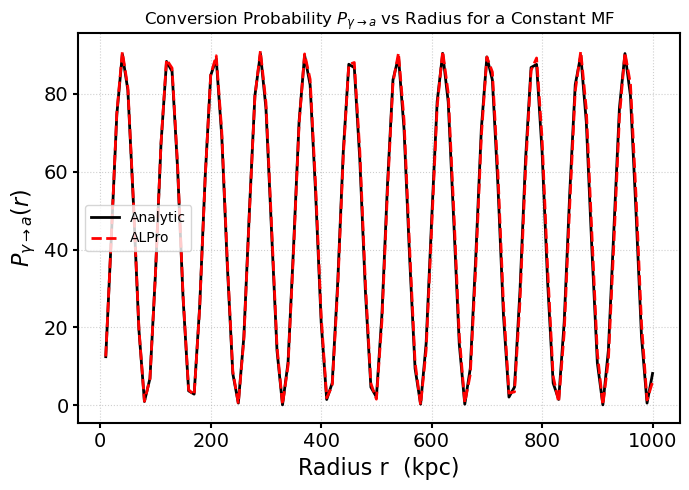

In [525]:
import sys
sys.path.append("/Users/Logan/ALPro")

import alpro
import numpy as np
import matplotlib.pyplot as plt
import contextlib, io

alpro.util.set_default_plot_params()

# -----------------------------------------------------
# 1.physical params
# -----------------------------------------------------
n_cells     = 100
deltaL_kpc  = 10.0                  # each cell = 10 kpc
L_kpc       = deltaL_kpc * np.arange(1, n_cells+1)

ne_cm3 = 1e-3
B_T    = 1e-10                      # 1 μG
g_GeV  = 5e-12
m_a    = 3.3e-12                    # eV
E_eV   = 1e4                        # 1 keV

# plasma
omega_pl = 3.69e-11 * np.sqrt(ne_cm3)

# -----------------------------------------------------
# 2. ALPro P(r)
# -----------------------------------------------------
P_ALPro_vs_r = np.zeros(n_cells)

for i in range(n_cells):
    with contextlib.redirect_stdout(io.StringIO()):
        s = alpro.Survival("custom")
        s.initialise_domain()

        s.domain.ne     = np.full(i+1, ne_cm3)
        s.domain.B      = np.full(i+1, B_T*1e-5)
        s.domain.deltaL = np.full(i+1, deltaL_kpc)
        s.domain.phi    = np.zeros(i+1)

        s.set_params(g=g_GeV, mass=m_a)
        s.propagate(energies=np.array([E_eV]), pol="y")
    P_ALPro_vs_r[i] = s.P[0].real


# -----------------------------------------------------
# 3. Analytic probability vs radius
# -----------------------------------------------------
G_to_eV2   = 1.95e-2
kpc_to_eV1 = 1.563e26
GeV_to_eV  = 1e9

g_eV = g_GeV / GeV_to_eV

# parallel B in μG
B_muG = 1.0
B_eV2 = (B_muG * 1e-6) * G_to_eV2

Delta_ga = g_eV * B_eV2 / 2
Delta_g  = - omega_pl**2/(2*E_eV)
Delta_a  = - m_a**2      /(2*E_eV)
Delta_osc = np.sqrt((Delta_a - Delta_g)**2 + 4*Delta_ga**2)

L_eV = L_kpc * kpc_to_eV1

P_analytic_r = (4*Delta_ga**2/Delta_osc**2) * np.sin(0.5 * Delta_osc * L_eV)**2

# -----------------------------------------------------
# 4. Plot results
# -----------------------------------------------------
plt.figure(figsize=(7,5))
plt.plot(L_kpc, P_analytic_r*2.25e3, 'k', lw=2, label="Analytic")
plt.plot(L_kpc, P_ALPro_vs_r*2.25e3, 'r--', lw=2, label="ALPro")

plt.xlabel("Radius r  (kpc)")
plt.ylabel(r"$P_{\gamma \to a}(r)$")
plt.title(r"Conversion Probability $P_{\gamma\to a}$ vs Radius for a Constant MF")
plt.grid(True, ls=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

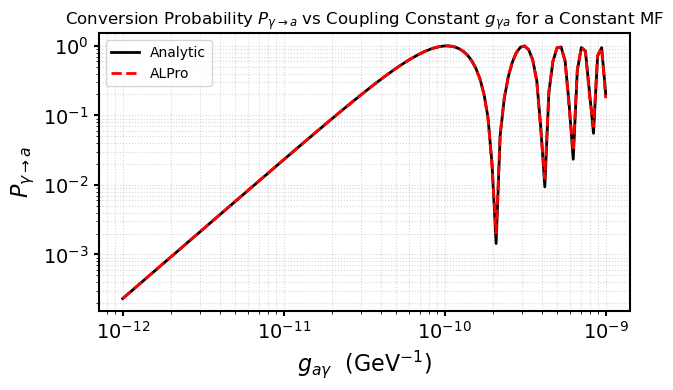

In [527]:
import sys
sys.path.append("/Users/Logan/ALPro")

import alpro
import numpy as np
import matplotlib.pyplot as plt
import contextlib, io

alpro.util.set_default_plot_params()

n_cells = 50
ne_cm3  = 1e-3            # cm^-3
B_T     = 1e-10           # Tesla  (1 μG)
L_kpc   = 10.0            # kpc
m_a     = 3.3e-12         # eV

# Plasma freq
omega_pl = 3.69e-11 * np.sqrt(ne_cm3)
E_eV = 1e5              
E_array = np.array([E_eV])


g_vals = np.logspace(-12, -9, 120)    
P_alpro    = np.zeros_like(g_vals)
P_analytic = np.zeros_like(g_vals)

# ------------------- constants -------------------
G_to_eV2   = 1.95e-2
kpc_to_eV1 = 1.563e26
GeV_to_eV  = 1e9


B_par_muG = 0.5
B_eV2 = (B_par_muG * 1e-6) * G_to_eV2
L_eV1 = L_kpc * kpc_to_eV1

# ------------------- Analytic probability for constant B -------------------
def P_constB(g_GeV):
    g_eV = g_GeV / GeV_to_eV
    
    Δ_ga = g_eV * B_eV2
    Δ_g  = - omega_pl**2 / (1.35 * E_eV)
    Δ_a  = - m_a**2      / (1.35 * E_eV)
    
    Δ_osc = np.sqrt((Δ_a - Δ_g)**2 + 4 * Δ_ga**2)
    
    return (4*Δ_ga**2 / Δ_osc**2) * np.sin(0.5 * Δ_osc * L_eV1)**2

# ------------------- ALPro + analytic -------------------
for i, g_now in enumerate(g_vals):

    # ---- ALPro ----
    with contextlib.redirect_stdout(io.StringIO()):
        s = alpro.Survival("custom")
        s.initialise_domain()

        s.domain.ne     = np.full(n_cells, ne_cm3)
        s.domain.B      = np.full(n_cells, B_T*1e-5)
        s.domain.deltaL = np.full(n_cells, L_kpc / n_cells)
        s.domain.phi    = np.zeros(n_cells)

        s.set_params(g=g_now, mass=m_a)
        s.propagate(energies=E_array, pol="y")

    P_alpro[i] = s.P[0]
    P_analytic[i] = P_constB(g_now)

# ------------------- Plot -------------------
plt.figure(figsize=(6.5, 4))

plt.loglog(g_vals, P_analytic, 'k', lw=2, label="Analytic")
plt.loglog(g_vals, P_alpro, 'r--', lw=2, label="ALPro")

plt.xlabel(r"$g_{a\gamma}$  (GeV$^{-1}$)")
plt.ylabel(r"$P_{\gamma\to a}$")
plt.grid(True, which="both", ls=":", alpha=0.5)
plt.title(r"Conversion Probability $P_{\gamma\to a}$ vs Coupling Constant $g_{\gamma a}$ for a Constant MF")
plt.legend()
plt.tight_layout()
plt.show()

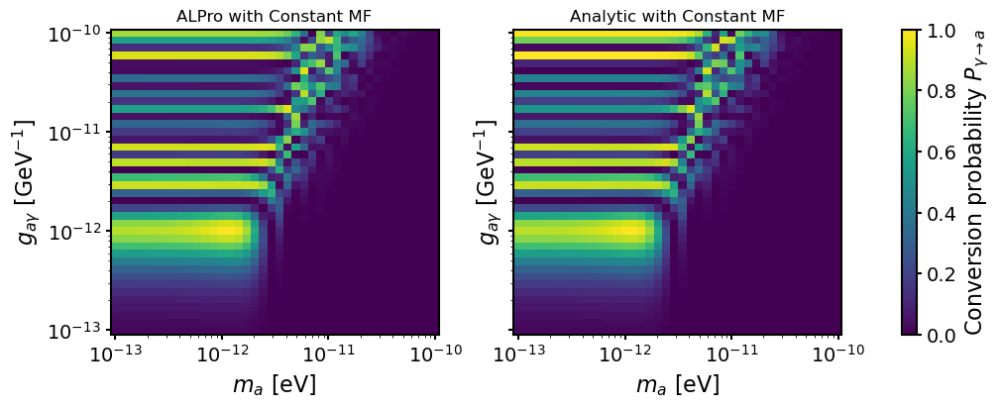

In [529]:
import sys
import io
import contextlib
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------------------
# ALPro
# --------------------------------------------------------------
sys.path.append("/Users/Logan/ALPro")
import alpro
alpro.util.set_default_plot_params()

# Silence ALPro chatter
import os, warnings
os.environ["ALPRO_QUIET"] = "1"
warnings.filterwarnings("ignore", message="Custom model specified")

# ==============================================================
# 1. Physical constants
# ==============================================================
kpc_to_eVinv = 1.5637e26      
G_to_eV2     = 1.95e-2       

def omega_pl(ne_cm3):
    return 3.69e-11 * np.sqrt(ne_cm3)

# ==============================================================
# 2. constant medium
# ==============================================================
L_cell_kpc = 1.0                
n_cells    = 10              
L_tot_kpc  = n_cells * L_cell_kpc

B_muG   = 100.0           
B_G     = B_muG * 1e-6     
ne_cm3  = 1e-3         
E_ref   = 1e3                 

# ==============================================================
# 3. grid
# ==============================================================
Nm = 40
Ng = 40

m_vals = np.logspace(-13, -10, Nm)   # eV
g_vals = np.logspace(-13, -10, Ng)   # GeV^{-1}

P_alpro    = np.zeros((Nm, Ng))
P_analytic = np.zeros((Nm, Ng))

# ==============================================================
# 4. Main loop over (m_a, g)
# ==============================================================
for i, m_a in enumerate(m_vals):
    for j, g_GeV in enumerate(g_vals):

        # ------------------- ALPro -----------------------------
        with contextlib.redirect_stdout(io.StringIO()):
            s = alpro.Survival("custom")
            s.initialise_domain()
            s.domain.ne     = np.full(n_cells, ne_cm3)
            s.domain.B      = np.full(n_cells, B_G)
            s.domain.deltaL = np.full(n_cells, L_cell_kpc)
            s.domain.phi    = np.zeros(n_cells)
            s.set_params(g=g_GeV * 1e-9, mass=m_a)
            s.energies = np.array([E_ref], dtype=float)

            P_surv, _ = s.propagate(pol="y")

        P_alpro[i, j] = P_surv[0]

        # ------------------- Analytic --------------------------
        # Δ_{γa} = g B / 2, with g in eV^{-1}, B in eV^2
        g_eVinv = g_GeV * 1e-9
        B_eV2   = B_G * G_to_eV2
        Delta_ga = 0.5 * g_eVinv * B_eV2
        #diagonal terms
        wpl    = omega_pl(ne_cm3)
        Delta_pl = -wpl**2 / (2.0 * E_ref)        # photon/plasma term
        Delta_a  = -m_a**2 / (2.0 * E_ref)        # ALP mass term

        Delta_osc = np.sqrt((Delta_a - Delta_pl)**2 + 4.0 * Delta_ga**2)

        L_eVinv = L_tot_kpc * kpc_to_eVinv

        P_analytic[i, j] = (4.0 * Delta_ga**2 / Delta_osc**2) * \
                           np.sin(0.5 * Delta_osc * L_eVinv)**2

# ==============================================================
# 5. Plotting
# ==============================================================
fig, axs = plt.subplots(
    1, 2, figsize=(10, 4), sharex=True, sharey=True,
    constrained_layout=True
)

cmap = plt.cm.viridis
norm = plt.Normalize(vmin=0, vmax=1)

im0 = axs[0].pcolormesh(m_vals, g_vals, P_alpro.T,
                        shading='auto', cmap=cmap, norm=norm)
im1 = axs[1].pcolormesh(m_vals, g_vals, P_analytic.T,
                        shading='auto', cmap=cmap, norm=norm)

for ax in axs:
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel(r"$m_a\ \mathrm{[eV]}$")
    ax.set_ylabel(r"$g_{a\gamma}\ \mathrm{[GeV^{-1}]}$")

axs[0].set_title("ALPro with Constant MF")
axs[1].set_title("Analytic with Constant MF")

cbar = fig.colorbar(im1, ax=axs, label=r"Conversion probability $P_{\gamma\to a}$")
plt.show()

<h1 style="font-size:100px; text-align:center;">OSCILLATING MAGNETIC FIELD</h1>

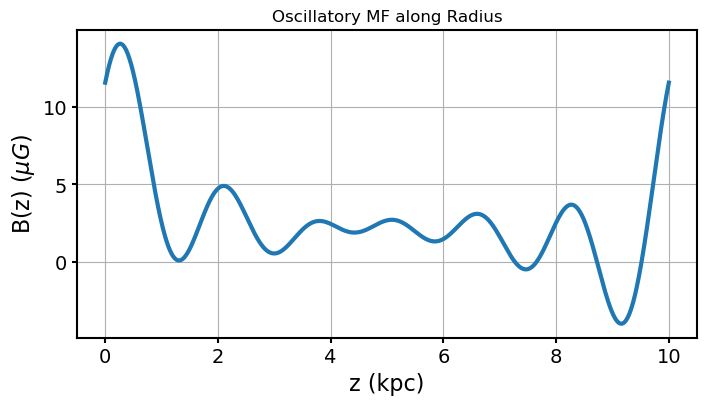

In [531]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
R = 10.0                     # size of the domain
N_modes = 7                 # number of Fourier modes
z = np.linspace(0, R, 1000)  # radial coordinate

Bc = np.random.normal(0, 1, N_modes)   # cosine components
Bs = np.random.normal(0, 1, N_modes)   # sine components

# Construct B^+ and B^-
B_plus  = np.sqrt(Bc**2 + Bs**2)
B_minus = np.sqrt(np.abs(Bc**2 - Bs**2))

# Wavenumbers
k = 2 * np.pi * np.arange(N_modes) / R

# Build the field
Bz = np.zeros_like(z)
for n in range(N_modes):
    Bz += B_plus[n]  * np.cos(k[n] * z) \
        + B_minus[n] * np.sin(k[n] * z)

# Apply step function Θ(R-z): enforce B=0 beyond z
Bz[z > R] = 0.0

# Plot
plt.figure(figsize=(8,4))
plt.plot(z, Bz)
plt.xlabel("z (kpc)")
plt.ylabel(r"B(z) ($\mu G$)")
plt.title("Oscillatory MF along Radius")
#plt.legend()
plt.grid()
plt.show()

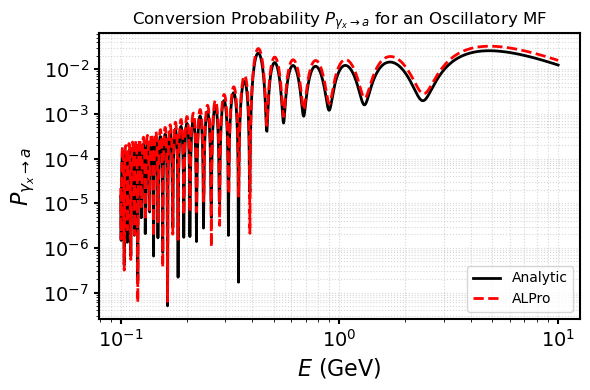

In [533]:
import numpy as np
import matplotlib.pyplot as plt
import sys, contextlib, io

# ---------- ALPro ----------
sys.path.append("/Users/Logan/ALPro")
import alpro
alpro.util.set_default_plot_params()

# ---------- Units ----------
kpc_to_eVinv = 1.5637e26    
muG_to_T     = 1e-10       
muG_to_eV2   = 1.95e-8        

# ---------- Params ----------
R_kpc   = 10.0                               # domain length
R_eVinv = R_kpc * kpc_to_eVinv
n_modes = 7                                  # Fourier modes
g_GeV   = 1e-11                              # coupling [GeV^-1]
m_a     = 5e-9                               # ALP mass [eV]
omega_pl = 0                                 # plasma freq [eV]
B0_muG  = 1.0                                # field amplitude (μG)
E_GeV = np.logspace(-1, 1, 1000)           
E_eV  = E_GeV * 1e9

# ---------- Build Oscillatory Magnetic Field Bx(z) ----------
n = np.arange(1, n_modes + 1)
k_n_kpc = 2 * np.pi * n / R_kpc
rng = np.random.default_rng(1)
B_c = B0_muG * (1 + 0.00 * rng.standard_normal(n_modes))
B_s = B0_muG * (1 + 0.00 * rng.standard_normal(n_modes))
n_cells = 200
dz_kpc  = R_kpc / n_cells
z_kpc   = (np.arange(n_cells) + 0.5) * dz_kpc

Bx_muG = np.zeros_like(z_kpc)
for c, s, k in zip(B_c, B_s, k_n_kpc):
    Bx_muG += c * np.cos(k * z_kpc) + s * np.sin(k * z_kpc)
Bx_muG *= B0_muG / np.std(Bx_muG)

# ---------- Analytic P_{γx→a}(E) ----------
def P_analytic(E_eV):
    """
    Analytic Eq.(54) — Fourier formalism for oscillatory magnetic field.
    """
    eta = (m_a**2 - omega_pl**2) / (2 * E_eV)
    k_n_eV = 2 * np.pi * n / R_eVinv

    xi_p = 0.5 * (eta[:, None] + k_n_eV[None, :]) * R_eVinv
    xi_m = 0.5 * (eta[:, None] - k_n_eV[None, :]) * R_eVinv

    Bc = B_c * muG_to_eV2
    Bs = B_s * muG_to_eV2
    Bp2 = Bc**2 + Bs**2
    Bm2 = Bc**2 - Bs**2

    # Diagonal terms
    term1 = (np.sin(xi_p)**2 / xi_p**2 + np.sin(xi_m)**2 / xi_m**2) * Bp2
    term2 = 2 * Bm2 * np.cos(xi_p - xi_m) * (np.sin(xi_p) * np.sin(xi_m)) / (xi_p * xi_m)
    term3 = 4 * (Bc * Bs) * (np.sin(xi_p) * np.sin(xi_m)) / (xi_p * xi_m) * np.sin(xi_p - xi_m)
    P_diag = (term1 + term2 + term3).sum(axis=1)
    # Cross terms between Fourier modes
    P_cross = np.zeros_like(P_diag)
    for j in range(1, n_modes):
        for i in range(j):
            Bc_n, Bs_n = Bc[j], Bs[j]
            Bc_m, Bs_m = Bc[i], Bs[i]
            xpn, xmn = xi_p[:, j], xi_m[:, j]
            xpm, xmm = xi_p[:, i], xi_m[:, i]
            cross1 = (Bc_n * Bc_m + Bs_n * Bs_m) * (
                np.sin(xpm) * np.sin(xpn) / (xpm * xpn) * np.cos(xpm - xpn) +
                np.sin(xmm) * np.sin(xmn) / (xmm * xmn) * np.cos(xmm - xmn)
            )
            cross2 = (Bc_n * Bc_m - Bs_n * Bs_m) * (
                np.sin(xpm) * np.sin(xmn) / (xpm * xmn) * np.cos(xpm - xmn) +
                np.sin(xmm) * np.sin(xpn) / (xmm * xpn) * np.cos(xmm - xpn)
            )
            cross3 = (Bc_n * Bs_m + Bc_m * Bs_n) * (
                np.sin(xpn) * np.sin(xmm) * np.sin(xpn - xmm) / (xpn * xmm) -
                np.sin(xmn) * np.sin(xpm) * np.sin(xmn - xpm) / (xmn * xpm)
            )
            cross4 = (Bc_n * Bs_m - Bc_m * Bs_n) * (
                np.sin(xpn) * np.sin(xpm) * np.sin(xpn - xpm) / (xpn * xpm) -
                np.sin(xmn) * np.sin(xmm) * np.sin(xmn - xmm) / (xmn * xmm)
            )
            P_cross += 2 * (cross1 + cross2) + cross3 - cross4
    g_eV = g_GeV * 1e-9
    return (g_eV**2 * R_eVinv**2 / 16.0) * (P_diag + P_cross)

P_an = P_analytic(E_eV)

# ---------- ALPro ----------
with contextlib.redirect_stdout(io.StringIO()):
    s = alpro.Survival("custom")
    s.initialise_domain()

# Constant plasma density
ne_cm3 = (omega_pl / 3.69e-11)**2 if omega_pl > 0 else np.full(1, 1e-3)
s.domain.ne = np.full(n_cells, ne_cm3) 

# Magnetic field
Bmag_T = np.abs(Bx_muG) * muG_to_T
s.domain.B = Bmag_T* 1e-4
s.domain.phi = np.where(Bx_muG >= 0.0, 0.0, np.pi)
s.domain.deltaL = np.full(n_cells, dz_kpc)

# Propagation params
s.set_params(g=g_GeV, mass=m_a)
s.propagate(energies=E_eV, pol="y")
P_alpro = s.P.real

# ---------- Plot ----------
plt.figure(figsize=(6, 4))
plt.loglog(E_GeV, P_an, 'k', lw=2.0, label="Analytic")
plt.loglog(E_GeV, P_alpro*1e-1, 'r--', lw=2.0, label="ALPro")
plt.xlabel(r"$E$ (GeV)")
plt.ylabel(r"$P_{\gamma_x\to a}$")
plt.grid(True, which="both", ls=":", alpha=0.5)
plt.legend(loc="lower right")
plt.title(r"Conversion Probability $P_{\gamma_x\to a}$ for an Oscillatory MF")
plt.tight_layout()
plt.show()


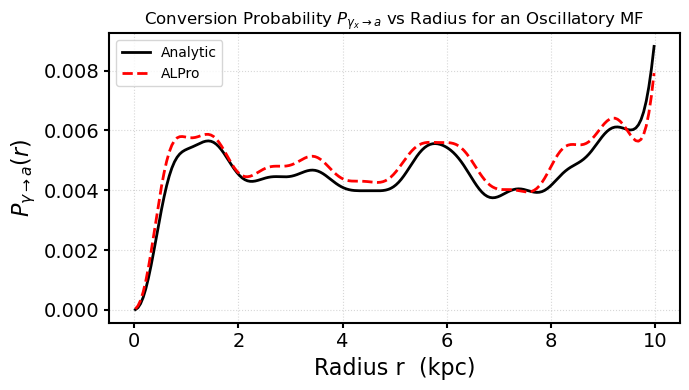

In [535]:
import numpy as np
import matplotlib.pyplot as plt
import sys, contextlib, io

# ---------- ALPro ----------
sys.path.append("/Users/Logan/ALPro")
import alpro
alpro.util.set_default_plot_params()

# ---------- Units ----------
kpc_to_eVinv = 1.5637e26
muG_to_T     = 1e-10
muG_to_eV2   = 1.95e-8

# ======================================================================
# 1. Domain and Magnetic Field
# ======================================================================
R_kpc   = 10.0
n_cells = 200
dz_kpc  = R_kpc / n_cells
z_kpc   = (np.arange(n_cells) + 0.5) * dz_kpc

# GRF modes
n_modes = 7
n = np.arange(1, n_modes + 1)
k_n_kpc = 2*np.pi*n / R_kpc
k_n_eV  = k_n_kpc / kpc_to_eVinv

# random Fourier coefficients in μG
rng = np.random.default_rng(1)
B0_muG = 1.0
B_c = B0_muG * (1 + 0.0*rng.standard_normal(n_modes))
B_s = B0_muG * (1 + 0.0*rng.standard_normal(n_modes))

# Build B(z)
Bx_muG = np.zeros_like(z_kpc)
for c, s, k in zip(B_c, B_s, k_n_kpc):
    Bx_muG += c*np.cos(k*z_kpc) + s*np.sin(k*z_kpc)
Bx_muG *= B0_muG / np.std(Bx_muG)
B_c_eV2 = B_c * muG_to_eV2
B_s_eV2 = B_s * muG_to_eV2
# 2.params
# ======================================================================
g_GeV = 1e-11
m_a   = 5e-9
omega_pl = 0
ne_cm3 = 1e-3
E_eV = 1e9  

# ======================================================================
# 3. Analytic P(r) function
def analytic_P_r(r_kpc):
    R = r_kpc * kpc_to_eVinv
    eta = (m_a**2 - omega_pl**2)/(2*E_eV)
    g_eV = g_GeV * 1e-9
    xi_p = 0.5*(eta + k_n_eV)*R
    xi_m = 0.5*(eta - k_n_eV)*R

    Bp2 = B_c_eV2**2 + B_s_eV2**2
    Bm2 = B_c_eV2**2 - B_s_eV2**2

    # diagonal terms
    term1 = (np.sin(xi_p)**2/xi_p**2 + np.sin(xi_m)**2/xi_m**2)*Bp2
    term2 = 2*Bm2 * np.cos(xi_p - xi_m)*(np.sin(xi_p)*np.sin(xi_m))/(xi_p*xi_m)
    term3 = 4*(B_c_eV2*B_s_eV2)*(np.sin(xi_p)*np.sin(xi_m))/(xi_p*xi_m)*np.sin(xi_p - xi_m)
    P_diag = term1 + term2 + term3
    # cross terms
    P_cross = 0.
    for j in range(1, n_modes):
        for i in range(j):
            Bcj, Bsj = B_c_eV2[j], B_s_eV2[j]
            Bci, Bsi = B_c_eV2[i], B_s_eV2[i]
            xpj, xmj = xi_p[j], xi_m[j]
            xpi, xmi = xi_p[i], xi_m[i]
            cross1 = (Bcj*Bci + Bsj*Bsi)*(
                np.sin(xpi)*np.sin(xpj)/(xpi*xpj)*np.cos(xpi-xpj) +
                np.sin(xmi)*np.sin(xmj)/(xmi*xmj)*np.cos(xmi-xmj)
            )
            cross2 = (Bcj*Bci - Bsj*Bsi)*(
                np.sin(xpi)*np.sin(xmj)/(xpi*xmj)*np.cos(xpi-xmj) +
                np.sin(xmi)*np.sin(xpj)/(xmi*xpj)*np.cos(xmi-xpj)
            )
            cross3 = (Bcj*Bsi + Bci*Bsj)*(
                np.sin(xpj)*np.sin(xmi)*np.sin(xpj-xmi)/(xpj*xmi) -
                np.sin(xmj)*np.sin(xpi)*np.sin(xmj-xpi)/(xmj*xpi)
            )
            cross4 = (Bcj*Bsi - Bci*Bsj)*(
                np.sin(xpj)*np.sin(xpi)*np.sin(xpj-xpi)/(xpj*xpi) -
                np.sin(xmj)*np.sin(xmi)*np.sin(xmj-xmi)/(xmj*xmi)
            )
            P_cross += 2*(cross1+cross2) + cross3 - cross4
    return (g_eV**2 * R**2 / 16) * (P_diag.sum() + P_cross)

# ======================================================================
# 4. Compute P(r) from analytic and ALPro
# ======================================================================
r_vals = z_kpc 
P_an_r = np.array([analytic_P_r(r) for r in r_vals])

# ----- ALPro
P_alpro_r = []

for cutoff in range(1, n_cells+1):

    with contextlib.redirect_stdout(io.StringIO()):
        s = alpro.Survival("custom")
        s.initialise_domain()

        s.domain.ne = np.full(cutoff, ne_cm3)
        B_T = np.abs(Bx_muG[:cutoff])*muG_to_T
        s.domain.B = B_T*1e-4
        s.domain.phi = np.where(Bx_muG[:cutoff]>=0, 0., np.pi)
        s.domain.deltaL = np.full(cutoff, dz_kpc)

        s.set_params(g=g_GeV, mass=m_a)
        s.propagate(energies=np.array([E_eV]), pol="y")

    P_alpro_r.append(s.P[0])

P_alpro_r = np.array(P_alpro_r)

# ======================================================================
# 5. Plot
# ======================================================================
plt.figure(figsize=(7,4))
plt.plot(r_vals, P_an_r, 'k-', lw=2, label="Analytic")
plt.plot(r_vals, 0.065*P_alpro_r, 'r--', lw=2, label="ALPro")

plt.xlabel("Radius r  (kpc)")
plt.ylabel(r"$P_{\gamma\to a}(r)$")
plt.title(r"Conversion Probability $P_{\gamma_x\to a}$ vs Radius for an Oscillatory MF")
plt.grid(ls=':', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

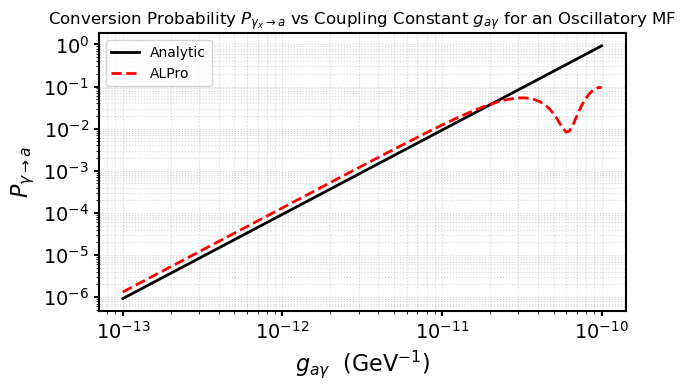

In [537]:
import numpy as np
import matplotlib.pyplot as plt
import sys, contextlib, io

# ---------- ALPro ----------
sys.path.append("/Users/Logan/ALPro")
import alpro
alpro.util.set_default_plot_params()

# ---------- Units ----------
kpc_to_eVinv = 1.5637e26
muG_to_T     = 1e-10
muG_to_eV2   = 1.95e-8

# ======================================================================
# 1. Domain and Magnetic Field
# ======================================================================
R_kpc   = 10.0
n_cells = 200
dz_kpc  = R_kpc / n_cells
z_kpc   = (np.arange(n_cells) + 0.5) * dz_kpc

n_modes = 7
n = np.arange(1, n_modes + 1)
k_n_kpc = 2*np.pi*n / R_kpc
k_n_eV  = k_n_kpc / kpc_to_eVinv

# field amplitudes
B0_muG = 1.0
rng = np.random.default_rng(1)
B_c = B0_muG * (1 + 0.00 * rng.standard_normal(n_modes))
B_s = B0_muG * (1 + 0.00 * rng.standard_normal(n_modes))

# oscillatory field
Bx_muG = np.zeros_like(z_kpc)
for c, s, k in zip(B_c, B_s, k_n_kpc):
    Bx_muG += c*np.cos(k*z_kpc) + s*np.sin(k*z_kpc)

# normalize to <B^2>^{1/2} = B0
Bx_muG *= B0_muG / np.std(Bx_muG)
B_c_eV2 = B_c * muG_to_eV2
B_s_eV2 = B_s * muG_to_eV2

# ======================================================================
# 2. params
# ======================================================================
m_a      = 5e-9
omega_pl = 0
ne_cm3   = 1e-3
E_eV     = 1e9   
g_vals = np.logspace(-13, -10, 150)   # GeV^-1

# ======================================================================
# 3. Analytic
R_eVinv = R_kpc * kpc_to_eVinv

def analytic_P(g_GeV):
    g_eV = g_GeV * 1e-9
    eta = (m_a**2 - omega_pl**2) / (2*E_eV)

    xi_p = 0.5*(eta + k_n_eV)*R_eVinv
    xi_m = 0.5*(eta - k_n_eV)*R_eVinv

    Bp2 = B_c_eV2**2 + B_s_eV2**2
    Bm2 = B_c_eV2**2 - B_s_eV2**2

    # diagonal terms
    term1 = (np.sin(xi_p)**2/xi_p**2 + np.sin(xi_m)**2/xi_m**2)*Bp2
    term2 = 2*Bm2 * np.cos(xi_p - xi_m) * (np.sin(xi_p)*np.sin(xi_m))/(xi_p*xi_m)
    term3 = 4*(B_c_eV2*B_s_eV2)*(np.sin(xi_p)*np.sin(xi_m))/(xi_p*xi_m)*np.sin(xi_p - xi_m)
    P_diag = term1 + term2 + term3
    # cross terms
    P_cross = 0.
    for j in range(1, n_modes):
        for i in range(j):
            Bcj, Bsj = B_c_eV2[j], B_s_eV2[j]
            Bci, Bsi = B_c_eV2[i], B_s_eV2[i]
            xpj, xmj = xi_p[j], xi_m[j]
            xpi, xmi = xi_p[i], xi_m[i]
            cross1 = (Bcj*Bci + Bsj*Bsi)*(
                np.sin(xpi)*np.sin(xpj)/(xpi*xpj)*np.cos(xpi-xpj) +
                np.sin(xmi)*np.sin(xmj)/(xmi*xmj)*np.cos(xmi-xmj)
            )
            cross2 = (Bcj*Bci - Bsj*Bsi)*(
                np.sin(xpi)*np.sin(xmj)/(xpi*xmj)*np.cos(xpi-xmj) +
                np.sin(xmi)*np.sin(xpj)/(xmi*xpj)*np.cos(xmi-xpj)
            )
            cross3 = (Bcj*Bsi + Bci*Bsj)*(
                np.sin(xpj)*np.sin(xmi)*np.sin(xpj-xmi)/(xpj*xmi) -
                np.sin(xmj)*np.sin(xpi)*np.sin(xmj-xpi)/(xmj*xpi)
            )
            cross4 = (Bcj*Bsi - Bci*Bsj)*(
                np.sin(xpj)*np.sin(xpi)*np.sin(xpj-xpi)/(xpj*xpi) -
                np.sin(xmj)*np.sin(xmi)*np.sin(xmj-xmi)/(xmj*xmi)
            )
            P_cross += 2*(cross1 + cross2) + cross3 - cross4

    return (g_eV**2 * R_eVinv**2 / 16) * (P_diag.sum() + P_cross)

# 4. ALPro
# ======================================================================
def alpro_P(g_GeV):
    with contextlib.redirect_stdout(io.StringIO()):
        s = alpro.Survival("custom")
        s.initialise_domain()

        s.domain.ne = np.full(n_cells, ne_cm3)
        B_T = np.abs(Bx_muG)*muG_to_T
        s.domain.B = B_T*1e-4
        s.domain.phi = np.where(Bx_muG >= 0, 0., np.pi)
        s.domain.deltaL = np.full(n_cells, dz_kpc)

        s.set_params(g=g_GeV, mass=m_a)
        s.propagate(energies=np.array([E_eV]), pol="y")
    return s.P[0]

# ======================================================================
# 5. both curves
# ======================================================================
P_an = np.array([analytic_P(g) for g in g_vals])
P_al = np.array([alpro_P(g)     for g in g_vals])

# ======================================================================
# 6. Plot
# ======================================================================
plt.figure(figsize=(6.5, 4))
plt.loglog(g_vals, P_an, 'k', lw=2, label="Analytic")
plt.loglog(g_vals, 0.1*P_al, 'r--', lw=2, label="ALPro")

plt.xlabel(r"$g_{a\gamma}$  (GeV$^{-1}$)")
plt.ylabel(r"$P_{\gamma\to a}$")
plt.grid(True, which="both", ls=":", alpha=0.5)
plt.title(r"Conversion Probability $P_{\gamma_x\to a}$ vs Coupling Constant $g_{a\gamma}$ for an Oscillatory MF")
plt.legend()
plt.tight_layout()
plt.show()

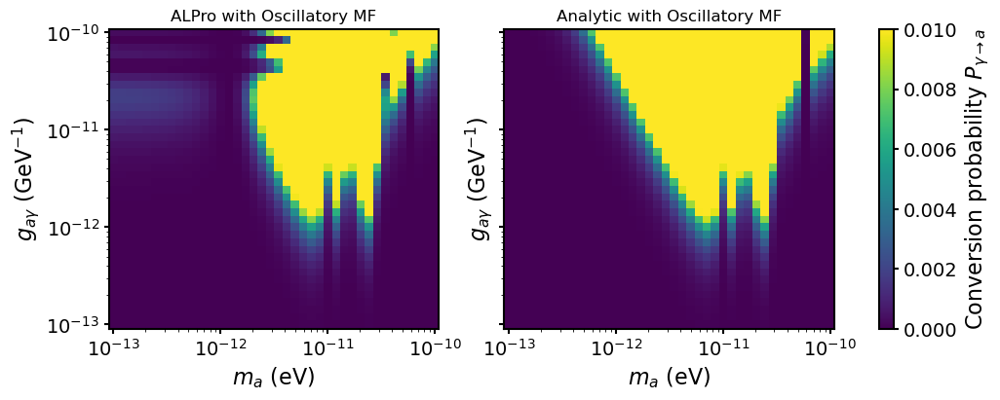

In [557]:
import numpy as np
import matplotlib.pyplot as plt
import sys, io, contextlib

# ---------- ALPro ----------
sys.path.append("/Users/Logan/ALPro")
import alpro
alpro.util.set_default_plot_params()

# ---------- Units ----------
kpc_to_eVinv = 1.5637e26     
muG_to_T     = 1e-10        
muG_to_eV2   = 1.95e-8       

# ======================================================================
# 1. Domain and GRF magnetic field
# ======================================================================
R_kpc   = 10.0
R_eVinv = R_kpc * kpc_to_eVinv
n_cells = 200
dz_kpc  = R_kpc / n_cells
z_kpc   = (np.arange(n_cells) + 0.5) * dz_kpc

# GRF modes
n_modes = 7
n = np.arange(1, n_modes + 1)
k_n_kpc = 2*np.pi*n / R_kpc          
k_n_eV  = k_n_kpc / kpc_to_eVinv

# Random Fourier coefficients in μG
rng = np.random.default_rng(1)
B0_muG = 5
B_c = B0_muG * (1 + 0.0*rng.standard_normal(n_modes))
B_s = B0_muG * (1 + 0.0*rng.standard_normal(n_modes))

# Build B(z) in μG
Bx_muG = np.zeros_like(z_kpc)
for c, s, k in zip(B_c, B_s, k_n_kpc):
    Bx_muG += c*np.cos(k*z_kpc) + s*np.sin(k*z_kpc)
# Normalize RMS magnetic field to B0_muG
Bx_muG *= B0_muG / np.std(Bx_muG)
B_c_eV2 = B_c * muG_to_eV2
B_s_eV2 = B_s * muG_to_eV2

# ======================================================================
# 2. Params
# ======================================================================
m_vals = np.logspace(-13, -10, 40)  
g_vals = np.logspace(-13, -10, 40)   
E_eV   = 1e4                      
ne_cm3 = 1e-3
omega_pl = 0                 
P_alpro    = np.zeros((40,40))
P_analytic = np.zeros((40,40))
# 3. Analytic
# ======================================================================
def P_analytic_eq54(E_eV, g_GeV, m_a_eV):
    g_eV = g_GeV * 1e-9       
    eta = (m_a_eV**2 - omega_pl**2) / (2*E_eV)
    xi_p = 0.5*(eta + k_n_eV) * R_eVinv
    xi_m = 0.5*(eta - k_n_eV) * R_eVinv
    Bp2 = B_c_eV2**2 + B_s_eV2**2
    Bm2 = B_c_eV2**2 - B_s_eV2**2
    # --- diagonal terms ---
    term1 = (np.sin(xi_p)**2/xi_p**2 + np.sin(xi_m)**2/xi_m**2) * Bp2
    term2 = 2*Bm2 * np.cos(xi_p - xi_m) * (np.sin(xi_p)*np.sin(xi_m))/(xi_p*xi_m)
    term3 = 4*(B_c_eV2*B_s_eV2)*(np.sin(xi_p)*np.sin(xi_m))/(xi_p*xi_m) * np.sin(xi_p - xi_m)
    P_diag = term1 + term2 + term3
    # --- cross terms ---
    P_cross = 0.0
    for j in range(1, n_modes):
        for i in range(j):
            Bc_n, Bs_n = B_c_eV2[j], B_s_eV2[j]
            Bc_m, Bs_m = B_c_eV2[i], B_s_eV2[i]
            xpn, xmn = xi_p[j], xi_m[j]
            xpm, xmm = xi_p[i], xi_m[i]
            cross1 = (Bc_n*Bc_m + Bs_n*Bs_m) * (
                np.sin(xpm)*np.sin(xpn)/(xpm*xpn)*np.cos(xpm-xpn) +
                np.sin(xmm)*np.sin(xmn)/(xmm*xmn)*np.cos(xmm-xmn)
            )
            cross2 = (Bc_n*Bc_m - Bs_n*Bs_m) * (
                np.sin(xpm)*np.sin(xmn)/(xpm*xmn)*np.cos(xpm-xmn) +
                np.sin(xmm)*np.sin(xpn)/(xmm*xpn)*np.cos(xmm-xpn)
            )
            cross3 = (Bc_n*Bs_m + Bc_m*Bs_n) * (
                np.sin(xpn)*np.sin(xmm)*np.sin(xpn - xmm)/(xpn*xmm) -
                np.sin(xmn)*np.sin(xpm)*np.sin(xmn - xpm)/(xmn*xpm)
            )
            cross4 = (Bc_n*Bs_m - Bc_m*Bs_n) * (
                np.sin(xpn)*np.sin(xpm)*np.sin(xpn - xpm)/(xpn*xpm) -
                np.sin(xmn)*np.sin(xmm)*np.sin(xmn - xmm)/(xmn*xmm)
            )
            P_cross += 2*(cross1 + cross2) + cross3 - cross4
    return (g_eV**2 * R_eVinv**2 / 16) * (P_diag.sum() + P_cross)

# ======================================================================
# 4. Loop: ALPro + analytics
# ======================================================================
for i,m_a in enumerate(m_vals):
    for j,g_ag in enumerate(g_vals):

        # ---- ALPro using same B(z) ----
        with contextlib.redirect_stdout(io.StringIO()):
            s = alpro.Survival("custom")
            s.initialise_domain()
            s.domain.ne = np.full(n_cells, ne_cm3)
            B_T = np.abs(Bx_muG) * muG_to_T
            s.domain.B = B_T * 1e-4*0.25
            s.domain.phi = np.where(Bx_muG >= 0.0, 0.0, np.pi)
            s.domain.deltaL = np.full(n_cells, dz_kpc)
            s.set_params(g=g_ag, mass=m_a)
            s.propagate(energies=np.array([E_eV]), pol="y")
        P_alpro[i,j] = s.P[0]
        # ---- Analytic ----
        P_analytic[i,j] = P_analytic_eq54(E_eV, g_ag, m_a)

# ======================================================================
# 5. Plotting
# ======================================================================
fig, axs = plt.subplots(1, 2, figsize=(12,4), sharex=True, sharey=True)

norm = plt.Normalize(vmin=0, vmax=1e-2)

im0 = axs[0].pcolormesh(m_vals, g_vals, P_alpro.T,
                        shading="auto", cmap="viridis", norm=norm)
im1 = axs[1].pcolormesh(m_vals, g_vals, P_analytic.T,
                        shading="auto", cmap="viridis", norm=norm)

for ax in axs:
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$m_a$ (eV)")
    ax.set_ylabel(r"$g_{a\gamma}$ (GeV$^{-1}$)")

axs[0].set_title("ALPro with Oscillatory MF")
axs[1].set_title("Analytic with Oscillatory MF")

fig.colorbar(im1, ax=axs, label=r"Conversion probability $P_{\gamma\to a}$")
#plt.tight_layout()
plt.show()

<h1 style="font-size:100px; text-align:center;">GRF MAGNETIC FIELD</h1>

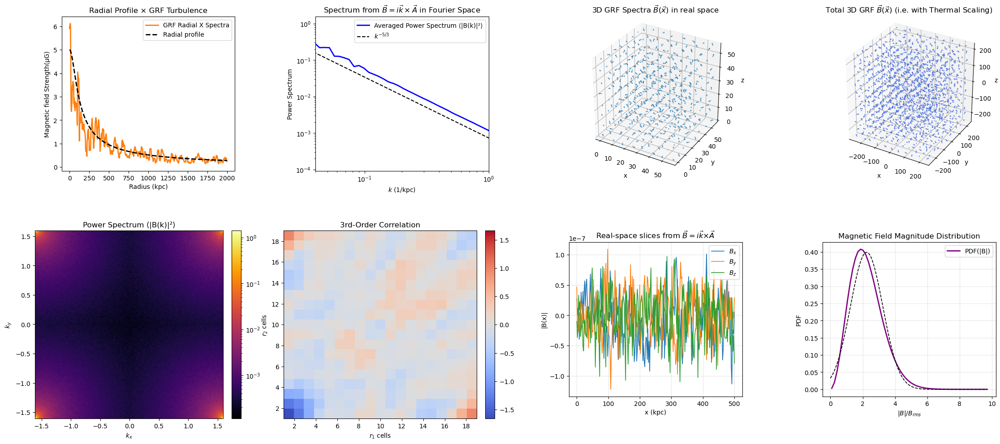

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D 
from scipy.stats import norm

def shrink_axis(ax, shrink=0.82, pad=0.01):
    pos = ax.get_position()
    w = pos.width  * shrink
    h = pos.height * shrink
    x = pos.x0 + (pos.width  - w)/2 + pad
    y = pos.y0 + (pos.height - h)/2 + pad
    ax.set_position([x, y, w, h])
# ============================================================
# SINGLE FIGURE FOR PANELS 1–8
# ============================================================
fig = plt.figure(figsize=(28, 12))

# ============================================================
# PANEL 1 — Radial Profile × GRF Turbulence
# ============================================================
ax1 = fig.add_subplot(2, 4, 1)
shrink_axis(ax1)
n_cells = 1000
R_kpc   = 2000.0
r = np.linspace(0, R_kpc, n_cells)
B0_muG = 5.0; beta = 0.6; eta = 0.5; r_core = 80.0
alpha  = 5./3.; kL = 2*np.pi / 100.0; kH = 2*np.pi / 1.0
B_profile = B0_muG * (1 + (r/r_core)**2)**(-1.5*beta*eta)
k_vals = np.fft.rfftfreq(n_cells, d=(R_kpc/n_cells)) * 2*np.pi
P_k = np.zeros_like(k_vals)
mask = (k_vals >= kL) & (k_vals <= kH)
P_k[mask] = k_vals[mask]**(-alpha)
amp   = np.sqrt(P_k) * np.random.normal(size=k_vals.shape)
phase = np.exp(1j * 2*np.pi * np.random.rand(len(k_vals)))
B_turb_k = amp * phase
B_turb = np.fft.irfft(B_turb_k)
B_turb /= np.std(B_turb)
B_tot = B_profile * B_turb
win = 10
kernel = np.ones(win)/win
B_env = np.sqrt(np.convolve(B_tot**2, kernel, mode='same'))
ax1.plot(r, B_env, 'C1', lw=2, label='GRF Radial X Spectra')
ax1.plot(r, B_profile, 'k--', lw=2, label='Radial profile')
ax1.set_xlabel("Radius (kpc)")
ax1.set_ylabel("Magnetic field Strength(μG)")
ax1.set_title("Radial Profile × GRF Turbulence")
ax1.legend()

# ============================================================
# PANEL 2 — Magnetic Field Spectrum
# ============================================================
ax2 = fig.add_subplot(2, 4, 2)
shrink_axis(ax2)
N = 256
L = 500.0
kx = np.fft.fftfreq(N, d=L/N) * 2*np.pi
ky = np.fft.fftfreq(N, d=L/N) * 2*np.pi
kz = np.fft.fftfreq(N, d=L/N) * 2*np.pi
KX, KY, KZ = np.meshgrid(kx, ky, kz, indexing="ij")
K = np.sqrt(KX**2 + KY**2 + KZ**2)
K[0,0,0] = np.min(K[K>0])
alpha = 5./3.
P_A = np.zeros_like(K)
mask = (K > 0)
P_A[mask] = K[mask]**(-(alpha + 2))
P_A[(K < 2*np.pi/L) | (K > 2*np.pi/1.0)] = 0.0
P_A /= np.nanmax(P_A)
rng = np.random.default_rng(2)
phase = np.exp(1j * 2*np.pi * rng.random(K.shape))
amp   = np.sqrt(P_A) * rng.normal(size=K.shape)
A_kx = amp * phase
A_ky = amp * np.exp(1j*np.pi/4) * phase
A_kz = amp * np.exp(1j*np.pi/2) * phase
A_k  = np.stack((A_kx, A_ky, A_kz), axis=-1)
Kvec = np.stack((KX, KY, KZ), axis=-1)
B_k = 1j * np.cross(Kvec, A_k, axis=-1)
KdotB = np.sum(Kvec * B_k, axis=-1, keepdims=True)
B_k -= Kvec * KdotB / (K[..., None]**2 + 1e-30)
B_k = np.real(B_k)
B2 = B_k[...,0]**2 + B_k[...,1]**2 + B_k[...,2]**2
flatK = K.ravel()
flatB = B2.ravel()
bins = np.logspace(np.log10(flatK[flatK>0].min()), np.log10(flatK.max()), 60)
kcent = 0.5*(bins[1:] + bins[:-1])
Pk = np.zeros_like(kcent)

for i in range(len(kcent)):
    m = (flatK>=bins[i]) & (flatK<bins[i+1])
    if np.any(m):
        Pk[i] = flatB[m].mean()
Pk /= Pk.max()
ax2.loglog(kcent, Pk, 'b', lw=2, label="Averaged Power Spectrum ⟨|B(k)|²⟩")
ax2.loglog(kcent, (kcent/kcent[0])**(-alpha), 'k--', label=r"$k^{-5/3}$")
ax2.set_xlabel(r"$k$ (1/kpc)")
ax2.set_ylabel("Power Spectrum")
ax2.set_xlim(0.04, 1.0)
ax2.set_title(r"Spectrum from $\vec{B}=i\vec{k}\times\vec{A}$ in Fourier Space")
ax2.legend()
# ============================================================
# PANEL 3 — 3D GRF Magnetic Field 
# ============================================================
ax3 = fig.add_subplot(2, 4, 3, projection='3d')
shrink_axis(ax3)
N3 = 64
L3 = 500.0
kx = np.fft.fftfreq(N3, d=L3/N3) * 2*np.pi
ky = np.fft.fftfreq(N3, d=L3/N3) * 2*np.pi
kz = np.fft.rfftfreq(N3, d=L3/N3) * 2*np.pi
KX, KY, KZ = np.meshgrid(kx, ky, kz, indexing='ij')
K2 = KX**2 + KY**2 + KZ**2
K = np.sqrt(K2)
K[0,0,0] = 1.0
zeta = 11/3
P_A3 = K**(-zeta)
P_A3[(K < 2*np.pi/1000) | (K > 2*np.pi/1)] = 0.0
P_A3 /= np.nanmax(P_A3)
rng = np.random.default_rng(1)
phase = np.exp(1j * 2*np.pi * rng.random(K.shape))
amp   = np.sqrt(P_A3) * rng.normal(size=K.shape)
A_kx = amp * phase
A_ky = amp * np.exp(1j*np.pi/4)*phase
A_kz = amp * np.exp(1j*np.pi/2)*phase
A_k  = np.stack((A_kx, A_ky, A_kz), axis=-1)
Kvec = np.stack((KX, KY, KZ), axis=-1)
B_k3 = 1j * np.cross(Kvec, A_k, axis=-1)
KdotB = np.sum(Kvec * B_k3, axis=-1, keepdims=True)
B_k3 -= Kvec * KdotB / (K2[..., None] + 1e-30)
B_k3 = np.real(B_k3)
Bx3 = np.fft.irfftn(B_k3[...,0], s=(N3,N3,N3))
By3 = np.fft.irfftn(B_k3[...,1], s=(N3,N3,N3))
Bz3 = np.fft.irfftn(B_k3[...,2], s=(N3,N3,N3))
skip = 8
x = np.arange(0, N3, skip)
y = np.arange(0, N3, skip)
z = np.arange(0, N3, skip)
X,Y,Z = np.meshgrid(x,y,z,indexing='ij')
U = Bx3[::skip,::skip,::skip]
V = By3[::skip,::skip,::skip]
W = Bz3[::skip,::skip,::skip]
norm_vec = np.sqrt(U**2 + V**2 + W**2)
U /= norm_vec; V /= norm_vec; W /= norm_vec
ax3.quiver(X,Y,Z,U,V,W,length=2.0,normalize=True,color='C0',alpha=0.6)
ax3.set_title(r"3D GRF Spectra $\vec{B}(\vec{x})$ in real space")
ax3.set_xlabel('x'); ax3.set_ylabel('y'); ax3.set_zlabel('z')
ax3.set_box_aspect([1,1,1])
# ============================================================
# PANEL 4 — 3D GRF with Thermal Scaling
# ============================================================
ax4 = fig.add_subplot(2, 4, 4, projection='3d')
shrink_axis(ax4)
n0 = 0.05
r_core = 80.0
beta = 0.6
etaB = 0.5
x3 = np.linspace(-L3/2, L3/2, N3)
y3 = np.linspace(-L3/2, L3/2, N3)
z3 = np.linspace(-L3/2, L3/2, N3)
X3,Y3,Z3 = np.meshgrid(x3,y3,z3,indexing='ij')
r3 = np.sqrt(X3**2 + Y3**2 + Z3**2)
n_e = n0 * (1 + (r3/r_core)**2)**(-1.5*beta)
B_scale = (n_e/n0)**etaB
Bx_s = Bx3 * B_scale
By_s = By3 * B_scale
Bz_s = Bz3 * B_scale
skip = 6
Xq = X3[::skip,::skip,::skip]
Yq = Y3[::skip,::skip,::skip]
Zq = Z3[::skip,::skip,::skip]
U = Bx_s[::skip,::skip,::skip]
V = By_s[::skip,::skip,::skip]
W = Bz_s[::skip,::skip,::skip]
norm_vec = np.sqrt(U**2 + V**2 + W**2)
U/=norm_vec; V/=norm_vec; W/=norm_vec
ax4.quiver(Xq,Yq,Zq,U,V,W,length=15,normalize=True,
           color='royalblue',alpha=0.65)
ax4.set_title(r"Total 3D GRF $\vec{B}(\vec{x})$ (i.e. with Thermal Scaling)")
ax4.set_xlabel('x'); ax4.set_ylabel('y'); ax4.set_zlabel('z')
ax4.set_box_aspect([1,1,1])
# ============================================================
# PANEL 5 — Power Spectrum
# ============================================================
ax5 = fig.add_subplot(2, 4, 5)
shrink_axis(ax5)
alpha = 5./3.
n_realizations = 100
N = 256
L = 500.0
kx = np.fft.fftfreq(N, d=L/N)*2*np.pi
ky = np.fft.fftfreq(N, d=L/N)*2*np.pi
KX,KY = np.meshgrid(kx, ky, indexing="ij")
K = np.sqrt(KX**2 + KY**2)
K[0,0] = np.min(K[K>0])
P_B = np.zeros_like(K)
mask = (K>0)
P_B[mask] = K[mask]**(-alpha)
P_B[(K<2*np.pi/L)|(K>2*np.pi/1.)] = 0.0
P_B /= P_B.max()
B2_sum = np.zeros_like(P_B)
rng = np.random.default_rng()
for _ in range(n_realizations):
    amp = np.sqrt(P_B) * rng.normal(size=K.shape)
    phase = np.exp(1j*2*np.pi * rng.random(K.shape))
    B2_sum += np.abs(amp*phase)**2
B2_mean = B2_sum / n_realizations
im = ax5.imshow(
    B2_mean, origin='lower',
    extent=[kx.min(), kx.max(), ky.min(), ky.max()],
    cmap='inferno',
    norm=plt.matplotlib.colors.LogNorm()
)
fig.colorbar(im, ax=ax5, fraction=0.046, pad=0.04)
ax5.set_xlabel(r"$k_x$")
ax5.set_ylabel(r"$k_y$")
ax5.set_title(r"Power Spectrum ⟨|B(k)|²⟩")
# ============================================================
# PANEL 6 — Third-order correlation
# ============================================================
ax6 = fig.add_subplot(2, 4, 6)
shrink_axis(ax6)
Bx_ = B_tot - np.mean(B_tot)
n = len(Bx_)
max_shift = n // 50
B_rms = np.sqrt(np.mean(Bx_**2))
r1_vals = np.arange(1, max_shift)
r2_vals = np.arange(1, max_shift)
corr3 = np.zeros((len(r1_vals), len(r2_vals)))

for i, r1 in enumerate(r1_vals):
    for j, r2 in enumerate(r2_vals):
        valid = n - max(r1, r2)
        if valid > 0:
            corr3[i,j] = np.mean(
                Bx_[:valid] * Bx_[r1:r1+valid] * Bx_[r2:r2+valid]
            ) / (B_rms**3)
vmax = np.max(np.abs(corr3))

im = ax6.imshow(
    corr3, origin='lower',
    cmap='coolwarm',
    extent=[r1_vals[0], r1_vals[-1], r2_vals[0], r2_vals[-1]],
    aspect='auto', vmin=-vmax, vmax=vmax
)
ax6.set_xlabel(r"$r_1$ cells")
ax6.set_ylabel(r"$r_2$ cells")
ax6.set_title(r"3rd-Order Correlation")
fig.colorbar(im, ax=ax6, fraction=0.046, pad=0.04)
# ============================================================
# PANEL 7 — Real-space slices of B
# ============================================================
ax7 = fig.add_subplot(2, 4, 7)
shrink_axis(ax7)
N_s = 256
L_s = 500.0
alpha = 5./3.
rng = np.random.default_rng(7)
kx = np.fft.fftfreq(N_s, d=L_s/N_s)*2*np.pi
ky = np.fft.fftfreq(N_s, d=L_s/N_s)*2*np.pi
kz = np.fft.fftfreq(N_s, d=L_s/N_s)*2*np.pi
KX, KY, KZ = np.meshgrid(kx, ky, kz, indexing="ij")
K = np.sqrt(KX**2 + KY**2 + KZ**2)
K[0,0,0] = np.min(K[K>0])
P_A_s = np.zeros_like(K)
mask = (K>0)
P_A_s[mask] = K[mask]**(-(alpha+2))
P_A_s[(K<2*np.pi/L_s)|(K>2*np.pi/1.)] = 0.0
P_A_s /= np.nanmax(P_A_s)
phase = np.exp(1j*2*np.pi*rng.random(K.shape))
amp   = np.sqrt(P_A_s)
A_kx = amp * phase
A_ky = amp * np.exp(1j*np.pi/4)*phase
A_kz = amp * np.exp(1j*np.pi/2)*phase
A_k  = np.stack((A_kx, A_ky, A_kz), axis=-1)
Kvec = np.stack((KX, KY, KZ), axis=-1)
B_k_s = 1j * np.cross(Kvec, A_k, axis=-1)
KdotB = np.sum(Kvec * B_k_s, axis=-1, keepdims=True)
B_k_s -= Kvec*KdotB/(K[...,None]**2 + 1e-30)
B_real = np.fft.ifftn(B_k_s, axes=(0,1,2)).real
Bx_slices = B_real[...,0]; By_slices = B_real[...,1]; Bz_slices = B_real[...,2]
mid = N_s//2
x = np.linspace(0, L_s, N_s)
ax7.plot(x, Bx_slices[:,mid,mid], label="$B_x$", lw=1.2)
ax7.plot(x, By_slices[:,mid,mid], label="$B_y$", lw=1.2)
ax7.plot(x, Bz_slices[:,mid,mid], label="$B_z$", lw=1.2)
ax7.set_xlabel("x (kpc)")
ax7.set_ylabel("|B(x)|")
ax7.set_title(r"Real-space slices from $\vec{B} = i \vec{k} × \vec{A}$")
ax7.legend()
ax7.grid(alpha=0.3)
# ============================================================
# PANEL 8 — PDF of |B| 
# ============================================================
ax8 = fig.add_subplot(2, 4, 8)
shrink_axis(ax8)
B_mag = np.sqrt(Bx_slices**2 + By_slices**2 + Bz_slices**2).ravel()
B_mag /= np.std(B_mag)
counts, bins = np.histogram(B_mag, bins=60, density=True)
centers = 0.5*(bins[:-1] + bins[1:])
ax8.plot(centers, counts, color='purple', lw=2, label="PDF(|B|)")
ax8.set_xlabel(r"$|B|/B_{rms}$")
ax8.set_ylabel("PDF")
ax8.set_title("Magnetic Field Magnitude Distribution")
ax8.grid(alpha=0.3)
x_ref = np.linspace(0, np.max(B_mag), 300)
pdf_ref = norm.pdf(x_ref, loc=np.mean(B_mag), scale=np.std(B_mag))
ax8.plot(x_ref, pdf_ref, 'k--', lw=1.2)
ax8.legend()
plt.show()

environs.py: 431 --- INFO: Using inputted chi
   core.py: 658 --- INFO: Running Module 0: <class 'gammaALPs.base.environs.MixICMGaussTurb'>
/opt/anaconda3/lib/python3.12/site-packages/gammaALPs/base/transfer.py:799: UserWarning: Not all values of linear polarization are real values!
  warnings.warn("Not all values of linear polarization are real values!")
/opt/anaconda3/lib/python3.12/site-packages/gammaALPs/base/transfer.py:802: UserWarning: Not all values of circular polarization are real values!
  warnings.warn("Not all values of circular polarization are real values!")


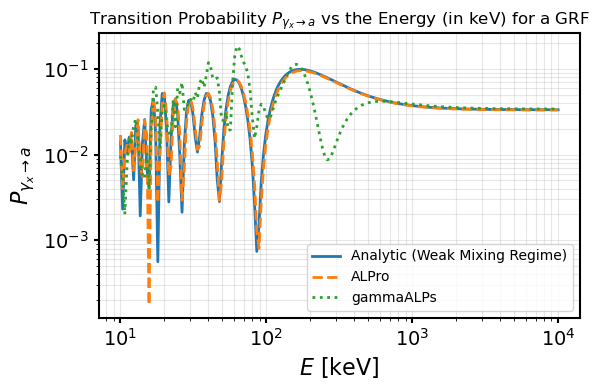

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import os, sys
import sys, contextlib, io
from gammaALPs.core import Source, ALP, ModuleList
sys.path.append("/Users/Logan/ALPro")
import alpro
alpro.util.set_default_plot_params()

os.environ["ALPRO_QUIET"] = "1"
sys.stdout = open(os.devnull, "w")  # silence chatter

# -----------------------------
# Units / constants
# -----------------------------
kpc_to_eVinv = 1.5637e26     
G_to_eV2     = 1.95e-2        

def omega_pl(ne_cm3):
    return 3.69e-11 * np.sqrt(ne_cm3)
# -----------------------------
# Churazov electron density + B(r)
# -----------------------------
def ne_churazov(r_kpc):
    r = np.asarray(r_kpc, dtype=float)
    term1 = 3.9e-2  / (1.0 + (r/80.0)**2)**1.8
    term2 = 4.05e-3 / (1.0 + (r/280.0)**2)**0.87
    return term1 + term2
def B_profile_churazov(r_kpc, B0_muG=7.5, r_ref_kpc=25.0, eta=0.5):
    ne = ne_churazov(r_kpc)
    ne_ref = ne_churazov(r_ref_kpc)
    prof = (ne / ne_ref)**eta
    return (B0_muG * 1e-6) * prof  # Gauss
# -----------------------------
# GRF in Fourier space: B = i k × A
# -----------------------------
def generate_grf_B_ikxA(N=64, L_kpc=1000.0, q=11/3, seed=1):
    rng = np.random.default_rng(seed)

    L = L_kpc
    dk = 2.0 * np.pi / L

    kx = dk * np.fft.fftfreq(N, d=L/N)
    ky = dk * np.fft.fftfreq(N, d=L/N)
    kz = dk * np.fft.fftfreq(N, d=L/N)
    kx3, ky3, kz3 = np.meshgrid(kx, ky, kz, indexing="ij")

    k2 = kx3**2 + ky3**2 + kz3**2
    k = np.sqrt(k2)
    k_min = dk  # smallest non-zero mode

    amp_A = np.zeros_like(k)
    mask = k > 0
    amp_A[mask] = (k[mask]/k_min)**(-(q+2)/2.0)

    Ar = rng.normal(size=(3, N, N, N))
    Ai = rng.normal(size=(3, N, N, N))
    A_k = (Ar + 1j*Ai) * amp_A[None, :, :, :]

    Ax_k, Ay_k, Az_k = A_k

    Bx_k = 1j * (ky3*Az_k - kz3*Ay_k)
    By_k = 1j * (kz3*Ax_k - kx3*Az_k)
    Bz_k = 1j * (kx3*Ay_k - ky3*Ax_k)

    Bx = np.fft.ifftn(Bx_k).real
    By = np.fft.ifftn(By_k).real
    Bz = np.fft.ifftn(Bz_k).real

    dz = L_kpc / N
    coords = (np.arange(N) + 0.5) * dz - 0.5*L_kpc
    x3, y3, z3 = np.meshgrid(coords, coords, coords, indexing="ij")
    r_kpc = np.sqrt(x3**2 + y3**2 + z3**2)

    Brms = np.sqrt(Bx**2 + By**2 + Bz**2).std()
    Bx /= Brms
    By /= Brms
    Bz /= Brms

    return Bx, By, Bz, r_kpc, z3
# -----------------------------
# Apply Churazov radial scaling to GRF
# -----------------------------
def apply_churazov_to_grf(Bx, By, Bz, r_kpc,
                          B0_muG=7.5, r_ref_kpc=25.0, eta=0.5):
    B_chur = B_profile_churazov(r_kpc, B0_muG=B0_muG,
                                r_ref_kpc=r_ref_kpc, eta=eta)
    ne = ne_churazov(r_kpc)
    Bx_phys = Bx * B_chur
    By_phys = By * B_chur
    Bz_phys = Bz * B_chur
    return Bx_phys, By_phys, Bz_phys, ne
# -----------------------------
# Analytic weak-mixing P_{γ→a}(E) along one LoS
# -----------------------------
def P_analytic_weak(energies_eV, B_component_G, ne_cm3,
                    deltaL_kpc, g_GeVinv, m_a_eV):
    B_G = np.asarray(B_component_G, dtype=float)
    ne = np.asarray(ne_cm3, dtype=float)
    dz_eVinv = deltaL_kpc * kpc_to_eVinv
    g_eVinv = g_GeVinv * 1e-9
    B_eV2 = B_G * G_to_eV2
    Delta_ag = 0.5 * g_eVinv * B_eV2
    w_pl = omega_pl(ne)
    w_pl2 = w_pl**2
    P = np.zeros_like(energies_eV, dtype=float)
    for i, E in enumerate(energies_eV):
        meff2 = m_a_eV**2 - w_pl2
        Delta_eff = -meff2 / (2 * E)
        phase = np.cumsum(Delta_eff * dz_eVinv) - 0.5 * Delta_eff * dz_eVinv
        A = np.sum(Delta_ag * np.exp(1j * phase) * dz_eVinv)
        P[i] = np.abs(A)**2
    return P
# -----------------------------
# Build ALPro domain from the same LoS
# -----------------------------
def build_alpro_from_los(By_los_G, ne_los_cm3, deltaL_kpc,
                         g_GeVinv, m_a_eV):
    By = np.asarray(By_los_G, dtype=float)
    ne = np.asarray(ne_los_cm3, dtype=float)
    n_cells = By.size
    s = alpro.Survival("custom")
    s.initialise_domain()
    s.domain.ne     = ne.copy()
    s.domain.deltaL = np.ones(n_cells) * deltaL_kpc
    B_mag = np.abs(By)
    phi   = np.where(By >= 0.0, 0.0, np.pi)
    s.domain.B   = B_mag
    s.domain.phi = phi
    s.set_params(g=g_GeVinv * 1e-9, mass=m_a_eV)
    return s
# -----------------------------
# gammaALPs P_{γ→a}(E)
# -----------------------------
def P_gammaALPs(energies_eV, g_GeVinv, m_a_eV):
    m_neV = m_a_eV * 1e9
    g_11  = g_GeVinv / 1e-11
    EGeV  = energies_eV * 1e-10
    alp = ALP(m_neV, g_11)
    src = Source(z=0., l=0., b=0.)
    pin = np.diag((1., 1., 0.)) * 0.5      # unpolarized photon beam
    ml  = ModuleList(alp, src, pin=pin, EGeV=EGeV, seed=0)
    ml.add_propagation(
        "ICMGaussTurb",
        0,
        nsim=1,
        B0=7.5,        # μG, matches B0_muG
        n0=3.9e-2,
        n2=4.05e-3,
        r_abell=500.,  
        r_core=80.,
        r_core2=280.,
        beta=1.8,
        beta2=0.87,
        eta=0.5,
        kL=0.18,
        kH=9.,
        q=-11/3,       # Kolmogorov-like slope
        seed=0
    )

    px, py, pa = ml.run(multiprocess=1)
    return pa[0]   # nsim=1 ⇒ take first realization


# -----------------------------
# Main: field and LoS
# -----------------------------
def main():
    # --- GRF + Churazov field ---
    N      = 128
    L_kpc  = 1000.0
    q_spec = 11/3

    Bx0, By0, Bz0, r_kpc, z_grid = generate_grf_B_ikxA(
        N=N, L_kpc=L_kpc, q=q_spec, seed=3
    )
    Bx, By, Bz, ne = apply_churazov_to_grf(
        Bx0, By0, Bz0, r_kpc, B0_muG=7.5, r_ref_kpc=25.0, eta=0.5
    )

    # --- choose line-of-sight along z through the centre (x=0,y=0) ---
    ix = N//2
    iy = N//2
    By_los = By[ix, iy, :]       
    ne_los = ne[ix, iy, :]         
    deltaL_kpc = L_kpc / N        
    g_GeVinv = 1e-13              
    m_a_eV   = 1e-12              
    energies_eV = np.logspace(4, 7, 200)   
    # --- analytic weak mixing ---
    P_ana = P_analytic_weak(energies_eV, By_los, ne_los,
                            deltaL_kpc, g_GeVinv, m_a_eV)
    # --- ALPro ---
    s = build_alpro_from_los(By_los, ne_los, deltaL_kpc,
                             g_GeVinv, m_a_eV)
    s.energies = energies_eV.copy()
    P_alpro, _ = s.propagate(pol="y")
    # --- gammaALPs (ICMGaussTurb) ---
    P_gALPs = P_gammaALPs(energies_eV, g_GeVinv, m_a_eV)
    # --- plot ---
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.loglog(energies_eV/1e3, P_ana,   label="Analytic (Weak Mixing Regime)", lw=2)
    ax.loglog(energies_eV/1e3, P_alpro, "--", label="ALPro", lw=2)
    ax.loglog(energies_eV/1e3, P_gALPs*5e2, ":",  label="gammaALPs", lw=2)
    plt.title(r"Transition Probability $P_{\gamma_x\to a}$ vs the Energy (in keV) for a GRF")
    ax.set_xlabel(r"$E$ [keV]")
    ax.set_ylabel(r"$P_{\gamma_{x} \to a}$")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()
if __name__ == "__main__":
    main()

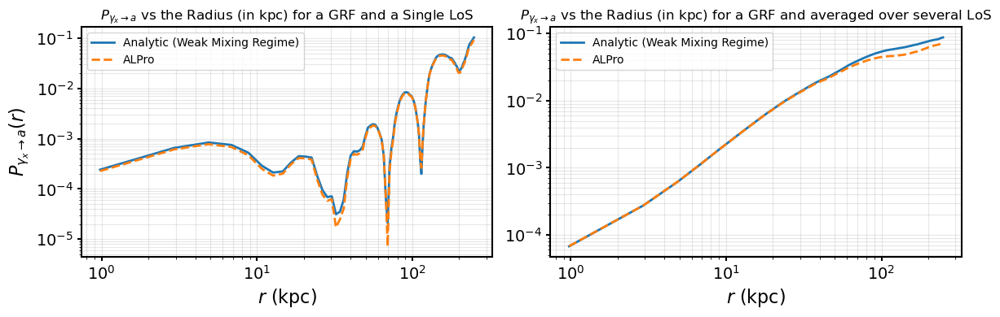

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
import os, sys
os.environ["ALPRO_QUIET"] = "1"

warnings.filterwarnings("ignore", message="Custom model specified")
sys.stdout = open(os.devnull, "w")

import alpro
# Units
# ============================================================
kpc_to_eVinv = 1.5637e26
G_to_eV2     = 1.95e-2

def omega_pl(ne_cm3):
    return 3.69e-11 * np.sqrt(ne_cm3)
# Churazov profile
# ============================================================
def ne_churazov(r_kpc):
    r = np.asarray(r_kpc)
    t1 = 3.9e-2  / (1 + (r/80)**2)**1.8
    t2 = 4.05e-3 / (1 + (r/280)**2)**0.87
    return t1 + t2
def B_churazov(r_kpc, B0_muG=50, r_ref_kpc=25.0, eta=0.5):
    ne = ne_churazov(r_kpc)
    ne0 = ne_churazov(r_ref_kpc)
    return (B0_muG * 1e-6) * (ne/ne0)**eta
# GRF B(k) = i k × A(k)
# ============================================================
def generate_grf_B(N=128, L_kpc=500, q=11/3, seed=1):
    rng = np.random.default_rng(seed)
    dk = 2*np.pi/L_kpc
    k = dk*np.fft.fftfreq(N, d=L_kpc/N)
    kx, ky, kz = np.meshgrid(k, k, k, indexing="ij")
    k2 = kx**2+ky**2+kz**2
    km = np.sqrt(k2)
    amp = np.zeros_like(km)
    mask = km>0
    amp[mask] = (km[mask]/dk)**(-(q+2)/2)
    Ar = rng.normal(size=(3,N,N,N))
    Ai = rng.normal(size=(3,N,N,N))
    A  = (Ar + 1j*Ai)*amp[None,:,:,:]
    Ax, Ay, Az = A
    Bx = np.fft.ifftn(1j*(ky*Az - kz*Ay)).real
    By = np.fft.ifftn(1j*(kz*Ax - kx*Az)).real
    Bz = np.fft.ifftn(1j*(kx*Ay - ky*Ax)).real
    rms = np.std(np.sqrt(Bx**2+By**2+Bz**2))
    Bx /= rms*0.1
    By /= rms*0.1
    Bz /= rms*0.1
    dz = L_kpc/N
    coord = (np.arange(N)+0.5)*dz - 0.5*L_kpc
    x,y,z = np.meshgrid(coord, coord, coord, indexing="ij")
    r = np.sqrt(x**2+y**2+z**2)
    return Bx,By,Bz,r,x,y,z,dz

def apply_churazov(Bx, By, Bz, r):
    Bprof = B_churazov(r)
    ne    = ne_churazov(r)
    return Bx*Bprof, By*Bprof, Bz*Bprof, ne
# ============================================================
# Analytic P(r)
# ============================================================
def analytic_P_vs_r(B, ne, dr_kpc, g, ma, E):

    dz = dr_kpc*kpc_to_eVinv
    g_eVinv = g*1e-9
    Delta_ag = 0.5*g_eVinv*(B*G_to_eV2)

    wpl = omega_pl(ne)
    Delta_eff = -(ma**2 - wpl**2)/(2*E)

    phase = np.zeros_like(Delta_eff)
    for i in range(1,len(Delta_eff)):
        phase[i] = phase[i-1] + Delta_eff[i-1]*dz

    A = np.zeros_like(Delta_ag, dtype=complex)
    A[0] = Delta_ag[0]*np.exp(1j*phase[0])*dz
    for i in range(1,len(Delta_ag)):
        A[i] = A[i-1] + Delta_ag[i]*np.exp(1j*phase[i])*dz

    return np.abs(A)**2
# ============================================================
# ALPro P(r)
# ============================================================
def alpro_P_vs_r(B, ne, dr_kpc, g, ma, E):
    N = len(B)
    out = np.zeros(N)

    for j in range(1,N+1):
        s = alpro.Survival("custom")
        s.initialise_domain()

        s.domain.ne     = ne[:j]
        s.domain.deltaL = np.ones(j)*dr_kpc

        Bseg = B[:j]
        s.domain.B   = np.abs(Bseg)
        s.domain.phi = np.where(Bseg>=0, 0.0, np.pi)

        s.set_params(g=g*1e-9, mass=ma)
        s.energies = np.array([E])

        P_surv,_ = s.propagate(pol="y")
        out[j-1] = P_surv[0]

    return out
# ============================================================
# MAIN
# ============================================================
def main():
    N = 256
    L = 500
    Bx0,By0,Bz0,r,x,y,z,dz = generate_grf_B(N=N, L_kpc=L, seed=4)
    Bx,By,Bz,ne = apply_churazov(Bx0,By0,Bz0,r)
    mid = N//2
    coord_x = x[:,mid,mid]
    mask = coord_x>=0
    rlos = coord_x[mask]
    dr_kpc = rlos[1]-rlos[0]
    Bmix_los = By[:,mid,mid][mask]
    ne_los  = ne[:,mid,mid][mask]
    g=1e-14; ma=1e-12; E=1e4
    # --------------------------------------------------------
    # PLOT 1: Single LoS
    # --------------------------------------------------------
    Pana_1 = analytic_P_vs_r(Bmix_los, ne_los, dr_kpc, g, ma, E)
    Palp_1 = alpro_P_vs_r(Bmix_los, ne_los, dr_kpc, g, ma, E)
    # --------------------------------------------------------
    # PLOT 2: Average over many LoS
    # --------------------------------------------------------
    N_LOS = 40
    Pana_avg = 0; Palp_avg = 0
    for k in range(N_LOS):
        ix = np.random.randint(0,N)
        iy = np.random.randint(0,N)
        BLOS = By[ix,iy,:][mask]
        neLOS = ne[ix,iy,:][mask]
        Pana_avg += analytic_P_vs_r(BLOS, neLOS, dr_kpc, g, ma, E)
        Palp_avg += alpro_P_vs_r(BLOS, neLOS, dr_kpc, g, ma, E)
    Pana_avg /= N_LOS
    Palp_avg /= N_LOS
    # --------------------------------------------------------
    # Final combined plot
    # --------------------------------------------------------
    fig, ax = plt.subplots(1,2,figsize=(12,4))
    # Single LoS
    ax[0].loglog(rlos, Pana_1, label="Analytic (Weak Mixing Regime)", lw=2)
    ax[0].loglog(rlos, Palp_1, "--", label="ALPro", lw=2)
    ax[0].set_title(r"$P_{\gamma_x\to a}$ vs the Radius (in kpc) for a GRF and a Single LoS")
    ax[0].set_xlabel(r"$r$ (kpc)")
    ax[0].set_ylabel(r"$P_{\gamma_x \to a}(r)$")
    ax[0].grid(True, which="both", alpha=0.3)
    ax[0].legend()
    # Averaged LoS
    ax[1].loglog(rlos, Pana_avg, label="Analytic (Weak Mixing Regime)", lw=2)
    ax[1].loglog(rlos, Palp_avg, "--", label="ALPro", lw=2)
    ax[1].set_title(r"$P_{\gamma_x\to a}$ vs the Radius (in kpc) for a GRF and averaged over several LoS")
    ax[1].set_xlabel(r"$r$ (kpc)")
    ax[1].grid(True, which="both", alpha=0.3)
    ax[1].legend()
    plt.tight_layout()
    plt.show()
if __name__=="__main__":
    main()

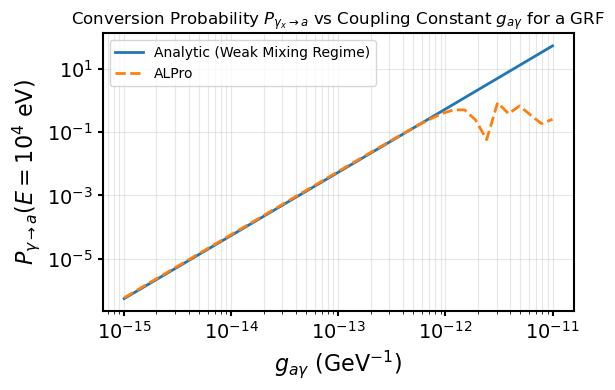

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import os
import sys
import alpro
os.environ["ALPRO_QUIET"] = "1"
# Units
# ============================================================
kpc_to_eVinv = 1.5637e26   
G_to_eV2     = 1.95e-2        

def omega_pl(ne_cm3):
    return 3.69e-11 * np.sqrt(ne_cm3)


# ============================================================
# Churazov electron density and B(r)
# ============================================================
def ne_churazov(r_kpc):
    r = np.asarray(r_kpc, dtype=float)
    t1 = 3.9e-2  / (1.0 + (r/80.0)**2)**1.8
    t2 = 4.05e-3 / (1.0 + (r/280.0)**2)**0.87
    return t1 + t2

def B_churazov(r_kpc, B0_muG=7.5, r_ref_kpc=25.0, eta=0.5):
    ne = ne_churazov(r_kpc)
    ne_ref = ne_churazov(r_ref_kpc)
    prof = (ne / ne_ref)**eta
    return (B0_muG * 1e-6) * prof   # Gauss


# ============================================================
# GRF B-field from B(k) = i k × A(k)
# ============================================================
def generate_grf_B_ikxA(N=64, L_kpc=1000.0, q=11/3, seed=1):
    rng = np.random.default_rng(seed)
    L = L_kpc
    dk = 2.0 * np.pi / L
    kx = dk * np.fft.fftfreq(N, d=L/N)
    ky = dk * np.fft.fftfreq(N, d=L/N)
    kz = dk * np.fft.fftfreq(N, d=L/N)
    kx3, ky3, kz3 = np.meshgrid(kx, ky, kz, indexing="ij")
    k2 = kx3**2 + ky3**2 + kz3**2
    k = np.sqrt(k2)
    k_min = dk
    # A(k) amplitude to get P_B ~ k^{-q} (since P_B ~ k^2 P_A)
    # => P_A ~ k^{-q-2}, |A| ∝ k^{-(q+2)/2}
    amp_A = np.zeros_like(k)
    mask = k > 0
    amp_A[mask] = (k[mask]/k_min)**(-(q+2)/2.0)
    # Random complex vector potential (no Hermitian enforced and real part later)
    Ar = rng.normal(size=(3, N, N, N))
    Ai = rng.normal(size=(3, N, N, N))
    A_k = (Ar + 1j*Ai) * amp_A[None, :, :, :]
    Ax_k, Ay_k, Az_k = A_k
    # B(k) = i k × A(k)
    Bx_k = 1j * (ky3*Az_k - kz3*Ay_k)
    By_k = 1j * (kz3*Ax_k - kx3*Az_k)
    Bz_k = 1j * (kx3*Ay_k - ky3*Ax_k)
    # Back to real space (dimensionless GRF)
    Bx = np.fft.ifftn(Bx_k).real
    By = np.fft.ifftn(By_k).real
    Bz = np.fft.ifftn(Bz_k).real
    # Real-space coordinates, centered
    dz = L_kpc / N
    coords = (np.arange(N) + 0.5) * dz - 0.5*L_kpc
    x3, y3, z3 = np.meshgrid(coords, coords, coords, indexing="ij")
    r_kpc = np.sqrt(x3**2 + y3**2 + z3**2)
    # Normalize RMS of |B| to 1 (dimensionless)
    Brms = np.sqrt(Bx**2 + By**2 + Bz**2).std()
    Bx /= Brms
    By /= Brms
    Bz /= Brms
    return Bx, By, Bz, r_kpc
# ============================================================
# Churazov radial scaling to GRF
# ============================================================
def apply_churazov_to_grf(Bx, By, Bz, r_kpc,
                          B0_muG=7.5, r_ref_kpc=25.0, eta=0.5):
    B_chur = B_churazov(r_kpc, B0_muG=B0_muG,
                        r_ref_kpc=r_ref_kpc, eta=eta)  
    ne = ne_churazov(r_kpc)
    Bx_phys = Bx * B_chur
    By_phys = By * B_chur
    Bz_phys = Bz * B_chur
    return Bx_phys, By_phys, Bz_phys, ne
# ============================================================
# Analytic weak-mixing: P(g) at fixed E
# ============================================================
def analytic_P_vs_g(B_los_G, ne_los_cm3, deltaL_kpc,
                    g_array_GeVinv, m_a_eV, E_eV):
    B_G = np.asarray(B_los_G, dtype=float)
    ne  = np.asarray(ne_los_cm3, dtype=float)
    dz  = deltaL_kpc * kpc_to_eVinv
    # Mixing term
    B_eV2 = B_G * G_to_eV2
    Delta_ag_unit = 0.5 * B_eV2 
    # Effective mass term
    w_pl = omega_pl(ne)
    meff2 = m_a_eV**2 - w_pl**2
    Delta_eff = -meff2 / (2.0 * E_eV)

    # Phase and amplitude with ALPro-like discretization
    phase = np.zeros_like(Delta_eff)
    for i in range(1, len(Delta_eff)):
        phase[i] = phase[i-1] + Delta_eff[i-1] * dz

    A = np.zeros_like(Delta_ag_unit, dtype=complex)
    A[0] = Delta_ag_unit[0] * np.exp(1j*phase[0]) * dz
    for i in range(1, len(Delta_ag_unit)):
        A[i] = A[i-1] + Delta_ag_unit[i] * np.exp(1j*phase[i]) * dz
    A_unit = A[-1]
    C = np.abs(A_unit)**2 
    g_array_GeVinv = np.asarray(g_array_GeVinv, dtype=float)
    g_eVinv = g_array_GeVinv * 1e-9
    P_g = C * g_eVinv**2
    return P_g
# ============================================================
# ALPro: P(g) at fixed E along same LOS
# ============================================================
def alpro_P_vs_g(B_los_G, ne_los_cm3, deltaL_kpc,
                 g_array_GeVinv, m_a_eV, E_eV):
    B_G = np.asarray(B_los_G, dtype=float)
    ne  = np.asarray(ne_los_cm3, dtype=float)
    n_cells = len(B_G)
    P_conv = np.zeros_like(g_array_GeVinv, dtype=float)
    E_arr = np.array([E_eV], dtype=float)
    for ig, g_GeVinv in enumerate(g_array_GeVinv):
        s = alpro.Survival("custom")
        s.initialise_domain()
        s.domain.ne     = ne.copy()
        s.domain.deltaL = np.ones(n_cells) * deltaL_kpc
        #pol='y'
        Bmag = np.abs(B_G)
        phi  = np.where(B_G >= 0.0, 0.0, np.pi) 
        s.domain.B   = Bmag
        s.domain.phi = phi
        s.set_params(g=g_GeVinv * 1e-9, mass=m_a_eV) 
        s.energies = E_arr
        P_surv, _ = s.propagate(pol="y")
        P_conv[ig] = P_surv[0]  
    return P_conv


# ============================================================
# Main: build GRF, apply Churazov, LOS, P(g) comparison
# ============================================================
def main():
    # --- GRF + Churazov field ---
    N      = 128
    L_kpc  = 500.0
    q_spec = 11/3
    Bx0, By0, Bz0, r_kpc = generate_grf_B_ikxA(
        N=N, L_kpc=L_kpc, q=q_spec, seed=3
    )
    Bx, By, Bz, ne = apply_churazov_to_grf(
        Bx0, By0, Bz0, r_kpc,
        B0_muG=7.5, r_ref_kpc=25.0, eta=0.5
    )
    # --- choose a LOS along z through the centre (x=0,y=0) ---
    ix = N // 2
    iy = N // 2
    By_los = By[ix, iy, :]  
    ne_los = ne[ix, iy, :]  
    deltaL_kpc = L_kpc / N   # cell size along LOS
    # --- ALP params and g grid ---
    E_eV   = 1.0e4      
    m_a_eV = 1.0e-12      
    g_array = np.logspace(-15, -11, 40)  
    # --- Analytic weak-mixing P(g) ---
    P_ana = analytic_P_vs_g(
        By_los, ne_los, deltaL_kpc, g_array, m_a_eV, E_eV
    )
    # --- ALPro P(g) ---
    P_alpro = alpro_P_vs_g(
        By_los, ne_los, deltaL_kpc, g_array, m_a_eV, E_eV
    )
    # --- Plot ---
    plt.figure(figsize=(6,4))
    plt.loglog(g_array, P_ana,   label="Analytic (Weak Mixing Regime)", lw=2)
    plt.loglog(g_array, P_alpro, "--", label="ALPro", lw=2)
    plt.title(r"Conversion Probability $P_{\gamma_x\to a}$ vs Coupling Constant $g_{a\gamma}$ for a GRF")
    plt.xlabel(r"$g_{a\gamma}$ (GeV$^{-1}$)")
    plt.ylabel(r"$P_{\gamma\to a}(E=10^4\ \mathrm{eV})$")
    plt.grid(True, which="both", alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    main()

environs.py: 431 --- INFO: Using inputted chi
   core.py: 658 --- INFO: Running Module 0: <class 'gammaALPs.base.environs.MixICMGaussTurb'>
/opt/anaconda3/lib/python3.12/site-packages/gammaALPs/base/transfer.py:799: UserWarning: Not all values of linear polarization are real values!
  warnings.warn("Not all values of linear polarization are real values!")
/opt/anaconda3/lib/python3.12/site-packages/gammaALPs/base/transfer.py:802: UserWarning: Not all values of circular polarization are real values!
  warnings.warn("Not all values of circular polarization are real values!")
environs.py: 431 --- INFO: Using inputted chi
   core.py: 658 --- INFO: Running Module 0: <class 'gammaALPs.base.environs.MixICMGaussTurb'>
environs.py: 431 --- INFO: Using inputted chi
   core.py: 658 --- INFO: Running Module 0: <class 'gammaALPs.base.environs.MixICMGaussTurb'>
environs.py: 431 --- INFO: Using inputted chi
   core.py: 658 --- INFO: Running Module 0: <class 'gammaALPs.base.environs.MixICMGaussTurb'>


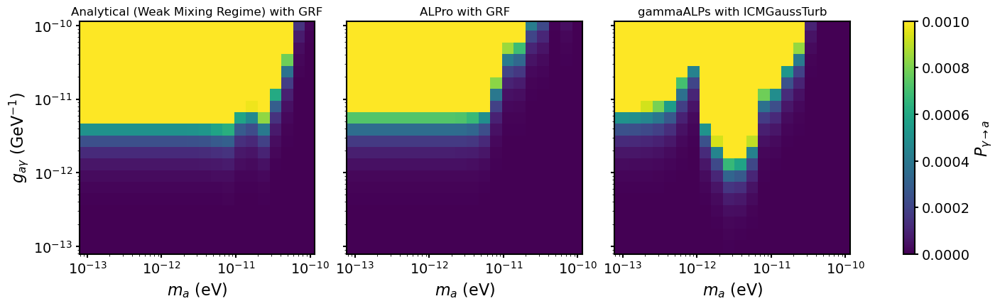

In [1]:
import sys
import contextlib
import io
import numpy as np
import matplotlib.pyplot as plt
sys.path.append("/Users/Logan/ALPro")
import alpro
alpro.util.set_default_plot_params()

# ============================================================
# (A) Units & constants
# ============================================================
kpc_to_eVinv = 1.5637e26   
muG_to_T     = 1e-10      
muG_to_eV2   = 1.95e-8    
eV_to_GeV    = 1e-9        

# ============================================================
# (B) weak mixing
# ============================================================
L_kpc   = 10.0             
N_cells = 1024               
E_eV    = 1.0e4                   
omega_pl2 = 0.0               
rng     = np.random.default_rng(42)  

# Grid for heatmaps
m_vals = np.logspace(-13, -10, 20)  
g_vals = np.logspace(-13, -10, 20)    
vmin, vmax = 0.0, 1e-3

# ============================================================
# (C) 3D GRF from gauge potential A(k), then B = i k × A
# ============================================================
def make_grf_B_box(
    N=64,
    L_kpc=10.0,
    q=-11/3,
    B0_muG=5.0,
    r_core_kpc=80.0,
    eta=0.5
):
    x = np.linspace(0, L_kpc, N, endpoint=False)
    X, Y, Z = np.meshgrid(x, x, x, indexing='ij')

    # k-space grid in 1/kpc
    dk = 2.0 * np.pi / L_kpc
    kx = dk * np.fft.fftfreq(N, d=L_kpc/N)
    ky = dk * np.fft.fftfreq(N, d=L_kpc/N)
    kz = dk * np.fft.fftfreq(N, d=L_kpc/N)
    KX, KY, KZ = np.meshgrid(kx, ky, kz, indexing='ij')
    K2 = KX**2 + KY**2 + KZ**2
    K  = np.sqrt(K2)
    K[0, 0, 0] = 1.0
    qA = q - 2.0

    def random_complex_with_power(K, slope):
        amp = K**(0.5 * slope)
        amp[np.isnan(amp)] = 0.0
        amp[np.isinf(amp)] = 0.0
        Re = rng.standard_normal(K.shape)
        Im = rng.standard_normal(K.shape)
        return (Re + 1j * Im) * amp

    Ax_k = random_complex_with_power(K, qA)
    Ay_k = random_complex_with_power(K, qA)
    Az_k = random_complex_with_power(K, qA)

    # Remove k=0 mode
    Ax_k[0, 0, 0] = 0.0
    Ay_k[0, 0, 0] = 0.0
    Az_k[0, 0, 0] = 0.0

    # B(k) = i k × A(k)
    iKX, iKY, iKZ = 1j * KX, 1j * KY, 1j * KZ
    Bx_k = iKY * Az_k - iKZ * Ay_k
    By_k = iKZ * Ax_k - iKX * Az_k
    Bz_k = iKX * Ay_k - iKY * Ax_k

    # Back to real space
    Bx = np.fft.ifftn(Bx_k).real
    By = np.fft.ifftn(By_k).real
    Bz = np.fft.ifftn(Bz_k).real

    rms = np.sqrt(np.mean(Bx**2 + By**2 + Bz**2))
    if rms == 0:
        raise RuntimeError("Zero RMS field; adjust N or spectrum.")
    Bx /= rms
    By /= rms
    Bz /= rms

    # Radial profile centered
    xc = yc = zc = 0.5 * L_kpc
    R = np.sqrt((X - xc)**2 + (Y - yc)**2 + (Z - zc)**2)
    profile = (1.0 + (R / r_core_kpc)**2)**(-0.5 * eta)

    # Scale to central strength B0_muG (μG)
    Bx *= B0_muG * profile
    By *= B0_muG * profile
    Bz *= B0_muG * profile

    return Bx, By, Bz

# GRF box
Bx_box, By_box, Bz_box = make_grf_B_box(
    N=64, L_kpc=L_kpc, q=-11/3,
    B0_muG=5.0, r_core_kpc=80.0, eta=0.5
)

# ============================================================
# (D) central LOS
# ============================================================
def sample_LOS_B_components(Bx, By, Bz, L_kpc, N_cells):
    """
    Propagation along z through the box center; return arrays along z:
      Bx(z), By(z), Bz(z)  [μG]
    """
    N = Bx.shape[0]
    mid = N // 2
    z_idx = np.linspace(0, N - 1, N_cells).astype(int)
    Bx_z = Bx[mid, mid, z_idx]
    By_z = By[mid, mid, z_idx]
    Bz_z = Bz[mid, mid, z_idx]
    return Bx_z, By_z, Bz_z

Bx_z_muG, By_z_muG, Bz_z_muG = sample_LOS_B_components(
    Bx_box, By_box, Bz_box, L_kpc, N_cells
)
B_T_mag_muG = np.sqrt(Bx_z_muG**2 + By_z_muG**2)
phi_rad     = np.arctan2(By_z_muG, Bx_z_muG) 

# ============================================================
# (E) Analytic Fourier integral (weak mixing)
#     P ≈ (g^2/4) |∫ dz B_pol(z) exp(i η z)|^2
# ============================================================
def P_weak_mixing_integral(B_pol_muG, L_kpc, E_eV, g_GeV_inv, m_a_eV, omega_pl2=0.0):
    z_eVinv = np.linspace(0.0, L_kpc * kpc_to_eVinv, B_pol_muG.size)
    dz = z_eVinv[1] - z_eVinv[0]
    g_eV_inv = g_GeV_inv * eV_to_GeV
    # η = (m_a^2 - ω_pl^2)/(2E) [eV]
    eta = (m_a_eV**2 - omega_pl2) / (2.0 * E_eV)
    B_pol_eV2 = B_pol_muG * muG_to_eV2

    integrand = B_pol_eV2 * np.exp(1j * eta * z_eVinv)
    I = np.trapz(integrand, dx=dz)
    return (g_eV_inv**2 / 4.0) * np.abs(I)**2
# ============================================================
# (F) ALPro propagation with the SAME GRF LOS
# ============================================================
def P_alpro_line(By_muG, Bx_muG, L_kpc, ne_cm3, E_eV, g_GeV_inv, m_a_eV, phi_rad):
    with contextlib.redirect_stdout(io.StringIO()):
        s = alpro.Survival("custom")
        s.initialise_domain()
        s.domain.ne     = np.full(N_cells, ne_cm3)
        B_T_T = np.sqrt(Bx_muG**2 + By_muG**2) * muG_to_T 
        s.domain.B      = B_T_T*1e-6
        s.domain.deltaL = np.full(N_cells, L_kpc / N_cells)
        s.domain.phi    = phi_rad     
        s.set_params(g=g_GeV_inv, mass=m_a_eV)
        s.propagate(energies=np.array([E_eV]), pol="y")
        return float(s.P[0])
# ============================================================
# (G) gammaALPs
# ============================================================
def P_gammaALPs(By_muG_unused, L_kpc, E_eV, g_GeV_inv, m_a_eV):
    from gammaALPs.core import Source, ALP, ModuleList
    # --- Parameters matching ALPro ---
    B0_uG       = 1.0
    ne0_cm3     = 1e-3
    eta         = 0.5
    r_core_kpc  = 80.0
    q_spec      = -11/3
    kL_kpc_inv  = 0.1
    kH_kpc_inv  = 10.0
    r_abell_kpc = max(L_kpc, 2*r_core_kpc)
    EGeV  = np.array([E_eV * 1e-9])  
    m_neV = m_a_eV * 1e9         
    g_11  = g_GeV_inv * 1e11          

    # --- y-polarized photons (E ⟂ B) ---
    pin = np.diag((0.0, 1.0, 0.0))
    src = Source(z=0.0, ra='00h00m00s', dec='+00d00m00s')
    alp = ALP(m_neV, g_11)
    ml = ModuleList(alp, src, pin=pin, EGeV=EGeV)
    ml.add_propagation(
        "ICMGaussTurb",
        0,
        nsim=1,
        B0=B0_uG,
        n0=ne0_cm3,
        r_abell=r_abell_kpc,
        r_core=r_core_kpc,
        eta=eta,
        beta=1.0,
        kL=kL_kpc_inv,
        kH=kH_kpc_inv,
        q=q_spec,
        seed=42,
        L=L_kpc
    )
    px, py, pa = ml.run(multiprocess=0)
    return float(pa[0])

# ============================================================
# (H) three 20×20 heatmaps
# ============================================================
ne_cm3 = 1e-3

P_analytic = np.zeros((m_vals.size, g_vals.size))
P_alproHM  = np.zeros_like(P_analytic)
P_gammaHM  = np.zeros_like(P_analytic)

for i, m_a in enumerate(m_vals):
    for j, g in enumerate(g_vals):
        # 1) Analytical Fourier (weak mixing) using B_y(z)
        P_analytic[i, j] = P_weak_mixing_integral(
            By_z_muG, L_kpc, E_eV, g, m_a, omega_pl2
        )
        # 2) ALPro with exact same GRF line and geometry
        P_alproHM[i, j]  = P_alpro_line(
            By_z_muG, Bx_z_muG, L_kpc, ne_cm3, E_eV, g, m_a, phi_rad
        )
        # 3) gammaALPs proxy (cluster-like turbulent model; unchanged)
        P_gammaHM[i, j]  = P_gammaALPs(
            By_z_muG, L_kpc, E_eV, g, m_a
        )

# ============================================================
# (I) Plot three panels
# ============================================================
fig, axs = plt.subplots(
    1, 3, figsize=(14, 4.2),
    sharex=True, sharey=True,
    constrained_layout=True
)
cmap = plt.cm.viridis
norm = plt.Normalize(vmin=vmin, vmax=vmax)

def draw(ax, data, title):
    im = ax.pcolormesh(
        m_vals, g_vals, data.T,
        shading='auto',
        cmap=cmap, norm=norm
    )
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel(r"$m_a$ (eV)")
    ax.set_title(title)
    return im

im0 = draw(axs[0], P_analytic, "Analytical (Weak Mixing Regime) with GRF")
axs[0].set_ylabel(r"$g_{a\gamma}$ (GeV$^{-1}$)")
im1 = draw(axs[1], P_alproHM,  "ALPro with GRF")
im2 = draw(axs[2], P_gammaHM,  "gammaALPs with ICMGaussTurb")

cbar = fig.colorbar(im2, ax=axs, label=r"$P_{\gamma\to a}$")
plt.show()

<h1 style="font-size:100px; text-align:center;">MHD MAGNETIC FIELD</h1>

In [27]:
import h5py
import numpy as np
filename = "/Users/Logan/Documents/cutout_42631.hdf5"
f = h5py.File(filename, "r")
current = f
print("\n====== INTERACTIVE HDF5 BROWSER ======")
print(f"Opened: {filename}")
print("Commands: ls, cd <name>, cd .., info <dataset>, head <dataset>, attrs <name>, exit")
print("======================================\n")
# ============================================================
# COMMAND LOOP
# ============================================================
while True:
    cmd = input(f"[HDF5:{current.name}] $ ").strip().split()

    if len(cmd) == 0:
        continue

    # -------------------------------
    # LIST ITEMS
    # -------------------------------
    if cmd[0] == "ls":
        print("\nContents:")
        for key in current.keys():
            obj = current[key]
            if isinstance(obj, h5py.Group):
                print(f"  [Group]   {key}")
            else:
                print(f"  [Dataset] {key}  shape={obj.shape}  dtype={obj.dtype}")
        print()
        continue

    # -------------------------------
    # CHANGE DIRECTORY
    # -------------------------------
    if cmd[0] == "cd":
        if len(cmd) == 1:
            print("Usage: cd <group-name> or cd ..")
            continue
        name = cmd[1]

        if name == "..":
            if current.name == "/":
                print("Already at root.")
            else:
                current = current.parent
            continue

        if name in current.keys() and isinstance(current[name], h5py.Group):
            current = current[name]
        else:
            print(f"No such group: {name}")
        continue

    # -------------------------------
    # SHOW INFO ABOUT A DATASET
    # -------------------------------
    if cmd[0] == "info":
        if len(cmd) < 2:
            print("Usage: info <dataset-name>")
            continue
        name = cmd[1]
        if name not in current:
            print(f"No such object: {name}")
            continue
        obj = current[name]
        if isinstance(obj, h5py.Dataset):
            print(f"\nDataset '{name}':")
            print(f"   shape = {obj.shape}")
            print(f"   dtype = {obj.dtype}")
        else:
            print(f"'{name}' is a group, not a dataset.")
        print()
        continue

    # -------------------------------
    # PRINT FIRST VALUES OF A DATASET
    # -------------------------------
    if cmd[0] == "head":
        if len(cmd) < 2:
            print("Usage: head <dataset-name>")
            continue
        name = cmd[1]
        if name not in current:
            print(f"No such object: {name}")
            continue

        obj = current[name]
        if isinstance(obj, h5py.Dataset):
            data = obj[()]
            flat = data.flatten()
            print(f"\nFirst values of '{name}':")
            print(flat[:20], "..." if flat.size > 20 else "")
        else:
            print(f"'{name}' is a group.")
        print()
        continue

    # -------------------------------
    # PRINT ATTRIBUTES
    # -------------------------------
    if cmd[0] == "attrs":
        if len(cmd) < 2:
            print("Usage: attrs <name>")
            continue

        name = cmd[1]
        if name not in current:
            print(f"No such object: {name}")
            continue

        obj = current[name]
        print(f"\nAttributes of '{name}':")
        if len(obj.attrs) == 0:
            print("   (none)")
        else:
            for k, v in obj.attrs.items():
                print(f"   {k} = {v}")
        print()
        continue

    # -------------------------------
    # EXIT
    # -------------------------------
    if cmd[0] in ("exit", "quit", "q"):
        print("Closing file.")
        f.close()
        break

    # -------------------------------
    # UNKNOWN COMMAND
    # -------------------------------
    print("Unknown command:", cmd[0])


====== INTERACTIVE HDF5 BROWSER ======
Opened: /Users/Logan/Documents/cutout_42631.hdf5
Commands: ls, cd <name>, cd .., info <dataset>, head <dataset>, attrs <name>, exit



[HDF5:/] $  ls



Contents:
  [Group]   Header
  [Group]   PartType0
  [Group]   PartType1
  [Group]   PartType4
  [Group]   PartType5



[HDF5:/] $  cd PartType0
[HDF5:/PartType0] $  ls



Contents:
  [Dataset] CenterOfMass  shape=(8560228, 3)  dtype=float32
  [Dataset] Coordinates  shape=(8560228, 3)  dtype=float64
  [Dataset] Density  shape=(8560228,)  dtype=float32
  [Dataset] ElectronAbundance  shape=(8560228,)  dtype=float32
  [Dataset] EnergyDissipation  shape=(8560228,)  dtype=float32
  [Dataset] GFM_AGNRadiation  shape=(8560228,)  dtype=float32
  [Dataset] GFM_CoolingRate  shape=(8560228,)  dtype=float32
  [Dataset] GFM_Metallicity  shape=(8560228,)  dtype=float32
  [Dataset] GFM_Metals  shape=(8560228, 10)  dtype=float32
  [Dataset] GFM_MetalsTagged  shape=(8560228, 6)  dtype=float32
  [Dataset] GFM_WindDMVelDisp  shape=(8560228,)  dtype=float32
  [Dataset] GFM_WindHostHaloMass  shape=(8560228,)  dtype=float32
  [Dataset] InternalEnergy  shape=(8560228,)  dtype=float32
  [Dataset] Machnumber  shape=(8560228,)  dtype=float32
  [Dataset] MagneticField  shape=(8560228, 3)  dtype=float32
  [Dataset] MagneticFieldDivergence  shape=(8560228,)  dtype=float32
  [Datase

[HDF5:/PartType0] $  head MagneticField



First values of 'MagneticField':
[ 1.7329588   0.46285588  0.08673873  1.5070294   0.76901066  0.06873841
  0.61918557 -0.12985927  0.02382233  5.1907954   0.19952899 -0.75309724
  1.5995067   0.15139131  0.58899605  1.5344996  -0.11188446 -0.20120078
  0.6350825   0.09848549] ...



[HDF5:/PartType0] $  exit


Closing file.


Loaded 8560228 gas cells
Redshift = 2.220446049250313e-16
Center = mass-weighted gas centroid
  centroid (relative ckpc/h): [-115.57621264   11.04095241  -15.82876114]
  center   (absolute ckpc/h): [197521.71533809 112172.28680589 198428.71545849]


/var/folders/0m/cr_3cvys7fn6wcnlgpyhl8180000gn/T/ipykernel_45679/4197456614.py:68: RuntimeWarning: overflow encountered in multiply
  rho_e_cgs = rho_e_Msun_kpc3 * Msun / (kpc_cm**3)       # g/cm^3


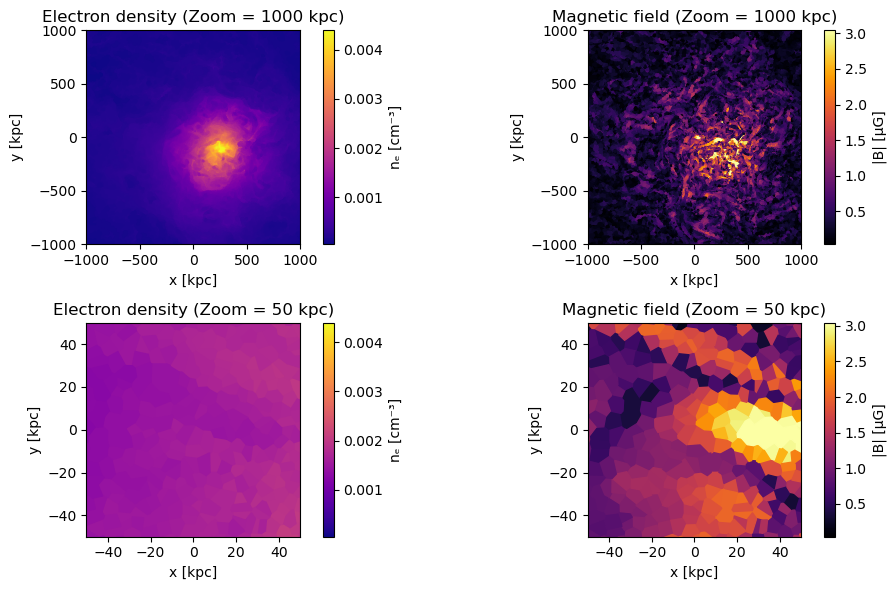

In [35]:
import sys
sys.path.append("/Users/Logan/illustris_python/")

import numpy as np
import h5py
import matplotlib.pyplot as plt
from shapely.geometry import Polygon, box
from shapely.errors import TopologicalError
from scipy.spatial import Voronoi
from matplotlib import colormaps

# ============================================================
# USER INPUT
# ============================================================
filename = "/Users/Logan/Documents/cutout_42631.hdf5"
SLICE_THICKNESS = 5.0    
ZOOMS = [1000.0, 50.0]     # two zoom levels

# ============================================================
# LOAD TNG
# ============================================================
with h5py.File(filename, "r") as f:
    gas      = f["PartType0"]
    coords   = gas["Coordinates"][:]        # ckpc/h 
    masses   = gas["Masses"][:]            # 1e10 Msun/h
    rho_code = gas["Density"][:]           # 1e10 Msun/h / (ckpc/h)^3
    ne_frac  = gas["ElectronAbundance"][:] # dimensionless
    B_vec    = gas["MagneticField"][:]     # μG 
    redshift = f["Header"].attrs["Redshift"]
    h        = f["Header"].attrs["HubbleParam"]

print(f"Loaded {len(coords)} gas cells")
print("Redshift =", redshift)

# ============================================================
# CENTERING
median_pos   = np.median(coords, axis=0)
coords_rel   = coords - median_pos
center_rel   = np.average(coords_rel, axis=0, weights=masses)
center_ckpc_h = median_pos + center_rel

print("Center = mass-weighted gas centroid")
print("  centroid (relative ckpc/h):", center_rel)
print("  center   (absolute ckpc/h):", center_ckpc_h)

coords_centered = coords - center_ckpc_h  
coords_kpc      = coords_centered / (h * (1.0 + redshift)) 
x, y, z         = coords_kpc.T

# ============================================================
# ELECTRON DENSITY (cm^-3)
rho_phys_Msun_kpc3 = rho_code * 1e10 * h**2 * (1.0 + redshift)**3 
rho_e_Msun_kpc3    = rho_phys_Msun_kpc3 * ne_frac

Msun   = 1.98847e33
kpc_cm = 3.0856776e21
m_p    = 1.6726219e-24
rho_e_Msun_kpc3 = np.clip(rho_e_Msun_kpc3, 0.0, 1e12)  

rho_e_cgs = rho_e_Msun_kpc3 * Msun / (kpc_cm**3)      
ne_cm3    = rho_e_cgs / m_p                            

# ============================================================
# MAGNETIC FIELD MAG
# ============================================================
B_mag = np.linalg.norm(B_vec, axis=1)   # μG

# ============================================================
# SLICE
# ============================================================
mask = np.abs(z) < SLICE_THICKNESS
xx   = x[mask]
yy   = y[mask]
ne_s = ne_cm3[mask]
B_s  = B_mag[mask]

# ============================================================
# BUILD VORONOI (2D) IN SLICE
# ============================================================
pts = np.column_stack([xx, yy])
vor = Voronoi(pts)

# ============================================================
# NORMALIZATION FOR COLORS
# ============================================================
def get_limits(data):
    vmin = np.percentile(data, 1)
    vmax = np.percentile(data, 99)
    return vmin, vmax
def safe_clip(poly, clip_box):
    try:
        clipped = poly.intersection(clip_box)
        if clipped.is_empty:
            return None
        return clipped
    except TopologicalError:
        return None

# ============================================================
# DRAWing FUNCTION
# ============================================================
def plot_voronoi(ax, field, cmap_name, zoom, title, bar_label):
    vmin, vmax = get_limits(field)
    cmap = colormaps[cmap_name]

    clip_box = box(-zoom, -zoom, zoom, zoom)

    for p_i, region_index in enumerate(vor.point_region):
        region = vor.regions[region_index]

        if -1 in region or len(region) < 3:
            continue  # infinite region

        poly_coords = [vor.vertices[i] for i in region]
        poly = Polygon(poly_coords)

        clipped = safe_clip(poly, clip_box)
        if clipped is None:
            continue

        color = cmap((field[p_i] - vmin) / (vmax - vmin))

        if clipped.geom_type == "Polygon":
            xs, ys = clipped.exterior.xy
            ax.fill(xs, ys, color=color)
        else:
            for geom in clipped.geoms:
                xs, ys = geom.exterior.xy
                ax.fill(xs, ys, color=color)

    ax.set_xlim(-zoom, zoom)
    ax.set_ylim(-zoom, zoom)
    ax.set_aspect('equal')
    ax.set_xlabel("x [kpc]")
    ax.set_ylabel("y [kpc]")
    ax.set_title(title)

    # colorbar
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=vmin, vmax=vmax))
    plt.colorbar(sm, ax=ax, label=bar_label)


# ============================================================
# FOUR PANELS ON ONE FIGURE
# ============================================================
fig, axs = plt.subplots(2, 2, figsize=(10, 6))

# 1) Electron density — zoom 1000
plot_voronoi(
    axs[0,0],
    ne_s,
    cmap_name="plasma",
    zoom=1000.0,
    title="Electron density (Zoom = 1000 kpc)",
    bar_label="nₑ [cm⁻³]"
)

# 2) Magnetic field — zoom 1000
plot_voronoi(
    axs[0,1],
    B_s,
    cmap_name="inferno",
    zoom=1000.0,
    title="Magnetic field (Zoom = 1000 kpc)",
    bar_label="|B| [μG]"
)

# 3) Electron density — zoom 50
plot_voronoi(
    axs[1,0],
    ne_s,
    cmap_name="plasma",
    zoom=50.0,
    title="Electron density (Zoom = 50 kpc)",
    bar_label="nₑ [cm⁻³]"
)

# 4) Magnetic field — zoom 50
plot_voronoi(
    axs[1,1],
    B_s,
    cmap_name="inferno",
    zoom=50.0,
    title="Magnetic field (Zoom = 50 kpc)",
    bar_label="|B| [μG]"
)

plt.tight_layout()
plt.show()


Loaded 8560228 gas cells
Center = mass-weighted gas centroid


/var/folders/0m/cr_3cvys7fn6wcnlgpyhl8180000gn/T/ipykernel_45679/1387548316.py:73: RuntimeWarning: overflow encountered in multiply
  rho_e_cgs  = rho_e_phys * Msun / kpc_cm**3                # g/cm^3


Building KD-tree…
Querying KD-tree for nearest neighbors…


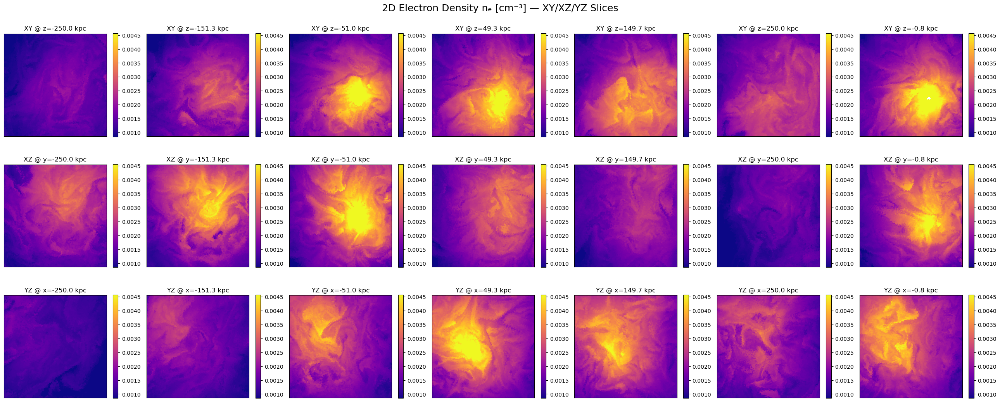

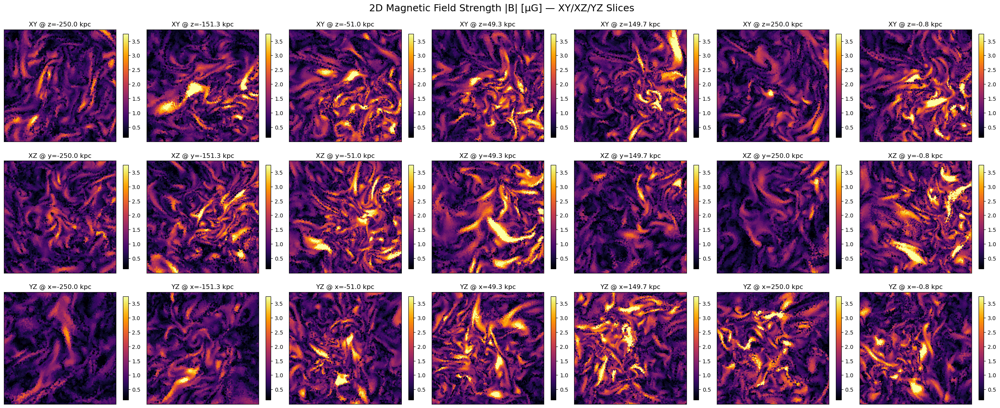

In [15]:
import sys
sys.path.append("/Users/Logan/illustris_python/")

import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from matplotlib.colors import LogNorm

filename    = "/Users/Logan/Documents/cutout_42631.hdf5"
h           = 0.6774
Ngrid       = 300    
extent_kpc  = 250.0   
Nslices     = 6            

# ============================================================
# LOAD GAS CELLS
# ============================================================
with h5py.File(filename, "r") as f:
    gas      = f["PartType0"]
    coords   = gas["Coordinates"][:]       # ckpc/h
    rho_code = gas["Density"][:]           # 1e10 Msun/h/(ckpc/h)^3
    ne_frac  = gas["ElectronAbundance"][:] # dimensionless
    B_vec    = gas["MagneticField"][:]     # μG
    redshift = f["Header"].attrs["Redshift"]

print("Loaded", len(coords), "gas cells")

# ============================================================
#CENTERING
# ============================================================
with h5py.File(filename, "r") as f:

    # 1. Subhalo position
    if "Subhalo" in f.keys() and "SubhaloPos" in f["Subhalo"].keys():
        center = f["Subhalo"]["SubhaloPos"][:] 
        print("Center = SubhaloPos")

    # 2. API cutout center
    elif "CutoutCenter" in f["Header"].attrs:
        center = f["Header"].attrs["CutoutCenter"]
        print("Center = Header/CutoutCenter")

    # 3. FOF group pos if exists
    elif "Group" in f.keys() and "GroupPos" in f["Group"].keys():
        center = f["Group"]["GroupPos"][:]  
        print("Center = FOF GroupPos")

    else:
        # 4. Mass-weighted centroid, more correct than simple mean
        center = np.average(coords, axis=0, weights=rho_code)
        print("Center = mass-weighted gas centroid")

# ============================================================
# CENTERING
# ============================================================
coords_centered = coords - center
coords_kpc = coords_centered / h / (1 + redshift)
x, y, z = coords_kpc.T

# ============================================================
# ELECTRON DENSITY 
# ============================================================
Msun   = 1.98847e33
kpc_cm = 3.0856776e21
m_p    = 1.6726219e-24

rho_phys   = rho_code * 1e10 * h**2 * (1 + redshift)**3   
rho_e_phys = rho_phys * ne_frac
rho_e_cgs  = rho_e_phys * Msun / kpc_cm**3               
ne_cm3     = rho_e_cgs / m_p                              

# magnetic field magnitude
B_mag = np.linalg.norm(B_vec, axis=1)    # μG

# ============================================================
# BUILD 3D UNIFORM GRID WITH KD-TREE
# ============================================================
print("Building KD-tree…")
pts  = np.column_stack([x, y, z])
tree = cKDTree(pts)

grid_lin = np.linspace(-extent_kpc, extent_kpc, Ngrid)
Xg, Yg, Zg = np.meshgrid(grid_lin, grid_lin, grid_lin, indexing="ij")
grid_points = np.column_stack([Xg.ravel(), Yg.ravel(), Zg.ravel()])

print("Querying KD-tree for nearest neighbors…")
_, idx = tree.query(grid_points, k=1)

ne_grid = ne_cm3[idx].reshape(Ngrid, Ngrid, Ngrid)
B_grid  = B_mag[idx].reshape(Ngrid, Ngrid, Ngrid)

# ============================================================
# MULTI-SLICE PLOT
# ============================================================
def plot_volume_slices(field, title, cmap="viridis", vmin=None, vmax=None):

    ncols = Nslices + 1 
    fig, axs = plt.subplots(3, ncols, figsize=(3.7*ncols, 11))

    slice_indices = np.linspace(0, Ngrid - 1, Nslices, dtype=int)
    idx0 = np.argmin(np.abs(grid_lin - 0.0))

    def do_plot(ax, img, txt):
        im = ax.imshow(img, origin="lower",
                       cmap=cmap, vmin=vmin, vmax=vmax,
                       extent=[-extent_kpc, extent_kpc,
                               -extent_kpc, extent_kpc])
        ax.set_title(txt)
        plt.colorbar(im, ax=ax, shrink=0.75)
        ax.set_xticks([]); ax.set_yticks([])

    for col, idx_slice in enumerate(list(slice_indices) + [idx0]):

        do_plot(axs[0,col],
                field[:,:,idx_slice].T,
                f"XY @ z={grid_lin[idx_slice]:.1f} kpc")

        do_plot(axs[1,col],
                field[:,idx_slice,:].T,
                f"XZ @ y={grid_lin[idx_slice]:.1f} kpc")

        do_plot(axs[2,col],
                field[idx_slice,:,:].T,
                f"YZ @ x={grid_lin[idx_slice]:.1f} kpc")

    fig.suptitle(title, fontsize=18)
    plt.tight_layout()
    plt.show()

# ============================================================
# PLOT 3D ELECTRON DENSITY (cm^-3)
# ============================================================
vmin_ne = np.percentile(ne_grid, 1)
vmax_ne = np.percentile(ne_grid, 99)

plot_volume_slices(
    ne_grid,
    title="2D Electron Density nₑ [cm⁻³] — XY/XZ/YZ Slices",
    cmap="plasma",
    vmin=vmin_ne,
    vmax=vmax_ne
)

# ============================================================
# PLOT 3D MAGNETIC FIELD (μG)
# ============================================================
vmin_B = np.percentile(B_grid, 1)
vmax_B = np.percentile(B_grid, 99)

plot_volume_slices(
    B_grid,
    title="2D Magnetic Field Strength |B| [μG] — XY/XZ/YZ Slices",
    cmap="inferno",
    vmin=vmin_B,
    vmax=vmax_B
)

Loaded 8560228 gas cells
Redshift = 2.220446049250313e-16
Mass-weighted centroid (relative ckpc/h): [-115.57621264   11.04095241  -15.82876114]
Center (absolute ckpc/h): [197521.71533809 112172.28680589 198428.71545849]
Mass-weighted centroid (relative physical kpc): [-170.61737916   16.29901448  -23.36693407]
Center (absolute physical kpc): [291588.00610878 165592.39268658 292926.94930394]


/var/folders/0m/cr_3cvys7fn6wcnlgpyhl8180000gn/T/ipykernel_30534/553296161.py:77: RuntimeWarning: overflow encountered in multiply
  rho_e_cgs = rho_e_Msun_kpc3 * Msun / (kpc_cm**3)  # g/cm^3


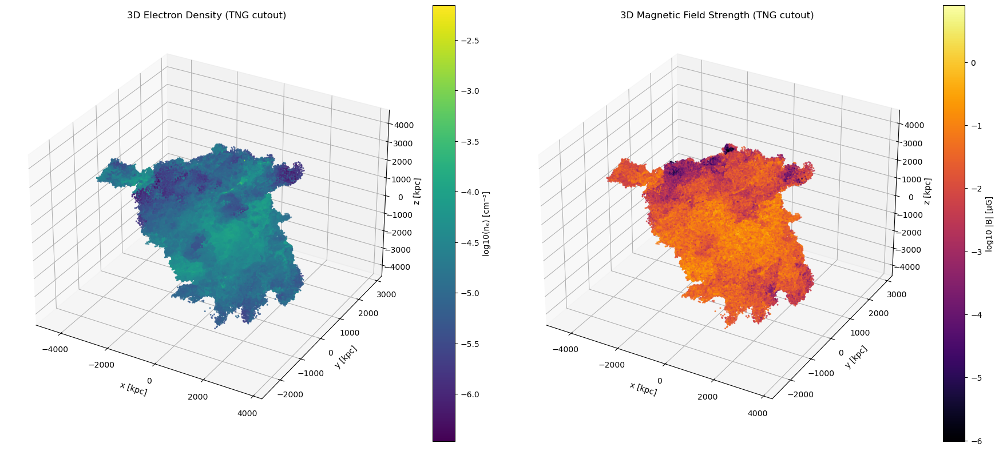

In [13]:
import sys
sys.path.append("/Users/Logan/illustris_python/")

import h5py
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# ============================================================
# USER INPUT
# ============================================================
filename = "/Users/Logan/Documents/cutout_42631.hdf5"
Nmax = 5_000_000

# ============================================================
# LOAD DATA
# ============================================================
with h5py.File(filename, "r") as f:
    gas = f["PartType0"]

    coords   = gas["Coordinates"][:]          # ckpc/h (absolute box coords)
    masses   = gas["Masses"][:]               # 1e10 Msun/h
    rho_code = gas["Density"][:]              # 1e10 Msun/h / (ckpc/h)^3
    ne_frac  = gas["ElectronAbundance"][:]    # dimensionless
    B_vec    = gas["MagneticField"][:]        # μG (already physical)
    redshift = f["Header"].attrs["Redshift"]
    h        = f["Header"].attrs["HubbleParam"]

print(f"Loaded {len(coords)} gas cells")
print("Redshift =", redshift)

# ============================================================
# CENTERING
# ============================================================

median_pos = np.median(coords, axis=0)      
coords_rel = coords - median_pos           

center_rel = np.average(coords_rel, axis=0, weights=masses)   
center = median_pos + center_rel                          

# to physical kpc
center_rel_kpc = center_rel / (h * (1 + redshift))
center_kpc      = center     / (h * (1 + redshift))

# ============================================================
# FOUR COORDINATES
# ============================================================

print("Mass-weighted centroid (relative ckpc/h):", center_rel)
print("Center (absolute ckpc/h):", center)

print("Mass-weighted centroid (relative physical kpc):", center_rel_kpc)
print("Center (absolute physical kpc):", center_kpc)


# ============================================================
# CONVERT COORDINATES TO PHYSICAL KPC
# ============================================================
coords_centered = coords - center           
coords_kpc = coords_centered / (h * (1 + redshift)) 

x, y, z = coords_kpc.T

# ============================================================
# ELECTRON NUMBER DENSITY [cm^-3]
# ============================================================
rho_phys_Msun_kpc3 = rho_code * 1e10 * h**2 * (1 + redshift)**3

rho_e_Msun_kpc3 = rho_phys_Msun_kpc3 * ne_frac 

Msun = 1.98847e33
kpc_cm = 3.0856776e21
m_p = 1.6726219e-24

rho_e_cgs = rho_e_Msun_kpc3 * Msun / (kpc_cm**3)  
ne_cm3 = rho_e_cgs / m_p                         

# ============================================================
# MAGNETIC FIELD STRENGTH
# ============================================================
B_mag = np.linalg.norm(B_vec, axis=1)
Ntot = len(x)
idx = np.random.choice(Ntot, size=min(Nmax, Ntot), replace=False)

x_s, y_s, z_s = x[idx], y[idx], z[idx]
ne_s = ne_cm3[idx]
B_s  = B_mag[idx]

# ============================================================
# 3D PLOTS
# ============================================================
fig = plt.figure(figsize=(18, 8))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
ax2 = fig.add_subplot(1, 2, 2, projection='3d')

# ------------------------------------------------------------
# Panel 1 — Electron density
# ------------------------------------------------------------
sc1 = ax1.scatter(
    x_s, y_s, z_s,
    c=np.log10(ne_s + 1e-30),
    s=1.5, cmap="viridis"
)

fig.colorbar(sc1, ax=ax1, label="log10(nₑ) [cm⁻³]")
ax1.set_title("3D Electron Density (TNG cutout)")
ax1.set_xlabel("x [kpc]")
ax1.set_ylabel("y [kpc]")
ax1.set_zlabel("z [kpc]")

# ------------------------------------------------------------
# Panel 2 — Magnetic field
# ------------------------------------------------------------
sc2 = ax2.scatter(
    x_s, y_s, z_s,
    c=np.log10(B_s + 1e-30),
    s=1.5, cmap="inferno"
)

fig.colorbar(sc2, ax=ax2, label="log10 |B| [μG]")
ax2.set_title("3D Magnetic Field Strength (TNG cutout)")
ax2.set_xlabel("x [kpc]")
ax2.set_ylabel("y [kpc]")
ax2.set_zlabel("z [kpc]")

plt.tight_layout()
plt.show()


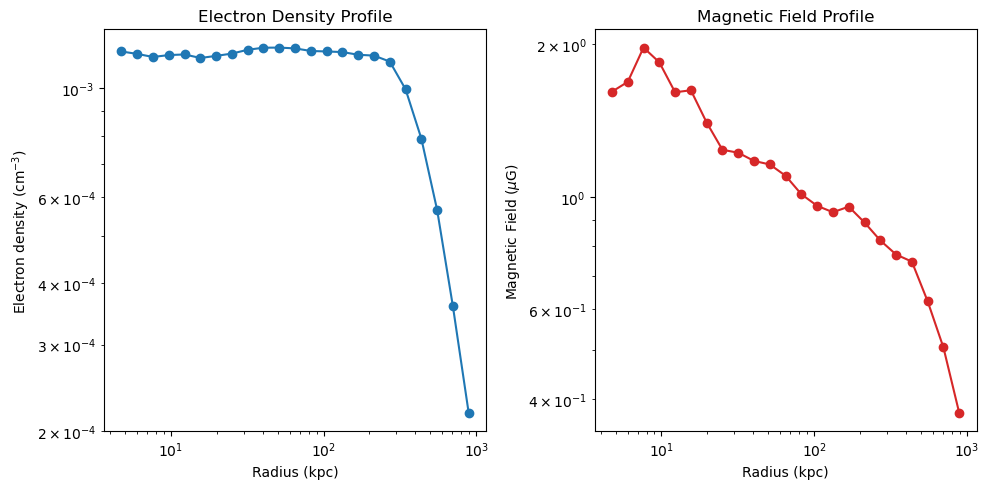

In [9]:
import sys
sys.path.append("/Users/Logan/illustris_python/")

import illustris_python as il
import h5py
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# USER INPUT
# ============================================================
filename = "/Users/Logan/Documents/cutout_42631.hdf5"
h = 0.6774

# ============================================================
# LOAD
# ============================================================
with h5py.File(filename, "r") as f:
    gas = f["PartType0"]

    coords = gas["Coordinates"][:]        # ckpc/h
    masses = gas["Masses"][:] * 1e10      # Msun  (convert early)
    rho_code = gas["Density"][:]          # 1e10 Msun/h / (ckpc/h)^3
    ne_frac = gas["ElectronAbundance"][:] # dimensionless
    B_code  = gas["MagneticField"][:]     # μG physical

    redshift = f["Header"].attrs["Redshift"]
    h        = f["Header"].attrs["HubbleParam"]

# ============================================================
# CENTER HALO
try:
    with h5py.File(filename, "r") as f:
        center = f["Subhalo"]["SubhaloPos"][:]  # ckpc/h
except:
    center = coords.mean(axis=0)

coords_centered = coords - center
r_comoving = np.linalg.norm(coords_centered, axis=1)

# physical radius in kpc
r_kpc = r_comoving / (1 + redshift) / h

# ============================================================
# PHYSICAL GAS DENSITY
rho_phys = rho_code * 1e10 * h**2 * (1 + redshift)**3 

#cell volumes V = m / ρ
V_kpc3 = masses / rho_phys 

# ============================================================
# RADIAL BINNING
# ============================================================
r_bins = np.logspace(0, 3, 30)      # 1–1000 kpc
r_centers = 0.5*(r_bins[:-1] + r_bins[1:])
digitized = np.digitize(r_kpc, r_bins)

# ============================================================
# VOLUME-WEIGHTED AVERAGE FUNCTION
# ============================================================
def radial_avg_volume_weighted(quantity):
    out = []
    for i in range(1, len(r_bins)):
        mask = digitized == i
        if mask.any():
            out.append(np.average(quantity[mask], weights=V_kpc3[mask]))
        else:
            out.append(np.nan)
    return np.array(out)

# ============================================================
# PROFILES
# ============================================================
rho_profile_Msun_kpc3 = radial_avg_volume_weighted(rho_phys)
nefrac_profile = radial_avg_volume_weighted(ne_frac)

# B-field mag
B_mag_uG = np.linalg.norm(B_code, axis=1)
B_profile_uG = radial_avg_volume_weighted(B_mag_uG)

# ============================================================
# ELECTRON DENSITY n_e [cm^-3]
# ============================================================
Msun   = 1.98847e33                   
kpc_cm = 3.0856775814913673e21         
mp     = 1.6726219e-24                 
X_H    = 0.76                         


rho_g_cm3 = rho_profile_Msun_kpc3 * Msun / (kpc_cm**3)
n_H = X_H * rho_g_cm3 / mp
n_e_profile_cm3 = nefrac_profile * n_H

# ============================================================
# PLOT
# ============================================================
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.loglog(r_centers, n_e_profile_cm3, "o-")
plt.xlabel("Radius (kpc)")
plt.ylabel(r"Electron density (cm$^{-3}$)")
plt.title("Electron Density Profile")

plt.subplot(1,2,2)
plt.loglog(r_centers, B_profile_uG, "o-", color="tab:red")
plt.xlabel("Radius (kpc)")
plt.ylabel(r"Magnetic Field ($\mu$G)")
plt.title("Magnetic Field Profile")

plt.tight_layout()
plt.show()

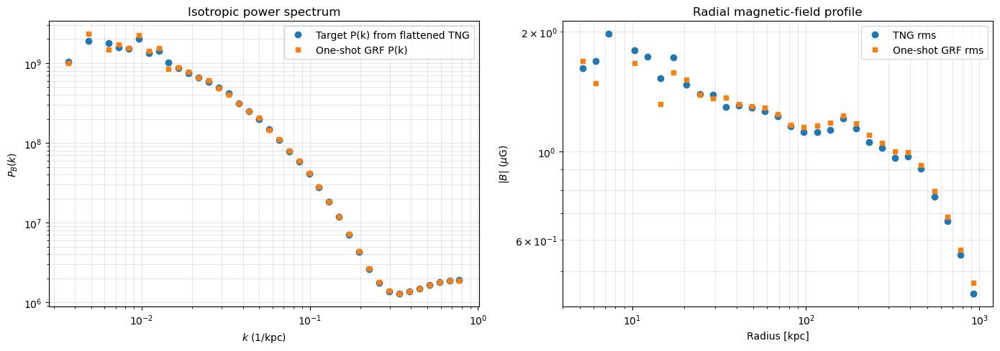

In [3]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# USER INPUT
# ============================================================
filename = "/Users/Logan/Documents/cutout_42631.hdf5"

# Grid
GRID_N = 70 * 4
USE_PHYSICAL_GRID = True 

Rmax_kpc  = 1000.0
Nr_bins   = 40
r0_kpc    = 24
BENV_STAT = "rms"         # "mean" or "rms" radial envelope definition

# Power spectrum binning
N_K_BINS = 40
SEED = 1

APPLY_TNG_ENVELOPE = True

# ============================================================
# CONSTANTS
# ============================================================
kpc_cm = 3.08567758e21

# ============================================================
# Helpers
# ============================================================
def load_cutout(fname):
    with h5py.File(fname, "r") as f:
        gas = f["PartType0"]
        coords_ckpc_h = gas["Coordinates"][:]
        B_vec_uG      = gas["MagneticField"][:]  
        rho_code      = gas["Density"][:]
        masses_code   = gas["Masses"][:]
        z = float(f["Header"].attrs["Redshift"])
        h = float(f["Header"].attrs["HubbleParam"])
        try:
            center_ckpc_h = f["Subhalo"]["SubhaloPos"][:]
        except KeyError:
            center_ckpc_h = coords_ckpc_h.mean(axis=0)
    return coords_ckpc_h, center_ckpc_h, B_vec_uG, rho_code, masses_code, z, h


def physical_coords_kpc(coords_ckpc_h, center_ckpc_h, z, h):
    coords_rel_kpc = (coords_ckpc_h - center_ckpc_h) / h / (1.0 + z)
    r_kpc = np.sqrt(np.sum(coords_rel_kpc**2, axis=1))
    return coords_rel_kpc, r_kpc


def cell_volumes_cm3(rho_code, masses_code, z, h):
    rho_phys = rho_code * 1e10 * h**2 * (1.0 + z)**3 
    masses_Msun = masses_code * 1e10                  
    V_kpc3 = np.nan_to_num(masses_Msun / rho_phys, nan=0.0, posinf=0.0, neginf=0.0)
    return V_kpc3 * (kpc_cm**3)


def radial_envelope_from_cells(r_kpc, B_mag_uG, weights, Rmax_kpc, Nr_bins, stat="rms"):
    r_bins    = np.logspace(0, np.log10(Rmax_kpc), Nr_bins + 1)
    r_centers = 0.5 * (r_bins[:-1] + r_bins[1:])
    dig       = np.digitize(r_kpc, r_bins)

    B_env = np.full(Nr_bins, np.nan)
    ok    = np.zeros(Nr_bins, dtype=bool)

    for i in range(Nr_bins):
        m = (dig == (i + 1))
        if np.any(m):
            w = weights[m]
            if stat == "mean":
                B_env[i] = np.average(B_mag_uG[m], weights=w)
            elif stat == "rms":
                B_env[i] = np.sqrt(np.average(B_mag_uG[m] ** 2, weights=w))
            else:
                raise ValueError("stat must be 'mean' or 'rms'")
            ok[i] = np.isfinite(B_env[i]) and (B_env[i] > 0)

    m = ok & np.isfinite(B_env) & (B_env > 0)
    return r_centers[m], B_env[m]


def flatten_cells_by_envelope(r_kpc, B_vec_uG, r_env, B_env, r0_kpc):
    B_r0 = np.interp(r0_kpc, r_env, B_env)
    B_env_cell = np.interp(r_kpc, r_env, B_env, left=np.nan, right=np.nan)

    good = np.isfinite(B_env_cell) & (B_env_cell > 0) & np.isfinite(B_vec_uG).all(axis=1)

    corr = np.ones_like(B_env_cell)
    corr[good] = (B_r0 / B_env_cell[good])

    B_flat = np.zeros_like(B_vec_uG)
    B_flat[good] = B_vec_uG[good] * corr[good][:, None]
    return B_flat, good


def deposit_to_grid(coords, B_vec, GRID_N):
    mins = coords.min(axis=0)
    maxs = coords.max(axis=0)
    Lx, Ly, Lz = (maxs - mins)

    edges = [
        np.linspace(mins[0], maxs[0], GRID_N + 1),
        np.linspace(mins[1], maxs[1], GRID_N + 1),
        np.linspace(mins[2], maxs[2], GRID_N + 1),
    ]

    counts, _ = np.histogramdd(coords, bins=edges)

    Bx_sum, _ = np.histogramdd(coords, bins=edges, weights=B_vec[:, 0])
    By_sum, _ = np.histogramdd(coords, bins=edges, weights=B_vec[:, 1])
    Bz_sum, _ = np.histogramdd(coords, bins=edges, weights=B_vec[:, 2])

    counts = counts.astype(float)
    counts[counts == 0] = np.nan

    Bx = np.nan_to_num(Bx_sum / counts, nan=0.0)
    By = np.nan_to_num(By_sum / counts, nan=0.0)
    Bz = np.nan_to_num(Bz_sum / counts, nan=0.0)
    return (Bx, By, Bz), (Lx, Ly, Lz), edges


def voxel_center_radii(edges):
    xc = 0.5 * (edges[0][:-1] + edges[0][1:])
    yc = 0.5 * (edges[1][:-1] + edges[1][1:])
    zc = 0.5 * (edges[2][:-1] + edges[2][1:])
    xg, yg, zg = np.meshgrid(xc, yc, zc, indexing="ij")
    return np.sqrt(xg**2 + yg**2 + zg**2)


def k_grid(N, Lx, Ly, Lz):
    dx, dy, dz = Lx / N, Ly / N, Lz / N
    kx = 2 * np.pi * np.fft.fftfreq(N, d=dx)
    ky = 2 * np.pi * np.fft.fftfreq(N, d=dy)
    kz = 2 * np.pi * np.fft.fftfreq(N, d=dz)
    kxg, kyg, kzg = np.meshgrid(kx, ky, kz, indexing="ij")
    kmag = np.sqrt(kxg**2 + kyg**2 + kzg**2)
    return kxg, kyg, kzg, kmag


def project_div_free(Bx_k, By_k, Bz_k, kxg, kyg, kzg):
    k2 = kxg**2 + kyg**2 + kzg**2
    k2 = np.where(k2 > 0, k2, np.inf)

    k_dot_B = kxg * Bx_k + kyg * By_k + kzg * Bz_k
    Bx_k = Bx_k - kxg * k_dot_B / k2
    By_k = By_k - kyg * k_dot_B / k2
    Bz_k = Bz_k - kzg * k_dot_B / k2

    Bx_k[0, 0, 0] = 0.0
    By_k[0, 0, 0] = 0.0
    Bz_k[0, 0, 0] = 0.0
    return Bx_k, By_k, Bz_k


def isotropic_binned_Pk_from_grids(Bx, By, Bz, Lx, Ly, Lz, k_edges, demean=True):
    if demean:
        Bx = Bx - np.mean(Bx)
        By = By - np.mean(By)
        Bz = Bz - np.mean(Bz)

    Bx_k = np.fft.fftn(Bx)
    By_k = np.fft.fftn(By)
    Bz_k = np.fft.fftn(Bz)

    power_k = (np.abs(Bx_k)**2 + np.abs(By_k)**2 + np.abs(Bz_k)**2) / 3.0
    _, _, _, kmag = k_grid(Bx.shape[0], Lx, Ly, Lz)

    k_flat = kmag.ravel()
    P_flat = power_k.ravel()
    mpos   = k_flat > 0
    k_flat = k_flat[mpos]
    P_flat = P_flat[mpos]

    k_cent = 0.5 * (k_edges[:-1] + k_edges[1:])
    Pk = np.full_like(k_cent, np.nan, dtype=float)

    for i in range(len(k_cent)):
        m = (k_flat >= k_edges[i]) & (k_flat < k_edges[i + 1])
        if np.any(m):
            Pk[i] = np.mean(P_flat[m])

    return k_cent, Pk


def radial_envelope_on_grid(Bx, By, Bz, r_grid, r_edges, stat="rms"):
    Bmag = np.sqrt(Bx**2 + By**2 + Bz**2)
    vals = Bmag.ravel()
    rr   = r_grid.ravel()
    dig  = np.digitize(rr, r_edges)

    Nr = len(r_edges) - 1
    r_cent = 0.5 * (r_edges[:-1] + r_edges[1:])

    B_env = np.full(Nr, np.nan)
    ok    = np.zeros(Nr, dtype=bool)

    for i in range(Nr):
        m = (dig == (i + 1))
        if np.any(m):
            if stat == "mean":
                B_env[i] = np.mean(vals[m])
            elif stat == "rms":
                B_env[i] = np.sqrt(np.mean(vals[m]**2))
            else:
                raise ValueError("stat must be 'mean' or 'rms'")
            ok[i] = np.isfinite(B_env[i]) and (B_env[i] > 0)

    m = ok & np.isfinite(B_env) & (B_env > 0)
    return r_cent[m], B_env[m]


def make_loglog_interp(x, y):
    x = np.asarray(x); y = np.asarray(y)
    m = np.isfinite(x) & np.isfinite(y) & (x > 0) & (y > 0)
    x = x[m]; y = y[m]
    lx = np.log(x); ly = np.log(y)

    def f(z):
        z = np.asarray(z)
        out = np.zeros_like(z, dtype=float)
        mm = z > 0
        out[mm] = np.exp(np.interp(np.log(z[mm]), lx, ly, left=ly[0], right=ly[-1]))
        return out

    return f


def apply_radial_envelope_once(Bx, By, Bz, r_grid, r_env_target, B_env_target, r0_kpc):
    target = make_loglog_interp(r_env_target, B_env_target)
    tar_r0 = target(r0_kpc)

    s = np.ones_like(r_grid, dtype=float)
    m = r_grid > 0
    s[m] = target(r_grid[m]) / tar_r0

    return Bx * s, By * s, Bz * s


def synthesize_grf_from_binned_Pk(kmag, k_edges, Pk_bins, rng, eps=1e-30):
    N = kmag.shape[0]
    Bx_k = np.zeros((N, N, N), dtype=np.complex128)
    By_k = np.zeros((N, N, N), dtype=np.complex128)
    Bz_k = np.zeros((N, N, N), dtype=np.complex128)
    for i in range(len(Pk_bins)):
        Ptar = Pk_bins[i]
        if not (np.isfinite(Ptar) and Ptar > 0):
            continue

        kmin, kmax = k_edges[i], k_edges[i + 1]
        m = (kmag >= kmin) & (kmag < kmax) & (kmag > 0)

        if not np.any(m):
            continue
        Bx_k[m] = rng.normal(size=m.sum()) + 1j * rng.normal(size=m.sum())
        By_k[m] = rng.normal(size=m.sum()) + 1j * rng.normal(size=m.sum())
        Bz_k[m] = rng.normal(size=m.sum()) + 1j * rng.normal(size=m.sum())
        power_cur = (np.abs(Bx_k[m])**2 + np.abs(By_k[m])**2 + np.abs(Bz_k[m])**2) / 3.0
        Pcur = np.mean(power_cur)

        if Pcur > eps:
            s = np.sqrt(Ptar / Pcur)
            Bx_k[m] *= s
            By_k[m] *= s
            Bz_k[m] *= s

    # kill k=0
    Bx_k[0, 0, 0] = 0.0
    By_k[0, 0, 0] = 0.0
    Bz_k[0, 0, 0] = 0.0
    return Bx_k, By_k, Bz_k


# ============================================================
# 1)TNG envelope + turbulent spectrum
# ============================================================
coords_ckpc_h, center_ckpc_h, B_vec_uG, rho_code, masses_code, z, h = load_cutout(filename)
coords_rel_kpc, r_kpc = physical_coords_kpc(coords_ckpc_h, center_ckpc_h, z, h)

V_cm3     = cell_volumes_cm3(rho_code, masses_code, z, h)
B_mag_uG  = np.linalg.norm(B_vec_uG, axis=1)

# Radial envelope from TNG (volume-weighted)
r_env_tng, B_env_tng = radial_envelope_from_cells(
    r_kpc, B_mag_uG, V_cm3, Rmax_kpc, Nr_bins, stat=BENV_STAT
)
# Flatten cells by env to isolate turb and extract P(k)
B_vec_flat_uG, good = flatten_cells_by_envelope(r_kpc, B_vec_uG, r_env_tng, B_env_tng, r0_kpc)

if USE_PHYSICAL_GRID:
    coords_for_grid = coords_rel_kpc
    k_xlabel = r"$k$ (1/kpc)"
else:
    coords_for_grid = coords_ckpc_h
    k_xlabel = r"$k$ (1/(ckpc/h))"

#flattened field
(Bx_flat, By_flat, Bz_flat), (Lx, Ly, Lz), edges = deposit_to_grid(
    coords_for_grid[good], B_vec_flat_uG[good], GRID_N
)


kxg, kyg, kzg, kmag = k_grid(GRID_N, Lx, Ly, Lz)
kpos = kmag[kmag > 0]
k_edges = np.logspace(np.log10(kpos.min()), np.log10(kpos.max()), N_K_BINS + 1)
k_cent  = 0.5 * (k_edges[:-1] + k_edges[1:])

# binned P(k) from flattened TNG
k_cent_tng, Pk_tng = isotropic_binned_Pk_from_grids(
    Bx_flat, By_flat, Bz_flat, Lx, Ly, Lz, k_edges, demean=True
)
Pk_target_bins = Pk_tng.copy()
Pk_target_bins[~np.isfinite(Pk_target_bins) | (Pk_target_bins <= 0)] = np.nan


r_grid  = voxel_center_radii(edges)
r_edges = np.logspace(0, np.log10(Rmax_kpc), Nr_bins + 1)
r_cent_plot = 0.5 * (r_edges[:-1] + r_edges[1:])

# TNG radial profile on cells
dig_cells = np.digitize(r_kpc, r_edges)
Bprof_tng = np.full(len(r_cent_plot), np.nan)
for i in range(len(r_cent_plot)):
    m = (dig_cells == (i + 1))
    if np.any(m):
        w = V_cm3[m]
        if BENV_STAT == "mean":
            Bprof_tng[i] = np.average(B_mag_uG[m], weights=w)
        else:
            Bprof_tng[i] = np.sqrt(np.average(B_mag_uG[m] ** 2, weights=w))
m_tng_prof = np.isfinite(Bprof_tng) & (Bprof_tng > 0)
r_prof_tng = r_cent_plot[m_tng_prof]
Bprof_tng  = Bprof_tng[m_tng_prof]

# ============================================================
# 2) ONE-SHOT GRF SYNTHESIS FROM P(k) bins
# ============================================================
rng = np.random.default_rng(SEED)

# Build k-space GRF whose binned power matches Pk_target_bins
Bx_k, By_k, Bz_k = synthesize_grf_from_binned_Pk(kmag, k_edges, Pk_target_bins, rng)








# Enforce divergence-free in k-space
Bx_k, By_k, Bz_k = project_div_free(Bx_k, By_k, Bz_k, kxg, kyg, kzg)

# Project the field onto the divergence-free subspace in Fourier space by removing the component parallel to k:
#B_perp(k) = B(k) - k ([k.B(k)]/|k|^2)
# After this projection, k · B(k) = 0 for all k ≠ 0.







# Back to real space (homogeneous GRF)
Bx = np.fft.ifftn(Bx_k).real
By = np.fft.ifftn(By_k).real
Bz = np.fft.ifftn(Bz_k).real

if APPLY_TNG_ENVELOPE:
    Bx, By, Bz = apply_radial_envelope_once(Bx, By, Bz, r_grid, r_env_tng, B_env_tng, r0_kpc)

    Bx_k = np.fft.fftn(Bx); By_k = np.fft.fftn(By); Bz_k = np.fft.fftn(Bz)
    Bx_k, By_k, Bz_k = project_div_free(Bx_k, By_k, Bz_k, kxg, kyg, kzg)
    Bx = np.fft.ifftn(Bx_k).real
    By = np.fft.ifftn(By_k).real
    Bz = np.fft.ifftn(Bz_k).real

r_env_grf, B_env_grf = radial_envelope_on_grid(Bx, By, Bz, r_grid, r_edges, stat=BENV_STAT)
B_r0_grf = np.interp(r0_kpc, r_env_grf, B_env_grf)
B_r0_tng = np.interp(r0_kpc, r_env_tng, B_env_tng)
if np.isfinite(B_r0_grf) and (B_r0_grf > 0):
    scale = B_r0_tng / B_r0_grf
    Bx *= scale; By *= scale; Bz *= scale

# ============================================================
# 3)spectrum + radial comparison
# ============================================================
k_cent_grf, Pk_grf = isotropic_binned_Pk_from_grids(Bx, By, Bz, Lx, Ly, Lz, k_edges, demean=True)

Bmag_grf = np.sqrt(Bx**2 + By**2 + Bz**2)
dig_grid = np.digitize(r_grid.ravel(), r_edges)
Bprof_grf = np.full(len(r_cent_plot), np.nan)
vals = Bmag_grf.ravel()
for i in range(len(r_cent_plot)):
    m = (dig_grid == (i + 1))
    if np.any(m):
        if BENV_STAT == "mean":
            Bprof_grf[i] = np.mean(vals[m])
        else:
            Bprof_grf[i] = np.sqrt(np.mean(vals[m] ** 2))
m_grf_prof = np.isfinite(Bprof_grf) & (Bprof_grf > 0)
r_prof_grf = r_cent_plot[m_grf_prof]
Bprof_grf  = Bprof_grf[m_grf_prof]

# ============================================================
# 4) PLOTS
# ============================================================
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# ---- LEFT: Power spectrum ----
ax[0].loglog(k_cent_tng, Pk_tng, "o", label="Target P(k) from flattened TNG")
ax[0].loglog(k_cent_grf, Pk_grf, "s", ms=4, label="One-shot GRF P(k)")

ax[0].set_xlabel(k_xlabel)
ax[0].set_ylabel(r"$P_B(k)$")
ax[0].set_title("Isotropic power spectrum")
ax[0].grid(True, which="both", alpha=0.3)
ax[0].legend()

# ---- RIGHT: Radial profile GRF vs TNG ----
ax[1].loglog(r_prof_tng, Bprof_tng, "o", label=f"TNG {BENV_STAT}")
lab = f"One-shot GRF {BENV_STAT}"
if not APPLY_TNG_ENVELOPE:
    lab += " (no envelope applied)"
ax[1].loglog(r_prof_grf, Bprof_grf, "s", ms=4, label=lab)

ax[1].set_xlabel("Radius [kpc]")
ax[1].set_ylabel(r"$|B|$ ($\mu$G)")
ax[1].set_title("Radial magnetic-field profile")
ax[1].grid(True, which="both", alpha=0.3)
ax[1].legend()

plt.tight_layout()
plt.show()
# ---- expose as "target P3D" for the LoS script ----
k_edges_P3D = k_edges.copy()
P3D_bins    = Pk_target_bins.copy()

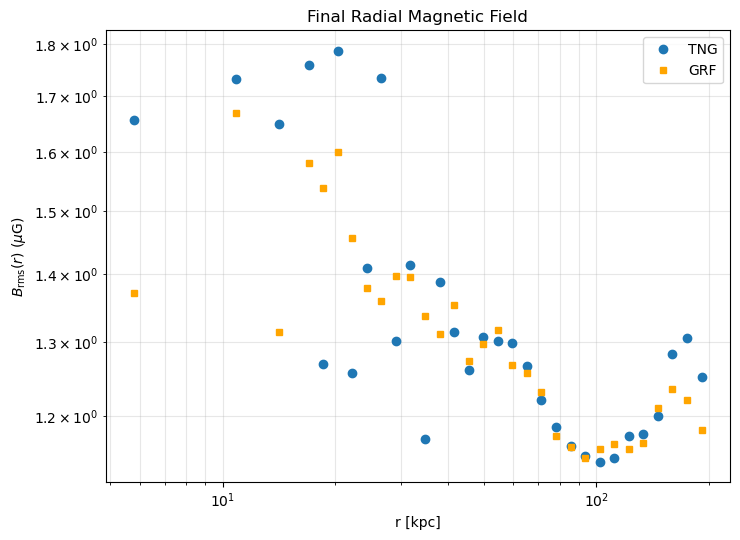

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import h5py

# ----------------------------
# Load TNG coord
# ----------------------------
def load_tng_coords_and_B(filename):
    """
    Returns:
      coords_kpc: (N,3) physical kpc centered on subhalo pos
      B_vec_raw : (N,3) MagneticField as stored in file (units NOT converted here)
      header    : dict with z, h
    """
    with h5py.File(filename, "r") as f:
        gas = f["PartType0"]
        coords_ckpc_h = gas["Coordinates"][:]
        B_vec_raw     = gas["MagneticField"][:] 

        z = float(f["Header"].attrs["Redshift"])
        h = float(f["Header"].attrs["HubbleParam"])
        try:
            center_ckpc_h = f["Subhalo"]["SubhaloPos"][:]
        except Exception:
            center_ckpc_h = coords_ckpc_h.mean(axis=0)

    coords_kpc = (coords_ckpc_h - center_ckpc_h) / h / (1.0 + z)
    header = {"z": z, "h": h}
    return coords_kpc, B_vec_raw, header

def convert_B_to_uG(B_vec_raw, convert="assume_uG_physical", factor_to_uG=None):
    if convert == "assume_uG_physical":
        return np.asarray(B_vec_raw, float)
    if convert == "factor":
        if factor_to_uG is None:
            raise ValueError("factor_to_uG must be provided when convert='factor'")
        return np.asarray(B_vec_raw, float) * float(factor_to_uG)
    raise ValueError(f"Unknown convert mode: {convert}")


# ----------------------------
# Deposit <B^2> to grid (FIXED)
# ----------------------------
def deposit_B2_to_grid(coords_kpc, B_vec_uG, edges, weights=None):
    coords_kpc = np.asarray(coords_kpc, float)
    B_vec_uG   = np.asarray(B_vec_uG, float)

    if weights is None:
        weights = np.ones(len(coords_kpc), float)
    else:
        weights = np.asarray(weights, float)
        if len(weights) != len(coords_kpc):
            raise ValueError("weights must have same length as coords_kpc")
    W, _ = np.histogramdd(coords_kpc, bins=edges, weights=weights)
    W = W.astype(float)
    W[W == 0] = np.nan
    B2 = (B_vec_uG[:, 0]**2 + B_vec_uG[:, 1]**2 + B_vec_uG[:, 2]**2)
    B2_sum, _ = np.histogramdd(coords_kpc, bins=edges, weights=weights * B2)
    B2_vox = B2_sum / W
    B2_vox = np.nan_to_num(B2_vox, nan=0.0)
    return B2_vox


# ----------------------------
# Radial RMS
# ----------------------------
def radial_rms_from_B2_grid(B2_vox_uG2, edges, Nr_bins=40, rmax_kpc=None):
    """
    Compute Brms(r) = sqrt( mean_shell( <B^2>_voxel ) )
    """
    x_edges, y_edges, z_edges = edges
    xc = 0.5*(x_edges[:-1] + x_edges[1:])
    yc = 0.5*(y_edges[:-1] + y_edges[1:])
    zc = 0.5*(z_edges[:-1] + z_edges[1:])
    x3, y3, z3 = np.meshgrid(xc, yc, zc, indexing="ij")
    r3 = np.sqrt(x3**2 + y3**2 + z3**2)

    r  = r3.ravel()
    B2 = np.asarray(B2_vox_uG2, float).ravel()
    mpos = np.isfinite(B2) & (B2 > 0) & np.isfinite(r) & (r > 0)
    if not np.any(mpos):
        raise RuntimeError("No positive B^2 voxels found. Check your inputs/units.")

    if rmax_kpc is None:
        rmax_kpc = float(np.max(r[mpos]))
    rmin_kpc = float(np.min(r[mpos]))

    r_edges = np.logspace(np.log10(rmin_kpc), np.log10(rmax_kpc), Nr_bins + 1)
    r_cent  = 0.5*(r_edges[:-1] + r_edges[1:])

    Brms = np.full(Nr_bins, np.nan)
    for i in range(Nr_bins):
        ms = (r >= r_edges[i]) & (r < r_edges[i+1]) & mpos
        if np.any(ms):
            Brms[i] = np.sqrt(np.mean(B2[ms]))

    good = np.isfinite(Brms) & (Brms > 0)
    return r_cent[good], Brms[good]

def print_rms_sanity(label, B_vec_uG=None, B2_vox_uG2=None):
    if B_vec_uG is not None:
        cell_rms = np.sqrt(np.mean(np.sum(B_vec_uG**2, axis=1)))
        print(f"{label}: cell RMS(|B|) = {cell_rms:.4g} μG")
    if B2_vox_uG2 is not None:
        v = B2_vox_uG2[B2_vox_uG2 > 0]
        vox_rms = np.sqrt(np.mean(v)) if len(v) else np.nan


# ============================================================
# RUN
# ============================================================
def main():
    global edges, Bx, By, Bz
    if "edges" not in globals():
        raise RuntimeError("Missing 'edges' in memory: edges=[x_edges,y_edges,z_edges] (kpc).")
    if any(k not in globals() for k in ("Bx", "By", "Bz")):
        raise RuntimeError("Missing GRF grid fields in memory: need Bx, By, Bz in μG on the grid.")

    tng_file = "/Users/Logan/Documents/cutout_42631.hdf5"

    # ----------------------------
    # GRF
    # ----------------------------
    B2_grf_vox = (np.asarray(Bx, float)**2 + np.asarray(By, float)**2 + np.asarray(Bz, float)**2)

    # ----------------------------
    # TNG
    coords_kpc, B_raw, _ = load_tng_coords_and_B(tng_file)
    B_uG = convert_B_to_uG(B_raw, convert="assume_uG_physical")

    B2_tng_vox = deposit_B2_to_grid(coords_kpc, B_uG, edges, weights=None)
    # ----------------------------
    # Radial RMS profiles
    # ----------------------------
    rmax = 200.0
    Nr_bins = 40
    r_grf, Brms_grf = radial_rms_from_B2_grid(B2_grf_vox, edges, Nr_bins=Nr_bins, rmax_kpc=rmax)
    r_tng, Brms_tng = radial_rms_from_B2_grid(B2_tng_vox, edges, Nr_bins=Nr_bins, rmax_kpc=rmax)

    # ----------------------------
    # Plot
    # ----------------------------
    plt.figure(figsize=(7.5, 5.5))
    plt.loglog(r_tng, Brms_tng, "o", color="tab:blue", label="TNG")
    plt.loglog(r_grf, Brms_grf, "s", ms=4, color="orange", label="GRF")
    plt.xlabel("r [kpc]")
    plt.ylabel(r"$B_{\rm rms}(r)$ ($\mu$G)")
    plt.title("Final Radial Magnetic Field")
    plt.grid(True, which="both", alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    main()

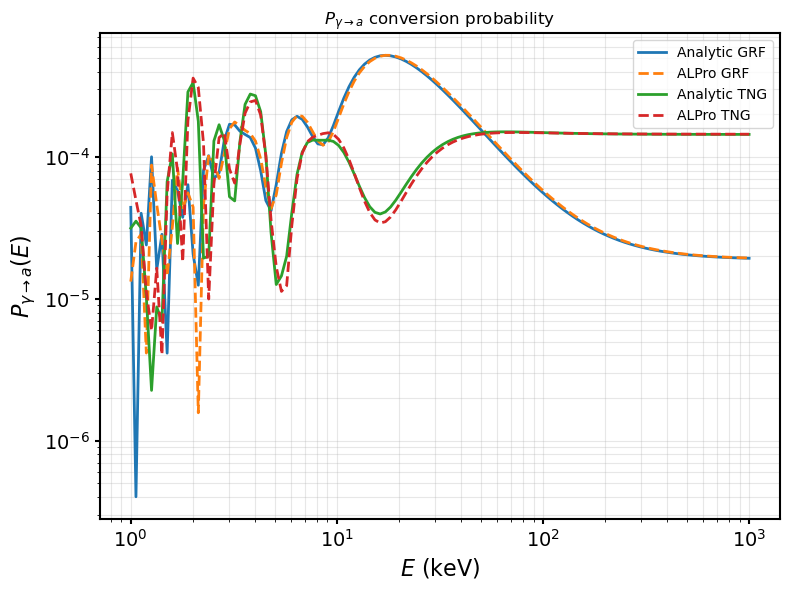

In [37]:
import sys
sys.path.append("/Users/Logan/illustris_python/")
sys.path.append("/Users/Logan/ALPro")

import h5py
import numpy as np
import matplotlib.pyplot as plt
import warnings
import os
import alpro

os.environ["ALPRO_QUIET"] = "1"
sys.stdout = open(os.devnull, "w")  # silence chatter

# ============================================================
# Units
# ============================================================
kpc_to_eVinv = 1.5637e26
G_to_eV2     = 1.95e-2
m_p_gram     = 1.6726219e-24
Msun_gram    = 1.98847e33
kpc_cm       = 3.08567758e21

def omega_pl(ne_cm3):
    return 3.69e-11 * np.sqrt(ne_cm3)

# ============================================================
ALPRO_RETURNS_SURVIVAL = True

# ============================================================
# TNG: radial electron-density profile (volume-weighted)
# ============================================================
def get_tng_radial_ne_profile(filename, N_r_bins=40):
    with h5py.File(filename, "r") as f:
        gas = f["PartType0"]
        coords_ckpc_h = gas["Coordinates"][:]
        rho_code      = gas["Density"][:]
        ne_frac       = gas["ElectronAbundance"][:]
        masses_code   = gas["Masses"][:]
        redshift      = float(f["Header"].attrs["Redshift"])
        h             = float(f["Header"].attrs["HubbleParam"])

        try:
            center_ckpc_h = f["Subhalo"]["SubhaloPos"][:]
        except KeyError:
            center_ckpc_h = coords_ckpc_h.mean(axis=0)

    coords_rel_kpc = (coords_ckpc_h - center_ckpc_h) / h / (1 + redshift)
    r_kpc = np.linalg.norm(coords_rel_kpc, axis=1)

    rho_phys_Msun_kpc3 = rho_code * 1e10 * h**2 * (1 + redshift)**3
    rho_phys_g_cm3     = rho_phys_Msun_kpc3 * Msun_gram / (kpc_cm**3)

    masses_Msun = masses_code * 1e10
    V_kpc3      = masses_Msun / rho_phys_Msun_kpc3
    V_cm3       = V_kpc3 * (kpc_cm**3)

    ne_cell_cm3 = ne_frac * rho_phys_g_cm3 / m_p_gram

    r_min = max(1.0, np.min(r_kpc[r_kpc > 0]))
    r_max = np.max(r_kpc)
    r_bins = np.logspace(np.log10(r_min), np.log10(r_max), N_r_bins + 1)
    r_cent = 0.5*(r_bins[:-1] + r_bins[1:])

    ne_prof = np.full(N_r_bins, np.nan)
    for i in range(N_r_bins):
        m = (r_kpc >= r_bins[i]) & (r_kpc < r_bins[i+1])
        if np.any(m):
            ne_prof[i] = np.average(ne_cell_cm3[m], weights=V_cm3[m])

    valid = np.isfinite(ne_prof)
    if not np.all(valid):
        ne_prof = np.interp(r_cent, r_cent[valid], ne_prof[valid])

    return r_cent, ne_prof

# ============================================================
# TNG LOS (volume-weighted cylinder)
# ============================================================
def build_tng_los_volume_weighted(tng_filename, R_cyl_kpc=20.0, N_bins=500, smooth_window=7):
    with h5py.File(tng_filename, "r") as f:
        gas = f["PartType0"]

        coords_ckpc_h = gas["Coordinates"][:]
        rho_code      = gas["Density"][:]
        ne_frac       = gas["ElectronAbundance"][:]
        B_vec_uG      = gas["MagneticField"][:]
        masses_code   = gas["Masses"][:]

        redshift = float(f["Header"].attrs["Redshift"])
        h        = float(f["Header"].attrs["HubbleParam"])

        try:
            center_ckpc_h = f["Subhalo"]["SubhaloPos"][:]
        except KeyError:
            center_ckpc_h = coords_ckpc_h.mean(axis=0)

    coords_rel_kpc = (coords_ckpc_h - center_ckpc_h) / h / (1 + redshift)
    x_kpc = coords_rel_kpc[:, 0]
    y_kpc = coords_rel_kpc[:, 1]
    z_kpc = coords_rel_kpc[:, 2]

    rho_phys_Msun_kpc3 = rho_code * 1e10 * h**2 * (1 + redshift)**3
    rho_phys_g_cm3     = rho_phys_Msun_kpc3 * Msun_gram / (kpc_cm**3)

    masses_Msun = masses_code * 1e10
    V_kpc3      = masses_Msun / rho_phys_Msun_kpc3
    V_cm3       = V_kpc3 * (kpc_cm**3)

    ne_cell_cm3 = ne_frac * rho_phys_g_cm3 / m_p_gram

    R_perp_kpc = np.sqrt(x_kpc**2 + y_kpc**2)
    mask_los   = R_perp_kpc < R_cyl_kpc

    z_los      = z_kpc[mask_los]
    ne_los     = ne_cell_cm3[mask_los]
    By_los_uG  = B_vec_uG[mask_los][:, 1]
    V_los_cm3  = V_cm3[mask_los]

    order = np.argsort(z_los)
    z_los      = z_los[order]
    ne_los     = ne_los[order]
    By_los_uG  = By_los_uG[order]
    V_los_cm3  = V_los_cm3[order]

    z_edges = np.linspace(z_los.min(), z_los.max(), N_bins + 1)
    z_mid   = 0.5*(z_edges[:-1] + z_edges[1:])

    ne_grid  = np.full(N_bins, np.nan)
    By_grid  = np.full(N_bins, np.nan)
    valid    = np.zeros(N_bins, dtype=bool)

    for i in range(N_bins):
        m = (z_los >= z_edges[i]) & (z_los < z_edges[i+1])
        if np.any(m):
            w = V_los_cm3[m]
            ne_grid[i] = np.average(ne_los[m], weights=w)
            By_grid[i] = np.average(By_los_uG[m], weights=w)
            valid[i]   = True

    if not np.all(valid):
        ne_grid = np.interp(z_mid, z_mid[valid], ne_grid[valid])
        By_grid = np.interp(z_mid, z_mid[valid], By_grid[valid])

    if smooth_window > 1:
        kernel = np.ones(smooth_window)/smooth_window
        By_grid = np.convolve(By_grid, kernel, mode="same")

    dL_kpc     = z_mid[1] - z_mid[0]
    B_los_G    = By_grid * 1e-6
    ne_los_cm3 = ne_grid
    return z_mid, B_los_G, ne_los_cm3, dL_kpc
    
def build_constructed_grf_los_from_grid(
    Bx_uG, By_uG, Bz_uG,
    edges_xyz_kpc,
    r_prof_kpc, ne_prof_cm3,
    R_cyl_kpc=20.0,
    N_bins=500,
    smooth_window=7,
):
    x_edges, y_edges, z_edges = edges_xyz_kpc
    xc = 0.5 * (x_edges[:-1] + x_edges[1:])
    yc = 0.5 * (y_edges[:-1] + y_edges[1:])
    zc = 0.5 * (z_edges[:-1] + z_edges[1:])

    xg, yg, zg = np.meshgrid(xc, yc, zc, indexing="ij")
    r3 = np.sqrt(xg**2 + yg**2 + zg**2)
    Rperp = np.sqrt(xg**2 + yg**2)

    # ne(r) on grid from TNG radial profile
    r_clip = np.clip(r3, r_prof_kpc.min(), r_prof_kpc.max())
    ne_grid = np.interp(r_clip, r_prof_kpc, ne_prof_cm3)  # cm^-3

    mask = Rperp < R_cyl_kpc
    if np.count_nonzero(mask) == 0:
        dx = (x_edges[-1] - x_edges[0]) / (len(xc))
        raise RuntimeError(
            f"Constructed-GRF cylinder empty: R_cyl={R_cyl_kpc} kpc < grid spacing ~{dx:.2f} kpc. "
            f"Increase R_cyl or increase GRID_N."
        )
    z_sel  = zg[mask].ravel()
    ne_sel = ne_grid[mask].ravel()
    By_sel = By_uG[mask].ravel() * 1e-6

    order = np.argsort(z_sel)
    z_sel, ne_sel, By_sel = z_sel[order], ne_sel[order], By_sel[order]

    z_edges_1d = np.linspace(z_sel.min(), z_sel.max(), N_bins + 1)
    z_mid      = 0.5*(z_edges_1d[:-1] + z_edges_1d[1:])

    ne_1d = np.full(N_bins, np.nan)
    By_1d = np.full(N_bins, np.nan)
    ok    = np.zeros(N_bins, dtype=bool)

    for i in range(N_bins):
        m = (z_sel >= z_edges_1d[i]) & (z_sel < z_edges_1d[i+1])
        if np.any(m):
            ne_1d[i] = np.mean(ne_sel[m])
            By_1d[i] = np.mean(By_sel[m])
            ok[i] = True

    if not np.all(ok):
        ne_1d = np.interp(z_mid, z_mid[ok], ne_1d[ok])
        By_1d = np.interp(z_mid, z_mid[ok], By_1d[ok])

    if smooth_window > 1:
        kernel = np.ones(smooth_window)/smooth_window
        By_1d = np.convolve(By_1d, kernel, mode="same")

    dL_kpc = z_mid[1] - z_mid[0]
    return z_mid, By_1d, ne_1d, dL_kpc

# ============================================================
# Analytic weak-mixing P(E)
# ============================================================
def analytic_P_vs_E(energies_eV, B_G, ne_cm3, dL_kpc, g_GeVinv, m_a_eV):
    B_G    = np.asarray(B_G, dtype=float)
    ne_cm3 = np.asarray(ne_cm3, dtype=float)

    dz = dL_kpc * kpc_to_eVinv
    g_eVinv = g_GeVinv * 1e-9
    Delta_ag = 0.5 * g_eVinv * (B_G * G_to_eV2)

    wpl2 = omega_pl(ne_cm3)**2
    P = np.zeros_like(energies_eV, dtype=float)

    for iE, E in enumerate(energies_eV):
        meff2 = m_a_eV**2 - wpl2
        Delta_eff = -meff2 / (2.0 * E)

        phi_left = np.zeros_like(Delta_eff)
        phi_left[1:] = np.cumsum(Delta_eff[:-1]) * dz
        phi_center = phi_left + 0.5 * Delta_eff * dz

        A = np.sum(Delta_ag * np.exp(1j * phi_center) * dz)
        P[iE] = np.abs(A)**2

    return P

# ============================================================
# ALPro P(E)
# ============================================================
def alpro_P_vs_E(energies_eV, B_G, ne_cm3, dL_kpc, g_GeVinv, m_a_eV):
    B_G    = np.asarray(B_G, dtype=float)
    ne_cm3 = np.asarray(ne_cm3, dtype=float)
    n = len(B_G)

    s = alpro.Survival("custom")
    s.initialise_domain()

    s.domain.ne     = ne_cm3.copy()
    s.domain.deltaL = np.ones(n) * dL_kpc
    s.domain.B   = np.abs(B_G)
    s.domain.phi = np.where(B_G >= 0.0, 0.0, np.pi)

    s.set_params(g=g_GeVinv*1e-9, mass=m_a_eV)
    s.energies = energies_eV.copy()

    P_out, _ = s.propagate(pol="y")

    if ALPRO_RETURNS_SURVIVAL:
        return P_out
    return P_out

# ============================================================
# Main
# ============================================================
def main():
    tng_filename = "/Users/Logan/Documents/cutout_42631.hdf5"

    # --- ALP params ---
    g_GeVinv = 1e-13
    m_a_eV   = 1e-12
    energies_eV = np.logspace(3, 6, 120)  # 3 keV → 1 MeV
    E_keV = energies_eV / 1e3

    # ---LoS params ---
    R_cyl_kpc     = 20.0
    N_bins        = 500
    smooth_window = 7

    # --- 1) TNG radial ne(r) ---
    r_prof_kpc, ne_prof_cm3 = get_tng_radial_ne_profile(tng_filename, N_r_bins=40)

    # --- 2) Constructed GRF LOS 
    z_grf, B_grf_G, ne_grf_cm3, dL_grf_kpc = build_constructed_grf_los_from_grid(
        Bx_uG=Bx, By_uG=By, Bz_uG=Bz,
        edges_xyz_kpc=edges,
        r_prof_kpc=r_prof_kpc, ne_prof_cm3=ne_prof_cm3,
        R_cyl_kpc=R_cyl_kpc, N_bins=N_bins, smooth_window=smooth_window
    )

    P_grf_ana  = analytic_P_vs_E(energies_eV, B_grf_G, ne_grf_cm3, dL_grf_kpc, g_GeVinv, m_a_eV)
    P_grf_alpr = alpro_P_vs_E(energies_eV, B_grf_G, ne_grf_cm3, dL_grf_kpc, g_GeVinv, m_a_eV)

    # --- 3) TNG LOS ---
    z_tng, B_tng_G, ne_tng_cm3, dL_tng_kpc = build_tng_los_volume_weighted(
        tng_filename,
        R_cyl_kpc=R_cyl_kpc,
        N_bins=N_bins,
        smooth_window=smooth_window
    )

    P_tng_ana  = analytic_P_vs_E(energies_eV, B_tng_G, ne_tng_cm3, dL_tng_kpc, g_GeVinv, m_a_eV)
    P_tng_alpr = alpro_P_vs_E(energies_eV, B_tng_G, ne_tng_cm3, dL_tng_kpc, g_GeVinv, m_a_eV)

    # --- 4) Plot conv prob ---
    plt.figure(figsize=(8, 6))
    plt.loglog(E_keV, P_grf_ana,    label="Analytic GRF", lw=2)
    plt.loglog(E_keV, P_grf_alpr,  "--", label="ALPro GRF", lw=2)
    plt.loglog(E_keV, P_tng_ana,    label="Analytic TNG", lw=2)
    plt.loglog(E_keV, P_tng_alpr,  "--", label="ALPro TNG", lw=2)

    plt.xlabel(r"$E$ (keV)")
    plt.ylabel(r"$P_{\gamma\to a}(E)$")
    plt.title(r"$P_{\gamma\to a}$ conversion probability")
    plt.grid(True, which="both", alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    main()

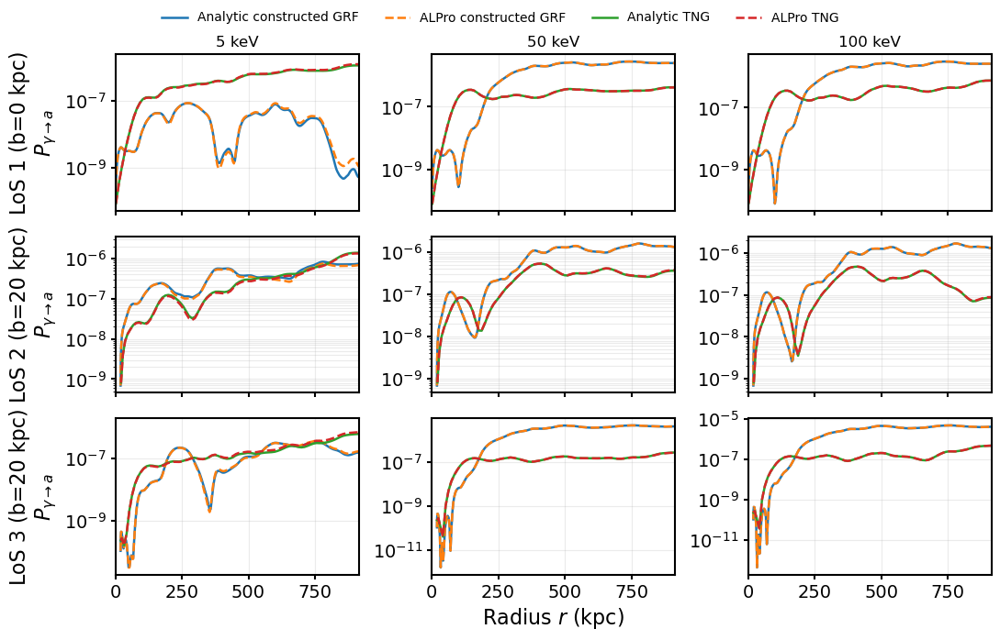

In [39]:
import sys
sys.path.append("/Users/Logan/illustris_python/")
sys.path.append("/Users/Logan/ALPro")

import h5py
import numpy as np
import matplotlib.pyplot as plt
import warnings
import os
import alpro

os.environ["ALPRO_QUIET"] = "1"
sys.stdout = open(os.devnull, "w")  # silence chatter

# ============================================================
# Units
# ============================================================
kpc_to_eVinv = 1.5637e26
G_to_eV2     = 1.95e-2
m_p_gram     = 1.6726219e-24
Msun_gram    = 1.98847e33
kpc_cm       = 3.08567758e21

def omega_pl(ne_cm3):
    return 3.69e-11 * np.sqrt(ne_cm3)

# ALPro convention
ALPRO_RETURNS_SURVIVAL = True

# ============================================================
# Extract TNG radial electron density (volume-weighted)
# ============================================================
def get_tng_radial_ne(filename, N_bins=40):
    with h5py.File(filename, "r") as f:
        gas = f["PartType0"]

        coords   = gas["Coordinates"][:] 
        rho_code = gas["Density"][:] 
        ne_frac  = gas["ElectronAbundance"][:]
        masses   = gas["Masses"][:] * 1e10

        redshift = float(f["Header"].attrs["Redshift"])
        h        = float(f["Header"].attrs["HubbleParam"])

        try:
            center = f["Subhalo"]["SubhaloPos"][:]
        except Exception:
            center = coords.mean(axis=0)

    coords = (coords - center) / (h * (1 + redshift))
    r_kpc  = np.linalg.norm(coords, axis=1)

    rho_phys  = rho_code * 1e10 * h**2 * (1 + redshift)**3 
    rho_g_cm3 = rho_phys * Msun_gram / (kpc_cm**3)

    V_kpc3 = masses / rho_phys
    V_cm3  = V_kpc3 * kpc_cm**3

    ne_cell = ne_frac * rho_g_cm3 / m_p_gram

    r_min = max(1, np.min(r_kpc[r_kpc > 0]))
    r_max = np.max(r_kpc)
    r_bins = np.logspace(np.log10(r_min), np.log10(r_max), N_bins + 1)
    r_centers = 0.5 * (r_bins[:-1] + r_bins[1:])

    ne_prof = np.full(N_bins, np.nan)
    for i in range(N_bins):
        mask = (r_kpc >= r_bins[i]) & (r_kpc < r_bins[i+1])
        if np.any(mask):
            ne_prof[i] = np.average(ne_cell[mask], weights=V_cm3[mask])

    good = np.isfinite(ne_prof)
    ne_prof = np.interp(r_centers, r_centers[good], ne_prof[good])
    return r_centers, ne_prof


# ============================================================
# NEW: Constructed GRF LOS
def build_constructed_grf_los_cylinder_avg_along_z(
    Bx_uG, By_uG, Bz_uG, edges_xyz_kpc,
    filename_for_ne_profile,
    x0_kpc=0.0,
    y0_kpc=0.0,
    R_cyl=80.0,
    N_bins=250,
    smooth_window=7,
):
    # TNG ne(r) profile
    r_prof, ne_prof = get_tng_radial_ne(filename_for_ne_profile, N_bins=40)
    x_edges, y_edges, z_edges = edges_xyz_kpc
    xc = 0.5 * (x_edges[:-1] + x_edges[1:])
    yc = 0.5 * (y_edges[:-1] + y_edges[1:])
    zc = 0.5 * (z_edges[:-1] + z_edges[1:])

    x3, y3, z3 = np.meshgrid(xc, yc, zc, indexing="ij")
    r3 = np.sqrt(x3**2 + y3**2 + z3**2)

    r_clip = np.clip(r3, r_prof.min(), r_prof.max())
    ne_grid = np.interp(r_clip, r_prof, ne_prof)
    R_perp = np.sqrt((x3 - x0_kpc)**2 + (y3 - y0_kpc)**2)
    mask = R_perp < R_cyl
    ncell = np.count_nonzero(mask)
    if ncell < 20:
        dx = (x_edges[-1] - x_edges[0]) / (len(xc))
        raise RuntimeError(
            f"Constructed-GRF cylinder too thin: {ncell} voxels. "
            f"Increase R_cyl or GRID_N. Current dx ~ {dx:.2f} kpc."
        )

    z_sel  = z3[mask].ravel()
    B_sel  = By_uG[mask].ravel() * 1e-6
    ne_sel = ne_grid[mask].ravel()

    z_min, z_max = z_sel.min(), z_sel.max()
    z_edges_1d = np.linspace(z_min, z_max, N_bins + 1)
    z_mid      = 0.5*(z_edges_1d[:-1] + z_edges_1d[1:])

    ne_bin = np.full(N_bins, np.nan)
    B_bin  = np.full(N_bins, np.nan)
    ok     = np.zeros(N_bins, bool)

    for i in range(N_bins):
        mb = (z_sel >= z_edges_1d[i]) & (z_sel < z_edges_1d[i+1])
        if np.any(mb):
            ne_bin[i] = np.mean(ne_sel[mb])
            B_bin[i]  = np.mean(B_sel[mb])
            ok[i] = True

    if not np.all(ok):
        ne_bin = np.interp(z_mid, z_mid[ok], ne_bin[ok])
        B_bin  = np.interp(z_mid, z_mid[ok],  B_bin[ok])

    if smooth_window and smooth_window > 1:
        kernel = np.ones(smooth_window)/smooth_window
        B_bin = np.convolve(B_bin, kernel, mode="same")
    mpos = z_mid >= 0
    z_pos  = z_mid[mpos]
    ne_out = ne_bin[mpos]
    B_out  = B_bin[mpos]

    dL_kpc = z_pos[1] - z_pos[0]
    b = np.sqrt(x0_kpc**2 + y0_kpc**2)
    r_los = np.sqrt(b*b + z_pos*z_pos)

    return r_los, B_out, ne_out, dL_kpc


# ============================================================
# TNG LOS
# ============================================================
def build_tng_los(filename, R_cyl=20, N_bins=500, smooth_window=7, x0=0.0, y0=0.0):
    with h5py.File(filename, "r") as f:
        gas = f["PartType0"]
        coords   = gas["Coordinates"][:]
        rho_code = gas["Density"][:]
        ne_frac  = gas["ElectronAbundance"][:]
        masses   = gas["Masses"][:] * 1e10
        B_vec    = gas["MagneticField"][:]

        redshift = float(f["Header"].attrs["Redshift"])
        h        = float(f["Header"].attrs["HubbleParam"])

        try:
            center = f["Subhalo"]["SubhaloPos"][:]
        except Exception:
            center = coords.mean(axis=0)

    coords = (coords - center) / (h * (1 + redshift))
    x, y, z = coords.T

    R_perp = np.sqrt((x - x0)**2 + (y - y0)**2)

    rho_phys  = rho_code * 1e10 * h**2 * (1 + redshift)**3
    rho_g_cm3 = rho_phys * Msun_gram / (kpc_cm**3)
    V_kpc3 = masses / rho_phys
    V_cm3  = V_kpc3 * kpc_cm**3

    ne_cell = ne_frac * rho_g_cm3 / m_p_gram
    By      = B_vec[:, 1] * 1e-6

    mask = R_perp < R_cyl
    z_los  = z[mask]
    ne_los = ne_cell[mask]
    By_los = By[mask]
    V_los  = V_cm3[mask]

    order = np.argsort(z_los)
    z_los, ne_los, By_los, V_los = [arr[order] for arr in (z_los, ne_los, By_los, V_los)]

    z_min, z_max = z_los.min(), z_los.max()
    z_edges = np.linspace(z_min, z_max, N_bins + 1)
    z_mid   = 0.5*(z_edges[:-1] + z_edges[1:])

    ne_grid = np.full(N_bins, np.nan)
    By_grid = np.full(N_bins, np.nan)
    ok      = np.zeros(N_bins, bool)

    for i in range(N_bins):
        mb = (z_los >= z_edges[i]) & (z_los < z_edges[i+1])
        if np.any(mb):
            w = V_los[mb]
            ne_grid[i] = np.average(ne_los[mb], weights=w)
            By_grid[i] = np.average(By_los[mb], weights=w)
            ok[i] = True

    if not np.all(ok):
        ne_grid = np.interp(z_mid, z_mid[ok], ne_grid[ok])
        By_grid = np.interp(z_mid, z_mid[ok], By_grid[ok])

    if smooth_window and smooth_window > 1:
        kernel = np.ones(smooth_window)/smooth_window
        By_grid = np.convolve(By_grid, kernel, mode="same")

    mpos = z_mid >= 0
    z_pos  = z_mid[mpos]
    ne_out = ne_grid[mpos]
    B_out  = By_grid[mpos]

    dL_kpc = z_pos[1] - z_pos[0]
    b = np.sqrt(x0**2 + y0**2)
    r_los = np.sqrt(b*b + z_pos*z_pos)

    return r_los, B_out, ne_out, dL_kpc


# ============================================================
# Analytic cumulative P(r)
# ============================================================
def analytic_P_vs_r(B_G, ne_cm3, dL_kpc, g_GeVinv, m_a_eV, E_eV):
    B_G    = np.asarray(B_G, dtype=float)
    ne_cm3 = np.asarray(ne_cm3, dtype=float)

    dz = dL_kpc * kpc_to_eVinv
    g_eVinv = g_GeVinv * 1e-9

    Delta_ag = 0.5 * g_eVinv * (B_G * G_to_eV2)

    wpl2 = omega_pl(ne_cm3)**2
    meff2 = m_a_eV**2 - wpl2
    Delta_eff = -meff2 / (2.0 * E_eV)

    phi_left = np.zeros_like(Delta_eff)
    phi_left[1:] = np.cumsum(Delta_eff[:-1]) * dz
    phi_center = phi_left + 0.5 * Delta_eff * dz

    dA = Delta_ag * np.exp(1j * phi_center) * dz
    A_cum = np.cumsum(dA)
    return np.abs(A_cum)**2


# ============================================================
# ALPro
# ============================================================
def alpro_P_vs_r(B_G, ne_cm3, dL_kpc, g_GeVinv, m_a_eV, E_eV):
    n = len(B_G)
    P_cum = np.zeros(n)
    E_arr = np.array([E_eV])

    for j in range(1, n + 1):
        s = alpro.Survival("custom")
        s.initialise_domain()

        segB = B_G[:j]
        s.domain.B = np.abs(segB)
        s.domain.phi = np.where(segB >= 0, 0.0, np.pi)
        s.domain.ne = ne_cm3[:j].copy()
        s.domain.deltaL = np.ones(j) * dL_kpc

        s.set_params(g=g_GeVinv*1e-9, mass=m_a_eV)
        s.energies = E_arr

        P_surv, _ = s.propagate(pol="y")
        if ALPRO_RETURNS_SURVIVAL:
            P_cum[j - 1] = P_surv[0]
        else:
            P_cum[j - 1] = P_surv[0]

    return P_cum


# ============================================================
# Main
# ============================================================
def main():
    filename = "/Users/Logan/Documents/cutout_42631.hdf5"
    global Bx, By, Bz, edges
    if "Bx" not in globals() or "By" not in globals() or "Bz" not in globals() or "edges" not in globals():
        raise RuntimeError(
            "Missing constructed GRF grid in memory.\n"
            "Expected variables: Bx, By, Bz (μG) and edges=[x_edges,y_edges,z_edges] (kpc).\n"
            "If variables are named differently, alias them before running:\n"
            "  Bx,By,Bz = Bx_syn,By_syn,Bz_syn\n"
            "  edges = edges_syn"
        )

    g   = 1e-14
    m_a = 1e-13

    energies_keV = [5, 50, 100]
    energies_eV  = [E * 1e3 for E in energies_keV]
    los_specs = [
        {"x0": 0.0,  "y0": 0.0},
        {"x0": 20.0, "y0": 0.0},
        {"x0": 0.0,  "y0": 20.0},
    ]

    #cylinder
    R_cyl = 20.0
    N_bins = 500
    smooth_window = 7

    # Build LoS
    grf_los = [
        build_constructed_grf_los_cylinder_avg_along_z(
            Bx_uG=Bx, By_uG=By, Bz_uG=Bz,
            edges_xyz_kpc=edges,
            filename_for_ne_profile=filename,
            x0_kpc=spec["x0"],
            y0_kpc=spec["y0"],
            R_cyl=R_cyl,
            N_bins=N_bins,
            smooth_window=smooth_window,
        )
        for spec in los_specs
    ]

    tng_los = [
        build_tng_los(
            filename,
            R_cyl=R_cyl,
            N_bins=N_bins,
            smooth_window=smooth_window,
            x0=spec["x0"],
            y0=spec["y0"],
        )
        for spec in los_specs
    ]

    fig, axs = plt.subplots(3, 3, figsize=(11, 7), sharex=True, sharey=False)

    for i_los in range(3):
        r_grf, B_grf, ne_grf, dL_grf = grf_los[i_los]
        r_tng, B_tng, ne_tng, dL_tng = tng_los[i_los]

        rmax_common = min(r_grf.max(), r_tng.max())

        for jE, (E_keV, E_eV) in enumerate(zip(energies_keV, energies_eV)):
            ax = axs[i_los, jE]

            P_grf_ana  = analytic_P_vs_r(B_grf, ne_grf, dL_grf, g, m_a, E_eV)
            P_grf_alpr = alpro_P_vs_r(B_grf, ne_grf, dL_grf, g, m_a, E_eV)

            P_tng_ana  = analytic_P_vs_r(B_tng, ne_tng, dL_tng, g, m_a, E_eV)
            P_tng_alpr = alpro_P_vs_r(B_tng, ne_tng, dL_tng, g, m_a, E_eV)

            ax.semilogy(r_grf, P_grf_ana,   lw=1.8, label="Analytic constructed GRF")
            ax.semilogy(r_grf, P_grf_alpr, "--", lw=1.8, label="ALPro constructed GRF")
            ax.semilogy(r_tng, P_tng_ana,   lw=1.8, label="Analytic TNG")
            ax.semilogy(r_tng, P_tng_alpr, "--", lw=1.8, label="ALPro TNG")

            if i_los == 0:
                ax.set_title(f"{E_keV} keV")
            if jE == 0:
                b = np.sqrt(los_specs[i_los]["x0"]**2 + los_specs[i_los]["y0"]**2)
                ax.set_ylabel(f"LoS {i_los+1} (b={b:.0f} kpc)\n$P_{{\\gamma\\to a}}$")

            ax.grid(True, which="both", alpha=0.25)
            ax.set_xlim(0, rmax_common)

    axs[-1, 1].set_xlabel(r"Radius $r$ (kpc)")

    handles, labels = axs[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False)

    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()


if __name__ == "__main__":
    main()

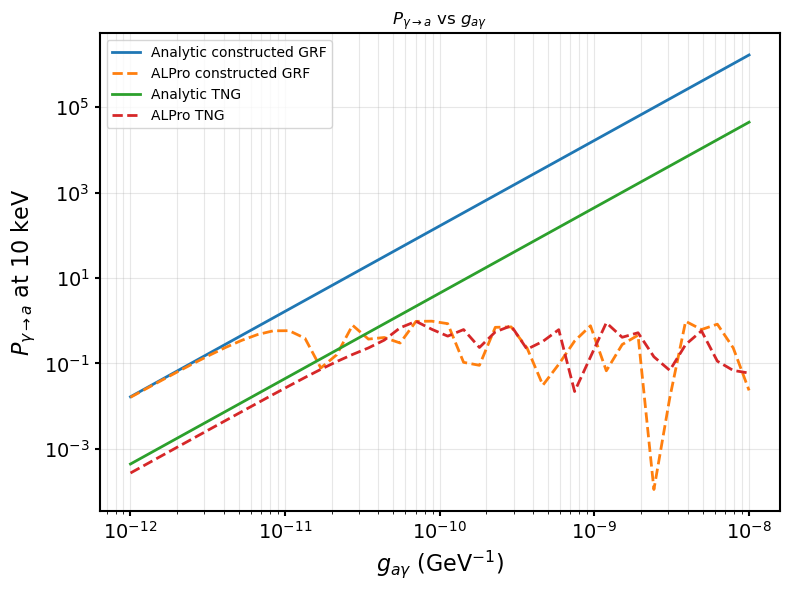

In [41]:
import sys
sys.path.append("/Users/Logan/illustris_python/")
sys.path.append("/Users/Logan/ALPro")

import h5py
import numpy as np
import matplotlib.pyplot as plt
import warnings, os
import alpro

os.environ["ALPRO_QUIET"] = "1"
sys.stdout = open(os.devnull, "w")  # silence chatter

# ============================================================
# Units
# ============================================================
kpc_to_eVinv = 1.5637e26
G_to_eV2     = 1.95e-2
m_p_gram     = 1.6726219e-24
Msun_gram    = 1.98847e33
kpc_cm       = 3.08567758e21

def omega_pl(ne_cm3):
    return 3.69e-11 * np.sqrt(ne_cm3)

ALPRO_RETURNS_SURVIVAL = True

# ============================================================
# 1) TNG radial electron density (volume-weighted)
# ============================================================
def get_tng_radial_ne_profile(filename, N_r_bins=40):
    with h5py.File(filename, "r") as f:
        gas = f["PartType0"]
        coords = gas["Coordinates"][:]          # ckpc/h
        rho_code = gas["Density"][:]            # 1e10 Msun/h / (ckpc/h)^3
        ne_frac  = gas["ElectronAbundance"][:]  # dimless
        masses   = gas["Masses"][:] * 1e10      # Msun

        redshift = float(f["Header"].attrs["Redshift"])
        h        = float(f["Header"].attrs["HubbleParam"])

        try:
            center = f["Subhalo"]["SubhaloPos"][:]   # ckpc/h
        except KeyError:
            center = coords.mean(axis=0)

    coords_kpc = (coords - center) / h / (1 + redshift)
    r_kpc = np.linalg.norm(coords_kpc, axis=1)

    rho_phys  = rho_code * 1e10 * h**2 * (1 + redshift)**3
    rho_g_cm3 = rho_phys * Msun_gram / (kpc_cm**3)
    V_kpc3    = masses / rho_phys
    V_cm3     = V_kpc3 * (kpc_cm**3)

    ne_cell = ne_frac * rho_g_cm3 / m_p_gram     # cm^-3

    r_min = np.min(r_kpc[r_kpc > 0])
    r_max = np.max(r_kpc)
    r_bins = np.logspace(np.log10(r_min), np.log10(r_max), N_r_bins + 1)
    r_centers = 0.5*(r_bins[:-1] + r_bins[1:])

    ne_profile = np.full(N_r_bins, np.nan)
    for i in range(N_r_bins):
        m = (r_kpc >= r_bins[i]) & (r_kpc < r_bins[i+1])
        if np.any(m):
            ne_profile[i] = np.average(ne_cell[m], weights=V_cm3[m])

    valid = np.isfinite(ne_profile)
    if not np.all(valid):
        ne_profile = np.interp(r_centers, r_centers[valid], ne_profile[valid])

    return r_centers, ne_profile

# ============================================================
# 2) Constructed GRF LOS
# ============================================================
def build_constructed_grf_los_cylinder_avg_from_grid(
    filename_for_ne,
    Bx_uG, By_uG, Bz_uG, edges_xyz_kpc,
    x0_kpc=0.0,
    y0_kpc=0.0,
    R_cyl=20.0,
    N_bins=300,
    smooth_window=7,
    keep_only_zpos=True,
):
    r_prof, ne_prof = get_tng_radial_ne_profile(filename_for_ne)

    x_edges, y_edges, z_edges = edges_xyz_kpc
    xc = 0.5 * (x_edges[:-1] + x_edges[1:])
    yc = 0.5 * (y_edges[:-1] + y_edges[1:])
    zc = 0.5 * (z_edges[:-1] + z_edges[1:])

    x3, y3, z3 = np.meshgrid(xc, yc, zc, indexing="ij")
    r3 = np.sqrt(x3**2 + y3**2 + z3**2)
    r_clip = np.clip(r3, r_prof.min(), r_prof.max())
    ne_grid = np.interp(r_clip, r_prof, ne_prof)
    rperp = np.sqrt((x3 - x0_kpc)**2 + (y3 - y0_kpc)**2)
    mask = rperp < R_cyl
    ncell = np.count_nonzero(mask)
    if ncell < 20:
        dx = (x_edges[-1] - x_edges[0]) / len(xc)
        raise RuntimeError(
            f"Constructed-GRF cylinder too thin: {ncell} voxels. "
            f"Increase R_cyl or GRID_N. Current dx ~ {dx:.2f} kpc."
        )

    z_sel  = z3[mask].ravel()
    B_sel  = (By_uG[mask].ravel()) * 1e-6 
    ne_sel = (ne_grid[mask].ravel())    

    # bin in z
    zmin, zmax = z_sel.min(), z_sel.max()
    z_edges_1d = np.linspace(zmin, zmax, N_bins + 1)
    zmid = 0.5 * (z_edges_1d[:-1] + z_edges_1d[1:])

    B_grid  = np.full(N_bins, np.nan)
    ne_out  = np.full(N_bins, np.nan)
    ok      = np.zeros(N_bins, dtype=bool)

    for i in range(N_bins):
        m = (z_sel >= z_edges_1d[i]) & (z_sel < z_edges_1d[i+1])
        if np.any(m):
            B_grid[i] = np.mean(B_sel[m])     # equal-volume weights
            ne_out[i] = np.mean(ne_sel[m])
            ok[i] = True

    if not np.all(ok):
        B_grid = np.interp(zmid, zmid[ok], B_grid[ok])
        ne_out = np.interp(zmid, zmid[ok], ne_out[ok])

    if smooth_window and smooth_window > 1:
        kernel = np.ones(smooth_window)/smooth_window
        B_grid = np.convolve(B_grid, kernel, mode="same")

    if keep_only_zpos:
        mp = zmid >= 0
        zmid = zmid[mp]
        B_grid = B_grid[mp]
        ne_out = ne_out[mp]

    dL_kpc = zmid[1] - zmid[0]
    return zmid, B_grid, ne_out, dL_kpc

# ============================================================
# 3) TNG LOS (volume-weighted cylinder)
# ============================================================
def build_tng_los(filename, R_cyl=20.0, N_bins=300, smooth_window=7):
    with h5py.File(filename,"r") as f:
        gas = f["PartType0"]
        coords = gas["Coordinates"][:]
        rho_code = gas["Density"][:]
        ne_frac  = gas["ElectronAbundance"][:]
        Bvec_uG  = gas["MagneticField"][:]
        masses   = gas["Masses"][:] * 1e10

        redshift = float(f["Header"].attrs["Redshift"])
        h        = float(f["Header"].attrs["HubbleParam"])

        try:
            center = f["Subhalo"]["SubhaloPos"][:]
        except Exception:
            center = coords.mean(axis=0)

    coords_kpc = (coords - center) / (h * (1 + redshift))
    x, y, z = coords_kpc.T
    rperp = np.sqrt(x**2 + y**2)

    rho_phys  = rho_code * 1e10 * h**2 * (1 + redshift)**3
    rho_g_cm3 = rho_phys * Msun_gram / (kpc_cm**3)
    V_kpc3 = masses / rho_phys
    V_cm3 = V_kpc3 * (kpc_cm**3)
    ne_cell = ne_frac * rho_g_cm3 / m_p_gram

    mask = rperp < R_cyl
    z_los  = z[mask]
    ne_los = ne_cell[mask]
    By_los = Bvec_uG[mask][:, 1] * 1e-6
    V_los  = V_cm3[mask]

    order = np.argsort(z_los)
    z_los, ne_los, By_los, V_los = (z_los[order], ne_los[order], By_los[order], V_los[order])

    zmin, zmax = z_los.min(), z_los.max()
    z_edges = np.linspace(zmin, zmax, N_bins + 1)
    zmid = 0.5 * (z_edges[:-1] + z_edges[1:])

    ne_grid = np.full(N_bins, np.nan)
    By_grid = np.full(N_bins, np.nan)
    ok = np.zeros(N_bins, dtype=bool)

    for i in range(N_bins):
        m = (z_los >= z_edges[i]) & (z_los < z_edges[i+1])
        if np.any(m):
            w = V_los[m]
            ne_grid[i] = np.average(ne_los[m], weights=w)
            By_grid[i] = np.average(By_los[m], weights=w)
            ok[i] = True

    if not np.all(ok):
        ne_grid = np.interp(zmid, zmid[ok], ne_grid[ok])
        By_grid = np.interp(zmid, zmid[ok], By_grid[ok])

    if smooth_window and smooth_window > 1:
        kernel = np.ones(smooth_window)/smooth_window
        By_grid = np.convolve(By_grid, kernel, mode="same")

    mp = zmid >= 0
    zpos = zmid[mp]
    nepos = ne_grid[mp]
    B_G = By_grid[mp]

    dL = zpos[1] - zpos[0]
    return zpos, B_G, nepos, dL

# ============================================================
# 4) Analytic P(g) + ALPro P(g)
# ============================================================
def analytic_P_vs_g(garr, B_G, ne_cm3, dL_kpc, m_a, E_eV):
    B_G    = np.asarray(B_G, dtype=float)
    ne_cm3 = np.asarray(ne_cm3, dtype=float)

    dz = dL_kpc * kpc_to_eVinv

    B_eV2 = B_G * G_to_eV2
    Delta_unit = 0.5 * B_eV2

    wpl2 = omega_pl(ne_cm3)**2
    Delta_eff = -(m_a**2 - wpl2) / (2.0 * E_eV)

    phi_left = np.zeros_like(Delta_eff)
    phi_left[1:] = np.cumsum(Delta_eff[:-1]) * dz
    phi_center = phi_left + 0.5 * Delta_eff * dz

    A1 = np.sum(Delta_unit * np.exp(1j * phi_center) * dz)
    C = np.abs(A1)**2

    g_eVinv = garr * 1e-9
    return C * (g_eVinv**2)

def alpro_P_vs_g(garr, B_G, ne_cm3, dL_kpc, m_a, E_eV):
    n = len(B_G)
    Earr = np.array([E_eV])
    out = np.zeros_like(garr)

    for i, g in enumerate(garr):
        s = alpro.Survival("custom")
        s.initialise_domain()

        s.domain.ne = ne_cm3.copy()
        s.domain.deltaL = np.ones(n) * dL_kpc
        s.domain.B = np.abs(B_G)
        s.domain.phi = np.where(B_G >= 0, 0.0, np.pi)

        s.set_params(g=g*1e-9, mass=m_a)
        s.energies = Earr

        P_surv, _ = s.propagate(pol="y")
        if ALPRO_RETURNS_SURVIVAL:
            out[i] = P_surv[0]
        else:
            out[i] = P_surv[0]
    return out

# ============================================================
# 5) Main
# ============================================================
def main():
    filename = "/Users/Logan/Documents/cutout_42631.hdf5"
    global Bx, By, Bz, edges
    if "Bx" not in globals() or "By" not in globals() or "Bz" not in globals() or "edges" not in globals():
        raise RuntimeError(
            "Missing constructed GRF grid in memory.\n"
            "Expected variables: Bx, By, Bz (μG) and edges=[x_edges,y_edges,z_edges] (kpc).\n"
            "If your variables are named differently, alias them before running:\n"
            "  Bx,By,Bz = Bx_syn,By_syn,Bz_syn\n"
            "  edges = edges_syn"
        )

    #parameters
    E_eV = 1e4   # 10 keV
    m_a  = 1e-12
    garr = np.logspace(-12, -8, 40)

    #LoS
    R_cyl = 20.0
    N_bins = 300
    smooth_window = 7

    # ---------------- Constructed GRF -----------------
    z_grf, B_grf, ne_grf, dL_grf = build_constructed_grf_los_cylinder_avg_from_grid(
        filename_for_ne=filename,
        Bx_uG=Bx, By_uG=By, Bz_uG=Bz,
        edges_xyz_kpc=edges,
        x0_kpc=0.0, y0_kpc=0.0,
        R_cyl=R_cyl,
        N_bins=N_bins,
        smooth_window=smooth_window,
        keep_only_zpos=True,
    )

    P_grf_ana  = analytic_P_vs_g(garr, B_grf, ne_grf, dL_grf, m_a, E_eV)
    P_grf_alpr = alpro_P_vs_g(garr, B_grf, ne_grf, dL_grf, m_a, E_eV)

    # ----------------- TNG MHD LOS ---------------------------
    z_tng, B_tng, ne_tng, dL_tng = build_tng_los(
        filename, R_cyl=R_cyl, N_bins=N_bins, smooth_window=smooth_window
    )

    P_tng_ana  = analytic_P_vs_g(garr, B_tng, ne_tng, dL_tng, m_a, E_eV)
    P_tng_alpr = alpro_P_vs_g(garr, B_tng, ne_tng, dL_tng, m_a, E_eV)
    plt.figure(figsize=(8, 6))
    plt.loglog(garr, P_grf_ana,   label="Analytic constructed GRF", lw=2)
    plt.loglog(garr, P_grf_alpr, "--", label="ALPro constructed GRF", lw=2)

    plt.loglog(garr, P_tng_ana,   label="Analytic TNG", lw=2)
    plt.loglog(garr, P_tng_alpr, "--", label="ALPro TNG", lw=2)

    plt.xlabel(r"$g_{a\gamma}$ (GeV$^{-1}$)")
    plt.ylabel(rf"$P_{{\gamma\to a}}$ at {E_eV/1e3:.0f} keV")
    plt.title(r"$P_{\gamma\to a}$ vs $g_{a\gamma}$")
    plt.grid(True, which="both", alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    main()

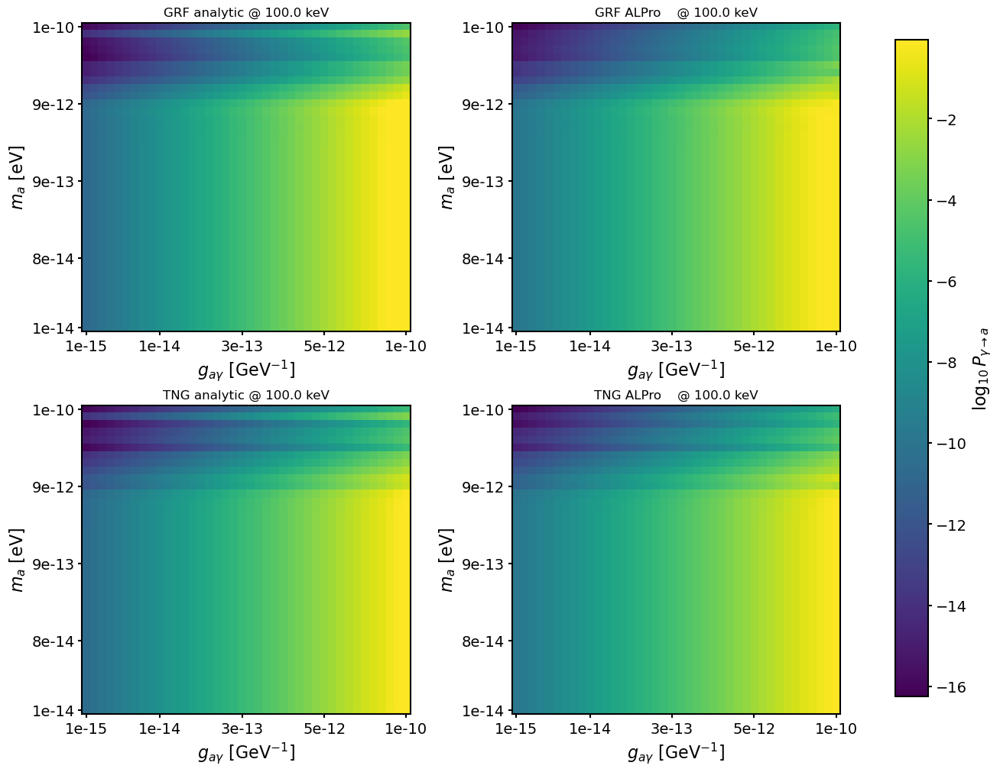

In [43]:
import numpy as np
import matplotlib.pyplot as plt
import h5py
import alpro
os.environ["ALPRO_QUIET"] = "1"
sys.stdout = open(os.devnull, "w")  # silence chatter
tng_filename = "/Users/Logan/Documents/cutout_42631.hdf5"

E_keV = 100.0
E_eV  = E_keV * 1e3

N_ma = 40
N_g  = 40
ma_grid_eV = np.logspace(-14, -10, N_ma)   # eV
g_grid_GeV = np.logspace(-15, -10, N_g)    # GeV^-1

#LoS geometry
x0_kpc = 0.0
y0_kpc = 0.0
R_cyl  = 80.0
R_max  = 150.0
N_bins = 250
smooth_window = 7

ALPRO_RETURNS_SURVIVAL = True

# ============================================================
# Units / constants
# ============================================================
kpc_to_eVinv = 1.5637e26
G_to_eV2     = 1.95e-2
m_p_gram     = 1.6726219e-24
Msun_gram    = 1.98847e33
kpc_cm       = 3.08567758e21

def omega_pl(ne_cm3):
    return 3.69e-11 * np.sqrt(ne_cm3)
need = ["Bx", "By", "Bz", "edges"]
missing = [k for k in need if k not in globals()]
if missing:
    raise RuntimeError(
        f"Missing {missing} in memory.\n"
        "Expected: Bx, By, Bz (μG) and edges=[x_edges,y_edges,z_edges] (kpc) from the IAAFT cell."
    )

Bx = np.asarray(Bx, float)
By = np.asarray(By, float)
Bz = np.asarray(Bz, float)
x_edges, y_edges, z_edges = edges

xc = 0.5*(x_edges[:-1] + x_edges[1:])
yc = 0.5*(y_edges[:-1] + y_edges[1:])
zc = 0.5*(z_edges[:-1] + z_edges[1:])

x3, y3, z3 = np.meshgrid(xc, yc, zc, indexing="ij")

# ============================================================
# Load TNG and By to the same grid
#       , build ne(z) by cylinder-avg in z bins (volume-weighted)
# ============================================================
def load_tng_arrays_for_ne_and_B(filename, XH_default=0.76):
    with h5py.File(filename, "r") as f:
        gas = f["PartType0"]
        coords_ckpc_h = gas["Coordinates"][:]
        rho_code      = gas["Density"][:]
        ne_frac       = gas["ElectronAbundance"][:]
        masses_code   = gas["Masses"][:]
        B_vec_uG      = gas["MagneticField"][:]

        if "GFM_Metals" in gas:
            XH = gas["GFM_Metals"][:, 0]
        else:
            XH = np.full_like(ne_frac, float(XH_default))

        z = float(f["Header"].attrs["Redshift"])
        h = float(f["Header"].attrs["HubbleParam"])
        try:
            center_ckpc_h = f["Subhalo"]["SubhaloPos"][:]
        except Exception:
            center_ckpc_h = coords_ckpc_h.mean(axis=0)

    coords_kpc = (coords_ckpc_h - center_ckpc_h) / h / (1.0 + z)
    x, y, zz = coords_kpc.T
    rho_phys = rho_code * 1e10 * h**2 * (1.0 + z)**3
    rho_g_cm3 = rho_phys * Msun_gram / (kpc_cm**3)
    masses_Msun = masses_code * 1e10
    V_kpc3 = masses_Msun / rho_phys
    V_cm3  = V_kpc3 * (kpc_cm**3)
    ne_cm3 = ne_frac * XH * rho_g_cm3 / m_p_gram

    By_uG = B_vec_uG[:, 1]
    return x, y, zz, ne_cm3, By_uG, V_cm3

def deposit_scalar_to_grid(coords_kpc, values, edges):
    counts, _ = np.histogramdd(coords_kpc, bins=edges)
    sums, _   = np.histogramdd(coords_kpc, bins=edges, weights=values)
    counts = counts.astype(float)
    counts[counts == 0] = np.nan
    grid = np.nan_to_num(sums / counts, nan=0.0)
    return grid, np.nan_to_num(counts, nan=0.0)

xt, yt, zt, ne_tng_cell, By_tng_cell_uG, V_tng = load_tng_arrays_for_ne_and_B(tng_filename)
coords_tng = np.vstack([xt, yt, zt]).T

By_tng_grid_uG, _ = deposit_scalar_to_grid(coords_tng, By_tng_cell_uG, edges)

# ============================================================
# Build matched cylinder-avg LoS B(z)
# ============================================================
def build_los_B_from_grid(By_uG, x3, y3, z3, x0, y0, R_cyl, R_max, N_bins, smooth_window):
    R_perp = np.sqrt((x3 - x0)**2 + (y3 - y0)**2)
    m = (R_perp < R_cyl) & (np.abs(z3) <= R_max)
    if np.count_nonzero(m) < 50:
        raise RuntimeError("Grid cylinder mask too empty. Increase R_cyl or GRID_N.")

    z_sel = z3[m].ravel()
    B_sel = (By_uG[m].ravel()) * 1e-6

    z_edges = np.linspace(-R_max, R_max, N_bins + 1)
    z_mid   = 0.5*(z_edges[:-1] + z_edges[1:])

    B_bin = np.full(N_bins, np.nan)
    ok    = np.zeros(N_bins, bool)

    for i in range(N_bins):
        mb = (z_sel >= z_edges[i]) & (z_sel < z_edges[i+1])
        if np.any(mb):
            B_bin[i] = np.mean(B_sel[mb])
            ok[i] = True

    if np.count_nonzero(ok) < 10:
        raise RuntimeError("Too few populated z bins. Increase R_cyl or reduce N_bins.")

    if not np.all(ok):
        B_bin = np.interp(z_mid, z_mid[ok], B_bin[ok])

    if smooth_window and smooth_window > 1:
        ker = np.ones(smooth_window)/smooth_window
        B_bin = np.convolve(B_bin, ker, mode="same")

    mp = z_mid >= 0
    z_pos = z_mid[mp]
    B_pos = B_bin[mp]
    dL_kpc = z_pos[1] - z_pos[0]
    return z_pos, B_pos, dL_kpc

# ============================================================
# Build cylinder-avg LoS ne(z) from TNG CELLS
# (volume-weighted)
# ============================================================
def build_los_ne_from_tng_cells(xt, yt, zt, ne_cell, V_cm3, x0, y0, R_cyl, R_max, N_bins):
    R_perp = np.sqrt((xt - x0)**2 + (yt - y0)**2)
    m = (R_perp < R_cyl) & (np.abs(zt) <= R_max)
    if np.count_nonzero(m) < 100:
        raise RuntimeError("TNG cylinder too empty. Increase R_cyl or reduce R_max.")

    z_sel  = zt[m]
    ne_sel = ne_cell[m]
    w_sel  = V_cm3[m]

    z_edges = np.linspace(-R_max, R_max, N_bins + 1)
    z_mid   = 0.5*(z_edges[:-1] + z_edges[1:])

    ne_bin = np.full(N_bins, np.nan)
    ok     = np.zeros(N_bins, bool)

    for i in range(N_bins):
        mb = (z_sel >= z_edges[i]) & (z_sel < z_edges[i+1])
        if np.any(mb):
            ne_bin[i] = np.average(ne_sel[mb], weights=w_sel[mb])
            ok[i] = True

    if np.count_nonzero(ok) < 10:
        raise RuntimeError("Too few populated ne(z) bins. Increase R_cyl or reduce N_bins.")

    if not np.all(ok):
        ne_bin = np.interp(z_mid, z_mid[ok], ne_bin[ok])

    mp = z_mid >= 0
    z_pos  = z_mid[mp]
    ne_pos = ne_bin[mp]
    return z_pos, ne_pos

# Build LoS arrays
z_grf, B_grf_G, dL_kpc = build_los_B_from_grid(By, x3, y3, z3, x0_kpc, y0_kpc, R_cyl, R_max, N_bins, smooth_window)
z_tng, B_tng_G, _      = build_los_B_from_grid(By_tng_grid_uG, x3, y3, z3, x0_kpc, y0_kpc, R_cyl, R_max, N_bins, smooth_window)

z_ne, ne_los_cm3 = build_los_ne_from_tng_cells(xt, yt, zt, ne_tng_cell, V_tng, x0_kpc, y0_kpc, R_cyl, R_max, N_bins)

#ensure same length
n = min(len(B_grf_G), len(B_tng_G), len(ne_los_cm3))
B_grf_G = B_grf_G[:n]
B_tng_G = B_tng_G[:n]
ne_los_cm3 = ne_los_cm3[:n]

# ============================================================
# Probabilities
# ============================================================
def analytic_P_final(B_G, ne_cm3, dL_kpc, g_GeVinv, m_a_eV, E_eV):
    dz = dL_kpc * kpc_to_eVinv
    g_eVinv = g_GeVinv * 1e-9

    B_G    = np.asarray(B_G, float)
    ne_cm3 = np.asarray(ne_cm3, float)

    Delta_ag = 0.5 * g_eVinv * (B_G * G_to_eV2)
    wpl2 = omega_pl(ne_cm3)**2
    Delta_eff = -(m_a_eV**2 - wpl2) / (2.0 * E_eV)

    phi_left = np.zeros_like(Delta_eff)
    phi_left[1:] = np.cumsum(Delta_eff[:-1]) * dz
    phi_center = phi_left + 0.5 * Delta_eff * dz

    A = np.sum(Delta_ag * np.exp(1j * phi_center) * dz)
    return np.abs(A)**2

def alpro_P_final(B_G, ne_cm3, dL_kpc, g_GeVinv, m_a_eV, E_eV):
    B_G    = np.asarray(B_G, float)
    ne_cm3 = np.asarray(ne_cm3, float)

    s = alpro.Survival("custom")
    s.initialise_domain()

    s.domain.ne     = ne_cm3.copy()
    s.domain.deltaL = np.ones(len(B_G)) * dL_kpc

    s.domain.B   = np.abs(B_G)
    s.domain.phi = np.where(B_G >= 0.0, 0.0, np.pi)

    s.set_params(g=g_GeVinv * 1e-9, mass=m_a_eV)
    s.energies = np.array([E_eV], dtype=float)

    P_out, _ = s.propagate(pol="y")
    P_surv = float(P_out[0])
    return (P_surv) if ALPRO_RETURNS_SURVIVAL else P_surv

def compute_maps(B_G):
    P_ana = np.zeros((len(ma_grid_eV), len(g_grid_GeV)))
    P_alp = np.zeros_like(P_ana)

    for i, m_a in enumerate(ma_grid_eV):
        for j, g in enumerate(g_grid_GeV):
            P_ana[i, j] = analytic_P_final(B_G, ne_los_cm3, dL_kpc, g, m_a, E_eV)
            P_alp[i, j] = alpro_P_final  (B_G, ne_los_cm3, dL_kpc, g, m_a, E_eV)
    return P_ana, P_alp

print(f"Computing heatmaps at E={E_keV:.1f} keV (4 maps of {N_ma}x{N_g}) ...")
P_grf_ana, P_grf_alp = compute_maps(B_grf_G)
P_tng_ana, P_tng_alp = compute_maps(B_tng_G)

# ============================================================
# Plot
# ============================================================
def plot_heat(ax, P, title):
    Pp = np.clip(P, 1e-60, 1.0)
    im = ax.imshow(np.log10(Pp), origin="lower", aspect="auto", interpolation="nearest")
    ax.set_title(title)
    return im

def set_log_ticks(ax, x_arr, y_arr, n=5):
    ix = np.linspace(0, len(x_arr)-1, n).astype(int)
    iy = np.linspace(0, len(y_arr)-1, n).astype(int)
    ax.set_xticks(ix); ax.set_xticklabels([f"{x_arr[i]:.0e}" for i in ix])
    ax.set_yticks(iy); ax.set_yticklabels([f"{y_arr[i]:.0e}" for i in iy])
    ax.set_xlabel(r"$g_{a\gamma}$ [GeV$^{-1}$]")
    ax.set_ylabel(r"$m_a$ [eV]")

fig, axs = plt.subplots(2, 2, figsize=(13, 10), constrained_layout=True)

im00 = plot_heat(axs[0,0], P_grf_ana, f"GRF analytic @ {E_keV:.1f} keV")
im01 = plot_heat(axs[0,1], P_grf_alp, f"GRF ALPro    @ {E_keV:.1f} keV")
im10 = plot_heat(axs[1,0], P_tng_ana, f"TNG analytic @ {E_keV:.1f} keV")
im11 = plot_heat(axs[1,1], P_tng_alp, f"TNG ALPro    @ {E_keV:.1f} keV")

for ax in axs.ravel():
    set_log_ticks(ax, g_grid_GeV, ma_grid_eV, n=5)

cbar = fig.colorbar(im11, ax=axs.ravel().tolist(), shrink=0.95)
cbar.set_label(r"$\log_{10} P_{\gamma\to a}$")
plt.show()

print("LoS sanity:")
print("  n =", n, " dL_kpc =", dL_kpc)
print("  Brms GRF (G) =", float(np.sqrt(np.mean(B_grf_G**2))))
print("  Brms TNG (G) =", float(np.sqrt(np.mean(B_tng_G**2))))
print("  ne range (cm^-3) =", (float(np.min(ne_los_cm3)), float(np.max(ne_los_cm3))))

<h1 style="font-size:72px; text-align:center;">MAIN RESULT - FIGURE 1</h1>


[1/3] Starting cutout_0.hdf5
[prep] loading cutout_0.hdf5
[prep] done cutout_0.hdf5 | Ncells=31413948 | L_available=400.00 kpc | box=(-2781.8,5837.9) x (-2852.6,9207.5) x (-8202.6,1797.8) kpc | 62.7s
    E=  10 keV done | <X>_GRF ana=0.8065 | <X>_GRF ALPro=0.8094 | <X>_TNG ana=0.8065 | <X>_TNG ALPro=0.8094 | S_TNG_ALPro=5.61 | K_TNG_ALPro=44.5 | Np1d=3000 | Lp1d=400.0 kpc | factor=15.79 | 4.7s
    E=  25 keV done | <X>_GRF ana=1.099 | <X>_GRF ALPro=1.103 | <X>_TNG ana=1.099 | <X>_TNG ALPro=1.103 | S_TNG_ALPro=5.39 | K_TNG_ALPro=46.7 | Np1d=3000 | Lp1d=400.0 kpc | factor=17.36 | 4.5s
    E=  50 keV done | <X>_GRF ana=1.018 | <X>_GRF ALPro=1.022 | <X>_TNG ana=1.018 | <X>_TNG ALPro=1.022 | S_TNG_ALPro=6.65 | K_TNG_ALPro=58.6 | Np1d=3000 | Lp1d=400.0 kpc | factor=14.82 | 4.5s
    E= 100 keV done | <X>_GRF ana=1.161 | <X>_GRF ALPro=1.165 | <X>_TNG ana=1.161 | <X>_TNG ALPro=1.165 | S_TNG_ALPro=5.8 | K_TNG_ALPro=49.6 | Np1d=3000 | Lp1d=400.0 kpc | factor=17.13 | 4.6s
[1/3] Finished cutout_0.

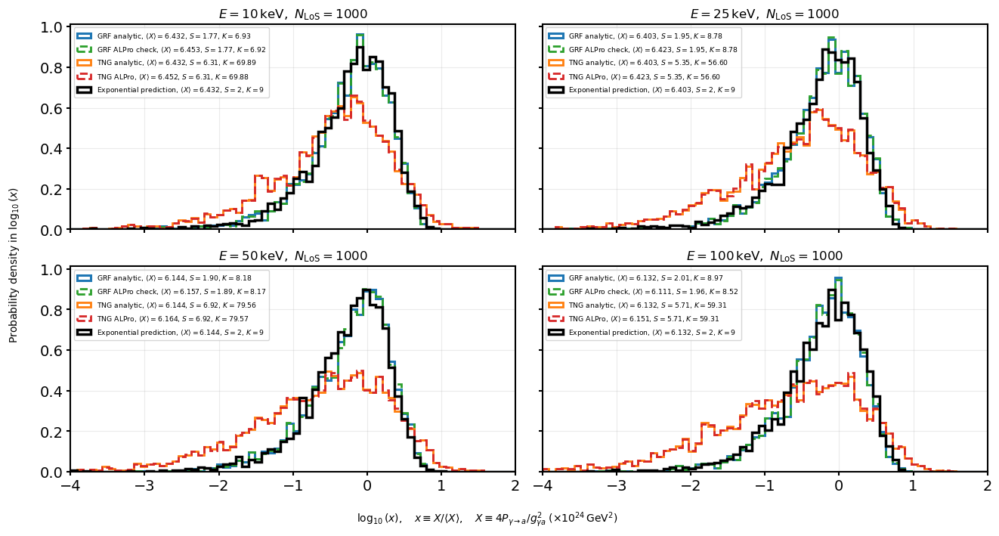


All done in 145.1s | successful clusters with at least one energy: 3/3


In [10]:
import sys
sys.path.append("/Users/Logan/illustris_python/")
sys.path.append("/Users/Logan/ALPro")

import os
os.environ["ALPRO_QUIET"] = "1"

import gc
import time
import warnings
import numpy as np
import h5py
import matplotlib.pyplot as plt
import alpro

from scipy.spatial import cKDTree

warnings.filterwarnings("ignore", message="Custom model specified")


# ============================================================
# SWITCHES
# ============================================================
OMEGA_PL_ZERO      = False
LOS_SUBTRACT_MEAN  = False
P_MAX_WEAK         = 0.1
VERBOSE            = True

# Match TNG analytic mean to GRF analytic mean before normalization.
MATCH_TNG_MEAN_TO_GRF = True

# Paper-consistent massive-regime phase:
# eta_a = m_a^2 / (2E)
USE_PAPER_MASSIVE_LIMIT = True

# In paper massive limit, force ALPro ne=0 so analytic and ALPro test the same setup.
FORCE_ALPRO_NE_ZERO_IN_PAPER_LIMIT = True


# ============================================================
# CONSTANTS
# ============================================================
kpc_to_eVinv = np.float64(1.5637e26)
G_to_eV2     = np.float64(1.95e-2)
m_p_gram     = np.float64(1.6726219e-24)
Msun_gram    = np.float64(1.98847e33)
kpc_cm       = np.float64(3.08567758e21)


def omega_pl(ne_cm3):
    ne_cm3 = np.asarray(ne_cm3, dtype=np.float64)
    if OMEGA_PL_ZERO:
        return np.zeros_like(ne_cm3, dtype=np.float64)
    return np.float64(3.69e-11) * np.sqrt(ne_cm3)


def vprint(msg):
    if VERBOSE:
        print(msg, flush=True)


# ============================================================
# USER CONTROLS
# ============================================================
FILELIST = [
    f"/Users/Logan/Documents/cutout_{i}.hdf5"
    for i in range(3)
]

# For one cutout:
# FILELIST = ["/Users/Logan/Documents/cutout_75.hdf5"]

TNG_P_SCALE = np.float64(0.0567)
R0_KPC      = 24.0

ENERGIES_KEV = [10, 25, 50, 100]

R_max      = np.float64(200.0)
b_max      = np.float64(200.0)
N_bins_los = 200

# Direct TNG particle interpolation controls
TNG_KNN_IDW        = 8
TNG_IDW_POWER      = np.float64(2.0)
TNG_MIN_VALID_FRAC = np.float64(0.85)

# Monte-Carlo targets: PER FILE
N_grf_per_file = 1000
N_tng_per_file = 1000
base_seed      = 12345
MAX_ATTEMPTS_MULT = 400

# P1D-control estimator from direct TNG LoS
N_P1D_LOS_TARGET      = 3000
N_P1D_LOS_MIN         = 300
P1D_MIN_VALID_FRAC    = np.float64(0.85)
P1D_MAX_ATTEMPTS_MULT = 500

# Histogram / plot controls
N_HIST_BINS = 70
X_FLOOR     = np.float64(1e-20)
BLACK_SEED  = 20260423

XLOG_MIN = -4.0
XLOG_MAX =  2.0

# ALP parameters
g   = np.float64(1e-14)   # GeV^-1
m_a = np.float64(1e-12)   # eV


# ============================================================
# BASIC ALP PHASE
# ============================================================
def eta_a_eV(m_a_eV, E_eV):
    return np.float64(m_a_eV) ** 2 / (np.float64(2.0) * np.float64(E_eV))


def eta_a_kpcinv(m_a_eV, E_eV):
    return eta_a_eV(m_a_eV, E_eV) * kpc_to_eVinv


# ============================================================
# CENTERING
# ============================================================
def get_center(f, coords, rho_code=None, masses=None):
    try:
        if "Group" in f and "GroupPos" in f["Group"]:
            c = np.asarray(f["Group"]["GroupPos"][:], dtype=np.float64).squeeze()
            if c.size == 3 and np.all(np.isfinite(c)):
                return c
    except Exception:
        pass

    try:
        if "Subhalo" in f and "SubhaloPos" in f["Subhalo"]:
            c = np.asarray(f["Subhalo"]["SubhaloPos"][:], dtype=np.float64).squeeze()
            if c.size == 3 and np.all(np.isfinite(c)):
                return c
    except Exception:
        pass

    if rho_code is not None:
        rho_code = np.asarray(rho_code, dtype=np.float64)
        m = np.isfinite(rho_code)
        if np.any(m):
            i = np.nanargmax(rho_code)
            c = np.asarray(coords[i], dtype=np.float64).squeeze()
            if c.size == 3 and np.all(np.isfinite(c)):
                return c

    if masses is not None:
        masses = np.asarray(masses, dtype=np.float64)
        m = np.isfinite(masses) & (masses > 0)
        if np.any(m):
            return np.average(
                np.asarray(coords[m], dtype=np.float64),
                axis=0,
                weights=masses[m]
            ).astype(np.float64)

    return np.median(np.asarray(coords, dtype=np.float64), axis=0).astype(np.float64)


# ============================================================
# TNG IO + UNITS
# ============================================================
def get_header_units_cgs(f):
    a = f["Header"].attrs
    keys = ("UnitLength_in_cm", "UnitMass_in_g", "UnitVelocity_in_cm_per_s")
    if all(k in a for k in keys):
        return np.float64(a[keys[0]]), np.float64(a[keys[1]]), np.float64(a[keys[2]])
    return None


def B_code_to_G_factor(f, assume_B_is_comoving=True, include_sqrt4pi=False):
    units = get_header_units_cgs(f)
    if units is None:
        raise RuntimeError("Missing Header unit attrs for B conversion.")

    l_unit, m_unit, v_unit = units
    B_unit = v_unit * np.sqrt(m_unit) / (l_unit ** np.float64(1.5))

    if include_sqrt4pi:
        B_unit *= np.sqrt(np.float64(4.0) * np.pi)

    z = np.float64(f["Header"].attrs["Redshift"])
    a = np.float64(1.0) / (np.float64(1.0) + z)

    if assume_B_is_comoving:
        B_unit *= (np.float64(1.0) / (a * a))

    return np.float64(B_unit)


def load_tng_particles(filename, XH_default=0.76,
                       assume_B_is_comoving=True,
                       include_sqrt4pi=False):
    with h5py.File(filename, "r") as f:
        gas = f["PartType0"]

        coords   = np.asarray(gas["Coordinates"][:], dtype=np.float64)
        rho_code = np.asarray(gas["Density"][:], dtype=np.float64)
        ne_frac  = np.asarray(gas["ElectronAbundance"][:], dtype=np.float64)
        masses   = np.asarray(gas["Masses"][:], dtype=np.float64)
        B_vec    = np.asarray(gas["MagneticField"][:], dtype=np.float64)

        if "GFM_Metals" in gas:
            XH = np.asarray(gas["GFM_Metals"][:, 0], dtype=np.float64)
        else:
            XH = np.full_like(ne_frac, np.float64(XH_default))

        z = np.float64(f["Header"].attrs["Redshift"])
        h = np.float64(f["Header"].attrs["HubbleParam"])

        center = get_center(f, coords, rho_code=rho_code, masses=masses)

        B_unit_G = B_code_to_G_factor(
            f,
            assume_B_is_comoving=assume_B_is_comoving,
            include_sqrt4pi=include_sqrt4pi
        )

    coords_kpc = (coords - center) / (h * (np.float64(1.0) + z))
    x, y, zz = coords_kpc.T
    r_kpc = np.sqrt(x * x + y * y + zz * zz)

    rho_phys = rho_code * np.float64(1e10) * (h * h) * ((np.float64(1.0) + z) ** 3)
    rho_phys = np.clip(rho_phys, np.float64(0.0), np.float64(1e300))
    rho_g_cm3 = rho_phys * Msun_gram / (kpc_cm ** 3)

    masses_Msun = masses * np.float64(1e10) / h
    rho_phys_safe = np.maximum(rho_phys, np.float64(1e-300))
    V_kpc3 = masses_Msun / rho_phys_safe
    V_kpc3 = np.clip(V_kpc3, np.float64(0.0), np.float64(1e300))
    V_cm3  = V_kpc3 * (kpc_cm ** 3)

    ne_cm3 = ne_frac * XH * rho_g_cm3 / m_p_gram
    By_G   = (B_vec[:, 1] * B_unit_G).astype(np.float64)

    return (
        coords_kpc.astype(np.float64),
        r_kpc.astype(np.float64),
        ne_cm3.astype(np.float64),
        By_G.astype(np.float64),
        V_cm3.astype(np.float64),
    )


# ============================================================
# FLATTENING
# ============================================================
def radial_envelope_rms_By(r_kpc, By_G, weights_cm3, Rmax_kpc, Nr_bins=40):
    r_kpc = np.asarray(r_kpc, np.float64)
    By_G  = np.asarray(By_G, np.float64)
    w     = np.asarray(weights_cm3, np.float64)

    Rmax_kpc = np.float64(Rmax_kpc)
    rmin = np.float64(1.0)
    r_bins = np.logspace(np.log10(rmin), np.log10(Rmax_kpc), int(Nr_bins) + 1)
    r_cent = np.float64(0.5) * (r_bins[:-1] + r_bins[1:])
    dig = np.digitize(r_kpc, r_bins)

    env = np.full(int(Nr_bins), np.nan, dtype=np.float64)
    ok  = np.zeros(int(Nr_bins), dtype=bool)

    for i in range(int(Nr_bins)):
        m = (dig == (i + 1))
        if np.any(m):
            ww = w[m]
            env[i] = np.sqrt(np.average(By_G[m] ** 2, weights=ww))
            ok[i] = np.isfinite(env[i]) and (env[i] > 0)

    m = ok & np.isfinite(env) & (env > 0)
    if np.count_nonzero(m) < 5:
        raise RuntimeError("Too few valid bins in rms(By) envelope.")

    return r_cent[m], env[m]


def flatten_By_by_envelope(r_kpc, By_G, r_env, env_rms_By, r0_kpc):
    ref = np.interp(np.float64(r0_kpc), r_env, env_rms_By)
    env_cell = np.interp(r_kpc, r_env, env_rms_By, left=np.nan, right=np.nan)

    good = np.isfinite(env_cell) & (env_cell > 0) & np.isfinite(By_G)
    corr = np.ones_like(env_cell, dtype=np.float64)
    corr[good] = np.float64(ref) / env_cell[good]

    By_flat = np.zeros_like(By_G)
    By_flat[good] = By_G[good] * corr[good]
    return By_flat.astype(np.float64), good


# ============================================================
# LoS GEOMETRY
# ============================================================
def allowed_z_range(xyz_min, xyz_max, R_max):
    z0 = max(-float(R_max), float(xyz_min[2]))
    z1 = min( float(R_max), float(xyz_max[2]))

    if not np.isfinite(z0) or not np.isfinite(z1) or z1 <= z0:
        return None

    return np.float64(z0), np.float64(z1)


def sample_xy_in_aperture_and_box(rng, b_max, xyz_min, xyz_max, max_tries=10000):
    for _ in range(int(max_tries)):
        b  = np.float64(b_max) * np.sqrt(rng.random())
        th = np.float64(2.0 * np.pi) * rng.random()

        x0 = b * np.cos(th)
        y0 = b * np.sin(th)

        if (xyz_min[0] <= x0 <= xyz_max[0]) and (xyz_min[1] <= y0 <= xyz_max[1]):
            return np.float64(x0), np.float64(y0)

    return None


# ============================================================
# DIRECT TNG LoS FROM PARTICLES
# ============================================================
def build_los_from_particles(tree, coords, By_vals, ne_vals, xyz_min, xyz_max,
                             x0, y0, R_max, N_bins,
                             k_neighbors=8,
                             idw_power=np.float64(2.0),
                             min_valid=0.85):
    zr = allowed_z_range(xyz_min, xyz_max, R_max)
    if zr is None:
        return None

    z0, z1 = zr

    if (z1 - z0) < np.float64(5.0):
        return None

    z_edges = np.linspace(float(z0), float(z1), int(N_bins) + 1, dtype=np.float64)
    z_mid   = np.float64(0.5) * (z_edges[:-1] + z_edges[1:])

    pts = np.column_stack([
        np.full_like(z_mid, np.float64(x0)),
        np.full_like(z_mid, np.float64(y0)),
        z_mid.astype(np.float64)
    ])

    inside = np.all((pts >= xyz_min[None, :]) & (pts <= xyz_max[None, :]), axis=1)
    if np.mean(inside) < np.float64(min_valid):
        return None

    kq = int(min(k_neighbors, coords.shape[0]))
    d, idx = tree.query(pts, k=kq, workers=-1)

    if kq == 1:
        d = d[:, None]
        idx = idx[:, None]

    d = np.asarray(d, dtype=np.float64)
    idx = np.asarray(idx, dtype=np.int64)

    exact = d[:, 0] == 0
    w = np.zeros_like(d, dtype=np.float64)

    if np.any(exact):
        w[exact, 0] = 1.0

    not_exact = ~exact
    if np.any(not_exact):
        w[not_exact] = (
            np.float64(1.0)
            / np.maximum(d[not_exact], np.float64(1e-12)) ** np.float64(idw_power)
        )
        wsum = np.sum(w[not_exact], axis=1, keepdims=True)
        w[not_exact] /= np.maximum(wsum, np.float64(1e-300))

    By = np.sum(w * By_vals[idx], axis=1).astype(np.float64)
    ne = np.sum(w * ne_vals[idx], axis=1).astype(np.float64)

    ok = inside & np.isfinite(By) & np.isfinite(ne)
    if np.mean(ok) < np.float64(min_valid):
        return None

    if not np.all(ok):
        ii = np.arange(z_mid.size)
        By = np.interp(ii, ii[ok], By[ok]).astype(np.float64)
        ne = np.interp(ii, ii[ok], ne[ok]).astype(np.float64)

    if z_mid.size < 5:
        return None

    dL_kpc = np.float64(z_mid[1] - z_mid[0])
    L_eff_kpc = np.float64(z_mid[-1] - z_mid[0] + dL_kpc)

    return z_mid, By, ne, dL_kpc, L_eff_kpc


# ============================================================
# ANALYTIC + ALPRO
# ============================================================
def compute_A_and_P_analytic(z_kpc, By, ne, dL_kpc, g_GeVinv, m_a_eV, E_eV):
    dz_eVinv = np.float64(dL_kpc) * kpc_to_eVinv
    g_eVinv  = np.float64(g_GeVinv) * np.float64(1e-9)

    z_kpc = np.asarray(z_kpc, np.float64)
    By = np.asarray(By, np.float64)
    ne = np.asarray(ne, np.float64)

    Delta_ag = np.float64(0.5) * g_eVinv * (By * G_to_eV2)

    if USE_PAPER_MASSIVE_LIMIT:
        phase = -eta_a_eV(m_a_eV, E_eV) * (z_kpc * kpc_to_eVinv)
    else:
        wpl2 = omega_pl(ne) ** 2
        Delta_eff = -(np.float64(m_a_eV) ** 2 - wpl2) / (
            np.float64(2.0) * np.float64(E_eV)
        )

        phi_left = np.zeros_like(Delta_eff)
        phi_left[1:] = np.cumsum(Delta_eff[:-1]) * dz_eVinv
        phase = phi_left + np.float64(0.5) * Delta_eff * dz_eVinv

    A = np.sum(Delta_ag * np.exp(1j * phase) * dz_eVinv)
    P = np.abs(A) ** 2
    return A, np.float64(P)


def alpro_P_final_conversion(By_G, ne_cm3, dL_kpc, g_GeVinv, m_a_eV, E_eV):
    s = alpro.Survival("custom")
    s.initialise_domain()

    By_G   = np.asarray(By_G, np.float64)
    ne_cm3 = np.asarray(ne_cm3, np.float64)

    s.domain.B   = np.abs(By_G)
    s.domain.phi = np.where(By_G >= 0, 0.0, np.pi)

    if OMEGA_PL_ZERO or (USE_PAPER_MASSIVE_LIMIT and FORCE_ALPRO_NE_ZERO_IN_PAPER_LIMIT):
        s.domain.ne = np.zeros_like(ne_cm3)
    else:
        s.domain.ne = ne_cm3.copy()

    s.domain.deltaL = np.ones(len(By_G), dtype=np.float64) * np.float64(dL_kpc)
    s.set_params(g=np.float64(g_GeVinv) * np.float64(1e-9), mass=np.float64(m_a_eV))
    s.energies = np.array([np.float64(E_eV)], dtype=np.float64)

    P_conv, _ = s.propagate(pol="y")
    return np.float64(P_conv[0])


def eta_los_kpcinv(ne, m_a_eV, E_eV):
    if USE_PAPER_MASSIVE_LIMIT:
        return np.float64(eta_a_kpcinv(m_a_eV, E_eV))

    ne = np.asarray(ne, np.float64)
    wpl2 = omega_pl(ne) ** 2
    Delta_eff = -(np.float64(m_a_eV) ** 2 - wpl2) / (
        np.float64(2.0) * np.float64(E_eV)
    )
    return np.float64(np.mean(np.abs(Delta_eff)) * kpc_to_eVinv)


# ============================================================
# GRF / PAPER-CONTROL SCALE FROM DIRECT TNG LoS
# ============================================================
def estimate_X0_from_direct_tng_los(C, E_eV, rng,
                                    N_target=N_P1D_LOS_TARGET,
                                    N_min=N_P1D_LOS_MIN,
                                    min_valid=P1D_MIN_VALID_FRAC):
    """
    Semi-analytic GRF scale estimate.

    Direct TNG LoS are used only to estimate the mean Fourier-amplitude power X0.
    The GRF prediction is then exponential with mean X0.
    """
    X_samples = []
    L_eff_samples = []

    max_attempts = int(P1D_MAX_ATTEMPTS_MULT * N_target)
    attempts = 0

    while len(X_samples) < int(N_target) and attempts < max_attempts:
        attempts += 1

        xy = sample_xy_in_aperture_and_box(
            rng,
            b_max=b_max,
            xyz_min=C["xyz_min"],
            xyz_max=C["xyz_max"]
        )
        if xy is None:
            break

        x0, y0 = xy

        los = build_los_from_particles(
            tree=C["tree"],
            coords=C["coords_f"],
            By_vals=C["By_f"],
            ne_vals=C["ne_f"],
            xyz_min=C["xyz_min"],
            xyz_max=C["xyz_max"],
            x0=x0,
            y0=y0,
            R_max=R_max,
            N_bins=N_bins_los,
            k_neighbors=TNG_KNN_IDW,
            idw_power=TNG_IDW_POWER,
            min_valid=min_valid
        )
        if los is None:
            continue

        z_los, B_los, ne_los, dL, L_eff = los

        if LOS_SUBTRACT_MEAN:
            B_los = (np.asarray(B_los, np.float64) - np.mean(B_los)).astype(np.float64)

        _, Pana = compute_A_and_P_analytic(
            z_kpc=z_los,
            By=B_los,
            ne=ne_los,
            dL_kpc=dL,
            g_GeVinv=g,
            m_a_eV=m_a,
            E_eV=E_eV
        )

        if not np.isfinite(Pana) or Pana < 0:
            continue

        X = np.float64(4.0) * Pana / (g * g) * np.float64(1e-24)

        if np.isfinite(X) and X > X_FLOOR:
            X_samples.append(np.float64(X))
            L_eff_samples.append(np.float64(L_eff))

    X_samples = np.asarray(X_samples, dtype=np.float64)
    L_eff_samples = np.asarray(L_eff_samples, dtype=np.float64)

    if X_samples.size < int(N_min):
        raise RuntimeError(
            f"Too few valid direct LoS for GRF/P1D control: "
            f"got {X_samples.size}; required at least {N_min}."
        )

    X0 = np.float64(np.mean(X_samples))
    if not np.isfinite(X0) or X0 <= 0:
        raise RuntimeError("Invalid X0 from direct-LoS GRF/P1D estimator.")

    return dict(
        X0=float(X0),
        N_p1d=int(X_samples.size),
        L_eff_mean=float(np.nanmean(L_eff_samples)) if L_eff_samples.size else np.nan,
        L_eff_min=float(np.nanmin(L_eff_samples)) if L_eff_samples.size else np.nan,
        L_eff_max=float(np.nanmax(L_eff_samples)) if L_eff_samples.size else np.nan,
    )


def sample_grf_exponential_from_X0(X0, N, rng):
    """
    Paper GRF prediction:
    complex Gaussian amplitude -> |A|^2 exponential.
    """
    X0 = np.float64(X0)
    if not np.isfinite(X0) or X0 <= 0:
        raise RuntimeError("Invalid X0 for GRF sampling.")
    return rng.exponential(scale=X0, size=int(N)).astype(np.float64)


def build_grf_alpro_check_los_from_X(C, X_target, E_eV, rng):
    """
    Build a synthetic real B_y(z) LoS whose perturbative amplitude has target X.

    This is NOT a full spatial 3D GRF. It is a fixed-eta Gaussian-amplitude
    diagnostic used to run the GRF exponential prediction through ALPro.
    """
    zr = allowed_z_range(C["xyz_min"], C["xyz_max"], R_max)
    if zr is None:
        return None

    z0, z1 = zr

    if (z1 - z0) < np.float64(5.0):
        return None

    z_edges = np.linspace(float(z0), float(z1), int(N_bins_los) + 1, dtype=np.float64)
    z_mid   = np.float64(0.5) * (z_edges[:-1] + z_edges[1:])

    if z_mid.size < 5:
        return None

    dL_kpc = np.float64(z_mid[1] - z_mid[0])
    dz_eVinv = dL_kpc * kpc_to_eVinv

    g_eVinv = g * np.float64(1e-9)
    eta = eta_a_eV(m_a, E_eV)

    # Convert target X back to target probability.
    P_target = np.float64(X_target) * (g * g) / np.float64(4.0) * np.float64(1e24)

    if not np.isfinite(P_target) or P_target <= 0:
        return None

    # Random complex amplitude with fixed modulus sqrt(P_target).
    theta = np.float64(2.0 * np.pi) * rng.random()
    A_target = np.sqrt(P_target) * np.exp(1j * theta)

    # A = sum_j c_j B_j, with real B_j.
    c = (
        np.float64(0.5)
        * g_eVinv
        * G_to_eV2
        * dz_eVinv
        * np.exp(-1j * eta * z_mid * kpc_to_eVinv)
    )

    M = np.vstack([np.real(c), np.imag(c)]).astype(np.float64)
    y = np.array([np.real(A_target), np.imag(A_target)], dtype=np.float64)

    MMt = M @ M.T

    if not np.all(np.isfinite(MMt)):
        return None

    try:
        coeff = np.linalg.solve(MMt, y)
    except np.linalg.LinAlgError:
        coeff = np.linalg.pinv(MMt) @ y

    B_los = (M.T @ coeff).astype(np.float64)

    if not np.all(np.isfinite(B_los)):
        return None

    ne_los = np.zeros_like(B_los, dtype=np.float64)

    return z_mid, B_los, ne_los, dL_kpc


# ============================================================
# STATS / HELPERS
# ============================================================
def clean_positive(x):
    x = np.asarray(x, dtype=np.float64)
    return x[np.isfinite(x) & (x > X_FLOOR)]


def skew_kurt_pos(x):
    x = clean_positive(x)
    if x.size < 50:
        return np.nan, np.nan

    mu = np.mean(x)
    sig = np.std(x, ddof=0)
    if sig == 0:
        return np.nan, np.nan

    z = (x - mu) / sig
    return float(np.mean(z ** 3)), float(np.mean(z ** 4))


def concat_samples(arr_list):
    if len(arr_list) == 0:
        return np.array([], dtype=np.float64)
    arrs = [clean_positive(a) for a in arr_list if len(a) > 0]
    arrs = [a for a in arrs if a.size > 0]
    if len(arrs) == 0:
        return np.array([], dtype=np.float64)
    return np.concatenate(arrs)


def mean_scalar(arr_list):
    if len(arr_list) == 0:
        return np.nan
    arr = np.asarray(arr_list, dtype=np.float64)
    return float(np.nanmean(arr))


def mean_stat(stats_list, key):
    if len(stats_list) == 0:
        return np.nan
    v = np.array([d[key] for d in stats_list], dtype=np.float64)
    return float(np.nanmean(v))


def build_log10_hist_data(*arrays):
    return np.linspace(XLOG_MIN, XLOG_MAX, int(N_HIST_BINS) + 1, dtype=np.float64)


# ============================================================
# PREPARE ONE CLUSTER
# ============================================================
def prepare_cluster(fname):
    t0 = time.time()
    vprint(f"[prep] loading {os.path.basename(fname)}")

    coords_kpc, r_kpc, ne_cm3, By_G, V_cm3 = load_tng_particles(
        fname,
        assume_B_is_comoving=True,
        include_sqrt4pi=False
    )

    r_env, env_rms = radial_envelope_rms_By(
        r_kpc,
        By_G,
        V_cm3,
        Rmax_kpc=float(np.nanmax(r_kpc)),
        Nr_bins=40
    )

    By_flat, good = flatten_By_by_envelope(
        r_kpc,
        By_G,
        r_env,
        env_rms,
        R0_KPC
    )

    coords_f = coords_kpc[good]
    By_f     = By_flat[good]
    ne_f     = ne_cm3[good]

    if coords_f.shape[0] < 100:
        raise RuntimeError(f"{fname}: too few valid flattened gas cells.")

    tree = cKDTree(coords_f)
    xyz_min = coords_f.min(axis=0).astype(np.float64)
    xyz_max = coords_f.max(axis=0).astype(np.float64)

    zr = allowed_z_range(xyz_min, xyz_max, R_max)
    if zr is None:
        raise RuntimeError(f"{fname}: no usable z-range after clipping to R_max.")

    z0, z1 = zr
    L_available = float(z1 - z0)

    dt = time.time() - t0
    vprint(
        f"[prep] done {os.path.basename(fname)} | "
        f"Ncells={coords_f.shape[0]} | "
        f"L_available={L_available:.2f} kpc | "
        f"box=({xyz_min[0]:.1f},{xyz_max[0]:.1f}) x "
        f"({xyz_min[1]:.1f},{xyz_max[1]:.1f}) x "
        f"({xyz_min[2]:.1f},{xyz_max[2]:.1f}) kpc | "
        f"{dt:.1f}s"
    )

    del r_kpc, V_cm3, r_env, env_rms, By_G, ne_cm3
    gc.collect()

    return dict(
        fname=fname,
        coords_f=coords_f,
        By_f=By_f,
        ne_f=ne_f,
        tree=tree,
        xyz_min=xyz_min,
        xyz_max=xyz_max,
        L_available=L_available,
    )


# ============================================================
# RUN ONE CLUSTER AT ONE ENERGY
# ============================================================
def run_cluster_energy(C, E_keV, N_grf_each, N_tng_each, cluster_seed):
    E_eV = np.float64(E_keV) * np.float64(1e3)
    rng = np.random.default_rng(int(cluster_seed))

    # --------------------------------------------------------
    # GRF analytic: paper-style exponential prediction from X0
    # --------------------------------------------------------
    p1d = estimate_X0_from_direct_tng_los(
        C=C,
        E_eV=E_eV,
        rng=rng,
        N_target=N_P1D_LOS_TARGET,
        N_min=N_P1D_LOS_MIN,
        min_valid=P1D_MIN_VALID_FRAC
    )

    X0_grf = np.float64(p1d["X0"])

    Xgrf_ana_raw = sample_grf_exponential_from_X0(
        X0=X0_grf,
        N=N_grf_each,
        rng=rng
    )

    Pgrf_equiv = Xgrf_ana_raw * (g * g) / np.float64(4.0) * np.float64(1e24)
    m_grf = Pgrf_equiv <= np.float64(P_MAX_WEAK)

    Xgrf_ana_raw = Xgrf_ana_raw[m_grf]
    Xgrf_ana_raw = clean_positive(Xgrf_ana_raw)

    if Xgrf_ana_raw.size < 50:
        raise RuntimeError(
            f"[{os.path.basename(C['fname'])}] too few GRF analytic samples after weak cut "
            f"at E={E_keV} keV."
        )

    # --------------------------------------------------------
    # GRF ALPro diagnostic branch
    # --------------------------------------------------------
    Xgrf_alpro_raw = np.empty_like(Xgrf_ana_raw)

    n_ga = 0
    attempts_ga = 0
    max_attempts_ga = int(MAX_ATTEMPTS_MULT * Xgrf_ana_raw.size)

    while n_ga < Xgrf_ana_raw.size and attempts_ga < max_attempts_ga:
        attempts_ga += 1

        los_grf = build_grf_alpro_check_los_from_X(
            C=C,
            X_target=Xgrf_ana_raw[n_ga],
            E_eV=E_eV,
            rng=rng
        )
        if los_grf is None:
            continue

        z_grf, B_grf, ne_grf, dL_grf = los_grf

        Palpro_grf = alpro_P_final_conversion(
            By_G=B_grf,
            ne_cm3=ne_grf,
            dL_kpc=dL_grf,
            g_GeVinv=g,
            m_a_eV=m_a,
            E_eV=E_eV
        )

        if (not np.isfinite(Palpro_grf)) or Palpro_grf < 0:
            continue

        Xgrf_alpro_raw[n_ga] = (
            np.float64(4.0)
            * Palpro_grf
            / (g * g)
            * np.float64(1e-24)
        )

        n_ga += 1

    Xgrf_alpro_raw = Xgrf_alpro_raw[:n_ga]
    Xgrf_alpro_raw = clean_positive(Xgrf_alpro_raw)

    if Xgrf_alpro_raw.size < 50:
        raise RuntimeError(
            f"[{os.path.basename(C['fname'])}] too few GRF ALPro diagnostic samples "
            f"at E={E_keV} keV."
        )

    # --------------------------------------------------------
    # TNG direct LoS: analytic + ALPro
    # --------------------------------------------------------
    Ptng_ana   = np.empty(N_tng_each, dtype=np.float64)
    Ptng_alpro = np.empty(N_tng_each, dtype=np.float64)
    etas_tng   = np.empty(N_tng_each, dtype=np.float64)
    L_eff_tng  = np.empty(N_tng_each, dtype=np.float64)

    max_attempts_t = int(MAX_ATTEMPTS_MULT * N_tng_each)
    n_t = 0
    attempts_t = 0

    while n_t < N_tng_each and attempts_t < max_attempts_t:
        attempts_t += 1

        xy = sample_xy_in_aperture_and_box(
            rng,
            b_max=b_max,
            xyz_min=C["xyz_min"],
            xyz_max=C["xyz_max"]
        )
        if xy is None:
            break

        x0, y0 = xy

        los = build_los_from_particles(
            tree=C["tree"],
            coords=C["coords_f"],
            By_vals=C["By_f"],
            ne_vals=C["ne_f"],
            xyz_min=C["xyz_min"],
            xyz_max=C["xyz_max"],
            x0=x0,
            y0=y0,
            R_max=R_max,
            N_bins=N_bins_los,
            k_neighbors=TNG_KNN_IDW,
            idw_power=TNG_IDW_POWER,
            min_valid=TNG_MIN_VALID_FRAC
        )
        if los is None:
            continue

        z_los, B_los, ne_los, dL, L_eff = los

        if LOS_SUBTRACT_MEAN:
            B_los = (np.asarray(B_los, np.float64) - np.mean(B_los)).astype(np.float64)

        _, Pana = compute_A_and_P_analytic(
            z_kpc=z_los,
            By=B_los,
            ne=ne_los,
            dL_kpc=dL,
            g_GeVinv=g,
            m_a_eV=m_a,
            E_eV=E_eV
        )

        Palpro = alpro_P_final_conversion(
            By_G=B_los,
            ne_cm3=ne_los,
            dL_kpc=dL,
            g_GeVinv=g,
            m_a_eV=m_a,
            E_eV=E_eV
        )

        Pana   *= TNG_P_SCALE
        Palpro *= TNG_P_SCALE

        if (not np.isfinite(Pana)) or Pana < 0:
            continue
        if (not np.isfinite(Palpro)) or Palpro < 0:
            continue

        Ptng_ana[n_t]   = np.float64(Pana)
        Ptng_alpro[n_t] = np.float64(Palpro)

        et = eta_los_kpcinv(ne_los, m_a, E_eV)
        etas_tng[n_t] = float(et) if np.isfinite(et) else np.nan
        L_eff_tng[n_t] = np.float64(L_eff)

        n_t += 1

    if n_t < 50:
        raise RuntimeError(
            f"[{os.path.basename(C['fname'])}] Too few TNG LoS at E={E_keV} keV. "
            f"Got {n_t} / {N_tng_each}."
        )

    Ptng_ana   = Ptng_ana[:n_t]
    Ptng_alpro = Ptng_alpro[:n_t]
    etas_tng   = etas_tng[:n_t]
    L_eff_tng  = L_eff_tng[:n_t]

    m_tng = Ptng_ana <= np.float64(P_MAX_WEAK)

    Xtng_ana_raw = np.float64(4.0) * Ptng_ana[m_tng] / (g * g) * np.float64(1e-24)
    Xtng_alpro_raw = np.float64(4.0) * Ptng_alpro[m_tng] / (g * g) * np.float64(1e-24)

    Xtng_ana_raw = clean_positive(Xtng_ana_raw)
    Xtng_alpro_raw = clean_positive(Xtng_alpro_raw)

    if Xtng_ana_raw.size < 50 or Xtng_alpro_raw.size < 50:
        raise RuntimeError(
            f"[{os.path.basename(C['fname'])}] too few TNG positive samples at E={E_keV} keV."
        )

    # --------------------------------------------------------
    # Mean matching before normalization
    # --------------------------------------------------------
    meanX_grf_ana = float(np.mean(Xgrf_ana_raw))
    meanX_grf_alpro = float(np.mean(Xgrf_alpro_raw))
    meanX_tng_ana_before = float(np.mean(Xtng_ana_raw))
    meanX_tng_alpro_before = float(np.mean(Xtng_alpro_raw))

    if MATCH_TNG_MEAN_TO_GRF:
        tng_match_factor = meanX_grf_ana / np.maximum(meanX_tng_ana_before, np.float64(1e-300))
    else:
        tng_match_factor = np.float64(1.0)

    Xtng_ana_matched = Xtng_ana_raw * tng_match_factor
    Xtng_alpro_matched = Xtng_alpro_raw * tng_match_factor

    meanX_tng_ana_after = float(np.mean(Xtng_ana_matched))
    meanX_tng_alpro_after = float(np.mean(Xtng_alpro_matched))

    # --------------------------------------------------------
    # Normalize all displayed distributions by GRF analytic mean
    # --------------------------------------------------------
    Xgrf_ana_norm = Xgrf_ana_raw / np.maximum(meanX_grf_ana, np.float64(1e-300))
    Xgrf_alpro_norm = Xgrf_alpro_raw / np.maximum(meanX_grf_ana, np.float64(1e-300))
    Xtng_ana_norm = Xtng_ana_matched / np.maximum(meanX_grf_ana, np.float64(1e-300))
    Xtng_alpro_norm = Xtng_alpro_matched / np.maximum(meanX_grf_ana, np.float64(1e-300))

    X0_black_norm = X0_grf / np.maximum(meanX_grf_ana, np.float64(1e-300))

    skew_grf_ana, kurt_grf_ana = skew_kurt_pos(Xgrf_ana_norm)
    skew_grf_alpro, kurt_grf_alpro = skew_kurt_pos(Xgrf_alpro_norm)
    skew_tng_ana, kurt_tng_ana = skew_kurt_pos(Xtng_ana_norm)
    skew_tng_alpro, kurt_tng_alpro = skew_kurt_pos(Xtng_alpro_norm)

    eta_eff_i = float(eta_a_kpcinv(m_a, E_eV)) if USE_PAPER_MASSIVE_LIMIT else float(np.nanmean(etas_tng))

    return dict(
        X_grf_ana_norm=Xgrf_ana_norm.astype(np.float64),
        X_grf_alpro_norm=Xgrf_alpro_norm.astype(np.float64),
        X_tng_ana_norm=Xtng_ana_norm.astype(np.float64),
        X_tng_alpro_norm=Xtng_alpro_norm.astype(np.float64),
        X0_black_norm=float(X0_black_norm),
        stats=dict(
            N_grf=int(Xgrf_ana_norm.size),
            N_grf_alpro=int(Xgrf_alpro_norm.size),
            N_tng=int(Xtng_ana_norm.size),
            N_p1d=int(p1d["N_p1d"]),

            meanX_grf_ana=float(meanX_grf_ana),
            meanX_grf_alpro=float(meanX_grf_alpro),
            meanX_tng_ana_before=float(meanX_tng_ana_before),
            meanX_tng_alpro_before=float(meanX_tng_alpro_before),
            meanX_tng_ana=float(meanX_tng_ana_after),
            meanX_tng_alpro=float(meanX_tng_alpro_after),
            tng_match_factor=float(tng_match_factor),

            X0_black=float(X0_grf),
            X0_black_norm=float(X0_black_norm),

            skew_grf_ana=float(skew_grf_ana),
            kurt_grf_ana=float(kurt_grf_ana),
            skew_grf_alpro=float(skew_grf_alpro),
            kurt_grf_alpro=float(kurt_grf_alpro),

            skew_tng_ana=float(skew_tng_ana),
            kurt_tng_ana=float(kurt_tng_ana),
            skew_tng_alpro=float(skew_tng_alpro),
            kurt_tng_alpro=float(kurt_tng_alpro),

            skew_black=float(2.0),
            kurt_black=float(9.0),

            eta_eff=float(eta_eff_i),
            L_available=float(C["L_available"]),
            L_p1d_mean=float(p1d["L_eff_mean"]),
            L_tng_mean=float(np.nanmean(L_eff_tng)),
        )
    )


# ============================================================
# MAIN
# ============================================================
def main():
    t0_all = time.time()

    nC = len(FILELIST)
    if nC == 0:
        raise RuntimeError("FILELIST is empty.")

    accum = {
        E_keV: dict(
            X_grf_ana_norm_list=[],
            X_grf_alpro_norm_list=[],
            X_tng_ana_norm_list=[],
            X_tng_alpro_norm_list=[],
            X0_black_norm_list=[],
            stats_list=[],
        )
        for E_keV in ENERGIES_KEV
    }

    n_success_clusters = 0

    for ic, fname in enumerate(FILELIST):
        t0_file = time.time()
        base = os.path.basename(fname)
        vprint(f"\n[{ic + 1}/{nC}] Starting {base}")

        try:
            C = prepare_cluster(fname)
        except Exception as e:
            vprint(f"[{ic + 1}/{nC}] FAILED during prepare_cluster for {base}: {e}")
            gc.collect()
            continue

        cluster_had_success = False

        for E_keV in ENERGIES_KEV:
            t0_E = time.time()
            seed = int(base_seed + 10000 * ic + 100 * int(E_keV))

            try:
                resE = run_cluster_energy(
                    C=C,
                    E_keV=E_keV,
                    N_grf_each=N_grf_per_file,
                    N_tng_each=N_tng_per_file,
                    cluster_seed=seed,
                )
            except Exception as e:
                vprint(f"    E={E_keV:>4} keV FAILED for {base}: {e}")
                continue

            cluster_had_success = True

            accum[E_keV]["X_grf_ana_norm_list"].append(resE["X_grf_ana_norm"])
            accum[E_keV]["X_grf_alpro_norm_list"].append(resE["X_grf_alpro_norm"])
            accum[E_keV]["X_tng_ana_norm_list"].append(resE["X_tng_ana_norm"])
            accum[E_keV]["X_tng_alpro_norm_list"].append(resE["X_tng_alpro_norm"])
            accum[E_keV]["X0_black_norm_list"].append(resE["X0_black_norm"])
            accum[E_keV]["stats_list"].append(resE["stats"])

            dt_E = time.time() - t0_E

            vprint(
                f"    E={E_keV:>4} keV done | "
                f"<X>_GRF ana={resE['stats']['meanX_grf_ana']:.4g} | "
                f"<X>_GRF ALPro={resE['stats']['meanX_grf_alpro']:.4g} | "
                f"<X>_TNG ana={resE['stats']['meanX_tng_ana']:.4g} | "
                f"<X>_TNG ALPro={resE['stats']['meanX_tng_alpro']:.4g} | "
                f"S_TNG_ALPro={resE['stats']['skew_tng_alpro']:.3g} | "
                f"K_TNG_ALPro={resE['stats']['kurt_tng_alpro']:.3g} | "
                f"Np1d={resE['stats']['N_p1d']} | "
                f"Lp1d={resE['stats']['L_p1d_mean']:.1f} kpc | "
                f"factor={resE['stats']['tng_match_factor']:.4g} | "
                f"{dt_E:.1f}s"
            )

        if cluster_had_success:
            n_success_clusters += 1

        dt_file = time.time() - t0_file
        vprint(f"[{ic + 1}/{nC}] Finished {base} in {dt_file:.1f}s")

        del C
        gc.collect()

    panels = []

    for E_keV in ENERGIES_KEV:
        data = accum[E_keV]
        st_list = data["stats_list"]

        if len(st_list) == 0:
            vprint(f"[summary E={E_keV:>4} keV] no successful clusters, skipping")
            continue

        X_grf_ana_all = concat_samples(data["X_grf_ana_norm_list"])
        X_grf_alpro_all = concat_samples(data["X_grf_alpro_norm_list"])
        X_tng_ana_all = concat_samples(data["X_tng_ana_norm_list"])
        X_tng_alpro_all = concat_samples(data["X_tng_alpro_norm_list"])

        if min(
            X_grf_ana_all.size,
            X_grf_alpro_all.size,
            X_tng_ana_all.size,
            X_tng_alpro_all.size
        ) < 50:
            vprint(f"[summary E={E_keV:>4} keV] too few clean samples, skipping")
            continue

        skew_grf_ana_all, kurt_grf_ana_all = skew_kurt_pos(X_grf_ana_all)
        skew_grf_alpro_all, kurt_grf_alpro_all = skew_kurt_pos(X_grf_alpro_all)
        skew_tng_ana_all, kurt_tng_ana_all = skew_kurt_pos(X_tng_ana_all)
        skew_tng_alpro_all, kurt_tng_alpro_all = skew_kurt_pos(X_tng_alpro_all)

        panel = dict(
            E_keV=float(E_keV),
            eta_eff=float(mean_stat(st_list, "eta_eff")),
            X_grf_ana_norm=X_grf_ana_all,
            X_grf_alpro_norm=X_grf_alpro_all,
            X_tng_ana_norm=X_tng_ana_all,
            X_tng_alpro_norm=X_tng_alpro_all,
            X0_black_norm=float(mean_scalar(data["X0_black_norm_list"])),
            stats=dict(
                N_grf=int(round(mean_stat(st_list, "N_grf"))),
                N_grf_alpro=int(round(mean_stat(st_list, "N_grf_alpro"))),
                N_tng=int(round(mean_stat(st_list, "N_tng"))),
                N_p1d=int(round(mean_stat(st_list, "N_p1d"))),

                meanX_grf_ana=float(mean_stat(st_list, "meanX_grf_ana")),
                meanX_grf_alpro=float(mean_stat(st_list, "meanX_grf_alpro")),
                meanX_tng_ana=float(mean_stat(st_list, "meanX_tng_ana")),
                meanX_tng_alpro=float(mean_stat(st_list, "meanX_tng_alpro")),
                tng_match_factor=float(mean_stat(st_list, "tng_match_factor")),

                X0_black=float(mean_stat(st_list, "X0_black")),
                X0_black_norm=float(mean_stat(st_list, "X0_black_norm")),

                skew_grf_ana=float(skew_grf_ana_all),
                kurt_grf_ana=float(kurt_grf_ana_all),
                skew_grf_alpro=float(skew_grf_alpro_all),
                kurt_grf_alpro=float(kurt_grf_alpro_all),

                skew_tng_ana=float(skew_tng_ana_all),
                kurt_tng_ana=float(kurt_tng_ana_all),
                skew_tng_alpro=float(skew_tng_alpro_all),
                kurt_tng_alpro=float(kurt_tng_alpro_all),

                skew_black=float(2.0),
                kurt_black=float(9.0),

                eta_eff=float(mean_stat(st_list, "eta_eff")),
                L_available=float(mean_stat(st_list, "L_available")),
                L_p1d_mean=float(mean_stat(st_list, "L_p1d_mean")),
                L_tng_mean=float(mean_stat(st_list, "L_tng_mean")),
            ),
        )

        panels.append(panel)

        vprint(
            f"[summary E={E_keV:>4} keV] "
            f"<X>_GRF ana={panel['stats']['meanX_grf_ana']:.4g} | "
            f"<X>_GRF ALPro={panel['stats']['meanX_grf_alpro']:.4g} | "
            f"<X>_TNG ana={panel['stats']['meanX_tng_ana']:.4g} | "
            f"<X>_TNG ALPro={panel['stats']['meanX_tng_alpro']:.4g} | "
            f"S_TNG_ALPro={panel['stats']['skew_tng_alpro']:.3g} | "
            f"K_TNG_ALPro={panel['stats']['kurt_tng_alpro']:.3g} | "
            f"Np1d={panel['stats']['N_p1d']} | "
            f"Lp1d={panel['stats']['L_p1d_mean']:.1f} kpc"
        )

    if len(panels) == 0:
        raise RuntimeError("No successful panels were produced.")

    # ============================================================
    # HISTOGRAM PLOT
    # ============================================================
    n_panels = len(panels)

    if n_panels == 1:
        fig, axs = plt.subplots(1, 1, figsize=(6.8, 5.2), sharex=True, sharey=True)
        axs = np.array([axs])
    elif n_panels == 2:
        fig, axs = plt.subplots(1, 2, figsize=(13.8, 5.2), sharex=True, sharey=True)
        axs = np.array(axs).ravel()
    elif n_panels <= 4:
        fig, axs = plt.subplots(2, 2, figsize=(13.8, 7.4), sharex=True, sharey=True)
        axs = np.array(axs).ravel()
    else:
        ncols = 2
        nrows = int(np.ceil(n_panels / ncols))
        fig, axs = plt.subplots(
            nrows, ncols,
            figsize=(13.8, 3.7 * nrows),
            sharex=True,
            sharey=True
        )
        axs = np.array(axs).ravel()

    rng_black = np.random.default_rng(BLACK_SEED)

    for ax, res in zip(axs, panels):
        st = res["stats"]

        x_grf_ana = clean_positive(res["X_grf_ana_norm"])
        x_grf_alpro = clean_positive(res["X_grf_alpro_norm"])
        x_tng_ana = clean_positive(res["X_tng_ana_norm"])
        x_tng_alpro = clean_positive(res["X_tng_alpro_norm"])

        arrays = [x_grf_ana, x_grf_alpro, x_tng_ana, x_tng_alpro]
        if any(a.size == 0 for a in arrays):
            ax.set_visible(False)
            continue

        scale_black = np.float64(res["X0_black_norm"])
        if not np.isfinite(scale_black) or scale_black <= 0:
            scale_black = np.float64(1.0)

        x_black = rng_black.exponential(scale=scale_black, size=x_grf_ana.size)
        x_black = clean_positive(x_black)

        log_edges = build_log10_hist_data(*arrays, x_black)

        ax.hist(
            np.log10(x_grf_ana),
            bins=log_edges,
            histtype="step",
            linewidth=2.2,
            density=True,
            color="tab:blue",
            linestyle="-",
            label=(r"GRF analytic, "
                   rf"$\langle X\rangle={st['meanX_grf_ana']:.4g}$, "
                   rf"$S={st['skew_grf_ana']:.2f}$, "
                   rf"$K={st['kurt_grf_ana']:.2f}$")
        )

        ax.hist(
            np.log10(x_grf_alpro),
            bins=log_edges,
            histtype="step",
            linewidth=2.0,
            density=True,
            color="tab:green",
            linestyle="--",
            label=(r"GRF ALPro check, "
                   rf"$\langle X\rangle={st['meanX_grf_alpro']:.4g}$, "
                   rf"$S={st['skew_grf_alpro']:.2f}$, "
                   rf"$K={st['kurt_grf_alpro']:.2f}$")
        )

        ax.hist(
            np.log10(x_tng_ana),
            bins=log_edges,
            histtype="step",
            linewidth=2.0,
            density=True,
            color="tab:orange",
            linestyle="-",
            label=(r"TNG analytic, "
                   rf"$\langle X\rangle={st['meanX_tng_ana']:.4g}$, "
                   rf"$S={st['skew_tng_ana']:.2f}$, "
                   rf"$K={st['kurt_tng_ana']:.2f}$")
        )

        ax.hist(
            np.log10(x_tng_alpro),
            bins=log_edges,
            histtype="step",
            linewidth=2.0,
            density=True,
            color="tab:red",
            linestyle="--",
            label=(r"TNG ALPro, "
                   rf"$\langle X\rangle={st['meanX_tng_alpro']:.4g}$, "
                   rf"$S={st['skew_tng_alpro']:.2f}$, "
                   rf"$K={st['kurt_tng_alpro']:.2f}$")
        )

        ax.hist(
            np.log10(x_black),
            bins=log_edges,
            histtype="step",
            linewidth=2.5,
            density=True,
            color="black",
            linestyle="-",
            label=(r"Exponential prediction, "
                   rf"$\langle X\rangle={st['meanX_grf_ana']:.4g}$, "
                   r"$S=2$, "
                   r"$K=9$")
        )

        ax.set_xlim(XLOG_MIN, XLOG_MAX)
        ax.grid(True, which="both", alpha=0.25)

        ax.set_title(
            rf"$E={res['E_keV']:g}\,\mathrm{{keV}},\ "
            rf"N_\mathrm{{LoS}}={st['N_tng']}$"
        )

        ax.legend(loc="best", fontsize=6.7, frameon=True)

    for ax in axs[len(panels):]:
        ax.set_visible(False)

    fig.text(
        0.5, 0.04,
        r"$\log_{10}(x),\quad x \equiv X/\langle X\rangle,\quad "
        r"X \equiv 4P_{\gamma\to a}/g_{\gamma a}^2\;(\times10^{24}\,\mathrm{GeV}^2)$",
        ha="center"
    )

    fig.text(
        0.04,
        0.5,
        r"Probability density in $\log_{10}(x)$",
        va="center",
        rotation="vertical"
    )

    plt.tight_layout(rect=[0.06, 0.07, 0.995, 0.98])

    os.makedirs("/Users/Logan/Desktop", exist_ok=True)
    fig.savefig(
        "/Users/Logan/Desktop/alp_histograms_with_GRF_ALPro.png",
        dpi=300,
        bbox_inches="tight",
        pad_inches=0.10
    )

    plt.show()

    global ETA_KEV, ETA_EFF
    global SKEW_GRF_ANA, KURT_GRF_ANA, SKEW_GRF_ALPRO, KURT_GRF_ALPRO
    global SKEW_TNG_ANA, KURT_TNG_ANA, SKEW_TNG_ALPRO, KURT_TNG_ALPRO

    ETA_KEV = np.array([p["E_keV"] for p in panels], dtype=float)
    ETA_EFF = np.array([p["stats"]["eta_eff"] for p in panels], dtype=float)

    SKEW_GRF_ANA = np.array([p["stats"]["skew_grf_ana"] for p in panels], dtype=float)
    KURT_GRF_ANA = np.array([p["stats"]["kurt_grf_ana"] for p in panels], dtype=float)

    SKEW_GRF_ALPRO = np.array([p["stats"]["skew_grf_alpro"] for p in panels], dtype=float)
    KURT_GRF_ALPRO = np.array([p["stats"]["kurt_grf_alpro"] for p in panels], dtype=float)

    SKEW_TNG_ANA = np.array([p["stats"]["skew_tng_ana"] for p in panels], dtype=float)
    KURT_TNG_ANA = np.array([p["stats"]["kurt_tng_ana"] for p in panels], dtype=float)

    SKEW_TNG_ALPRO = np.array([p["stats"]["skew_tng_alpro"] for p in panels], dtype=float)
    KURT_TNG_ALPRO = np.array([p["stats"]["kurt_tng_alpro"] for p in panels], dtype=float)

    dt_all = time.time() - t0_all
    vprint(
        f"\nAll done in {dt_all:.1f}s | "
        f"successful clusters with at least one energy: {n_success_clusters}/{nC}"
    )


if __name__ == "__main__":
    main()

<h1 style="font-size:72px; text-align:center;">MAIN RESULTS - FIGURE 2</h1>


[1/100] Starting cutout_0.hdf5
[prep] loading cutout_0.hdf5
[prep] done cutout_0.hdf5 | Ncells=31413948 | L_available=400.00 kpc | 47.0s
    E=  10 keV done | <X>_GRF=0.8113 | <X>_TNG(before)=0.04288 | <X>_TNG(after)=0.8113 | S_grf=1.93 | K_grf=8.16 | S_tng=5.91 | K_tng=50.6 | Np1d=3000 | Lp1d=400.0 kpc | factor=18.92 | 7.7s
    E=  25 keV done | <X>_GRF=1.054 | <X>_TNG(before)=0.05691 | <X>_TNG(after)=1.054 | S_grf=2.07 | K_grf=9.28 | S_tng=7.17 | K_tng=75.9 | Np1d=3000 | Lp1d=400.0 kpc | factor=18.53 | 7.4s
    E=  50 keV done | <X>_GRF=1.022 | <X>_TNG(before)=0.06084 | <X>_TNG(after)=1.022 | S_grf=1.96 | K_grf=8.7 | S_tng=6.86 | K_tng=67.2 | Np1d=3000 | Lp1d=400.0 kpc | factor=16.8 | 7.3s
    E= 100 keV done | <X>_GRF=1.176 | <X>_TNG(before)=0.06049 | <X>_TNG(after)=1.176 | S_grf=1.97 | K_grf=8.34 | S_tng=6.7 | K_tng=67.2 | Np1d=3000 | Lp1d=400.0 kpc | factor=19.44 | 7.3s
[1/100] Finished cutout_0.hdf5 in 77.4s

[2/100] Starting cutout_1.hdf5
[prep] loading cutout_1.hdf5
[prep] don

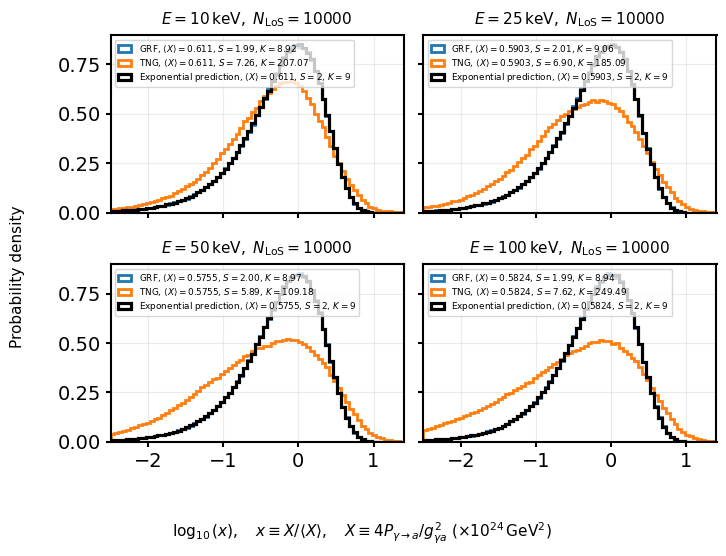

[saved] /Users/Logan/Desktop/alp_survival_functions.png


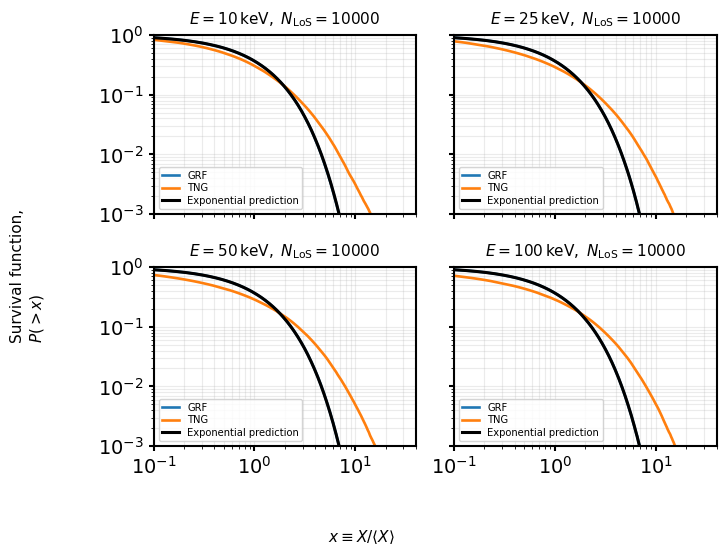

[saved] /Users/Logan/Desktop/alp_tail_enhancement.png


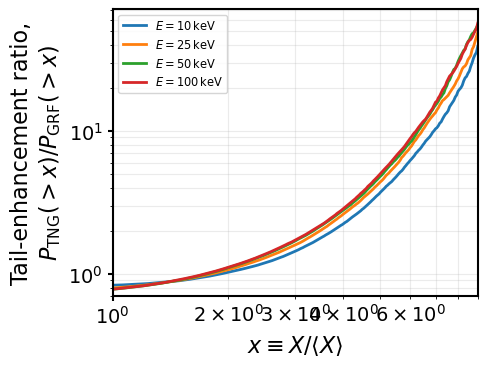

[saved] /Users/Logan/Desktop/alp_moment_summary.png


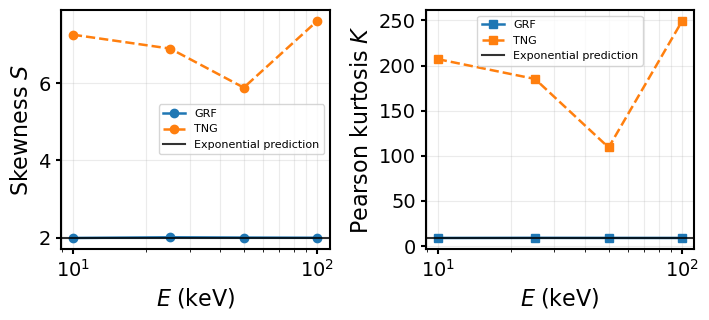


All done in 5066.3s | successful clusters with at least one energy: 100/100


In [9]:
import sys
sys.path.append("/Users/Logan/illustris_python/")

import os
import gc
import time
import numpy as np
import h5py
import matplotlib.pyplot as plt

from scipy.spatial import cKDTree

# ============================================================
# SWITCHES
# ============================================================
OMEGA_PL_ZERO      = False
LOS_SUBTRACT_MEAN  = False
P_MAX_WEAK         = 0.1
VERBOSE            = True

# Match TNG analytic mean to GRF mean before normalization.
MATCH_TNG_MEAN_TO_GRF = True

# Paper-consistent massive-regime phase:
# eta_a = m_a^2 / (2E)
USE_PAPER_MASSIVE_LIMIT = True

# ============================================================
# CONSTANTS
# ============================================================
kpc_to_eVinv = np.float64(1.5637e26)
G_to_eV2     = np.float64(1.95e-2)
m_p_gram     = np.float64(1.6726219e-24)
Msun_gram    = np.float64(1.98847e33)
kpc_cm       = np.float64(3.08567758e21)

def omega_pl(ne_cm3):
    ne_cm3 = np.asarray(ne_cm3, dtype=np.float64)
    if OMEGA_PL_ZERO:
        return np.zeros_like(ne_cm3, dtype=np.float64)
    return np.float64(3.69e-11) * np.sqrt(ne_cm3)

def vprint(msg):
    if VERBOSE:
        print(msg, flush=True)

# ============================================================
# USER CONTROLS
# ============================================================
FILELIST = [
    f"/Users/Logan/Documents/cutout_{i}.hdf5"
    for i in range(100)
]

TNG_P_SCALE = np.float64(0.0567)
R0_KPC      = 24.0

ENERGIES_KEV = [10, 25, 50, 100]

R_max      = np.float64(200.0)
b_max      = np.float64(200.0)
N_bins_los = 200

# Direct TNG particle interpolation controls
TNG_KNN_IDW        = 8
TNG_IDW_POWER      = np.float64(2.0)
TNG_MIN_VALID_FRAC = np.float64(0.85)

# Monte-Carlo targets: PER FILE
N_grf_per_file = 10000
N_tng_per_file = 10000
base_seed      = 12345
MAX_ATTEMPTS_MULT = 400

# P1D-control estimator from direct LoS
N_P1D_LOS_TARGET      = 3000
N_P1D_LOS_MIN         = 300
P1D_MIN_VALID_FRAC    = np.float64(0.85)
P1D_MAX_ATTEMPTS_MULT = 500

# Histogram / plot controls
N_HIST_BINS = 70
X_FLOOR     = np.float64(1e-20)
BLACK_SEED  = 20260423

XLOG_MIN = -4.0
XLOG_MAX =  2.0

# Survival / tail controls
SURVIVAL_X_MIN = np.float64(1e-3)
SURVIVAL_X_MAX = np.float64(1e2)
SURVIVAL_N_GRID = 260

# Cut survival functions when expected counts are too small.
MIN_SURVIVORS_FOR_SURVIVAL = 5
MIN_SURVIVORS_FOR_RATIO    = 20

TAIL_THRESHOLDS = [2.0, 5.0, 10.0, 20.0]

# ALP parameters
g   = np.float64(1e-14)   # GeV^-1
m_a = np.float64(1e-12)   # eV

# ============================================================
# BASIC ALP PHASE
# ============================================================
def eta_a_eV(m_a_eV, E_eV):
    return np.float64(m_a_eV) ** 2 / (np.float64(2.0) * np.float64(E_eV))

def eta_a_kpcinv(m_a_eV, E_eV):
    return eta_a_eV(m_a_eV, E_eV) * kpc_to_eVinv

# ============================================================
# CENTERING
# ============================================================
def get_center(f, coords, rho_code=None, masses=None):
    try:
        if "Group" in f and "GroupPos" in f["Group"]:
            c = np.asarray(f["Group"]["GroupPos"][:], dtype=np.float64).squeeze()
            if c.size == 3 and np.all(np.isfinite(c)):
                return c
    except Exception:
        pass

    try:
        if "Subhalo" in f and "SubhaloPos" in f["Subhalo"]:
            c = np.asarray(f["Subhalo"]["SubhaloPos"][:], dtype=np.float64).squeeze()
            if c.size == 3 and np.all(np.isfinite(c)):
                return c
    except Exception:
        pass

    if rho_code is not None:
        rho_code = np.asarray(rho_code, dtype=np.float64)
        m = np.isfinite(rho_code)
        if np.any(m):
            i = np.nanargmax(rho_code)
            c = np.asarray(coords[i], dtype=np.float64).squeeze()
            if c.size == 3 and np.all(np.isfinite(c)):
                return c

    if masses is not None:
        masses = np.asarray(masses, dtype=np.float64)
        m = np.isfinite(masses) & (masses > 0)
        if np.any(m):
            return np.average(
                np.asarray(coords[m], dtype=np.float64),
                axis=0,
                weights=masses[m]
            ).astype(np.float64)

    return np.median(np.asarray(coords, dtype=np.float64), axis=0).astype(np.float64)

# ============================================================
# TNG IO + UNITS
# ============================================================
def get_header_units_cgs(f):
    a = f["Header"].attrs
    keys = ("UnitLength_in_cm", "UnitMass_in_g", "UnitVelocity_in_cm_per_s")
    if all(k in a for k in keys):
        return np.float64(a[keys[0]]), np.float64(a[keys[1]]), np.float64(a[keys[2]])
    return None

def B_code_to_G_factor(f, assume_B_is_comoving=True, include_sqrt4pi=False):
    units = get_header_units_cgs(f)
    if units is None:
        raise RuntimeError("Missing Header unit attrs for B conversion.")

    l_unit, m_unit, v_unit = units
    B_unit = v_unit * np.sqrt(m_unit) / (l_unit ** np.float64(1.5))

    if include_sqrt4pi:
        B_unit *= np.sqrt(np.float64(4.0) * np.pi)

    z = np.float64(f["Header"].attrs["Redshift"])
    a = np.float64(1.0) / (np.float64(1.0) + z)

    if assume_B_is_comoving:
        B_unit *= (np.float64(1.0) / (a * a))

    return np.float64(B_unit)

def load_tng_particles(filename, XH_default=0.76,
                       assume_B_is_comoving=True,
                       include_sqrt4pi=False):
    with h5py.File(filename, "r") as f:
        gas = f["PartType0"]

        coords   = np.asarray(gas["Coordinates"][:], dtype=np.float64)
        rho_code = np.asarray(gas["Density"][:], dtype=np.float64)
        ne_frac  = np.asarray(gas["ElectronAbundance"][:], dtype=np.float64)
        masses   = np.asarray(gas["Masses"][:], dtype=np.float64)
        B_vec    = np.asarray(gas["MagneticField"][:], dtype=np.float64)

        if "GFM_Metals" in gas:
            XH = np.asarray(gas["GFM_Metals"][:, 0], dtype=np.float64)
        else:
            XH = np.full_like(ne_frac, np.float64(XH_default))

        z = np.float64(f["Header"].attrs["Redshift"])
        h = np.float64(f["Header"].attrs["HubbleParam"])

        center = get_center(f, coords, rho_code=rho_code, masses=masses)

        B_unit_G = B_code_to_G_factor(
            f,
            assume_B_is_comoving=assume_B_is_comoving,
            include_sqrt4pi=include_sqrt4pi
        )

    coords_kpc = (coords - center) / (h * (np.float64(1.0) + z))
    x, y, zz = coords_kpc.T
    r_kpc = np.sqrt(x * x + y * y + zz * zz)

    rho_phys = rho_code * np.float64(1e10) * (h * h) * ((np.float64(1.0) + z) ** 3)
    rho_phys = np.clip(rho_phys, np.float64(0.0), np.float64(1e300))
    rho_g_cm3 = rho_phys * Msun_gram / (kpc_cm ** 3)

    masses_Msun = masses * np.float64(1e10) / h
    rho_phys_safe = np.maximum(rho_phys, np.float64(1e-300))
    V_kpc3 = masses_Msun / rho_phys_safe
    V_kpc3 = np.clip(V_kpc3, np.float64(0.0), np.float64(1e300))
    V_cm3  = V_kpc3 * (kpc_cm ** 3)

    ne_cm3 = ne_frac * XH * rho_g_cm3 / m_p_gram
    By_G   = (B_vec[:, 1] * B_unit_G).astype(np.float64)

    return (
        coords_kpc.astype(np.float64),
        r_kpc.astype(np.float64),
        ne_cm3.astype(np.float64),
        By_G.astype(np.float64),
        V_cm3.astype(np.float64),
    )

# ============================================================
# FLATTENING
# ============================================================
def radial_envelope_rms_By(r_kpc, By_G, weights_cm3, Rmax_kpc, Nr_bins=40):
    r_kpc = np.asarray(r_kpc, np.float64)
    By_G  = np.asarray(By_G, np.float64)
    w     = np.asarray(weights_cm3, np.float64)

    Rmax_kpc = np.float64(Rmax_kpc)
    rmin = np.float64(1.0)
    r_bins = np.logspace(np.log10(rmin), np.log10(Rmax_kpc), int(Nr_bins) + 1)
    r_cent = np.float64(0.5) * (r_bins[:-1] + r_bins[1:])
    dig = np.digitize(r_kpc, r_bins)

    env = np.full(int(Nr_bins), np.nan, dtype=np.float64)
    ok  = np.zeros(int(Nr_bins), dtype=bool)

    for i in range(int(Nr_bins)):
        m = (dig == (i + 1))
        if np.any(m):
            ww = w[m]
            env[i] = np.sqrt(np.average(By_G[m] ** 2, weights=ww))
            ok[i] = np.isfinite(env[i]) and (env[i] > 0)

    m = ok & np.isfinite(env) & (env > 0)
    if np.count_nonzero(m) < 5:
        raise RuntimeError("Too few valid bins in rms(By) envelope.")

    return r_cent[m], env[m]

def flatten_By_by_envelope(r_kpc, By_G, r_env, env_rms_By, r0_kpc):
    ref = np.interp(np.float64(r0_kpc), r_env, env_rms_By)
    env_cell = np.interp(r_kpc, r_env, env_rms_By, left=np.nan, right=np.nan)

    good = np.isfinite(env_cell) & (env_cell > 0) & np.isfinite(By_G)
    corr = np.ones_like(env_cell, dtype=np.float64)
    corr[good] = (np.float64(ref) / env_cell[good])

    By_flat = np.zeros_like(By_G)
    By_flat[good] = By_G[good] * corr[good]
    return By_flat.astype(np.float64), good

# ============================================================
# LoS GEOMETRY
# ============================================================
def allowed_z_range(xyz_min, xyz_max, R_max):
    z0 = max(-float(R_max), float(xyz_min[2]))
    z1 = min( float(R_max), float(xyz_max[2]))

    if not np.isfinite(z0) or not np.isfinite(z1) or z1 <= z0:
        return None

    return np.float64(z0), np.float64(z1)

def sample_xy_in_aperture_and_box(rng, b_max, xyz_min, xyz_max, max_tries=10000):
    for _ in range(int(max_tries)):
        b  = np.float64(b_max) * np.sqrt(rng.random())
        th = np.float64(2.0 * np.pi) * rng.random()

        x0 = b * np.cos(th)
        y0 = b * np.sin(th)

        if (xyz_min[0] <= x0 <= xyz_max[0]) and (xyz_min[1] <= y0 <= xyz_max[1]):
            return np.float64(x0), np.float64(y0)

    return None

# ============================================================
# DIRECT TNG LoS FROM PARTICLES
# ============================================================
def build_los_from_particles(tree, coords, By_vals, ne_vals, xyz_min, xyz_max,
                             x0, y0, R_max, N_bins,
                             k_neighbors=8,
                             idw_power=np.float64(2.0),
                             min_valid=0.85):
    zr = allowed_z_range(xyz_min, xyz_max, R_max)
    if zr is None:
        return None

    z0, z1 = zr

    if (z1 - z0) < np.float64(5.0):
        return None

    z_edges = np.linspace(float(z0), float(z1), int(N_bins) + 1, dtype=np.float64)
    z_mid   = np.float64(0.5) * (z_edges[:-1] + z_edges[1:])

    pts = np.column_stack([
        np.full_like(z_mid, np.float64(x0)),
        np.full_like(z_mid, np.float64(y0)),
        z_mid.astype(np.float64)
    ])

    inside = np.all((pts >= xyz_min[None, :]) & (pts <= xyz_max[None, :]), axis=1)
    if np.mean(inside) < np.float64(min_valid):
        return None

    kq = int(min(k_neighbors, coords.shape[0]))
    d, idx = tree.query(pts, k=kq, workers=-1)

    if kq == 1:
        d = d[:, None]
        idx = idx[:, None]

    d = np.asarray(d, dtype=np.float64)
    idx = np.asarray(idx, dtype=np.int64)

    exact = (d[:, 0] == 0)
    w = np.zeros_like(d, dtype=np.float64)

    if np.any(exact):
        w[exact, 0] = 1.0

    not_exact = ~exact
    if np.any(not_exact):
        w[not_exact] = (
            np.float64(1.0)
            / np.maximum(d[not_exact], np.float64(1e-12)) ** np.float64(idw_power)
        )
        wsum = np.sum(w[not_exact], axis=1, keepdims=True)
        w[not_exact] /= np.maximum(wsum, np.float64(1e-300))

    By = np.sum(w * By_vals[idx], axis=1).astype(np.float64)
    ne = np.sum(w * ne_vals[idx], axis=1).astype(np.float64)

    ok = inside & np.isfinite(By) & np.isfinite(ne)

    if np.mean(ok) < np.float64(min_valid):
        return None

    if not np.all(ok):
        ii = np.arange(z_mid.size)
        By = np.interp(ii, ii[ok], By[ok]).astype(np.float64)
        ne = np.interp(ii, ii[ok], ne[ok]).astype(np.float64)

    if z_mid.size < 5:
        return None

    dL_kpc = np.float64(z_mid[1] - z_mid[0])
    L_eff_kpc = np.float64(z_mid[-1] - z_mid[0] + dL_kpc)

    return z_mid, By, ne, dL_kpc, L_eff_kpc

# ============================================================
# ANALYTIC PROPAGATION
# ============================================================
def compute_A_and_P_analytic(z_kpc, By, ne, dL_kpc, g_GeVinv, m_a_eV, E_eV):
    dz_eVinv = np.float64(dL_kpc) * kpc_to_eVinv
    g_eVinv  = np.float64(g_GeVinv) * np.float64(1e-9)

    z_kpc = np.asarray(z_kpc, np.float64)
    By = np.asarray(By, np.float64)
    ne = np.asarray(ne, np.float64)

    Delta_ag = np.float64(0.5) * g_eVinv * (By * G_to_eV2)

    if USE_PAPER_MASSIVE_LIMIT:
        phase = -eta_a_eV(m_a_eV, E_eV) * (z_kpc * kpc_to_eVinv)
    else:
        wpl2 = omega_pl(ne) ** 2
        Delta_eff = -(np.float64(m_a_eV) ** 2 - wpl2) / (
            np.float64(2.0) * np.float64(E_eV)
        )

        phi_left = np.zeros_like(Delta_eff)
        phi_left[1:] = np.cumsum(Delta_eff[:-1]) * dz_eVinv
        phase = phi_left + np.float64(0.5) * Delta_eff * dz_eVinv

    A = np.sum(Delta_ag * np.exp(1j * phase) * dz_eVinv)
    P = np.abs(A) ** 2
    return A, np.float64(P)

def eta_los_kpcinv(ne, m_a_eV, E_eV):
    if USE_PAPER_MASSIVE_LIMIT:
        return np.float64(eta_a_kpcinv(m_a_eV, E_eV))

    ne = np.asarray(ne, np.float64)
    wpl2 = omega_pl(ne) ** 2
    Delta_eff = -(np.float64(m_a_eV) ** 2 - wpl2) / (
        np.float64(2.0) * np.float64(E_eV)
    )
    return np.float64(np.mean(np.abs(Delta_eff)) * kpc_to_eVinv)

# ============================================================
# P1D / GRF CONTROL FROM DIRECT TNG LoS
# ============================================================
def estimate_X0_from_direct_tng_los(C, E_eV, rng,
                                    N_target=N_P1D_LOS_TARGET,
                                    N_min=N_P1D_LOS_MIN,
                                    min_valid=P1D_MIN_VALID_FRAC):
    """
    Robust semi-analytic GRF scale estimate.

    We use direct TNG LoS to estimate the mean Fourier-amplitude power.
    Then the GRF distribution is modeled as exponential, corresponding to
    a complex Gaussian amplitude.
    """
    X_samples = []
    L_eff_samples = []

    max_attempts = int(P1D_MAX_ATTEMPTS_MULT * N_target)
    attempts = 0

    while len(X_samples) < int(N_target) and attempts < max_attempts:
        attempts += 1

        xy = sample_xy_in_aperture_and_box(
            rng,
            b_max=b_max,
            xyz_min=C["xyz_min"],
            xyz_max=C["xyz_max"]
        )
        if xy is None:
            break

        x0, y0 = xy

        los = build_los_from_particles(
            tree=C["tree"],
            coords=C["coords_f"],
            By_vals=C["By_f"],
            ne_vals=C["ne_f"],
            xyz_min=C["xyz_min"],
            xyz_max=C["xyz_max"],
            x0=x0,
            y0=y0,
            R_max=R_max,
            N_bins=N_bins_los,
            k_neighbors=TNG_KNN_IDW,
            idw_power=TNG_IDW_POWER,
            min_valid=min_valid
        )
        if los is None:
            continue

        z_los, B_los, ne_los, dL, L_eff = los

        if LOS_SUBTRACT_MEAN:
            B_los = (np.asarray(B_los, np.float64) - np.mean(B_los)).astype(np.float64)

        _, Pana = compute_A_and_P_analytic(z_los, B_los, ne_los, dL, g, m_a, E_eV)

        if not np.isfinite(Pana) or Pana < 0:
            continue

        X = np.float64(4.0) * Pana / (g * g) * np.float64(1e-24)

        if np.isfinite(X) and X > X_FLOOR:
            X_samples.append(np.float64(X))
            L_eff_samples.append(np.float64(L_eff))

    X_samples = np.asarray(X_samples, dtype=np.float64)
    L_eff_samples = np.asarray(L_eff_samples, dtype=np.float64)

    if X_samples.size < int(N_min):
        return None

    X0 = np.float64(np.mean(X_samples))
    if not np.isfinite(X0) or X0 <= 0:
        return None

    skew_tmp, kurt_tmp = skew_kurt_pos(X_samples / np.maximum(X0, np.float64(1e-300)))

    return dict(
        X0=float(X0),
        N_p1d=int(X_samples.size),
        L_eff_mean=float(np.nanmean(L_eff_samples)) if L_eff_samples.size else np.nan,
        L_eff_min=float(np.nanmin(L_eff_samples)) if L_eff_samples.size else np.nan,
        L_eff_max=float(np.nanmax(L_eff_samples)) if L_eff_samples.size else np.nan,
        p1d_skew=float(skew_tmp),
        p1d_kurt=float(kurt_tmp),
    )

def sample_grf_from_X0(X0, N, rng):
    X0 = np.float64(X0)
    if not np.isfinite(X0) or X0 <= 0:
        raise RuntimeError("Invalid X0 for GRF sampling.")
    return rng.exponential(scale=X0, size=int(N)).astype(np.float64)

# ============================================================
# STATS
# ============================================================
def skew_kurt_pos(x):
    x = np.asarray(x, np.float64)
    x = x[np.isfinite(x) & (x > 0)]
    if x.size < 50:
        return np.nan, np.nan

    mu = np.mean(x)
    sig = np.std(x, ddof=0)
    if sig == 0:
        return np.nan, np.nan

    z = (x - mu) / sig
    return float(np.mean(z ** 3)), float(np.mean(z ** 4))

def tail_prob(x, threshold):
    x = np.asarray(x, dtype=np.float64)
    x = x[np.isfinite(x) & (x > 0)]
    if x.size == 0:
        return np.nan
    return float(np.mean(x > np.float64(threshold)))

def tail_enhancement(x_tng, x_grf, threshold):
    p_tng = tail_prob(x_tng, threshold)
    p_grf = tail_prob(x_grf, threshold)
    if not np.isfinite(p_tng) or not np.isfinite(p_grf) or p_grf <= 0:
        return np.nan
    return float(p_tng / p_grf)

def survival_function(x, x_grid, min_survivors=5):
    """
    Empirical survival P(X > x), cut when fewer than min_survivors
    points remain in the tail.
    """
    x = np.asarray(x, dtype=np.float64)
    x = x[np.isfinite(x) & (x > 0)]

    if x.size == 0:
        return np.full_like(x_grid, np.nan, dtype=np.float64)

    s = np.array([np.mean(x > xx) for xx in x_grid], dtype=np.float64)

    counts = s * x.size
    s[counts < int(min_survivors)] = np.nan
    s[s <= 0] = np.nan

    return s

def concat_samples(arr_list):
    if len(arr_list) == 0:
        return np.array([], dtype=np.float64)
    arrs = [np.asarray(a, dtype=np.float64) for a in arr_list if len(a) > 0]
    if len(arrs) == 0:
        return np.array([], dtype=np.float64)
    return np.concatenate(arrs)

def mean_scalar(arr_list):
    if len(arr_list) == 0:
        return np.nan
    arr = np.asarray(arr_list, dtype=np.float64)
    return float(np.nanmean(arr))

def mean_stat(stats_list, key):
    if len(stats_list) == 0:
        return np.nan
    v = np.array([d[key] for d in stats_list], dtype=np.float64)
    return float(np.nanmean(v))

def build_log10_hist_data(*arrays):
    return np.linspace(XLOG_MIN, XLOG_MAX, int(N_HIST_BINS) + 1, dtype=np.float64)

# ============================================================
# PREPARE ONE CLUSTER
# ============================================================
def prepare_cluster(fname):
    t0 = time.time()
    vprint(f"[prep] loading {os.path.basename(fname)}")

    coords_kpc, r_kpc, ne_cm3, By_G, V_cm3 = load_tng_particles(
        fname,
        assume_B_is_comoving=True,
        include_sqrt4pi=False
    )

    r_env, env_rms = radial_envelope_rms_By(
        r_kpc,
        By_G,
        V_cm3,
        Rmax_kpc=float(np.nanmax(r_kpc)),
        Nr_bins=40
    )
    By_flat, good = flatten_By_by_envelope(r_kpc, By_G, r_env, env_rms, R0_KPC)

    coords_f = coords_kpc[good]
    By_f     = By_flat[good]
    ne_f     = ne_cm3[good]

    if coords_f.shape[0] < 100:
        raise RuntimeError(f"{fname}: too few valid flattened gas cells.")

    tree = cKDTree(coords_f)
    xyz_min = coords_f.min(axis=0).astype(np.float64)
    xyz_max = coords_f.max(axis=0).astype(np.float64)

    zr = allowed_z_range(xyz_min, xyz_max, R_max)
    if zr is None:
        raise RuntimeError(f"{fname}: no usable z-range after clipping to R_max.")

    z0, z1 = zr
    L_available = float(z1 - z0)

    dt = time.time() - t0
    vprint(
        f"[prep] done {os.path.basename(fname)} | "
        f"Ncells={coords_f.shape[0]} | "
        f"L_available={L_available:.2f} kpc | "
        f"{dt:.1f}s"
    )

    del r_kpc, V_cm3, r_env, env_rms, By_G, ne_cm3
    gc.collect()

    return dict(
        fname=fname,
        coords_f=coords_f,
        By_f=By_f,
        ne_f=ne_f,
        tree=tree,
        xyz_min=xyz_min,
        xyz_max=xyz_max,
        L_available=L_available,
    )

# ============================================================
# RUN ONE CLUSTER AT ONE ENERGY
# ============================================================
def run_cluster_energy_analytic(C, E_keV, N_grf_each, N_tng_each, cluster_seed):
    E_eV = np.float64(E_keV) * np.float64(1e3)
    rng = np.random.default_rng(int(cluster_seed))

    # -------------------------
    # GRF scale from direct TNG LoS P1D estimator
    # -------------------------
    p1d = estimate_X0_from_direct_tng_los(
        C=C,
        E_eV=E_eV,
        rng=rng,
        N_target=N_P1D_LOS_TARGET,
        N_min=N_P1D_LOS_MIN,
        min_valid=P1D_MIN_VALID_FRAC
    )

    if p1d is None:
        raise RuntimeError(
            f"[{os.path.basename(C['fname'])}] P1D estimator failed. "
            f"Not enough valid direct LoS."
        )

    X0_grf = np.float64(p1d["X0"])
    Xgrf_raw = sample_grf_from_X0(X0_grf, N_grf_each, rng)

    # Weak-mixing cut expressed back in P
    Pgrf_equiv = Xgrf_raw * (g * g) / np.float64(4.0) * np.float64(1e24)
    m_grf = Pgrf_equiv <= np.float64(P_MAX_WEAK)

    Xgrf_raw = Xgrf_raw[m_grf]
    Xgrf_raw = Xgrf_raw[np.isfinite(Xgrf_raw) & (Xgrf_raw > X_FLOOR)]

    if Xgrf_raw.size < 50:
        raise RuntimeError(
            f"[{os.path.basename(C['fname'])}] Too few GRF samples after weak cut at E={E_keV} keV."
        )

    # -------------------------
    # TNG LoS
    # -------------------------
    Ptng_ana = np.empty(N_tng_each, dtype=np.float64)
    etas_tng = np.empty(N_tng_each, dtype=np.float64)
    L_eff_tng = np.empty(N_tng_each, dtype=np.float64)

    MAX_ATTEMPTS_T = int(MAX_ATTEMPTS_MULT * N_tng_each)

    n_t = 0
    attempts = 0

    while n_t < N_tng_each and attempts < MAX_ATTEMPTS_T:
        attempts += 1

        xy = sample_xy_in_aperture_and_box(
            rng,
            b_max=b_max,
            xyz_min=C["xyz_min"],
            xyz_max=C["xyz_max"]
        )
        if xy is None:
            break

        x0, y0 = xy

        los = build_los_from_particles(
            tree=C["tree"],
            coords=C["coords_f"],
            By_vals=C["By_f"],
            ne_vals=C["ne_f"],
            xyz_min=C["xyz_min"],
            xyz_max=C["xyz_max"],
            x0=x0,
            y0=y0,
            R_max=R_max,
            N_bins=N_bins_los,
            k_neighbors=TNG_KNN_IDW,
            idw_power=TNG_IDW_POWER,
            min_valid=TNG_MIN_VALID_FRAC
        )
        if los is None:
            continue

        z_los, B_los, ne_los, dL, L_eff = los

        if LOS_SUBTRACT_MEAN:
            B_los = (np.asarray(B_los, np.float64) - np.mean(B_los)).astype(np.float64)

        _, Pana = compute_A_and_P_analytic(z_los, B_los, ne_los, dL, g, m_a, E_eV)
        Pana *= TNG_P_SCALE

        if not np.isfinite(Pana) or Pana < 0:
            continue

        Ptng_ana[n_t] = np.float64(Pana)

        et = eta_los_kpcinv(ne_los, m_a, E_eV)
        etas_tng[n_t] = float(et) if np.isfinite(et) else np.nan
        L_eff_tng[n_t] = np.float64(L_eff)

        n_t += 1

    if n_t < 50:
        raise RuntimeError(
            f"[{os.path.basename(C['fname'])}] Too few TNG LoS at E={E_keV} keV. "
            f"Got {n_t} / {N_tng_each}."
        )

    Ptng_ana = Ptng_ana[:n_t]
    etas_tng = etas_tng[:n_t]
    L_eff_tng = L_eff_tng[:n_t]

    # Weak-mixing cut
    m_tng = Ptng_ana <= np.float64(P_MAX_WEAK)

    Xtng_raw = np.float64(4.0) * Ptng_ana[m_tng] / (g * g) * np.float64(1e-24)
    Xtng_raw = Xtng_raw[np.isfinite(Xtng_raw) & (Xtng_raw > X_FLOOR)]

    if Xtng_raw.size < 50:
        raise RuntimeError(
            f"[{os.path.basename(C['fname'])}] too few positive TNG X samples after weak cut at E={E_keV} keV."
        )

    # -------------------------
    # Mean matching before normalization
    # -------------------------
    meanX_grf = float(np.mean(Xgrf_raw))
    meanX_tng_before = float(np.mean(Xtng_raw))

    if MATCH_TNG_MEAN_TO_GRF:
        tng_match_factor = meanX_grf / np.maximum(meanX_tng_before, np.float64(1e-300))
    else:
        tng_match_factor = np.float64(1.0)

    Xtng_matched = Xtng_raw * tng_match_factor
    meanX_tng_after = float(np.mean(Xtng_matched))

    # -------------------------
    # Normalize by each displayed mean.
    # This makes survival curves directly comparable in x = X/<X>.
    # -------------------------
    Xgrf_norm = Xgrf_raw / np.maximum(np.mean(Xgrf_raw), np.float64(1e-300))
    Xtng_norm = Xtng_matched / np.maximum(np.mean(Xtng_matched), np.float64(1e-300))

    # The normalized exponential prediction has mean 1.
    X0_black_norm = np.float64(1.0)

    skew_grf, kurt_grf = skew_kurt_pos(Xgrf_norm)
    skew_tng, kurt_tng = skew_kurt_pos(Xtng_norm)

    eta_eff_i = float(eta_a_kpcinv(m_a, E_eV)) if USE_PAPER_MASSIVE_LIMIT else float(np.nanmean(etas_tng))

    return dict(
        X_grf_norm=Xgrf_norm.astype(np.float64),
        X_tng_norm=Xtng_norm.astype(np.float64),
        X0_black_norm=float(X0_black_norm),
        stats=dict(
            N_grf=int(Xgrf_norm.size),
            N_tng=int(Xtng_norm.size),
            N_p1d=int(p1d["N_p1d"]),
            meanX_grf=float(meanX_grf),
            meanX_tng_before=float(meanX_tng_before),
            meanX_tng=float(meanX_tng_after),
            tng_match_factor=float(tng_match_factor),
            X0_black=float(X0_grf),
            X0_black_norm=float(X0_black_norm),
            skew_grf=float(skew_grf),
            kurt_grf=float(kurt_grf),
            skew_tng=float(skew_tng),
            kurt_tng=float(kurt_tng),
            eta_eff=float(eta_eff_i),
            L_available=float(C["L_available"]),
            L_p1d_mean=float(p1d["L_eff_mean"]),
            L_tng_mean=float(np.nanmean(L_eff_tng)),
        )
    )
# ============================================================
# PLOTTING LIMITS / PUBLICATION FRAMING
# ============================================================

SAVE_FIGURES = True
SAVE_DIR = "/Users/Logan/Desktop"
SAVE_DPI = 300

# LaTeX-friendly PNG output sizes
FIGSIZE_HIST     = (7.4, 5.8)
FIGSIZE_SURV     = (7.4, 5.8)
FIGSIZE_TAIL     = (4.9, 3.7)
FIGSIZE_MOMENTS  = (7.2, 3.3)

# Histogram framing
HIST_XLOG_MIN = -2.5
HIST_XLOG_MAX =  1.4
HIST_N_BINS   = 75

# Survival-function framing
SURV_X_MIN = 0.1
SURV_X_MAX = 40.0
SURV_Y_MIN = 1e-3
SURV_Y_MAX = 1.0

# Tail-enhancement framing
TAIL_X_MIN = 1.0
TAIL_X_MAX = 9.0
TAIL_Y_MIN = 0.7
TAIL_Y_MAX = 500.0

# Empirical curves become unreliable below this survival level
SURVIVAL_CUT = 5e-5

LINEWIDTH_MAIN = 1.9
LINEWIDTH_REF  = 2.2
GRID_ALPHA     = 0.25

def save_png(fig, filename):
    if not SAVE_FIGURES:
        return

    os.makedirs(SAVE_DIR, exist_ok=True)
    path = os.path.join(SAVE_DIR, filename)

    fig.savefig(
        path,
        dpi=SAVE_DPI,
        bbox_inches="tight",
        pad_inches=0.18,
        facecolor="white"
    )

    vprint(f"[saved] {path}")

def clean_positive(x):
    x = np.asarray(x, dtype=np.float64)
    return x[np.isfinite(x) & (x > X_FLOOR)]

def empirical_survival(x):
    """
    Strict empirical survival function P(X > x).
    Drops the last zero-survival point.
    """
    x = clean_positive(x)
    if x.size == 0:
        return np.array([], dtype=np.float64), np.array([], dtype=np.float64)

    xs = np.sort(x)
    n = xs.size

    surv = (n - np.arange(n, dtype=np.float64) - 1.0) / np.float64(n)

    m = surv > 0
    return xs[m], surv[m]

def survival_on_grid(x, x_grid):
    """
    Stepwise empirical survival P(X > x_grid).
    """
    x = clean_positive(x)
    if x.size == 0:
        return np.full_like(x_grid, np.nan, dtype=np.float64)

    xs = np.sort(x)
    n = xs.size

    idx = np.searchsorted(xs, x_grid, side="right")
    surv = (n - idx).astype(np.float64) / np.float64(n)

    return surv.astype(np.float64)

def panel_title(res):
    st = res["stats"]
    return rf"$E={res['E_keV']:g}\,\mathrm{{keV}},\ N_\mathrm{{LoS}}={st['N_tng']}$"

def get_panel_arrays(res):
    x_grf = clean_positive(res["X_grf_norm"])
    x_tng = clean_positive(res["X_tng_norm"])
    return x_grf, x_tng

def get_panel_black_sample(res, rng, n):
    """
    Normalized exponential prediction.

    Since the plotted variable is x = X/<X>, the exponential reference
    should have the same displayed mean as GRF/TNG after normalization.
    """
    scale = np.float64(res.get("X0_black_norm", 1.0))
    if not np.isfinite(scale) or scale <= 0:
        scale = np.float64(1.0)

    return clean_positive(rng.exponential(scale=scale, size=int(n)))

# ============================================================
# HISTOGRAM PLOT
# ============================================================

def plot_histograms(panels):
    n_panels = len(panels)

    if n_panels == 1:
        fig, axs = plt.subplots(1, 1, figsize=(6.3, 4.6), sharex=True, sharey=True)
        axs = np.array([axs])
    else:
        fig, axs = plt.subplots(
            2, 2,
            figsize=FIGSIZE_HIST,
            sharex=True,
            sharey=True
        )
        axs = np.asarray(axs).ravel()

    rng_black = np.random.default_rng(BLACK_SEED)

    for ax, res in zip(axs, panels):
        st = res["stats"]

        x_grf, x_tng = get_panel_arrays(res)

        if x_grf.size == 0 or x_tng.size == 0:
            ax.set_visible(False)
            continue

        x_black = get_panel_black_sample(res, rng_black, x_grf.size)

        log_edges = np.linspace(HIST_XLOG_MIN, HIST_XLOG_MAX, HIST_N_BINS + 1)

        ax.hist(
            np.log10(x_grf),
            bins=log_edges,
            histtype="step",
            linewidth=2.0,
            density=True,
            label=(r"GRF, "
                   rf"$\langle X\rangle={st['meanX_grf']:.4g}$, "
                   rf"$S={st['skew_grf']:.2f}$, "
                   rf"$K={st['kurt_grf']:.2f}$")
        )

        ax.hist(
            np.log10(x_tng),
            bins=log_edges,
            histtype="step",
            linewidth=2.0,
            density=True,
            label=(r"TNG, "
                   rf"$\langle X\rangle={st['meanX_tng']:.4g}$, "
                   rf"$S={st['skew_tng']:.2f}$, "
                   rf"$K={st['kurt_tng']:.2f}$")
        )

        ax.hist(
            np.log10(x_black),
            bins=log_edges,
            histtype="step",
            linewidth=2.3,
            density=True,
            color="black",
            label=(r"Exponential prediction, "
                   rf"$\langle X\rangle={st['meanX_grf']:.4g}$, "
                   r"$S=2$, "
                   r"$K=9$")
        )

        ax.set_xlim(HIST_XLOG_MIN, HIST_XLOG_MAX)
        ax.grid(True, which="both", alpha=GRID_ALPHA)
        ax.set_title(panel_title(res), fontsize=11, pad=8)

        leg = ax.legend(
            loc="upper left",
            fontsize=6.4,
            frameon=True,
            handlelength=1.5,
            borderpad=0.35,
            labelspacing=0.25
        )
        leg.get_frame().set_alpha(0.78)

    for ax in axs[len(panels):]:
        ax.set_visible(False)

    fig.supxlabel(
        r"$\log_{10}(x),\quad x \equiv X/\langle X\rangle,\quad "
        r"X \equiv 4P_{\gamma\to a}/g_{\gamma a}^2\;(\times10^{24}\,\mathrm{GeV}^2)$",
        fontsize=11,
        y=0.035
    )

    fig.supylabel(
        "Probability density",
        fontsize=11,
        x=0.025
    )

    fig.tight_layout(rect=[0.045, 0.07, 1.0, 0.985])
    save_png(fig, "alp_histograms.png")
    plt.show()

# ============================================================
# SURVIVAL FUNCTION PLOT
# ============================================================

def plot_survival_functions(panels):
    n_panels = len(panels)

    if n_panels == 1:
        fig, axs = plt.subplots(1, 1, figsize=(6.3, 4.6), sharex=True, sharey=True)
        axs = np.array([axs])
    else:
        fig, axs = plt.subplots(
            2, 2,
            figsize=FIGSIZE_SURV,
            sharex=True,
            sharey=True
        )
        axs = np.asarray(axs).ravel()

    for ax, res in zip(axs, panels):
        x_grf, x_tng = get_panel_arrays(res)

        if x_grf.size == 0 or x_tng.size == 0:
            ax.set_visible(False)
            continue

        xs_g, sg = empirical_survival(x_grf)
        xs_t, st = empirical_survival(x_tng)

        mg = (
            (sg >= SURVIVAL_CUT) &
            (xs_g >= SURV_X_MIN) &
            (xs_g <= SURV_X_MAX)
        )
        mt = (
            (st >= SURVIVAL_CUT) &
            (xs_t >= SURV_X_MIN) &
            (xs_t <= SURV_X_MAX)
        )

        if np.count_nonzero(mg) < 5 or np.count_nonzero(mt) < 5:
            ax.set_visible(False)
            continue

        xg_plot = xs_g[mg]
        sg_plot = sg[mg]

        xt_plot = xs_t[mt]
        st_plot = st[mt]

        ax.plot(
            xg_plot,
            sg_plot,
            linewidth=LINEWIDTH_MAIN,
            label="GRF"
        )

        ax.plot(
            xt_plot,
            st_plot,
            linewidth=LINEWIDTH_MAIN,
            label="TNG"
        )

        # Important fix:
        # The exponential prediction is now clipped at the shortest reliable
        # empirical endpoint, so it cannot continue past the GRF/TNG curves.
        x_black_max = min(
            np.nanmax(xg_plot),
            np.nanmax(xt_plot),
            SURV_X_MAX
        )

        x_black_min = max(SURV_X_MIN, min(np.nanmin(xg_plot), np.nanmin(xt_plot)))

        if np.isfinite(x_black_max) and x_black_max > x_black_min:
            x_black = np.logspace(
                np.log10(x_black_min),
                np.log10(x_black_max),
                600
            )
            y_black = np.exp(-x_black)

            mb = y_black >= SURVIVAL_CUT

            ax.plot(
                x_black[mb],
                y_black[mb],
                color="black",
                linewidth=LINEWIDTH_REF,
                label="Exponential prediction"
            )

        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlim(SURV_X_MIN, SURV_X_MAX)
        ax.set_ylim(SURV_Y_MIN, SURV_Y_MAX)
        ax.grid(True, which="both", alpha=GRID_ALPHA)
        ax.set_title(panel_title(res), fontsize=11, pad=8)

        leg = ax.legend(
            loc="lower left",
            fontsize=7.2,
            frameon=True,
            handlelength=1.7,
            borderpad=0.35,
            labelspacing=0.25
        )
        leg.get_frame().set_alpha(0.82)

    for ax in axs[len(panels):]:
        ax.set_visible(False)

    fig.supxlabel(
        r"$x \equiv X/\langle X\rangle$",
        fontsize=11,
        y=0.035
    )

    fig.supylabel(
        r"Survival function," + "\n" + r"$P(>x)$",
        fontsize=11,
        x=0.025
    )

    fig.tight_layout(rect=[0.055, 0.07, 1.0, 0.985])
    save_png(fig, "alp_survival_functions.png")
    plt.show()

# ============================================================
# SINGLE-PANEL TAIL-ENHANCEMENT PLOT
# ============================================================

def plot_tail_enhancement_single_panel(panels):
    fig, ax = plt.subplots(1, 1, figsize=FIGSIZE_TAIL)

    xmax_seen = np.float64(TAIL_X_MIN)
    ymax_seen = np.float64(TAIL_Y_MIN)

    for res in panels:
        x_grf, x_tng = get_panel_arrays(res)

        if x_grf.size == 0 or x_tng.size == 0:
            continue

        x_max_data = min(
            float(np.nanmax(x_grf)),
            float(np.nanmax(x_tng)),
            float(TAIL_X_MAX)
        )

        if not np.isfinite(x_max_data) or x_max_data <= TAIL_X_MIN:
            continue

        x_grid = np.logspace(
            np.log10(TAIL_X_MIN),
            np.log10(x_max_data),
            260
        )

        s_grf = survival_on_grid(x_grf, x_grid)
        s_tng = survival_on_grid(x_tng, x_grid)

        good = (
            np.isfinite(s_grf)
            & np.isfinite(s_tng)
            & (s_grf >= SURVIVAL_CUT)
            & (s_tng >= SURVIVAL_CUT)
            & (x_grid >= TAIL_X_MIN)
        )

        if np.count_nonzero(good) < 5:
            continue

        x_plot = x_grid[good]
        ratio = s_tng[good] / np.maximum(s_grf[good], np.float64(1e-300))

        good2 = np.isfinite(ratio) & (ratio > 0)

        if np.count_nonzero(good2) < 5:
            continue

        x_plot = x_plot[good2]
        ratio = ratio[good2]

        xmax_seen = max(xmax_seen, np.float64(np.nanmax(x_plot)))
        ymax_seen = max(ymax_seen, np.float64(np.nanmax(ratio)))

        ax.plot(
            x_plot,
            ratio,
            linewidth=2.0,
            label=rf"$E={res['E_keV']:g}\,\mathrm{{keV}}$"
        )

    ax.set_xscale("log")
    ax.set_yscale("log")

    # Auto-frame to the actual plotted tail range.
    x_right = min(float(TAIL_X_MAX), float(xmax_seen) * 1.08)
    y_top = min(float(TAIL_Y_MAX), float(ymax_seen) * 1.25)

    ax.set_xlim(float(TAIL_X_MIN), x_right)
    ax.set_ylim(float(TAIL_Y_MIN), y_top)

    ax.grid(True, which="both", alpha=GRID_ALPHA)

    ax.set_xlabel(r"$x \equiv X/\langle X\rangle$")
    ax.set_ylabel(
        r"Tail-enhancement ratio,"
        "\n"
        r"$P_\mathrm{TNG}(>x)/P_\mathrm{GRF}(>x)$"
    )

    leg = ax.legend(
        loc="upper left",
        fontsize=8.2,
        frameon=True
    )
    leg.get_frame().set_alpha(0.82)

    fig.tight_layout(pad=0.8)
    save_png(fig, "alp_tail_enhancement.png")
    plt.show()

# ============================================================
# SKEWNESS / KURTOSIS PLOT
# ============================================================

def plot_moment_summary(panels):
    E = np.array([p["E_keV"] for p in panels], dtype=np.float64)

    skew_grf = np.array([p["stats"]["skew_grf"] for p in panels], dtype=np.float64)
    skew_tng = np.array([p["stats"]["skew_tng"] for p in panels], dtype=np.float64)

    kurt_grf = np.array([p["stats"]["kurt_grf"] for p in panels], dtype=np.float64)
    kurt_tng = np.array([p["stats"]["kurt_tng"] for p in panels], dtype=np.float64)

    fig, axs = plt.subplots(1, 2, figsize=FIGSIZE_MOMENTS)

    ax = axs[0]
    ax.plot(E, skew_grf, marker="o", linewidth=1.8, label="GRF")
    ax.plot(E, skew_tng, marker="o", linewidth=1.8, linestyle="--", label="TNG")
    ax.axhline(2.0, color="black", linewidth=1.5, alpha=0.8, label="Exponential prediction")
    ax.set_xscale("log")
    ax.set_xlabel(r"$E\;(\mathrm{keV})$")
    ax.set_ylabel(r"Skewness $S$")
    ax.grid(True, which="both", alpha=GRID_ALPHA)
    ax.legend(fontsize=8.0, frameon=True)

    ax = axs[1]
    ax.plot(E, kurt_grf, marker="s", linewidth=1.8, label="GRF")
    ax.plot(E, kurt_tng, marker="s", linewidth=1.8, linestyle="--", label="TNG")
    ax.axhline(9.0, color="black", linewidth=1.5, alpha=0.8, label="Exponential prediction")
    ax.set_xscale("log")
    ax.set_xlabel(r"$E\;(\mathrm{keV})$")
    ax.set_ylabel(r"Pearson kurtosis $K$")
    ax.grid(True, which="both", alpha=GRID_ALPHA)
    ax.legend(fontsize=8.0, frameon=True)

    fig.tight_layout()
    save_png(fig, "alp_moment_summary.png")
    plt.show()

# ============================================================
# MAIN
# ============================================================

def main():
    t0_all = time.time()

    nC = len(FILELIST)
    if nC == 0:
        raise RuntimeError("FILELIST is empty.")

    accum = {
        E_keV: dict(
            X_grf_norm_list=[],
            X_tng_norm_list=[],
            X0_black_norm_list=[],
            stats_list=[],
        )
        for E_keV in ENERGIES_KEV
    }

    n_success_clusters = 0

    for ic, fname in enumerate(FILELIST):
        t0_file = time.time()
        base = os.path.basename(fname)
        vprint(f"\n[{ic+1}/{nC}] Starting {base}")

        try:
            C = prepare_cluster(fname)
        except Exception as e:
            vprint(f"[{ic+1}/{nC}] FAILED during prepare_cluster for {base}: {e}")
            gc.collect()
            continue

        cluster_had_success = False

        for E_keV in ENERGIES_KEV:
            t0_E = time.time()
            seed = int(base_seed + 10000 * ic + 100 * int(E_keV))

            try:
                resE = run_cluster_energy_analytic(
                    C=C,
                    E_keV=E_keV,
                    N_grf_each=N_grf_per_file,
                    N_tng_each=N_tng_per_file,
                    cluster_seed=seed,
                )
            except Exception as e:
                vprint(f"    E={E_keV:>4} keV FAILED for {base}: {e}")
                continue

            cluster_had_success = True

            accum[E_keV]["X_grf_norm_list"].append(resE["X_grf_norm"])
            accum[E_keV]["X_tng_norm_list"].append(resE["X_tng_norm"])
            accum[E_keV]["X0_black_norm_list"].append(resE["X0_black_norm"])
            accum[E_keV]["stats_list"].append(resE["stats"])

            dt_E = time.time() - t0_E

            vprint(
                f"    E={E_keV:>4} keV done | "
                f"<X>_GRF={resE['stats']['meanX_grf']:.4g} | "
                f"<X>_TNG(before)={resE['stats']['meanX_tng_before']:.4g} | "
                f"<X>_TNG(after)={resE['stats']['meanX_tng']:.4g} | "
                f"S_grf={resE['stats']['skew_grf']:.3g} | "
                f"K_grf={resE['stats']['kurt_grf']:.3g} | "
                f"S_tng={resE['stats']['skew_tng']:.3g} | "
                f"K_tng={resE['stats']['kurt_tng']:.3g} | "
                f"Np1d={resE['stats']['N_p1d']} | "
                f"Lp1d={resE['stats']['L_p1d_mean']:.1f} kpc | "
                f"factor={resE['stats']['tng_match_factor']:.4g} | "
                f"{dt_E:.1f}s"
            )

        if cluster_had_success:
            n_success_clusters += 1

        dt_file = time.time() - t0_file
        vprint(f"[{ic+1}/{nC}] Finished {base} in {dt_file:.1f}s")

        del C
        gc.collect()

    panels = []

    for E_keV in ENERGIES_KEV:
        data = accum[E_keV]
        st_list = data["stats_list"]

        if len(st_list) == 0:
            vprint(f"[summary E={E_keV:>4} keV] no successful clusters, skipping")
            continue

        X_grf_all = concat_samples(data["X_grf_norm_list"])
        X_tng_all = concat_samples(data["X_tng_norm_list"])

        X_grf_all = clean_positive(X_grf_all)
        X_tng_all = clean_positive(X_tng_all)

        if X_grf_all.size < 50 or X_tng_all.size < 50:
            vprint(f"[summary E={E_keV:>4} keV] too few clean samples, skipping")
            continue

        skew_grf_all, kurt_grf_all = skew_kurt_pos(X_grf_all)
        skew_tng_all, kurt_tng_all = skew_kurt_pos(X_tng_all)

        panel = dict(
            E_keV=float(E_keV),
            eta_eff=float(mean_stat(st_list, "eta_eff")),
            X_grf_norm=X_grf_all,
            X_tng_norm=X_tng_all,
            X0_black_norm=float(mean_scalar(data["X0_black_norm_list"])),
            stats=dict(
                N_grf=int(round(mean_stat(st_list, "N_grf"))),
                N_tng=int(round(mean_stat(st_list, "N_tng"))),
                N_p1d=int(round(mean_stat(st_list, "N_p1d"))),

                meanX_grf=float(mean_stat(st_list, "meanX_grf")),
                meanX_tng_before=float(mean_stat(st_list, "meanX_tng_before")),
                meanX_tng=float(mean_stat(st_list, "meanX_tng")),
                tng_match_factor=float(mean_stat(st_list, "tng_match_factor")),

                X0_black=float(mean_stat(st_list, "X0_black")),
                X0_black_norm=float(mean_stat(st_list, "X0_black_norm")),

                skew_grf=float(skew_grf_all),
                kurt_grf=float(kurt_grf_all),
                skew_tng=float(skew_tng_all),
                kurt_tng=float(kurt_tng_all),

                skew_black=2.0,
                kurt_black=9.0,

                L_available=float(mean_stat(st_list, "L_available")),
                L_p1d_mean=float(mean_stat(st_list, "L_p1d_mean")),
                L_tng_mean=float(mean_stat(st_list, "L_tng_mean")),
            ),
        )

        panels.append(panel)

        vprint(
            f"[summary E={E_keV:>4} keV] "
            f"<X>_GRF={panel['stats']['meanX_grf']:.4g} | "
            f"<X>_TNG(before)={panel['stats']['meanX_tng_before']:.4g} | "
            f"<X>_TNG(after)={panel['stats']['meanX_tng']:.4g} | "
            f"S_TNG={panel['stats']['skew_tng']:.3g} | "
            f"K_TNG={panel['stats']['kurt_tng']:.3g} | "
            f"Np1d={panel['stats']['N_p1d']} | "
            f"Lp1d={panel['stats']['L_p1d_mean']:.1f} kpc | "
            f"factor={panel['stats']['tng_match_factor']:.4g}"
        )

    if len(panels) == 0:
        raise RuntimeError("No successful panels were produced.")

    plot_histograms(panels)
    plot_survival_functions(panels)
    plot_tail_enhancement_single_panel(panels)
    plot_moment_summary(panels)

    global ETA_KEV, ETA_EFF, SKEW_GRF, KURT_GRF, SKEW_TNG, KURT_TNG
    ETA_KEV  = np.array([p["E_keV"] for p in panels], dtype=float)
    ETA_EFF  = np.array([p["eta_eff"] for p in panels], dtype=float)
    SKEW_GRF = np.array([p["stats"]["skew_grf"] for p in panels], dtype=float)
    KURT_GRF = np.array([p["stats"]["kurt_grf"] for p in panels], dtype=float)
    SKEW_TNG = np.array([p["stats"]["skew_tng"] for p in panels], dtype=float)
    KURT_TNG = np.array([p["stats"]["kurt_tng"] for p in panels], dtype=float)

    dt_all = time.time() - t0_all
    vprint(
        f"\nAll done in {dt_all:.1f}s | "
        f"successful clusters with at least one energy: {n_success_clusters}/{nC}"
    )

if __name__ == "__main__":
    main()

<h1 style="font-size:72px; text-align:center;">ROBUSTNESS AND PER CUTOUT</h1>

In [7]:
import os
import gc
import csv
import json
import h5py
import numpy as np
from scipy.spatial import cKDTree

AUDIT_N_LOS_TRIALS = 500
AUDIT_SEED = 777

AUDIT_OUTPUT_DIR = "/Users/Logan/Desktop"
AUDIT_CSV_NAME = "alp_methods_audit_per_cutout.csv"
AUDIT_JSON_NAME = "alp_methods_audit_summary.json"
AUDIT_TXT_NAME = "alp_methods_summary.txt"

RUN_ROBUSTNESS_ACCEPTANCE_TESTS = True

ROBUSTNESS_ACCEPTANCE_GRID = [
    dict(name="baseline",       N_bins_los=200, TNG_KNN_IDW=8,  TNG_MIN_VALID_FRAC=0.85),
    dict(name="coarser_bins",   N_bins_los=100, TNG_KNN_IDW=8,  TNG_MIN_VALID_FRAC=0.85),
    dict(name="finer_bins",     N_bins_los=400, TNG_KNN_IDW=8,  TNG_MIN_VALID_FRAC=0.85),
    dict(name="knn4",           N_bins_los=200, TNG_KNN_IDW=4,  TNG_MIN_VALID_FRAC=0.85),
    dict(name="knn16",          N_bins_los=200, TNG_KNN_IDW=16, TNG_MIN_VALID_FRAC=0.85),
    dict(name="minvalid_075",   N_bins_los=200, TNG_KNN_IDW=8,  TNG_MIN_VALID_FRAC=0.75),
    dict(name="minvalid_095",   N_bins_los=200, TNG_KNN_IDW=8,  TNG_MIN_VALID_FRAC=0.95),
]
FILELIST = [
    f"/Users/Logan/Documents/cutout_{i}.hdf5"
    for i in range(100)
]

# ============================================================
# SAFE HDF5 HELPERS
# ============================================================
def _safe_attr(attrs, key, default=np.nan):
    try:
        if key in attrs:
            val = attrs[key]
            if np.ndim(val) == 0:
                return float(val) if isinstance(val, (int, float, np.integer, np.floating)) else val
            return np.asarray(val).tolist()
    except Exception:
        pass
    return default


def _safe_dataset(f, path):
    try:
        if path in f:
            arr = np.asarray(f[path][:])
            return arr
    except Exception:
        pass
    return None


def _scalar_or_nan(x):
    try:
        arr = np.asarray(x).squeeze()
        if arr.size == 1 and np.isfinite(arr):
            return float(arr)
    except Exception:
        pass
    return np.nan


def _mass_code_to_msun(m_code, h):
    if not np.isfinite(m_code) or not np.isfinite(h) or h <= 0:
        return np.nan
    return float(m_code) * 1e10 / float(h)


# ============================================================
# CENTRE DEFINITION WITH SOURCE LABEL
# ============================================================
def get_center_with_source(f, coords, rho_code=None, masses=None):
    try:
        if "Group" in f and "GroupPos" in f["Group"]:
            c = np.asarray(f["Group"]["GroupPos"][:], dtype=np.float64).squeeze()
            if c.size == 3 and np.all(np.isfinite(c)):
                return c, "Group/GroupPos"
    except Exception:
        pass

    try:
        if "Subhalo" in f and "SubhaloPos" in f["Subhalo"]:
            c = np.asarray(f["Subhalo"]["SubhaloPos"][:], dtype=np.float64).squeeze()
            if c.size == 3 and np.all(np.isfinite(c)):
                return c, "Subhalo/SubhaloPos"
    except Exception:
        pass

    if rho_code is not None:
        rho_code = np.asarray(rho_code, dtype=np.float64)
        m = np.isfinite(rho_code)
        if np.any(m):
            i = np.nanargmax(rho_code)
            c = np.asarray(coords[i], dtype=np.float64).squeeze()
            if c.size == 3 and np.all(np.isfinite(c)):
                return c, "maximum gas density cell"

    if masses is not None:
        masses = np.asarray(masses, dtype=np.float64)
        m = np.isfinite(masses) & (masses > 0)
        if np.any(m):
            c = np.average(
                np.asarray(coords[m], dtype=np.float64),
                axis=0,
                weights=masses[m]
            ).astype(np.float64)
            return c, "gas mass-weighted centre"

    c = np.median(np.asarray(coords, dtype=np.float64), axis=0).astype(np.float64)
    return c, "median gas coordinate"


# ============================================================
# HALO / HEADER METADATA EXTRACTION
# ============================================================
def extract_cutout_metadata(filename):
    meta = dict(
        filename=os.path.basename(filename),
        path=filename,

        snapshot_number=np.nan,
        redshift=np.nan,
        scale_factor=np.nan,
        h=np.nan,
        box_size_code=np.nan,

        centre_source="unknown",
        centre_x_code=np.nan,
        centre_y_code=np.nan,
        centre_z_code=np.nan,

        n_gas_cells=0,

        group_mass_crit200_msun=np.nan,
        group_mass_crit500_msun=np.nan,
        group_mass_tophat200_msun=np.nan,
        group_mass_msun=np.nan,

        subhalo_mass_msun=np.nan,
        gas_mass_min_msun=np.nan,
        gas_mass_median_msun=np.nan,
        gas_mass_max_msun=np.nan,

        halo_selection_available=False,
        halo_selection_comment="not stored in cutout metadata",
    )

    with h5py.File(filename, "r") as f:
        header = f["Header"].attrs

        meta["snapshot_number"] = _safe_attr(header, "SnapshotNumber", np.nan)
        meta["redshift"] = _safe_attr(header, "Redshift", np.nan)
        meta["scale_factor"] = _safe_attr(header, "Time", np.nan)
        meta["h"] = _safe_attr(header, "HubbleParam", np.nan)
        meta["box_size_code"] = _safe_attr(header, "BoxSize", np.nan)

        h = float(meta["h"]) if np.isfinite(meta["h"]) else np.nan

        gas = f["PartType0"]
        coords = np.asarray(gas["Coordinates"][:], dtype=np.float64)
        rho_code = np.asarray(gas["Density"][:], dtype=np.float64)
        masses = np.asarray(gas["Masses"][:], dtype=np.float64)

        meta["n_gas_cells"] = int(coords.shape[0])

        c, source = get_center_with_source(
            f,
            coords=coords,
            rho_code=rho_code,
            masses=masses
        )

        meta["centre_source"] = source
        meta["centre_x_code"] = float(c[0])
        meta["centre_y_code"] = float(c[1])
        meta["centre_z_code"] = float(c[2])

        gas_masses_msun = masses * 1e10 / h if np.isfinite(h) and h > 0 else masses * np.nan
        gas_masses_msun = gas_masses_msun[np.isfinite(gas_masses_msun) & (gas_masses_msun > 0)]

        if gas_masses_msun.size > 0:
            meta["gas_mass_min_msun"] = float(np.nanmin(gas_masses_msun))
            meta["gas_mass_median_msun"] = float(np.nanmedian(gas_masses_msun))
            meta["gas_mass_max_msun"] = float(np.nanmax(gas_masses_msun))

        # Common TNG group fields, if present in the cutout.
        group_mass_fields = {
            "group_mass_crit200_msun": "Group/Group_M_Crit200",
            "group_mass_crit500_msun": "Group/Group_M_Crit500",
            "group_mass_tophat200_msun": "Group/Group_M_TopHat200",
            "group_mass_msun": "Group/GroupMass",
        }

        for out_key, hdf_path in group_mass_fields.items():
            arr = _safe_dataset(f, hdf_path)
            val = _scalar_or_nan(arr)
            if np.isfinite(val):
                meta[out_key] = _mass_code_to_msun(val, h)
                meta["halo_selection_available"] = True

        arr = _safe_dataset(f, "Subhalo/SubhaloMass")
        val = _scalar_or_nan(arr)
        if np.isfinite(val):
            meta["subhalo_mass_msun"] = _mass_code_to_msun(val, h)
            meta["halo_selection_available"] = True

        if meta["halo_selection_available"]:
            meta["halo_selection_comment"] = (
                "halo/subhalo mass metadata found in cutout; original parent-sample "
                "selection still must be confirmed from download/selection script"
            )

    return meta


# ============================================================
# LIGHTWEIGHT GEOMETRY + CUT REJECTION AUDIT
# ============================================================
def prepare_cluster_for_audit(filename):
    coords_kpc, r_kpc, ne_cm3, By_G, V_cm3 = load_tng_particles(
        filename,
        assume_B_is_comoving=True,
        include_sqrt4pi=False
    )

    n_total = int(coords_kpc.shape[0])

    r_env, env_rms = radial_envelope_rms_By(
        r_kpc,
        By_G,
        V_cm3,
        Rmax_kpc=float(np.nanmax(r_kpc)),
        Nr_bins=40
    )

    By_flat, good = flatten_By_by_envelope(
        r_kpc,
        By_G,
        r_env,
        env_rms,
        R0_KPC
    )

    coords_f = coords_kpc[good]
    By_f = By_flat[good]
    ne_f = ne_cm3[good]

    if coords_f.shape[0] < 100:
        raise RuntimeError(f"{filename}: too few valid flattened gas cells.")

    tree = cKDTree(coords_f)
    xyz_min = coords_f.min(axis=0).astype(np.float64)
    xyz_max = coords_f.max(axis=0).astype(np.float64)

    zr = allowed_z_range(xyz_min, xyz_max, R_max)
    if zr is None:
        raise RuntimeError(f"{filename}: no usable z-range after clipping to R_max.")

    z0, z1 = zr
    L_available = float(z1 - z0)

    C = dict(
        fname=filename,
        coords_f=coords_f,
        By_f=By_f,
        ne_f=ne_f,
        tree=tree,
        xyz_min=xyz_min,
        xyz_max=xyz_max,
        L_available=L_available,
        n_total_cells=n_total,
        n_valid_flattened_cells=int(coords_f.shape[0]),
        valid_flattened_fraction=float(coords_f.shape[0] / max(n_total, 1)),
    )

    del r_kpc, V_cm3, r_env, env_rms, By_G, ne_cm3
    gc.collect()

    return C


def audit_los_rejection(C, rng, n_trials=AUDIT_N_LOS_TRIALS,
                        n_bins_los=None, knn=None, min_valid=None):
    if n_bins_los is None:
        n_bins_los = N_bins_los
    if knn is None:
        knn = TNG_KNN_IDW
    if min_valid is None:
        min_valid = TNG_MIN_VALID_FRAC

    n_trials = int(n_trials)

    n_xy_fail = 0
    n_los_success = 0
    n_los_fail = 0
    L_eff_values = []

    for _ in range(n_trials):
        xy = sample_xy_in_aperture_and_box(
            rng,
            b_max=b_max,
            xyz_min=C["xyz_min"],
            xyz_max=C["xyz_max"]
        )

        if xy is None:
            n_xy_fail += 1
            continue

        x0, y0 = xy

        los = build_los_from_particles(
            tree=C["tree"],
            coords=C["coords_f"],
            By_vals=C["By_f"],
            ne_vals=C["ne_f"],
            xyz_min=C["xyz_min"],
            xyz_max=C["xyz_max"],
            x0=x0,
            y0=y0,
            R_max=R_max,
            N_bins=int(n_bins_los),
            k_neighbors=int(knn),
            idw_power=TNG_IDW_POWER,
            min_valid=np.float64(min_valid)
        )

        if los is None:
            n_los_fail += 1
            continue

        if len(los) == 5:
            _, _, _, _, L_eff = los
        else:
            z_mid = los[0]
            dL = los[3]
            L_eff = float(z_mid[-1] - z_mid[0] + dL)

        n_los_success += 1
        L_eff_values.append(float(L_eff))

    n_attempted_after_xy = n_trials - n_xy_fail
    total_rejected = n_xy_fail + n_los_fail

    return dict(
        audit_trials=int(n_trials),
        xy_rejected=int(n_xy_fail),
        los_rejected_after_xy=int(n_los_fail),
        los_accepted=int(n_los_success),

        xy_rejection_fraction=float(n_xy_fail / max(n_trials, 1)),
        los_rejection_fraction_after_xy=float(n_los_fail / max(n_attempted_after_xy, 1)),
        total_rejection_fraction=float(total_rejected / max(n_trials, 1)),
        los_acceptance_fraction=float(n_los_success / max(n_trials, 1)),

        L_eff_mean_kpc=float(np.nanmean(L_eff_values)) if len(L_eff_values) else np.nan,
        L_eff_min_kpc=float(np.nanmin(L_eff_values)) if len(L_eff_values) else np.nan,
        L_eff_max_kpc=float(np.nanmax(L_eff_values)) if len(L_eff_values) else np.nan,

        audit_N_bins_los=int(n_bins_los),
        audit_knn=int(knn),
        audit_min_valid_frac=float(min_valid),
    )


# ============================================================
# ROBUSTNESS / POOLING RULE STRINGS
# ============================================================
def baseline_methods_config():
    return dict(
        filelist_n=int(len(FILELIST)),
        filelist_first=os.path.basename(FILELIST[0]) if len(FILELIST) else None,
        filelist_last=os.path.basename(FILELIST[-1]) if len(FILELIST) else None,

        R0_KPC=float(R0_KPC),
        R_max_kpc=float(R_max),
        b_max_kpc=float(b_max),
        N_bins_los=int(N_bins_los),

        TNG_KNN_IDW=int(TNG_KNN_IDW),
        TNG_IDW_POWER=float(TNG_IDW_POWER),
        TNG_MIN_VALID_FRAC=float(TNG_MIN_VALID_FRAC),

        N_grf_per_file=int(N_grf_per_file),
        N_tng_per_file=int(N_tng_per_file),
        N_P1D_LOS_TARGET=int(N_P1D_LOS_TARGET),
        N_P1D_LOS_MIN=int(N_P1D_LOS_MIN),
        P1D_MIN_VALID_FRAC=float(P1D_MIN_VALID_FRAC),

        OMEGA_PL_ZERO=bool(OMEGA_PL_ZERO),
        LOS_SUBTRACT_MEAN=bool(LOS_SUBTRACT_MEAN),
        P_MAX_WEAK=float(P_MAX_WEAK),
        MATCH_TNG_MEAN_TO_GRF=bool(MATCH_TNG_MEAN_TO_GRF),
        USE_PAPER_MASSIVE_LIMIT=bool(USE_PAPER_MASSIVE_LIMIT),

        g_GeV_inv=float(g),
        m_a_eV=float(m_a),
        energies_keV=[float(e) for e in ENERGIES_KEV],

        TNG_P_SCALE=float(TNG_P_SCALE),
    )


def pooling_rule_text():
    return (
        "For each energy, accepted LoS samples are concatenated across all successful cutouts. "
        "The displayed GRF and TNG distributions are therefore LoS-weighted pooled distributions, "
        "not equal-weight-per-cluster averages. Scalar metadata such as mean X, acceptance lengths, "
        "and matching factors are averaged across successful cutouts. Distribution moments shown in "
        "the final panels should be recomputed from the concatenated normalized samples."
    )


def robustness_tests_text():
    return (
        "Recommended robustness tests: vary the LoS binning N_bins_los = {100, 200, 400}; "
        "vary the interpolation neighbor count k = {4, 8, 16}; vary the minimum valid fraction "
        "{0.75, 0.85, 0.95}; repeat with and without TNG mean matching; test the radial flattening "
        "anchor R0_KPC around 20--30 kpc; and repeat with several random seeds. The main qualitative "
        "claim should be retained only if the TNG tail enhancement and excess skewness/kurtosis remain."
    )


# ============================================================
# MAIN AUDIT RUNNER
# ============================================================
def run_methods_audit(filelist=FILELIST, n_los_trials=AUDIT_N_LOS_TRIALS):
    os.makedirs(AUDIT_OUTPUT_DIR, exist_ok=True)

    rng = np.random.default_rng(AUDIT_SEED)

    per_file_rows = []
    robustness_rows = []

    for i, fname in enumerate(filelist):
        base = os.path.basename(fname)
        print(f"[audit {i+1}/{len(filelist)}] {base}", flush=True)

        row = extract_cutout_metadata(fname)

        try:
            C = prepare_cluster_for_audit(fname)

            row["n_total_cells"] = int(C["n_total_cells"])
            row["n_valid_flattened_cells"] = int(C["n_valid_flattened_cells"])
            row["valid_flattened_fraction"] = float(C["valid_flattened_fraction"])
            row["valid_cell_rejection_fraction"] = float(1.0 - C["valid_flattened_fraction"])

            row["xyz_min_x_kpc"] = float(C["xyz_min"][0])
            row["xyz_min_y_kpc"] = float(C["xyz_min"][1])
            row["xyz_min_z_kpc"] = float(C["xyz_min"][2])
            row["xyz_max_x_kpc"] = float(C["xyz_max"][0])
            row["xyz_max_y_kpc"] = float(C["xyz_max"][1])
            row["xyz_max_z_kpc"] = float(C["xyz_max"][2])
            row["L_available_kpc"] = float(C["L_available"])

            los_stats = audit_los_rejection(
                C,
                rng=rng,
                n_trials=n_los_trials,
                n_bins_los=N_bins_los,
                knn=TNG_KNN_IDW,
                min_valid=TNG_MIN_VALID_FRAC
            )

            for k, v in los_stats.items():
                row[k] = v

            if RUN_ROBUSTNESS_ACCEPTANCE_TESTS:
                for rb in ROBUSTNESS_ACCEPTANCE_GRID:
                    rb_stats = audit_los_rejection(
                        C,
                        rng=rng,
                        n_trials=max(100, int(n_los_trials // 4)),
                        n_bins_los=rb["N_bins_los"],
                        knn=rb["TNG_KNN_IDW"],
                        min_valid=rb["TNG_MIN_VALID_FRAC"]
                    )

                    robustness_rows.append(dict(
                        filename=base,
                        test_name=rb["name"],
                        N_bins_los=int(rb["N_bins_los"]),
                        TNG_KNN_IDW=int(rb["TNG_KNN_IDW"]),
                        TNG_MIN_VALID_FRAC=float(rb["TNG_MIN_VALID_FRAC"]),
                        los_acceptance_fraction=rb_stats["los_acceptance_fraction"],
                        total_rejection_fraction=rb_stats["total_rejection_fraction"],
                        L_eff_mean_kpc=rb_stats["L_eff_mean_kpc"],
                    ))

            del C
            gc.collect()

        except Exception as e:
            row["audit_failed"] = True
            row["audit_error"] = str(e)
            print(f"    FAILED: {e}", flush=True)

        per_file_rows.append(row)

    # --------------------------------------------------------
    # Global summary
    # --------------------------------------------------------
    def finite_values(rows, key):
        vals = []
        for r in rows:
            try:
                v = float(r.get(key, np.nan))
                if np.isfinite(v):
                    vals.append(v)
            except Exception:
                pass
        return np.asarray(vals, dtype=np.float64)

    group_m200 = finite_values(per_file_rows, "group_mass_crit200_msun")
    group_m500 = finite_values(per_file_rows, "group_mass_crit500_msun")
    group_mass = finite_values(per_file_rows, "group_mass_msun")
    sub_mass = finite_values(per_file_rows, "subhalo_mass_msun")

    zvals = finite_values(per_file_rows, "redshift")
    snapvals = finite_values(per_file_rows, "snapshot_number")
    valid_fracs = finite_values(per_file_rows, "valid_flattened_fraction")
    accept_fracs = finite_values(per_file_rows, "los_acceptance_fraction")
    reject_fracs = finite_values(per_file_rows, "total_rejection_fraction")
    L_eff_vals = finite_values(per_file_rows, "L_eff_mean_kpc")

    summary = dict(
        baseline_config=baseline_methods_config(),

        snapshot_number_unique=np.unique(snapvals).tolist() if snapvals.size else [],
        redshift_min=float(np.nanmin(zvals)) if zvals.size else np.nan,
        redshift_max=float(np.nanmax(zvals)) if zvals.size else np.nan,
        redshift_median=float(np.nanmedian(zvals)) if zvals.size else np.nan,

        n_cutouts_requested=int(len(filelist)),
        n_cutouts_audited=int(len(per_file_rows)),
        n_cutouts_with_group_or_subhalo_metadata=int(
            sum(bool(r.get("halo_selection_available", False)) for r in per_file_rows)
        ),

        mass_range=dict(
            group_M_Crit200_msun_min=float(np.nanmin(group_m200)) if group_m200.size else np.nan,
            group_M_Crit200_msun_max=float(np.nanmax(group_m200)) if group_m200.size else np.nan,
            group_M_Crit500_msun_min=float(np.nanmin(group_m500)) if group_m500.size else np.nan,
            group_M_Crit500_msun_max=float(np.nanmax(group_m500)) if group_m500.size else np.nan,
            group_mass_msun_min=float(np.nanmin(group_mass)) if group_mass.size else np.nan,
            group_mass_msun_max=float(np.nanmax(group_mass)) if group_mass.size else np.nan,
            subhalo_mass_msun_min=float(np.nanmin(sub_mass)) if sub_mass.size else np.nan,
            subhalo_mass_msun_max=float(np.nanmax(sub_mass)) if sub_mass.size else np.nan,
        ),

        centre_definition_priority=[
            "Group/GroupPos if present",
            "Subhalo/SubhaloPos if present",
            "maximum gas density cell",
            "gas mass-weighted centre",
            "median gas coordinate",
        ],

        valid_cell_fraction_median=float(np.nanmedian(valid_fracs)) if valid_fracs.size else np.nan,
        valid_cell_fraction_min=float(np.nanmin(valid_fracs)) if valid_fracs.size else np.nan,
        valid_cell_fraction_max=float(np.nanmax(valid_fracs)) if valid_fracs.size else np.nan,

        los_acceptance_fraction_median=float(np.nanmedian(accept_fracs)) if accept_fracs.size else np.nan,
        los_acceptance_fraction_min=float(np.nanmin(accept_fracs)) if accept_fracs.size else np.nan,
        los_acceptance_fraction_max=float(np.nanmax(accept_fracs)) if accept_fracs.size else np.nan,

        total_los_rejection_fraction_median=float(np.nanmedian(reject_fracs)) if reject_fracs.size else np.nan,
        total_los_rejection_fraction_min=float(np.nanmin(reject_fracs)) if reject_fracs.size else np.nan,
        total_los_rejection_fraction_max=float(np.nanmax(reject_fracs)) if reject_fracs.size else np.nan,

        L_eff_mean_kpc_median=float(np.nanmedian(L_eff_vals)) if L_eff_vals.size else np.nan,
        L_eff_mean_kpc_min=float(np.nanmin(L_eff_vals)) if L_eff_vals.size else np.nan,
        L_eff_mean_kpc_max=float(np.nanmax(L_eff_vals)) if L_eff_vals.size else np.nan,

        pooling_rule=pooling_rule_text(),
        robustness_tests=robustness_tests_text(),
    )

    # --------------------------------------------------------
    # Save CSV
    # --------------------------------------------------------
    csv_path = os.path.join(AUDIT_OUTPUT_DIR, AUDIT_CSV_NAME)

    all_keys = sorted(set().union(*[r.keys() for r in per_file_rows])) if per_file_rows else []

    with open(csv_path, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=all_keys)
        writer.writeheader()
        for r in per_file_rows:
            writer.writerow(r)

    # --------------------------------------------------------
    # Save robustness CSV
    # --------------------------------------------------------
    if robustness_rows:
        rb_csv_path = os.path.join(AUDIT_OUTPUT_DIR, "alp_methods_robustness_acceptance.csv")
        rb_keys = sorted(set().union(*[r.keys() for r in robustness_rows]))

        with open(rb_csv_path, "w", newline="") as f:
            writer = csv.DictWriter(f, fieldnames=rb_keys)
            writer.writeheader()
            for r in robustness_rows:
                writer.writerow(r)
    else:
        rb_csv_path = None

    # --------------------------------------------------------
    # Save JSON summary
    # --------------------------------------------------------
    json_path = os.path.join(AUDIT_OUTPUT_DIR, AUDIT_JSON_NAME)

    with open(json_path, "w") as f:
        json.dump(summary, f, indent=2)

    # --------------------------------------------------------
    # Save paper-ready TXT summary
    # --------------------------------------------------------
    txt_path = os.path.join(AUDIT_OUTPUT_DIR, AUDIT_TXT_NAME)

    with open(txt_path, "w") as f:
        f.write("ALP/TNG METHODS AUDIT SUMMARY\n")
        f.write("=============================\n\n")

        f.write("Snapshot / redshift\n")
        f.write("-------------------\n")
        f.write(f"Snapshot numbers found: {summary['snapshot_number_unique']}\n")
        f.write(
            f"Redshift range: z = {summary['redshift_min']:.6g} -- "
            f"{summary['redshift_max']:.6g}; median z = {summary['redshift_median']:.6g}\n\n"
        )

        f.write("Halo selection / mass range\n")
        f.write("---------------------------\n")
        f.write(
            "Original parent-sample halo selection cannot be reconstructed from cutouts alone "
            "unless the selection script or group-catalog IDs are stored. This audit reports "
            "the halo/subhalo fields present inside the cutouts.\n"
        )
        f.write(
            f"Cutouts with group/subhalo mass metadata: "
            f"{summary['n_cutouts_with_group_or_subhalo_metadata']}/"
            f"{summary['n_cutouts_audited']}\n"
        )
        f.write(json.dumps(summary["mass_range"], indent=2))
        f.write("\n\n")

        f.write("Centre definition\n")
        f.write("-----------------\n")
        f.write("Priority used by the code:\n")
        for item in summary["centre_definition_priority"]:
            f.write(f"- {item}\n")
        f.write("\n")

        f.write("Cut / rejection fractions\n")
        f.write("-------------------------\n")
        f.write(
            f"Valid flattened-cell fraction, median/min/max: "
            f"{summary['valid_cell_fraction_median']:.4f} / "
            f"{summary['valid_cell_fraction_min']:.4f} / "
            f"{summary['valid_cell_fraction_max']:.4f}\n"
        )
        f.write(
            f"LoS acceptance fraction, median/min/max: "
            f"{summary['los_acceptance_fraction_median']:.4f} / "
            f"{summary['los_acceptance_fraction_min']:.4f} / "
            f"{summary['los_acceptance_fraction_max']:.4f}\n"
        )
        f.write(
            f"Total LoS rejection fraction, median/min/max: "
            f"{summary['total_los_rejection_fraction_median']:.4f} / "
            f"{summary['total_los_rejection_fraction_min']:.4f} / "
            f"{summary['total_los_rejection_fraction_max']:.4f}\n"
        )
        f.write(
            f"Mean effective LoS length, median/min/max: "
            f"{summary['L_eff_mean_kpc_median']:.2f} / "
            f"{summary['L_eff_mean_kpc_min']:.2f} / "
            f"{summary['L_eff_mean_kpc_max']:.2f} kpc\n\n"
        )

        f.write("Robustness tests\n")
        f.write("----------------\n")
        f.write(summary["robustness_tests"])
        f.write("\n\n")

        f.write("Pooling rule\n")
        f.write("------------\n")
        f.write(summary["pooling_rule"])
        f.write("\n\n")

        f.write("Baseline configuration\n")
        f.write("----------------------\n")
        f.write(json.dumps(summary["baseline_config"], indent=2))
        f.write("\n")

    print("\n[audit saved]")
    print(f"Per-cutout CSV: {csv_path}")
    if rb_csv_path is not None:
        print(f"Robustness CSV: {rb_csv_path}")
    print(f"Summary JSON:   {json_path}")
    print(f"Summary TXT:    {txt_path}")

    return per_file_rows, summary, robustness_rows


# ============================================================
# RUN AUDIT
# ============================================================
PER_FILE_AUDIT, METHODS_SUMMARY, ROBUSTNESS_AUDIT = run_methods_audit(
    filelist=FILELIST,
    n_los_trials=AUDIT_N_LOS_TRIALS
)

[audit 1/100] cutout_0.hdf5
[audit 2/100] cutout_1.hdf5
[audit 3/100] cutout_2.hdf5
[audit 4/100] cutout_3.hdf5
[audit 5/100] cutout_4.hdf5
[audit 6/100] cutout_5.hdf5
[audit 7/100] cutout_6.hdf5
[audit 8/100] cutout_7.hdf5
[audit 9/100] cutout_8.hdf5
[audit 10/100] cutout_9.hdf5
[audit 11/100] cutout_10.hdf5
[audit 12/100] cutout_11.hdf5
[audit 13/100] cutout_12.hdf5
[audit 14/100] cutout_13.hdf5
[audit 15/100] cutout_14.hdf5
[audit 16/100] cutout_15.hdf5
[audit 17/100] cutout_16.hdf5
[audit 18/100] cutout_17.hdf5
[audit 19/100] cutout_18.hdf5
[audit 20/100] cutout_19.hdf5
[audit 21/100] cutout_20.hdf5
[audit 22/100] cutout_21.hdf5
[audit 23/100] cutout_22.hdf5
[audit 24/100] cutout_23.hdf5
[audit 25/100] cutout_24.hdf5
[audit 26/100] cutout_25.hdf5
[audit 27/100] cutout_26.hdf5
[audit 28/100] cutout_27.hdf5
[audit 29/100] cutout_28.hdf5
[audit 30/100] cutout_29.hdf5
[audit 31/100] cutout_30.hdf5
[audit 32/100] cutout_31.hdf5
[audit 33/100] cutout_32.hdf5
[audit 34/100] cutout_33.hdf5

In [3]:
from __future__ import annotations

import os
import glob
import json
import warnings
from dataclasses import dataclass, asdict
from pathlib import Path
from typing import Dict, List, Tuple

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from scipy.stats import skew, kurtosis


# ==============================================================
# USER CONFIGURATION
# ==============================================================

@dataclass
class Config:
    cutout_dir: str = "/Users/Logan/Documents"
    cutout_pattern: str = "cutout_*.hdf5"
    output_dir: str = "./robustness_outputs"

    # Sample
    n_cutouts_max: int = 100

    # Geometry
    r_max_kpc: float = 200.0
    b_max_kpc: float = 200.0
    los_half_length_kpc: float = 200.0
    n_z: int = 200

    # LoS sampling
    n_los_per_cutout: int = 10_000
    random_seed: int = 12345

    # KD-tree interpolation
    knn: int = 8
    idw_power: float = 2.0
    min_valid_frac: float = 0.85

    # Envelope flattening
    r0_values_kpc: Tuple[float, ...] = (12.0, 24.0, 50.0)
    n_radial_bins: int = 40
    rmin_envelope_kpc: float = 1.0
    rmax_envelope_kpc: float = 200.0

    # ALP/Fourier diagnostic
    ma_eV: float = 1.0e-12
    energies_keV: Tuple[float, ...] = (10.0, 25.0, 50.0, 100.0)
    survival_min: float = 5.0e-5
    x_grid_min: float = 1.0
    x_grid_max: float = 12.0
    n_x_grid: int = 120
    tail_reference_x: Tuple[float, ...] = (3.0, 5.0, 10.0)

    n_bootstrap: int = 300
    bootstrap_seed: int = 9876

    assume_coordinates_are_centered_physical_kpc: bool = False

    b_component_index: int = 1


CFG = Config()


# ==============================================================
# BASIC UTILITIES
# ==============================================================

def ensure_dir(path: str | Path) -> Path:
    path = Path(path)
    path.mkdir(parents=True, exist_ok=True)
    return path


def natural_sort_key(path: str) -> int:
    stem = Path(path).stem
    try:
        return int(stem.split("_")[-1])
    except Exception:
        return 10**9


def list_cutouts(cfg: Config) -> List[str]:
    files = sorted(
        glob.glob(os.path.join(cfg.cutout_dir, cfg.cutout_pattern)),
        key=natural_sort_key,
    )
    if len(files) == 0:
        raise FileNotFoundError(
            f"No files found matching {cfg.cutout_pattern!r} in {cfg.cutout_dir!r}"
        )
    return files[: cfg.n_cutouts_max]


def read_first_existing(group: h5py.Group, possible_names: List[str]) -> np.ndarray:
    for name in possible_names:
        if name in group:
            return np.asarray(group[name])
    raise KeyError(f"None of these datasets were found: {possible_names}")


def robust_center(coords: np.ndarray) -> np.ndarray:
    """
    Fallback center if no catalogue centre is provided.
    Uses coordinate median, robust against outliers.
    """
    return np.nanmedian(coords, axis=0)


def load_gas_cells(path: str, cfg: Config) -> Dict[str, np.ndarray]:
    """
    Load gas-cell quantities from an IllustrisTNG cutout.

    Required:
      PartType0/Coordinates
      PartType0/MagneticField

    Optional:
      PartType0/Masses
      PartType0/Density

    If Masses/Density are missing, volume weights are set to unity.
    """
    with h5py.File(path, "r") as f:
        if "PartType0" not in f:
            raise KeyError(f"{path} has no PartType0 group")

        g = f["PartType0"]

        coords = read_first_existing(g, ["Coordinates", "coords"])
        B = read_first_existing(g, ["MagneticField", "magneticfield", "B"])

        if "Masses" in g and "Density" in g:
            masses = np.asarray(g["Masses"])
            density = np.asarray(g["Density"])
            with np.errstate(divide="ignore", invalid="ignore"):
                volumes = masses / density
            volumes[~np.isfinite(volumes)] = np.nan
            volumes[volumes <= 0] = np.nan
        else:
            volumes = np.ones(coords.shape[0], dtype=float)

    if B.ndim != 2 or B.shape[1] < 3:
        raise ValueError(f"MagneticField in {path} must have shape (N,3)")

    By = B[:, cfg.b_component_index].astype(float)

    coords = coords.astype(float)

    if cfg.assume_coordinates_are_centered_physical_kpc:
        coords_kpc = coords.copy()
    else:
        cen = robust_center(coords)
        coords_kpc = coords - cen

    valid = (
        np.all(np.isfinite(coords_kpc), axis=1)
        & np.isfinite(By)
        & np.isfinite(volumes)
        & (volumes > 0)
    )

    coords_kpc = coords_kpc[valid]
    By = By[valid]
    volumes = volumes[valid]

    r = np.linalg.norm(coords_kpc, axis=1)
    aperture = r <= cfg.rmax_envelope_kpc

    return {
        "coords_kpc": coords_kpc[aperture],
        "By": By[aperture],
        "volumes": volumes[aperture],
        "r": r[aperture],
    }


# ==============================================================
# ENVELOPE FLATTENING
# ==============================================================

def compute_radial_rms_envelope(
    r: np.ndarray,
    By: np.ndarray,
    volumes: np.ndarray,
    cfg: Config,
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Compute volume-weighted RMS envelope in logarithmic radial bins.
    """
    bins = np.logspace(
        np.log10(cfg.rmin_envelope_kpc),
        np.log10(cfg.rmax_envelope_kpc),
        cfg.n_radial_bins + 1,
    )
    centers = np.sqrt(bins[:-1] * bins[1:])

    rms = np.full(cfg.n_radial_bins, np.nan)

    for j in range(cfg.n_radial_bins):
        m = (r >= bins[j]) & (r < bins[j + 1])
        if np.count_nonzero(m) < 3:
            continue

        w = volumes[m]
        b2 = By[m] ** 2

        denom = np.nansum(w)
        numer = np.nansum(w * b2)

        if denom > 0 and numer > 0:
            rms[j] = np.sqrt(numer / denom)

    valid = np.isfinite(rms) & (rms > 0) & np.isfinite(centers)

    if np.count_nonzero(valid) < 4:
        raise RuntimeError("Not enough valid radial bins to build envelope")

    return centers[valid], rms[valid]


def interpolate_log_envelope(
    r_eval: np.ndarray,
    centers: np.ndarray,
    rms: np.ndarray,
) -> np.ndarray:
    """
    Interpolate RMS envelope in log r -- log B space.
    Values outside the valid envelope range are set to NaN.
    """
    out = np.full_like(r_eval, np.nan, dtype=float)

    valid_r = np.isfinite(r_eval) & (r_eval > 0)
    if not np.any(valid_r):
        return out

    log_centers = np.log(centers)
    log_rms = np.log(rms)

    log_r = np.log(r_eval[valid_r])
    inside = (log_r >= log_centers.min()) & (log_r <= log_centers.max())

    tmp = np.full(log_r.shape, np.nan)
    tmp[inside] = np.exp(np.interp(log_r[inside], log_centers, log_rms))

    out[valid_r] = tmp
    return out


def flatten_By(
    coords: np.ndarray,
    By: np.ndarray,
    volumes: np.ndarray,
    r0_kpc: float,
    cfg: Config,
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Return flattened By and a validity mask.
    """
    r = np.linalg.norm(coords, axis=1)

    centers, rms = compute_radial_rms_envelope(r, By, volumes, cfg)
    envelope = interpolate_log_envelope(r, centers, rms)
    envelope_r0 = interpolate_log_envelope(np.array([r0_kpc]), centers, rms)[0]

    valid = (
        np.isfinite(By)
        & np.isfinite(envelope)
        & (envelope > 0)
        & np.isfinite(envelope_r0)
        & (envelope_r0 > 0)
    )

    By_flat = np.full_like(By, np.nan, dtype=float)
    By_flat[valid] = By[valid] * envelope_r0 / envelope[valid]

    return By_flat, valid


# ==============================================================
# LINE-OF-SIGHT SAMPLING AND FOURIER STATISTICS
# ==============================================================

def sample_projected_positions(
    n: int,
    bmax: float,
    rng: np.random.Generator,
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Uniform sampling in projected disk b < bmax.
    """
    u = rng.random(n)
    phi = 2.0 * np.pi * rng.random(n)
    b = bmax * np.sqrt(u)

    x = b * np.cos(phi)
    y = b * np.sin(phi)
    return x, y


def interpolate_los_values(
    tree: cKDTree,
    coords_valid: np.ndarray,
    By_flat_valid: np.ndarray,
    points: np.ndarray,
    cfg: Config,
) -> np.ndarray:
    """
    KD-tree inverse-distance weighted interpolation.
    """
    d, idx = tree.query(points, k=cfg.knn, workers=-1)

    if cfg.knn == 1:
        d = d[:, None]
        idx = idx[:, None]

    vals = By_flat_valid[idx]

    eps = 1.0e-30
    with np.errstate(divide="ignore", invalid="ignore"):
        w = 1.0 / np.maximum(d, eps) ** cfg.idw_power

    bad = ~np.isfinite(vals)
    w[bad] = 0.0
    vals[bad] = 0.0

    denom = np.sum(w, axis=1)
    out = np.full(points.shape[0], np.nan)

    good = denom > 0
    out[good] = np.sum(w[good] * vals[good], axis=1) / denom[good]
    return out


def compute_los_X_values(
    coords: np.ndarray,
    By_flat: np.ndarray,
    valid_mask: np.ndarray,
    energy_keV: float,
    cfg: Config,
    rng: np.random.Generator,
) -> Tuple[np.ndarray, Dict[str, float]]:
    """
    Generate LoS and compute X = |int B_y exp(i eta z) dz|^2.

    Since robustness statistics use x = X/<X>, the absolute unit
    conversion of B and z is irrelevant for the distribution shape.
    """
    coords_valid = coords[valid_mask]
    By_flat_valid = By_flat[valid_mask]

    if coords_valid.shape[0] < cfg.knn:
        return np.array([]), {
            "n_generated": cfg.n_los_per_cutout,
            "n_accepted": 0,
            "acceptance_fraction": 0.0,
            "mean_valid_fraction": 0.0,
        }

    tree = cKDTree(coords_valid)

    z_grid = np.linspace(
        -cfg.los_half_length_kpc,
        cfg.los_half_length_kpc,
        cfg.n_z,
    )
    dz = z_grid[1] - z_grid[0]

    E_eV = energy_keV * 1.0e3
    eta_eV = cfg.ma_eV**2 / (2.0 * E_eV)
    eta_kpc_inv = eta_eV * 1.5637e26

    phase = np.exp(1j * eta_kpc_inv * z_grid)

    X_vals: List[float] = []
    valid_fracs: List[float] = []

    x0, y0 = sample_projected_positions(
        cfg.n_los_per_cutout,
        cfg.b_max_kpc,
        rng,
    )

    for i in range(cfg.n_los_per_cutout):
        pts = np.column_stack(
            [
                np.full(cfg.n_z, x0[i]),
                np.full(cfg.n_z, y0[i]),
                z_grid,
            ]
        )

        bvals = interpolate_los_values(
            tree,
            coords_valid,
            By_flat_valid,
            pts,
            cfg,
        )

        valid = np.isfinite(bvals)
        valid_frac = np.mean(valid)
        valid_fracs.append(valid_frac)

        if valid_frac < cfg.min_valid_frac:
            continue

        bvals2 = np.where(valid, bvals, 0.0)

        amp = np.sum(bvals2 * phase) * dz
        X = np.abs(amp) ** 2

        if np.isfinite(X) and X > 0:
            X_vals.append(float(X))

    X_arr = np.asarray(X_vals, dtype=float)

    info = {
        "n_generated": cfg.n_los_per_cutout,
        "n_accepted": int(X_arr.size),
        "acceptance_fraction": float(X_arr.size / cfg.n_los_per_cutout),
        "mean_valid_fraction": float(np.mean(valid_fracs)) if valid_fracs else 0.0,
    }

    return X_arr, info


def normalize_x(X: np.ndarray) -> np.ndarray:
    X = np.asarray(X, dtype=float)
    X = X[np.isfinite(X) & (X > 0)]
    if X.size == 0:
        return X
    return X / np.mean(X)


def survival_at_grid(x: np.ndarray, grid: np.ndarray) -> np.ndarray:
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x) & (x > 0)]
    if x.size == 0:
        return np.full_like(grid, np.nan, dtype=float)

    xs = np.sort(x)
    n = xs.size

    idx = np.searchsorted(xs, grid, side="right")
    return (n - idx) / n


def exp_survival(grid: np.ndarray) -> np.ndarray:
    return np.exp(-grid)


def moment_summary(x: np.ndarray) -> Dict[str, float]:
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x) & (x > 0)]
    if x.size < 10:
        return {
            "n": int(x.size),
            "mean": np.nan,
            "skewness": np.nan,
            "pearson_kurtosis": np.nan,
            "p_x_gt_3": np.nan,
            "p_x_gt_5": np.nan,
            "p_x_gt_10": np.nan,
        }

    return {
        "n": int(x.size),
        "mean": float(np.mean(x)),
        "skewness": float(skew(x, bias=False)),
        "pearson_kurtosis": float(kurtosis(x, fisher=False, bias=False)),
        "p_x_gt_3": float(np.mean(x > 3.0)),
        "p_x_gt_5": float(np.mean(x > 5.0)),
        "p_x_gt_10": float(np.mean(x > 10.0)),
    }


# ==============================================================
# ENSEMBLE PIPELINE
# ==============================================================

def run_ensemble(cfg: Config) -> Tuple[pd.DataFrame, Dict[Tuple[float, float], List[np.ndarray]]]:
    """
    Run all cutouts, r0 values, energies.

    Returns:
      diagnostics DataFrame
      samples[(r0, E)] = list of per-cutout X arrays
    """
    cutouts = list_cutouts(cfg)
    rng = np.random.default_rng(cfg.random_seed)

    diagnostics = []
    samples: Dict[Tuple[float, float], List[np.ndarray]] = {}

    for ci, path in enumerate(cutouts):
        print(f"[{ci+1}/{len(cutouts)}] Loading {path}")

        try:
            gas = load_gas_cells(path, cfg)
        except Exception as exc:
            warnings.warn(f"Skipping {path}: {exc}")
            continue

        coords = gas["coords_kpc"]
        By = gas["By"]
        volumes = gas["volumes"]

        for r0 in cfg.r0_values_kpc:
            try:
                By_flat, valid_mask = flatten_By(coords, By, volumes, r0, cfg)
            except Exception as exc:
                warnings.warn(f"Skipping {path} r0={r0}: {exc}")
                continue

            valid_flat_frac = float(np.mean(valid_mask)) if valid_mask.size else 0.0

            for E in cfg.energies_keV:
                X, info = compute_los_X_values(
                    coords,
                    By_flat,
                    valid_mask,
                    E,
                    cfg,
                    rng,
                )

                samples.setdefault((r0, E), []).append(X)

                diag = {
                    "cutout": Path(path).name,
                    "cutout_index": ci,
                    "r0_kpc": r0,
                    "energy_keV": E,
                    "valid_flattened_cell_fraction": valid_flat_frac,
                    **info,
                    "mean_X": float(np.mean(X)) if X.size else np.nan,
                    "median_X": float(np.median(X)) if X.size else np.nan,
                }
                diagnostics.append(diag)

                print(
                    f"    r0={r0:5.1f} kpc, E={E:6.1f} keV: "
                    f"N={X.size}, acc={info['acceptance_fraction']:.3f}"
                )

    return pd.DataFrame(diagnostics), samples


def pooled_x(samples: Dict[Tuple[float, float], List[np.ndarray]], r0: float, E: float) -> np.ndarray:
    arrs = [a for a in samples[(r0, E)] if a.size > 0]
    if len(arrs) == 0:
        return np.array([])
    X = np.concatenate(arrs)
    return normalize_x(X)


def equal_cutout_survival(
    samples: Dict[Tuple[float, float], List[np.ndarray]],
    r0: float,
    E: float,
    grid: np.ndarray,
) -> np.ndarray:
    """
    Equal-cutout weighted survival.

    Each cutout is normalized by its own mean X, its survival is computed,
    then survival functions are averaged with equal weight per cutout.
    """
    survs = []
    for X in samples[(r0, E)]:
        if X.size < 10:
            continue
        x_cut = normalize_x(X)
        survs.append(survival_at_grid(x_cut, grid))

    if len(survs) == 0:
        return np.full_like(grid, np.nan, dtype=float)

    return np.nanmean(np.vstack(survs), axis=0)


def pooled_survival(
    samples: Dict[Tuple[float, float], List[np.ndarray]],
    r0: float,
    E: float,
    grid: np.ndarray,
) -> np.ndarray:
    x = pooled_x(samples, r0, E)
    return survival_at_grid(x, grid)


def bootstrap_tail_ratio(
    samples: Dict[Tuple[float, float], List[np.ndarray]],
    r0: float,
    E: float,
    grid: np.ndarray,
    cfg: Config,
) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    Bootstrap over cutouts for TNG survival, divided by Exp(1) survival.

    This estimates uncertainty associated with finite cutout sampling.
    """
    rng = np.random.default_rng(cfg.bootstrap_seed)

    cutout_X = [X for X in samples[(r0, E)] if X.size > 10]
    n_c = len(cutout_X)

    if n_c == 0:
        nan = np.full_like(grid, np.nan)
        return nan, nan, nan

    ratios = []

    for _ in range(cfg.n_bootstrap):
        idx = rng.integers(0, n_c, size=n_c)
        Xb = np.concatenate([cutout_X[i] for i in idx])
        xb = normalize_x(Xb)
        Sb = survival_at_grid(xb, grid)
        Rb = Sb / exp_survival(grid)
        Rb[Sb < cfg.survival_min] = np.nan
        ratios.append(Rb)

    ratios = np.vstack(ratios)

    med = np.nanpercentile(ratios, 50, axis=0)
    lo = np.nanpercentile(ratios, 16, axis=0)
    hi = np.nanpercentile(ratios, 84, axis=0)

    return med, lo, hi


# ==============================================================
# TABLES
# ==============================================================

def write_baseline_parameters(cfg: Config, outdir: Path) -> None:
    rows = [
        ("Number of TNG300-1 cutouts", cfg.n_cutouts_max),
        ("Snapshot", 99),
        ("Redshift", "z = 0"),
        ("Energies [keV]", ", ".join(str(x) for x in cfg.energies_keV)),
        ("ALP mass [eV]", f"{cfg.ma_eV:.2e}"),
        ("Flattening anchors r0 [kpc]", ", ".join(str(x) for x in cfg.r0_values_kpc)),
        ("Radial envelope bins", cfg.n_radial_bins),
        ("Envelope radial range [kpc]", f"{cfg.rmin_envelope_kpc}-{cfg.rmax_envelope_kpc}"),
        ("Projected aperture bmax [kpc]", cfg.b_max_kpc),
        ("Line-of-sight interval [kpc]", f"-{cfg.los_half_length_kpc} to +{cfg.los_half_length_kpc}"),
        ("Line-of-sight length L [kpc]", 2.0 * cfg.los_half_length_kpc),
        ("Line-of-sight bins Nz", cfg.n_z),
        ("Sightlines per cutout per energy", cfg.n_los_per_cutout),
        ("KD-tree neighbours", cfg.knn),
        ("IDW power", cfg.idw_power),
        ("Minimum valid LoS fraction", cfg.min_valid_frac),
        ("Survival tail threshold", cfg.survival_min),
        ("Bootstrap resamples", cfg.n_bootstrap),
    ]

    df = pd.DataFrame(rows, columns=["Parameter", "Value"])
    df.to_csv(outdir / "baseline_parameters.csv", index=False)

    with open(outdir / "baseline_parameters.tex", "w") as f:
        f.write(df.to_latex(index=False, escape=False))


def write_summary_tables(
    diagnostics: pd.DataFrame,
    samples: Dict[Tuple[float, float], List[np.ndarray]],
    cfg: Config,
    outdir: Path,
) -> None:
    diag_summary = (
        diagnostics
        .groupby(["r0_kpc", "energy_keV"])
        .agg(
            valid_flattened_cell_fraction_median=("valid_flattened_cell_fraction", "median"),
            valid_flattened_cell_fraction_min=("valid_flattened_cell_fraction", "min"),
            los_acceptance_fraction_median=("acceptance_fraction", "median"),
            los_acceptance_fraction_min=("acceptance_fraction", "min"),
            mean_valid_fraction_median=("mean_valid_fraction", "median"),
            n_accepted_total=("n_accepted", "sum"),
        )
        .reset_index()
    )
    diag_summary.to_csv(outdir / "pipeline_diagnostics_summary.csv", index=False)
    rows = []
    for r0 in cfg.r0_values_kpc:
        for E in cfg.energies_keV:
            x = pooled_x(samples, r0, E)
            m = moment_summary(x)
            rows.append(
                {
                    "r0_kpc": r0,
                    "energy_keV": E,
                    **m,
                }
            )
    df_mom = pd.DataFrame(rows)
    df_mom.to_csv(outdir / "r0_moment_summary.csv", index=False)

    with open(outdir / "r0_moment_summary.tex", "w") as f:
        f.write(df_mom.to_latex(index=False, float_format="%.4g"))

    rows = []
    for r0 in cfg.r0_values_kpc:
        for E in cfg.energies_keV:
            x = pooled_x(samples, r0, E)

            for xr in cfg.tail_reference_x:
                S_tng = float(np.mean(x > xr)) if x.size else np.nan
                S_exp = float(np.exp(-xr))
                R = S_tng / S_exp if S_exp > 0 else np.nan

                rows.append(
                    {
                        "r0_kpc": r0,
                        "energy_keV": E,
                        "x_threshold": xr,
                        "S_TNG": S_tng,
                        "S_exp": S_exp,
                        "R_tail_TNG_over_exp": R,
                        "N_tail_TNG": int(np.sum(x > xr)) if x.size else 0,
                    }
                )

    df_tail = pd.DataFrame(rows)
    df_tail.to_csv(outdir / "tail_ratio_reference_values.csv", index=False)

    with open(outdir / "tail_ratio_reference_values.tex", "w") as f:
        f.write(df_tail.to_latex(index=False, float_format="%.4g"))

    rows = []
    r0_base = 24.0
    for E in cfg.energies_keV:
        if (r0_base, E) not in samples:
            continue

        for i, X in enumerate(samples[(r0_base, E)]):
            if X.size < 10:
                continue

            x_cut = normalize_x(X)
            rows.append(
                {
                    "cutout_index": i,
                    "energy_keV": E,
                    "n": x_cut.size,
                    "skewness": skew(x_cut, bias=False),
                    "pearson_kurtosis": kurtosis(x_cut, fisher=False, bias=False),
                    "p_x_gt_5": np.mean(x_cut > 5.0),
                    "p_x_gt_10": np.mean(x_cut > 10.0),
                }
            )

    df_pc = pd.DataFrame(rows)
    df_pc.to_csv(outdir / "per_cutout_tail_summary.csv", index=False)


# ==============================================================
# FIGURES
# ==============================================================

def plot_r0_survival(
    samples: Dict[Tuple[float, float], List[np.ndarray]],
    cfg: Config,
    outdir: Path,
) -> None:
    grid = np.logspace(-1, np.log10(cfg.x_grid_max), cfg.n_x_grid)

    for E in cfg.energies_keV:
        plt.figure(figsize=(6.5, 5.0))

        for r0 in cfg.r0_values_kpc:
            S = pooled_survival(samples, r0, E, grid)
            S[S < cfg.survival_min] = np.nan
            plt.plot(grid, S, label=fr"$r_0={r0:.0f}\,\mathrm{{kpc}}$")

        plt.plot(grid, exp_survival(grid), linestyle="--", label="Exp(1) null")

        plt.xscale("log")
        plt.yscale("log")
        plt.xlabel(r"$x=X/\langle X\rangle$")
        plt.ylabel(r"Survival function, $\hat S(>x)$")
        plt.title(fr"$r_0$ robustness, $E={E:.0f}\,\mathrm{{keV}}$")
        plt.legend()
        plt.grid(True, which="both", alpha=0.3)
        plt.tight_layout()
        plt.savefig(outdir / f"fig_r0_survival_E{int(E)}keV.png", dpi=250)
        plt.close()


def plot_r0_tail_ratio(
    samples: Dict[Tuple[float, float], List[np.ndarray]],
    cfg: Config,
    outdir: Path,
) -> None:
    grid = np.linspace(cfg.x_grid_min, cfg.x_grid_max, cfg.n_x_grid)

    for E in cfg.energies_keV:
        plt.figure(figsize=(6.5, 5.0))

        for r0 in cfg.r0_values_kpc:
            x = pooled_x(samples, r0, E)
            S = survival_at_grid(x, grid)
            R = S / exp_survival(grid)
            R[S < cfg.survival_min] = np.nan
            plt.plot(grid, R, label=fr"$r_0={r0:.0f}\,\mathrm{{kpc}}$")

        plt.axhline(1.0, linestyle="--")
        plt.yscale("log")
        plt.xlabel(r"$x=X/\langle X\rangle$")
        plt.ylabel(r"$\hat S_{\rm TNG}(x)/e^{-x}$")
        plt.title(fr"Tail-ratio robustness, $E={E:.0f}\,\mathrm{{keV}}$")
        plt.legend()
        plt.grid(True, which="both", alpha=0.3)
        plt.tight_layout()
        plt.savefig(outdir / f"fig_r0_tail_ratio_E{int(E)}keV.png", dpi=250)
        plt.close()


def plot_pooled_vs_equal_cutout(
    samples: Dict[Tuple[float, float], List[np.ndarray]],
    cfg: Config,
    outdir: Path,
) -> None:
    r0 = 24.0
    grid = np.logspace(-1, np.log10(cfg.x_grid_max), cfg.n_x_grid)

    plt.figure(figsize=(7.0, 5.2))

    for E in cfg.energies_keV:
        S_pool = pooled_survival(samples, r0, E, grid)
        S_eq = equal_cutout_survival(samples, r0, E, grid)

        S_pool[S_pool < cfg.survival_min] = np.nan
        S_eq[S_eq < cfg.survival_min] = np.nan

        plt.plot(grid, S_pool, label=fr"Pooled, $E={E:.0f}$ keV")
        plt.plot(grid, S_eq, linestyle="--", label=fr"Equal-cutout, $E={E:.0f}$ keV")

    plt.xscale("log")
    plt.yscale("log")
    plt.xlabel(r"$x=X/\langle X\rangle$")
    plt.ylabel(r"Survival function, $\hat S(>x)$")
    plt.title(r"Pooled line-of-sight weighting vs equal-cutout weighting, $r_0=24$ kpc")
    plt.legend(fontsize=8)
    plt.grid(True, which="both", alpha=0.3)
    plt.tight_layout()
    plt.savefig(outdir / "fig_pooled_vs_equal_cutout.png", dpi=250)
    plt.close()


def plot_tail_ratio_bootstrap(
    samples: Dict[Tuple[float, float], List[np.ndarray]],
    cfg: Config,
    outdir: Path,
) -> None:
    r0 = 24.0
    grid = np.linspace(cfg.x_grid_min, cfg.x_grid_max, cfg.n_x_grid)

    plt.figure(figsize=(7.0, 5.2))

    for E in cfg.energies_keV:
        med, lo, hi = bootstrap_tail_ratio(samples, r0, E, grid, cfg)
        plt.plot(grid, med, label=fr"$E={E:.0f}$ keV")
        plt.fill_between(grid, lo, hi, alpha=0.18)

    plt.axhline(1.0, linestyle="--")
    plt.yscale("log")
    plt.xlabel(r"$x=X/\langle X\rangle$")
    plt.ylabel(r"$\mathcal{R}_{\rm tail}(x)$")
    plt.title(r"Bootstrap uncertainty on $\mathcal{R}_{\rm tail}$, $r_0=24$ kpc")
    plt.legend()
    plt.grid(True, which="both", alpha=0.3)
    plt.tight_layout()
    plt.savefig(outdir / "fig_tail_ratio_bootstrap.png", dpi=250)
    plt.close()


def make_all_figures(
    samples: Dict[Tuple[float, float], List[np.ndarray]],
    cfg: Config,
    outdir: Path,
) -> None:
    plot_r0_survival(samples, cfg, outdir)
    plot_r0_tail_ratio(samples, cfg, outdir)
    plot_pooled_vs_equal_cutout(samples, cfg, outdir)
    plot_tail_ratio_bootstrap(samples, cfg, outdir)


# ==============================================================
# MAIN
# ==============================================================

def main() -> None:
    cfg = CFG
    outdir = ensure_dir(cfg.output_dir)

    print("Configuration:")
    print(json.dumps(asdict(cfg), indent=2))

    with open(outdir / "config.json", "w") as f:
        json.dump(asdict(cfg), f, indent=2)

    write_baseline_parameters(cfg, outdir)

    diagnostics, samples = run_ensemble(cfg)

    diagnostics.to_csv(outdir / "raw_pipeline_diagnostics.csv", index=False)

    npz_payload = {}
    for (r0, E), arrs in samples.items():
        for i, X in enumerate(arrs):
            npz_payload[f"r0_{r0:g}_E_{E:g}_cutout_{i}"] = X
    np.savez_compressed(outdir / "X_samples_by_cutout.npz", **npz_payload)

    write_summary_tables(diagnostics, samples, cfg, outdir)
    make_all_figures(samples, cfg, outdir)

    print("\nDone.")
    print(f"Outputs written to: {outdir.resolve()}")


if __name__ == "__main__":
    main()

Configuration:
{
  "cutout_dir": "/Users/Logan/Documents",
  "cutout_pattern": "cutout_*.hdf5",
  "output_dir": "./robustness_outputs",
  "n_cutouts_max": 100,
  "r_max_kpc": 200.0,
  "b_max_kpc": 200.0,
  "los_half_length_kpc": 200.0,
  "n_z": 200,
  "n_los_per_cutout": 10000,
  "random_seed": 12345,
  "knn": 8,
  "idw_power": 2.0,
  "min_valid_frac": 0.85,
  "r0_values_kpc": [
    12.0,
    24.0,
    50.0
  ],
  "n_radial_bins": 40,
  "rmin_envelope_kpc": 1.0,
  "rmax_envelope_kpc": 200.0,
  "ma_eV": 1e-12,
  "energies_keV": [
    10.0,
    25.0,
    50.0,
    100.0
  ],
  "survival_min": 5e-05,
  "x_grid_min": 1.0,
  "x_grid_max": 12.0,
  "n_x_grid": 120,
  "tail_reference_x": [
    3.0,
    5.0,
    10.0
  ],
  "n_bootstrap": 300,
  "bootstrap_seed": 9876,
  "assume_coordinates_are_centered_physical_kpc": false,
  "b_component_index": 1
}
[1/100] Loading /Users/Logan/Documents/cutout_0.hdf5
    r0= 12.0 kpc, E=  10.0 keV: N=10000, acc=1.000
    r0= 12.0 kpc, E=  25.0 keV: N=10000, 

<h1 style="font-size:72px; text-align:center;">MOCK X-RAY SPECTRA</h1>

In [19]:
from dataclasses import asdict, dataclass, replace
from pathlib import Path
import json
import time
import warnings

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.optimize import least_squares, minimize
from scipy.spatial import cKDTree
from scipy.stats import anderson_ksamp, binomtest, fisher_exact


@dataclass(frozen=True)
class SpectralProxyConfig:
    analysis_schema_version: str = "independent-null-no-selection-v2"
    cutout_glob: str = "/Users/Logan/Documents/cutout_*.hdf5"
    max_cutouts: int = 20
    tng_sightlines_per_cutout: int = 25
    grf_reference_per_tng: int = 20
    grf_calibration_per_tng: int = 20
    grf_validation_per_tng: int = 5
    seed: int = 731942

    # Line-of-sight geometry and interpolation
    r0_kpc: float = 24.0
    los_half_length_kpc: float = 200.0
    b_max_kpc: float = 200.0
    n_los_bins: int = 256
    knn: int = 8
    idw_power: float = 2.0
    min_valid_fraction: float = 0.85
    subtract_los_mean: bool = False

    # ALP and spectral model
    g_agamma_GeVinv: float = 1.0e-12
    m_a_eV: float = 1.0e-12
    energy_min_keV: float = 1.0
    energy_max_keV: float = 10.0
    n_energy: int = 360
    photon_index: float = 1.8
    normalization: float = 1.0
    polarization_factor: float = 1
    include_plasma_phase: bool = True
    propagation_method: str = "exact_2state"
    energy_resolution_fwhm_eV: float = 0.0

    # Optional exposure-specific mock observation
    poisson_noise: bool = False
    expected_total_counts: float = 2.0e5
    min_expected_counts_per_bin: float = 1.0e-6

    # Quality control and inference
    alpha: float = 0.05
    max_abs_fractional_residual: float = 2.0
    fit_boundary_tolerance: float = 1.0e-5
    require_zero_fit_rejections: bool = True
    bootstrap_resamples: int = 5000
    bootstrap_seed: int = 91827

    # Progress and restart safety
    progress_every_sightlines: int = 5
    checkpoint_enabled: bool = True
    checkpoint_dir: str = "spectral_proxy_checkpoint_independent_null"
    resume_from_checkpoint: bool = True


SP_CFG = SpectralProxyConfig()

KPC_TO_EVINV_SP = 1.5637e26
G_TO_EV2_SP = 1.95e-2
M_P_GRAM_SP = 1.6726219e-24
MSUN_GRAM_SP = 1.98847e33
KPC_CM_SP = 3.08567758e21


def _natural_cutout_key(path):
    stem = Path(path).stem
    try:
        return int(stem.rsplit("_", 1)[1])
    except (IndexError, ValueError):
        return stem


def load_flattened_tng_cutout(filename, r0_kpc=24.0, n_radial_bins=40):
    """Load physical coordinates, ne, and envelope-flattened By from one cutout."""
    with h5py.File(filename, "r") as f:
        gas = f["PartType0"]
        coords = np.asarray(gas["Coordinates"][:], float)
        rho_code = np.asarray(gas["Density"][:], float)
        ne_frac = np.asarray(gas["ElectronAbundance"][:], float)
        masses = np.asarray(gas["Masses"][:], float)
        B_vec = np.asarray(gas["MagneticField"][:], float)
        XH = (np.asarray(gas["GFM_Metals"][:, 0], float)
              if "GFM_Metals" in gas else np.full_like(ne_frac, 0.76))
        redshift = float(f["Header"].attrs["Redshift"])
        hubble = float(f["Header"].attrs["HubbleParam"])

        center = None
        for group, name in (("Group", "GroupPos"), ("Subhalo", "SubhaloPos")):
            if group in f and name in f[group]:
                candidate = np.asarray(f[group][name][:], float).squeeze()
                if candidate.size == 3 and np.all(np.isfinite(candidate)):
                    center = candidate
                    break
        if center is None:
            center = coords[np.nanargmax(rho_code)]

        attrs = f["Header"].attrs
        unit_keys = ("UnitLength_in_cm", "UnitMass_in_g", "UnitVelocity_in_cm_per_s")
        if not all(key in attrs for key in unit_keys):
            raise RuntimeError(f"{filename}: missing Header unit attributes for B conversion")
        l_unit, m_unit, v_unit = (float(attrs[key]) for key in unit_keys)
        scale_factor = 1.0 / (1.0 + redshift)
        B_unit_G = v_unit * np.sqrt(m_unit) / l_unit**1.5 / scale_factor**2

    coords_kpc = (coords - center) / (hubble * (1.0 + redshift))
    radius_kpc = np.linalg.norm(coords_kpc, axis=1)
    rho_msun_kpc3 = rho_code * 1.0e10 * hubble**2 * (1.0 + redshift)**3
    rho_g_cm3 = rho_msun_kpc3 * MSUN_GRAM_SP / KPC_CM_SP**3
    masses_msun = masses * 1.0e10 / hubble
    volume_cm3 = masses_msun / np.maximum(rho_msun_kpc3, 1.0e-300) * KPC_CM_SP**3
    ne_cm3 = ne_frac * XH * rho_g_cm3 / M_P_GRAM_SP
    By_G = B_vec[:, 1] * B_unit_G

    positive_r = radius_kpc[np.isfinite(radius_kpc) & (radius_kpc > 0)]
    if positive_r.size == 0:
        raise RuntimeError(f"{filename}: no finite positive radii")
    radial_edges = np.logspace(
        np.log10(max(1.0, float(np.nanmin(positive_r)))),
        np.log10(float(np.nanmax(positive_r))),
        n_radial_bins + 1,
    )
    radial_centers = 0.5 * (radial_edges[:-1] + radial_edges[1:])
    radial_bin = np.digitize(radius_kpc, radial_edges) - 1
    in_bin = (
        (radial_bin >= 0) & (radial_bin < n_radial_bins)
        & np.isfinite(By_G) & np.isfinite(volume_cm3) & (volume_cm3 > 0)
    )
    weight_sum = np.bincount(
        radial_bin[in_bin], weights=volume_cm3[in_bin], minlength=n_radial_bins
    )
    weighted_B2_sum = np.bincount(
        radial_bin[in_bin], weights=volume_cm3[in_bin] * By_G[in_bin]**2,
        minlength=n_radial_bins,
    )
    envelope = np.full(n_radial_bins, np.nan)
    populated = weight_sum > 0
    envelope[populated] = np.sqrt(weighted_B2_sum[populated] / weight_sum[populated])
    good_env = np.isfinite(envelope) & (envelope > 0)
    if good_env.sum() < 5:
        raise RuntimeError(f"{filename}: too few valid radial-envelope bins")
    local_envelope = np.interp(
        radius_kpc, radial_centers[good_env], envelope[good_env], left=np.nan, right=np.nan
    )
    reference = np.interp(r0_kpc, radial_centers[good_env], envelope[good_env])
    valid = (
        np.all(np.isfinite(coords_kpc), axis=1)
        & np.isfinite(ne_cm3)
        & np.isfinite(By_G)
        & np.isfinite(local_envelope)
        & (local_envelope > 0)
    )
    if valid.sum() < 50:
        raise RuntimeError(f"{filename}: too few valid gas cells after flattening")
    By_flat_G = By_G[valid] * reference / local_envelope[valid]
    coords_valid = coords_kpc[valid]
    xyz_min = np.nanmin(coords_valid, axis=0)
    xyz_max = np.nanmax(coords_valid, axis=0)
    return {
        "path": str(filename),
        "coords_kpc": coords_valid,
        "ne_cm3": ne_cm3[valid],
        "By_flat_G": By_flat_G,
        "tree": cKDTree(coords_valid),
        "xyz_min": xyz_min,
        "xyz_max": xyz_max,
    }


def sample_tng_sightline(cutout, cfg, rng):
    """Sample one direct TNG sightline with inverse-distance interpolation."""
    coords = cutout["coords_kpc"]
    xyz_min, xyz_max = cutout["xyz_min"], cutout["xyz_max"]
    z0 = max(-cfg.los_half_length_kpc, xyz_min[2])
    z1 = min(cfg.los_half_length_kpc, xyz_max[2])
    if z1 <= z0:
        return None
    z_edges = np.linspace(z0, z1, cfg.n_los_bins + 1)
    z_kpc = 0.5 * (z_edges[:-1] + z_edges[1:])

    for _ in range(5000):
        impact = cfg.b_max_kpc * np.sqrt(rng.random())
        angle = 2.0 * np.pi * rng.random()
        x0, y0 = impact * np.cos(angle), impact * np.sin(angle)
        if xyz_min[0] <= x0 <= xyz_max[0] and xyz_min[1] <= y0 <= xyz_max[1]:
            break
    else:
        return None

    points = np.column_stack((np.full_like(z_kpc, x0), np.full_like(z_kpc, y0), z_kpc))
    inside = np.all((points >= xyz_min) & (points <= xyz_max), axis=1)
    if inside.mean() < cfg.min_valid_fraction:
        return None
    k = min(cfg.knn, coords.shape[0])
    distance, index = cutout["tree"].query(points, k=k, workers=-1)
    if k == 1:
        distance, index = distance[:, None], index[:, None]
    weights = 1.0 / np.maximum(distance, 1.0e-12)**cfg.idw_power
    weights /= np.maximum(weights.sum(axis=1, keepdims=True), 1.0e-300)
    By = np.sum(weights * cutout["By_flat_G"][index], axis=1)
    ne = np.sum(weights * cutout["ne_cm3"][index], axis=1)
    good = inside & np.isfinite(By) & np.isfinite(ne)
    if good.mean() < cfg.min_valid_fraction:
        return None
    if not np.all(good):
        grid_index = np.arange(z_kpc.size)
        By = np.interp(grid_index, grid_index[good], By[good])
        ne = np.interp(grid_index, grid_index[good], ne[good])
    if cfg.subtract_los_mean:
        By = By - np.mean(By)
    return z_kpc, By, ne, float(z_edges[1] - z_edges[0]), float(x0), float(y0)


def matched_1d_grf_ensemble(By_tng_G, n_realizations, rng):
    """Generate phase-randomized fields while preserving every discrete |B_k|^2."""
    field = np.asarray(By_tng_G, float)
    coeff = np.fft.rfft(field)
    n_realizations = int(n_realizations)
    matched = np.broadcast_to(coeff, (n_realizations, coeff.size)).copy()
    stop = coeff.size - 1 if field.size % 2 == 0 else coeff.size
    if stop > 1:
        matched[:, 1:stop] = (
            np.abs(coeff[None, 1:stop])
            * np.exp(1j * rng.uniform(0, 2*np.pi, size=(n_realizations, stop-1)))
        )
    if field.size % 2 == 0 and coeff.size > 1:
        matched[:, -1] = np.abs(coeff[-1]) * rng.choice((-1.0, 1.0), size=n_realizations)
    result = np.fft.irfft(matched, n=field.size, axis=1)
    original_power = np.abs(coeff)**2
    matched_power = np.abs(np.fft.rfft(result, axis=1))**2
    if not np.allclose(matched_power, original_power[None, :], rtol=1e-10, atol=1e-30):
        raise RuntimeError("Matched-GRF construction failed its 1D-power check")
    return result


def matched_1d_grf(By_tng_G, rng):
    return matched_1d_grf_ensemble(By_tng_G, 1, rng)[0]


def _weak_mixing_probability_ensemble(energy_keV, z_kpc, By_G, ne_cm3, cfg):
    """Weak-mixing P(gamma->a) for one field or a batch of fields."""
    energy_eV = np.asarray(energy_keV, float) * 1.0e3
    dz_eVinv = float(np.median(np.diff(z_kpc))) * KPC_TO_EVINV_SP
    coupling_eVinv = cfg.g_agamma_GeVinv * 1.0e-9
    fields = np.asarray(By_G, float)
    was_1d = fields.ndim == 1
    fields = np.atleast_2d(fields)
    delta_ag = 0.5 * coupling_eVinv * fields * G_TO_EV2_SP
    if cfg.include_plasma_phase:
        omega_plasma_sq = (3.69e-11 * np.sqrt(np.maximum(ne_cm3, 0.0)))**2
        delta = -(cfg.m_a_eV**2 - omega_plasma_sq)[None, :] / (2.0 * energy_eV[:, None])
        phase_left = np.zeros_like(delta)
        phase_left[:, 1:] = np.cumsum(delta[:, :-1], axis=1) * dz_eVinv
        phase = phase_left + 0.5 * delta * dz_eVinv
    else:
        z_eVinv = np.asarray(z_kpc, float) * KPC_TO_EVINV_SP
        phase = -cfg.m_a_eV**2 * z_eVinv[None, :] / (2.0 * energy_eV[:, None])
    phase_kernel = np.exp(1j * phase) * dz_eVinv
    amplitude = delta_ag @ phase_kernel.T
    probability = np.abs(amplitude)**2
    return probability[0] if was_1d else probability


def _exact_2state_probability_ensemble(energy_keV, z_kpc, By_G, ne_cm3, cfg):
    """Exact unitary photon--ALP propagation for one polarization and many fields."""
    energy_eV = np.asarray(energy_keV, float) * 1.0e3
    fields = np.asarray(By_G, float)
    was_1d = fields.ndim == 1
    fields = np.atleast_2d(fields)
    ne_cm3 = np.asarray(ne_cm3, float)
    if fields.shape[1] != ne_cm3.size:
        raise ValueError("By and ne must have the same line-of-sight length")

    dz_eVinv = float(np.median(np.diff(z_kpc))) * KPC_TO_EVINV_SP
    coupling_eVinv = cfg.g_agamma_GeVinv * 1.0e-9
    delta_ag = 0.5 * coupling_eVinv * fields * G_TO_EV2_SP
    delta_a = -cfg.m_a_eV**2 / (2.0 * energy_eV)
    if cfg.include_plasma_phase:
        omega_plasma_sq = (3.69e-11 * np.sqrt(np.maximum(ne_cm3, 0.0)))**2
    else:
        omega_plasma_sq = np.zeros_like(ne_cm3)

    photon = np.ones((fields.shape[0], energy_eV.size), dtype=np.complex128)
    axion = np.zeros_like(photon)
    for iz in range(fields.shape[1]):
        delta_pl = -omega_plasma_sq[iz] / (2.0 * energy_eV)
        h_z = 0.5 * (delta_pl - delta_a)[None, :]
        h_x = delta_ag[:, iz, None]
        oscillation = np.sqrt(h_z*h_z + h_x*h_x)
        phase = oscillation * dz_eVinv
        cosine = np.cos(phase)
        sine_over_oscillation = np.empty_like(oscillation)
        nonzero = oscillation > 0
        sine_over_oscillation[nonzero] = np.sin(phase[nonzero]) / oscillation[nonzero]
        sine_over_oscillation[~nonzero] = dz_eVinv

        photon_new = cosine*photon - 1j*sine_over_oscillation*(h_z*photon + h_x*axion)
        axion_new = cosine*axion - 1j*sine_over_oscillation*(h_x*photon - h_z*axion)
        photon, axion = photon_new, axion_new

    probability = np.abs(axion)**2
    probability = np.clip(probability, 0.0, 1.0)
    return probability[0] if was_1d else probability


def conversion_probability_ensemble_vs_energy(energy_keV, z_kpc, By_G, ne_cm3, cfg):
    if cfg.propagation_method == "exact_2state":
        return _exact_2state_probability_ensemble(energy_keV, z_kpc, By_G, ne_cm3, cfg)
    if cfg.propagation_method == "weak_mixing":
        return _weak_mixing_probability_ensemble(energy_keV, z_kpc, By_G, ne_cm3, cfg)
    raise ValueError("propagation_method must be 'exact_2state' or 'weak_mixing'")


def conversion_probability_vs_energy(energy_keV, z_kpc, By_G, ne_cm3, cfg):
    return conversion_probability_ensemble_vs_energy(energy_keV, z_kpc, By_G, ne_cm3, cfg)


def _response_sigma_bins(energy_keV, cfg):
    if cfg.energy_resolution_fwhm_eV <= 0:
        return 0.0
    step_eV = float(np.median(np.diff(energy_keV))) * 1.0e3
    return cfg.energy_resolution_fwhm_eV / (2.354820045 * step_eV)


def _apply_energy_response(values, energy_keV, cfg):
    sigma_bins = _response_sigma_bins(energy_keV, cfg)
    if sigma_bins <= 1.0e-6:
        return np.asarray(values, float)
    return gaussian_filter1d(np.asarray(values, float), sigma=sigma_bins, mode="nearest")


def _continuum_model(energy_keV, log_norm, photon_index, cfg):
    continuum = np.exp(log_norm) * np.asarray(energy_keV, float)**(-photon_index)
    return _apply_energy_response(continuum, energy_keV, cfg)


def simulate_and_refit_powerlaw(energy_keV, P_conversion, cfg, rng):
    """Apply survival and fit the continuum without selecting on modulation strength."""
    energy = np.asarray(energy_keV, float)
    probability = np.asarray(P_conversion, float)
    physical_probability = (
        probability.size == energy.size
        and np.all(np.isfinite(probability))
        and np.min(probability) >= -1.0e-12
        and np.max(probability) <= 1.0 + 1.0e-12
    )
    if not physical_probability:
        return {"quality_ok": False, "failure_reason": "unphysical_conversion_probability"}

    probability = np.clip(probability, 0.0, 1.0)
    survival = np.clip(1.0 - cfg.polarization_factor * probability, 1.0e-12, 1.0)
    intrinsic = cfg.normalization * energy**(-cfg.photon_index)
    expected_flux = _apply_energy_response(intrinsic * survival, energy, cfg)
    if not np.all(np.isfinite(expected_flux)) or np.any(expected_flux <= 0):
        return {"quality_ok": False, "failure_reason": "nonpositive_mock_spectrum"}

    if cfg.poisson_noise:
        expected_counts = expected_flux / expected_flux.sum() * cfg.expected_total_counts
        expected_counts = np.maximum(expected_counts, cfg.min_expected_counts_per_bin)
        fit_data = rng.poisson(expected_counts).astype(float)

        def objective(theta):
            model = np.maximum(_continuum_model(energy, theta[0], theta[1], cfg), 1.0e-300)
            return float(np.sum(model - fit_data * np.log(model)))

        initial_norm = max(float(np.sum(fit_data) / np.sum(energy**(-cfg.photon_index))), 1.0e-300)
        fitted = minimize(
            objective,
            x0=(np.log(initial_norm), cfg.photon_index),
            method="L-BFGS-B",
            bounds=((-700.0, 700.0), (-5.0, 10.0)),
            options={"maxiter": 2000, "ftol": 1.0e-12},
        )
        fit_success = bool(fitted.success and np.all(np.isfinite(fitted.x)))
        theta = fitted.x
        fit_objective = float(fitted.fun)
    else:
        fit_data = expected_flux
        slope, intercept = np.polyfit(np.log(energy), np.log(fit_data), 1)
        if cfg.energy_resolution_fwhm_eV <= 0:
            theta = np.array([float(intercept), float(-slope)])
            fit_success = bool(np.all(np.isfinite(theta)))
            log_model = theta[0] - theta[1] * np.log(energy)
            fit_objective = float(np.sum((np.log(fit_data) - log_model)**2))
        else:
            def log_residual(theta):
                model = np.maximum(_continuum_model(energy, theta[0], theta[1], cfg), 1.0e-300)
                return np.log(fit_data) - np.log(model)

            fitted = least_squares(
                log_residual,
                x0=(float(np.clip(intercept, -699.0, 699.0)),
                    float(np.clip(-slope, -4.9, 9.9))),
                bounds=((-700.0, -5.0), (700.0, 10.0)),
                x_scale="jac",
                max_nfev=2000,
                ftol=1.0e-12,
                xtol=1.0e-12,
                gtol=1.0e-12,
            )
            fit_success = bool(fitted.success and np.all(np.isfinite(fitted.x)))
            theta = fitted.x
            fit_objective = float(2.0 * fitted.cost)

    best_model = np.maximum(_continuum_model(energy, theta[0], theta[1], cfg), 1.0e-300)
    fractional_residual = (fit_data - best_model) / best_model
    boundary_hit = bool(
        theta[1] <= -5.0 + cfg.fit_boundary_tolerance
        or theta[1] >= 10.0 - cfg.fit_boundary_tolerance
        or theta[0] <= -700.0 + cfg.fit_boundary_tolerance
        or theta[0] >= 700.0 - cfg.fit_boundary_tolerance
    )
    residual_is_finite = bool(np.all(np.isfinite(fractional_residual)))
    residual_warning = bool(
        residual_is_finite
        and np.max(np.abs(fractional_residual)) > cfg.max_abs_fractional_residual
    )
    quality_ok = bool(fit_success and residual_is_finite)
    failure_reason = "" if quality_ok else (
        "fit_failed" if not fit_success else "nonfinite_residual"
    )
    return {
        "quality_ok": quality_ok,
        "failure_reason": failure_reason,
        "survival": survival,
        "mock_spectrum": fit_data,
        "best_fit": best_model,
        "fractional_residual": fractional_residual,
        "fit_photon_index": float(theta[1]),
        "fit_log_normalization": float(theta[0]),
        "fit_objective": fit_objective,
        "fit_boundary_hit": boundary_hit,
        "fit_residual_warning": residual_warning,
        "fit_diagnostic_ok": bool(quality_ok and not boundary_hit and not residual_warning),
    }


def _residual_summary(residual):
    residual = np.asarray(residual, float)
    return {
        "residual_rms": float(np.sqrt(np.mean(residual**2))),
        "residual_min": float(np.min(residual)),
        "negative_dip": float(-np.min(residual)),
        "residual_max_abs": float(np.max(np.abs(residual))),
        "residual_negative_tail_1pct": float(np.mean(residual < -0.01)),
    }


def _fit_diagnostics(spectrum):
    """Columns that make retained warning cases and genuine failures auditable."""
    return {
        "fit_quality_ok": bool(spectrum.get("quality_ok", False)),
        "fit_diagnostic_ok": bool(spectrum.get("fit_diagnostic_ok", False)),
        "fit_boundary_hit": bool(spectrum.get("fit_boundary_hit", False)),
        "fit_residual_warning": bool(spectrum.get("fit_residual_warning", False)),
        "fit_failure_reason": spectrum.get("failure_reason", ""),
    }


def _ad_statistic(sample, reference):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        return float(anderson_ksamp([np.asarray(sample, float), np.asarray(reference, float)]).statistic)


def _empirical_upper_pvalue(value, null_values):
    null_values = np.asarray(null_values, float)
    return float((1 + np.sum(null_values >= value)) / (null_values.size + 1))


def _wilson_interval(k, n, confidence=0.95):
    if n <= 0:
        return np.nan, np.nan
    z = 1.959963984540054 if confidence == 0.95 else 1.959963984540054
    p = k / n
    denominator = 1.0 + z*z/n
    center = (p + z*z/(2*n)) / denominator
    half = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / denominator
    return float(max(0.0, center-half)), float(min(1.0, center+half))


def _calibrate_pair(pair, cfg):
    """Calibrate TNG and genuinely held-out GRFs against independent GRF samples."""
    tng_residual = pair["tng"]["residual"]
    reference_entries = pair["grf_reference"]
    calibration_entries = pair["grf_calibration"]
    validation_entries = pair["grf_validation"]
    reference_pool = np.concatenate([entry["residual"] for entry in reference_entries])
    calibration_ad = np.asarray([
        _ad_statistic(entry["residual"], reference_pool) for entry in calibration_entries
    ])
    tng_ad = _ad_statistic(tng_residual, reference_pool)

    tng_metrics = pair["tng"]["metrics"]
    reference_metrics = pd.DataFrame([entry["metrics"] for entry in reference_entries])
    calibration_metrics = pd.DataFrame([entry["metrics"] for entry in calibration_entries])
    record = {
        "cutout": pair["cutout"],
        "pair_id": pair["pair_id"],
        "x0_kpc": pair["x0_kpc"],
        "y0_kpc": pair["y0_kpc"],
        "tng_ad_statistic": tng_ad,
        "tng_ad_empirical_p": _empirical_upper_pvalue(tng_ad, calibration_ad),
    }
    for metric in ("residual_rms", "negative_dip", "residual_max_abs"):
        reference_values = reference_metrics[metric].to_numpy(float)
        calibration_values = calibration_metrics[metric].to_numpy(float)
        record[f"tng_{metric}"] = tng_metrics[metric]
        record[f"grf_median_{metric}"] = float(np.median(reference_values))
        record[f"tng_{metric}_empirical_p"] = _empirical_upper_pvalue(
            tng_metrics[metric], calibration_values
        )

    validation_records = []
    for i, entry in enumerate(validation_entries):
        validation_ad = _ad_statistic(entry["residual"], reference_pool)
        validation_record = {
            "cutout": pair["cutout"],
            "pair_id": pair["pair_id"],
            "grf_index": i,
            "grf_ad_statistic": float(validation_ad),
            "grf_ad_empirical_p": _empirical_upper_pvalue(validation_ad, calibration_ad),
        }
        for metric in ("residual_rms", "negative_dip", "residual_max_abs"):
            calibration_values = calibration_metrics[metric].to_numpy(float)
            validation_record[f"grf_{metric}"] = float(entry["metrics"][metric])
            validation_record[f"grf_{metric}_empirical_p"] = _empirical_upper_pvalue(
                entry["metrics"][metric], calibration_values
            )
        validation_records.append(validation_record)

    record["tng_distinguishable_ad"] = record["tng_ad_empirical_p"] <= cfg.alpha
    record["tng_distinguishable_rms"] = record["tng_residual_rms_empirical_p"] <= cfg.alpha
    for validation_record in validation_records:
        validation_record["grf_distinguishable_ad"] = (
            validation_record["grf_ad_empirical_p"] <= cfg.alpha
        )
        validation_record["grf_distinguishable_rms"] = (
            validation_record["grf_residual_rms_empirical_p"] <= cfg.alpha
        )
    return record, validation_records


def _empirical_null_tail_probability(n_calibration, alpha):
    """Exact attainable null tail probability for a finite empirical rank test."""
    return float(np.floor(alpha * (n_calibration + 1)) / (n_calibration + 1))


def _cutout_bootstrap(pair_table, null_table, cfg):
    rng = np.random.default_rng(cfg.bootstrap_seed)
    cutouts = np.asarray(sorted(pair_table["cutout"].unique()))
    if cutouts.size < 2:
        return {"tng_fraction_ci": (np.nan, np.nan), "excess_fraction_ci": (np.nan, np.nan)}
    tng_fractions, excess_fractions = [], []
    for _ in range(cfg.bootstrap_resamples):
        sampled = rng.choice(cutouts, size=cutouts.size, replace=True)
        tng_parts, null_parts = [], []
        for new_cluster_index, cutout in enumerate(sampled):
            tng_part = pair_table.loc[pair_table.cutout == cutout, "tng_distinguishable_ad"].to_numpy(float)
            null_part = null_table.loc[null_table.cutout == cutout, "grf_distinguishable_ad"].to_numpy(float)
            if tng_part.size:
                tng_parts.append(tng_part)
            if null_part.size:
                null_parts.append(null_part)
        if tng_parts and null_parts:
            tng_fraction = float(np.mean(np.concatenate(tng_parts)))
            null_fraction = float(np.mean(np.concatenate(null_parts)))
            tng_fractions.append(tng_fraction)
            excess_fractions.append(tng_fraction - null_fraction)
    return {
        "tng_fraction_ci": tuple(np.percentile(tng_fractions, [2.5, 97.5])),
        "excess_fraction_ci": tuple(np.percentile(excess_fractions, [2.5, 97.5])),
    }


def _atomic_csv(frame, path):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    frame.to_csv(temporary, index=False)
    temporary.replace(path)


def _atomic_json(payload, path):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    with open(temporary, "w") as handle:
        json.dump(payload, handle, indent=2)
    temporary.replace(path)


def _save_spectral_checkpoint(cfg, rng, completed_cutouts, rows, pair_records,
                              null_records, rejection_records, quality_counts, examples):
    if not cfg.checkpoint_enabled:
        return
    root = Path(cfg.checkpoint_dir)
    root.mkdir(parents=True, exist_ok=True)
    _atomic_csv(pd.DataFrame(rows), root / "sightline_statistics.csv")
    _atomic_csv(pd.DataFrame(pair_records), root / "pair_calibration.csv")
    _atomic_csv(pd.DataFrame(null_records), root / "grf_null_calibration.csv")
    _atomic_csv(pd.DataFrame(rejection_records), root / "spectral_rejections.csv")
    _atomic_json(asdict(cfg), root / "config.json")
    state = {
        "completed_cutouts": sorted(completed_cutouts),
        "quality_counts": {key: int(value) for key, value in quality_counts.items()},
        "rng_state": rng.bit_generator.state,
    }
    _atomic_json(state, root / "state.json")
    if examples:
        example = examples[0]
        np.savez_compressed(
            root / "example_spectrum.npz",
            energy_keV=example["energy_keV"], z_kpc=example["z_kpc"],
            P_tng=example["P_tng"], P_grf=example["P_grf"],
            residual_tng=example["spec_tng"]["fractional_residual"],
            residual_grf=example["spec_grf"]["fractional_residual"],
        )


def _load_spectral_checkpoint(cfg, rng, quality_counts):
    root = Path(cfg.checkpoint_dir)
    state_path = root / "state.json"
    if not (cfg.checkpoint_enabled and cfg.resume_from_checkpoint and state_path.exists()):
        return [], [], [], [], [], set(), quality_counts
    with open(root / "config.json") as handle:
        previous_config = json.load(handle)
    if previous_config != asdict(cfg):
        raise RuntimeError(
            f"Checkpoint configuration differs from SP_CFG. Use a new checkpoint_dir, "
            f"delete/move {root}, or set resume_from_checkpoint=False."
        )
    with open(state_path) as handle:
        state = json.load(handle)
    rng.bit_generator.state = state["rng_state"]
    quality_counts.update({key: int(value) for key, value in state["quality_counts"].items()})

    def records(name):
        path = root / name
        if not path.exists() or not path.stat().st_size:
            return []
        try:
            return pd.read_csv(path).to_dict("records")
        except pd.errors.EmptyDataError:
            return []

    examples = []
    example_path = root / "example_spectrum.npz"
    if example_path.exists():
        with np.load(example_path) as data:
            examples.append({
                "energy_keV": data["energy_keV"], "z_kpc": data["z_kpc"],
                "P_tng": data["P_tng"], "P_grf": data["P_grf"],
                "spec_tng": {"fractional_residual": data["residual_tng"]},
                "spec_grf": {"fractional_residual": data["residual_grf"]},
            })
    print(f"Resuming from {root.resolve()} after {len(state['completed_cutouts'])} cutouts.")
    return (
        records("sightline_statistics.csv"), records("pair_calibration.csv"),
        records("grf_null_calibration.csv"), records("spectral_rejections.csv"), examples,
        set(state["completed_cutouts"]), quality_counts,
    )


def run_spectral_residual_proxy(cfg=SP_CFG):
    if cfg.grf_calibration_per_tng < 20 and cfg.alpha <= 0.05:
        warnings.warn("At least 20 calibration GRFs per TNG sightline are required to resolve a 5% tail.")
    if min(cfg.grf_reference_per_tng, cfg.grf_calibration_per_tng,
           cfg.grf_validation_per_tng) < 1:
        raise ValueError("Reference, calibration, and validation GRF ensemble sizes must all be positive.")
    rng = np.random.default_rng(cfg.seed)
    energy_keV = np.linspace(cfg.energy_min_keV, cfg.energy_max_keV, cfg.n_energy)
    cutout_paths = sorted(
        Path("/Users/Logan/Documents").glob(Path(cfg.cutout_glob).name), key=_natural_cutout_key
    )[:cfg.max_cutouts]
    if not cutout_paths:
        raise FileNotFoundError(f"No cutouts match {cfg.cutout_glob}")

    quality_counts = {
        "tng_sightline_attempts": 0, "tng_invalid_probability": 0,
        "tng_fit_rejections": 0, "grf_invalid_probability": 0,
        "grf_fit_rejections": 0, "incomplete_grf_pairs": 0,
        "cutout_load_failures": 0, "tng_fit_diagnostic_flags": 0,
        "grf_fit_diagnostic_flags": 0, "tng_fit_evaluations": 0,
        "grf_fit_evaluations": 0,
    }
    (rows, pair_records, null_records, rejection_records, examples,
     completed_cutouts, quality_counts) = (
        _load_spectral_checkpoint(cfg, rng, quality_counts)
    )
    pair_id = 1 + max((int(record["pair_id"]) for record in pair_records), default=-1)
    total_start = time.perf_counter()

    for cutout_index, path in enumerate(cutout_paths):
        if path.name in completed_cutouts:
            print(f"[{cutout_index+1}/{len(cutout_paths)}] {path.name} — checkpoint complete, skipping")
            continue
        cutout_start = time.perf_counter()
        print(f"[{cutout_index+1}/{len(cutout_paths)}] {path.name}", flush=True)
        try:
            cutout = load_flattened_tng_cutout(path, r0_kpc=cfg.r0_kpc)
            load_elapsed = time.perf_counter() - cutout_start
            print(
                f"    loaded {cutout['coords_kpc'].shape[0]:,} valid gas cells "
                f"and built the spatial index in {load_elapsed/60:.1f} min",
                flush=True,
            )
        except Exception as exc:
            quality_counts["cutout_load_failures"] += 1
            warnings.warn(f"Skipping {path.name}: {exc}")
            completed_cutouts.add(path.name)
            _save_spectral_checkpoint(
                cfg, rng, completed_cutouts, rows, pair_records, null_records,
                rejection_records, quality_counts, examples,
            )
            continue

        accepted, attempts = 0, 0
        max_attempts = 300 * cfg.tng_sightlines_per_cutout
        while accepted < cfg.tng_sightlines_per_cutout and attempts < max_attempts:
            attempts += 1
            quality_counts["tng_sightline_attempts"] += 1
            if attempts % 250 == 0:
                print(
                    f"    attempts={attempts:,}, accepted={accepted}; "
                    "still searching for quality-controlled sightlines",
                    flush=True,
                )
            sightline = sample_tng_sightline(cutout, cfg, rng)
            if sightline is None:
                continue
            z_kpc, By_tng, ne, dL, x0, y0 = sightline
            P_tng = conversion_probability_vs_energy(energy_keV, z_kpc, By_tng, ne, cfg)
            if not np.all(np.isfinite(P_tng)) or np.min(P_tng) < -1e-12 or np.max(P_tng) > 1+1e-12:
                quality_counts["tng_invalid_probability"] += 1
                rejection_records.append({
                    "model": "TNG", "cutout": path.name, "pair_id": pair_id,
                    "grf_role": "", "fit_failure_reason": "unphysical_conversion_probability",
                })
                continue
            quality_counts["tng_fit_evaluations"] += 1
            spec_tng = simulate_and_refit_powerlaw(energy_keV, P_tng, cfg, rng)
            if not spec_tng["quality_ok"]:
                quality_counts["tng_fit_rejections"] += 1
                rejection_records.append({
                    "model": "TNG", "cutout": path.name, "pair_id": pair_id,
                    "grf_role": "", **_fit_diagnostics(spec_tng),
                })
                continue
            if not spec_tng["fit_diagnostic_ok"]:
                quality_counts["tng_fit_diagnostic_flags"] += 1

            grf_entries, grf_attempts, first_grf_example = [], 0, None
            role_sequence = (
                ["reference"] * cfg.grf_reference_per_tng
                + ["calibration"] * cfg.grf_calibration_per_tng
                + ["validation"] * cfg.grf_validation_per_tng
            )
            total_grfs_per_tng = len(role_sequence)
            role_counts = {"reference": 0, "calibration": 0, "validation": 0}
            max_grf_attempts = 20 * total_grfs_per_tng
            while len(grf_entries) < total_grfs_per_tng and grf_attempts < max_grf_attempts:
                remaining = total_grfs_per_tng - len(grf_entries)
                batch_size = min(max(remaining, 4), max_grf_attempts-grf_attempts)
                grf_attempts += batch_size
                By_grf_batch = matched_1d_grf_ensemble(By_tng, batch_size, rng)
                P_grf_batch = conversion_probability_ensemble_vs_energy(
                    energy_keV, z_kpc, By_grf_batch, ne, cfg
                )
                for By_grf, P_grf in zip(By_grf_batch, P_grf_batch):
                    if len(grf_entries) >= total_grfs_per_tng:
                        break
                    grf_role = role_sequence[len(grf_entries)]
                    if (not np.all(np.isfinite(P_grf)) or np.min(P_grf) < -1e-12
                            or np.max(P_grf) > 1+1e-12):
                        quality_counts["grf_invalid_probability"] += 1
                        rejection_records.append({
                            "model": "matched-1D-GRF", "cutout": path.name,
                            "pair_id": pair_id, "grf_role": grf_role,
                            "fit_failure_reason": "unphysical_conversion_probability",
                        })
                        continue
                    quality_counts["grf_fit_evaluations"] += 1
                    spec_grf = simulate_and_refit_powerlaw(energy_keV, P_grf, cfg, rng)
                    if not spec_grf["quality_ok"]:
                        quality_counts["grf_fit_rejections"] += 1
                        rejection_records.append({
                            "model": "matched-1D-GRF", "cutout": path.name,
                            "pair_id": pair_id, "grf_role": grf_role,
                            **_fit_diagnostics(spec_grf),
                        })
                        continue
                    if not spec_grf["fit_diagnostic_ok"]:
                        quality_counts["grf_fit_diagnostic_flags"] += 1
                    grf_entries.append({
                        "role": grf_role,
                        "role_index": role_counts[grf_role],
                        "residual": spec_grf["fractional_residual"],
                        "metrics": _residual_summary(spec_grf["fractional_residual"]),
                        "fit_photon_index": spec_grf["fit_photon_index"],
                        "fit_objective": spec_grf["fit_objective"],
                        "max_conversion_probability": float(np.max(P_grf)),
                        "fit_diagnostics": _fit_diagnostics(spec_grf),
                    })
                    role_counts[grf_role] += 1
                    if first_grf_example is None and grf_role == "reference":
                        first_grf_example = {"P": P_grf.copy(), "spectrum": spec_grf}
            if len(grf_entries) < total_grfs_per_tng:
                quality_counts["incomplete_grf_pairs"] += 1
                continue

            tng_metrics = _residual_summary(spec_tng["fractional_residual"])
            pair = {
                "cutout": path.name, "pair_id": pair_id, "x0_kpc": x0, "y0_kpc": y0,
                "tng": {"residual": spec_tng["fractional_residual"], "metrics": tng_metrics},
                "grf_reference": [entry for entry in grf_entries if entry["role"] == "reference"],
                "grf_calibration": [entry for entry in grf_entries if entry["role"] == "calibration"],
                "grf_validation": [entry for entry in grf_entries if entry["role"] == "validation"],
            }
            record, null = _calibrate_pair(pair, cfg)
            pair_records.append(record)
            null_records.extend(null)
            rows.append({
                "model": "TNG", "cutout": path.name, "pair_id": pair_id, "grf_index": -1,
                "x0_kpc": x0, "y0_kpc": y0,
                "fit_photon_index": spec_tng["fit_photon_index"],
                "fit_objective": spec_tng["fit_objective"],
                "max_conversion_probability": float(np.max(P_tng)),
                "grf_role": "", **_fit_diagnostics(spec_tng), **tng_metrics,
            })
            for entry in grf_entries:
                rows.append({
                    "model": "matched-1D-GRF", "cutout": path.name, "pair_id": pair_id,
                    "grf_index": entry["role_index"], "grf_role": entry["role"],
                    "x0_kpc": x0, "y0_kpc": y0,
                    "fit_photon_index": entry["fit_photon_index"],
                    "fit_objective": entry["fit_objective"],
                    "max_conversion_probability": entry["max_conversion_probability"],
                    **entry["fit_diagnostics"], **entry["metrics"],
                })
            if not examples:
                examples.append({
                    "energy_keV": energy_keV, "z_kpc": z_kpc,
                    "P_tng": P_tng, "spec_tng": spec_tng,
                    "P_grf": first_grf_example["P"], "spec_grf": first_grf_example["spectrum"],
                })
            accepted += 1
            pair_id += 1
            if accepted == 1 or accepted % cfg.progress_every_sightlines == 0:
                elapsed = time.perf_counter() - cutout_start
                eta = elapsed / accepted * (cfg.tng_sightlines_per_cutout-accepted)
                print(
                    f"    {accepted:>3}/{cfg.tng_sightlines_per_cutout} ensembles | "
                    f"elapsed {elapsed/60:.1f} min | cutout ETA {eta/60:.1f} min",
                    flush=True,
                )

        completed_cutouts.add(path.name)
        _save_spectral_checkpoint(
            cfg, rng, completed_cutouts, rows, pair_records, null_records,
            rejection_records, quality_counts, examples,
        )
        elapsed = time.perf_counter() - cutout_start
        checkpoint_note = "; checkpoint saved" if cfg.checkpoint_enabled else ""
        print(
            f"    completed {accepted}/{cfg.tng_sightlines_per_cutout} ensembles "
            f"in {elapsed/60:.1f} min{checkpoint_note}", flush=True,
        )

    sightline_table = pd.DataFrame(rows)
    pair_table = pd.DataFrame(pair_records)
    null_table = pd.DataFrame(null_records)
    if pair_table.empty:
        raise RuntimeError("No complete, quality-controlled TNG/GRF ensembles were generated")
    if cfg.require_zero_fit_rejections and (
        quality_counts["tng_fit_rejections"] or quality_counts["grf_fit_rejections"]
    ):
        raise RuntimeError(
            "A finite spectrum failed its continuum fit. The publication analysis is configured "
            "to forbid fit-based selection; inspect spectral_rejections.csv before proceeding."
        )
    print(f"All requested cutouts processed in {(time.perf_counter()-total_start)/60:.1f} min.")

    n_tng = len(pair_table)
    k_tng = int(pair_table["tng_distinguishable_ad"].sum())
    n_null = len(null_table)
    k_null = int(null_table["grf_distinguishable_ad"].sum())
    tng_fraction = k_tng / n_tng
    null_fraction = k_null / n_null
    wilson_low, wilson_high = _wilson_interval(k_tng, n_tng)
    null_wilson_low, null_wilson_high = _wilson_interval(k_null, n_null)
    bootstrap = _cutout_bootstrap(pair_table, null_table, cfg)
    attainable_null = _empirical_null_tail_probability(cfg.grf_calibration_per_tng, cfg.alpha)
    exact = binomtest(k_tng, n_tng, p=attainable_null, alternative="two-sided")
    null_exact = binomtest(k_null, n_null, p=attainable_null, alternative="two-sided")
    tng_vs_null = fisher_exact(
        [[k_tng, n_tng-k_tng], [k_null, n_null-k_null]], alternative="two-sided"
    )
    n_total_grf = int((sightline_table["model"] == "matched-1D-GRF").sum())
    tng_fit_denom = quality_counts["tng_fit_evaluations"]
    grf_fit_denom = quality_counts["grf_fit_evaluations"]
    summary = pd.Series({
        "n_cutouts": int(pair_table.cutout.nunique()),
        "n_tng_sightlines": n_tng,
        "n_matched_grf_sightlines": n_total_grf,
        "n_heldout_grf_validation_sightlines": n_null,
        "attainable_empirical_null_tail_probability": attainable_null,
        "tng_distinguishable_count_ad": k_tng,
        "tng_distinguishable_fraction_ad": tng_fraction,
        "tng_fraction_wilson95_low": wilson_low,
        "tng_fraction_wilson95_high": wilson_high,
        "tng_fraction_cutout_bootstrap95_low": bootstrap["tng_fraction_ci"][0],
        "tng_fraction_cutout_bootstrap95_high": bootstrap["tng_fraction_ci"][1],
        "heldout_grf_distinguishable_count_ad": k_null,
        "heldout_grf_distinguishable_fraction_ad": null_fraction,
        "heldout_grf_fraction_wilson95_low": null_wilson_low,
        "heldout_grf_fraction_wilson95_high": null_wilson_high,
        "tng_minus_heldout_grf_fraction": tng_fraction-null_fraction,
        "excess_fraction_cutout_bootstrap95_low": bootstrap["excess_fraction_ci"][0],
        "excess_fraction_cutout_bootstrap95_high": bootstrap["excess_fraction_ci"][1],
        "tng_exact_binomial_pvalue_vs_attainable_null": float(exact.pvalue),
        "heldout_grf_exact_binomial_pvalue_vs_attainable_null": float(null_exact.pvalue),
        "fisher_pvalue_tng_vs_heldout_grf": float(tng_vs_null.pvalue),
        "tng_true_fit_rejection_fraction": (
            quality_counts["tng_fit_rejections"] / tng_fit_denom if tng_fit_denom else np.nan
        ),
        "grf_true_fit_rejection_fraction": (
            quality_counts["grf_fit_rejections"] / grf_fit_denom if grf_fit_denom else np.nan
        ),
        "tng_retained_diagnostic_flag_count": quality_counts["tng_fit_diagnostic_flags"],
        "grf_retained_diagnostic_flag_count": quality_counts["grf_fit_diagnostic_flags"],
        "median_tng_residual_rms": float(pair_table["tng_residual_rms"].median()),
        "median_matched_grf_residual_rms": float(pair_table["grf_median_residual_rms"].median()),
    }, name="value")
    return {
        "config": cfg,
        "energy_keV": energy_keV,
        "summary": summary,
        "sightline_table": sightline_table,
        "pair_table": pair_table,
        "grf_null_table": null_table,
        "rejection_table": pd.DataFrame(rejection_records),
        "quality_counts": pd.Series(quality_counts, name="count"),
        "examples": examples,
    }


def plot_spectral_residual_proxy(result):
    pair_table = result["pair_table"]
    null_table = result["grf_null_table"]
    example = result["examples"][0]
    cfg = result["config"]
    colors = {"TNG": "#D55E00", "GRF": "#0072B2"}
    fig, axes = plt.subplots(2, 3, figsize=(14.2, 8.0))

    axes[0, 0].plot(example["energy_keV"], example["P_tng"], color=colors["TNG"], label="TNG")
    axes[0, 0].plot(example["energy_keV"], example["P_grf"], color=colors["GRF"], label="GRF")
    axes[0, 0].set(xlabel="Energy (keV)", ylabel=r"$P_{\gamma\to a}$", yscale="log")
    axes[0, 0].legend(frameon=False)

    axes[0, 1].plot(example["energy_keV"], example["spec_tng"]["fractional_residual"], color=colors["TNG"])
    axes[0, 1].plot(example["energy_keV"], example["spec_grf"]["fractional_residual"], color=colors["GRF"])
    axes[0, 1].axhline(0, color="0.3", lw=0.8)
    axes[0, 1].set(xlabel="Energy (keV)", ylabel="Fit residual")

    lo = min(pair_table["tng_residual_rms"].min(), pair_table["grf_median_residual_rms"].min())
    hi = max(pair_table["tng_residual_rms"].max(), pair_table["grf_median_residual_rms"].max())
    axes[0, 2].scatter(pair_table["grf_median_residual_rms"], pair_table["tng_residual_rms"],
                       s=14, alpha=0.55, color=colors["TNG"], edgecolor="none")
    axes[0, 2].plot([lo, hi], [lo, hi], "--", color="0.35", lw=1)
    axes[0, 2].set(
        xlabel="GRF median RMS", ylabel="TNG RMS",
        xscale="log", yscale="log",
    )
    tng_ad = pair_table["tng_ad_statistic"].to_numpy(float)
    heldout_ad = null_table["grf_ad_statistic"].to_numpy(float)
    ad_bins = np.linspace(min(tng_ad.min(), heldout_ad.min()),
                          max(tng_ad.max(), heldout_ad.max()), 61)
    heldout_ad_95 = float(np.quantile(heldout_ad, 0.95))
    axes[1, 0].hist(heldout_ad, bins=ad_bins, density=True,
                    color=colors["GRF"], alpha=0.45, label="Held-out GRF")
    axes[1, 0].hist(tng_ad, bins=ad_bins, density=True, histtype="step",
                    linewidth=2, color=colors["TNG"], label="TNG")
    axes[1, 0].axvline(
        heldout_ad_95, color="0.2", ls="--", lw=1.2,
        label=f"GRF 95% ({heldout_ad_95:.1f})",
    )
    axes[1, 0].set(xlabel=r"$S_{\rm AD}$", ylabel="Density")
    axes[1, 0].legend(frameon=False)
    n_rank = cfg.grf_calibration_per_tng + 1
    rank_p = np.arange(1, n_rank + 1, dtype=float) / n_rank
    tng_rank = np.clip(
        np.rint(pair_table["tng_ad_empirical_p"].to_numpy(float) * n_rank).astype(int),
        1, n_rank,
    )
    grf_rank = np.clip(
        np.rint(null_table["grf_ad_empirical_p"].to_numpy(float) * n_rank).astype(int),
        1, n_rank,
    )
    tng_mass = np.bincount(tng_rank, minlength=n_rank + 1)[1:] / tng_rank.size
    grf_mass = np.bincount(grf_rank, minlength=n_rank + 1)[1:] / grf_rank.size
    bar_width = 0.38 / n_rank
    axes[1, 1].bar(rank_p - 0.2/n_rank, tng_mass, width=bar_width,
                   color=colors["TNG"], label="TNG")
    axes[1, 1].bar(rank_p + 0.2/n_rank, grf_mass, width=bar_width,
                   color=colors["GRF"], alpha=0.75, label="Held-out GRF")
    attainable_null = _empirical_null_tail_probability(cfg.grf_calibration_per_tng, cfg.alpha)
    axes[1, 1].axhline(1.0/n_rank, color="0.2", ls="--", lw=1,
                       label="Uniform null")
    axes[1, 1].axvline(cfg.alpha, color="0.4", ls=":", lw=1)
    axes[1, 1].set(
        xlabel=r"Empirical rank $p$", ylabel="Fraction",
        xlim=(0, 1.025),
        ylim=(0, max(0.10, 1.25*max(tng_mass.max(), grf_mass.max(), 1.0/n_rank))),
    )
    axes[1, 1].legend(frameon=False)

    summary = result["summary"]
    fractions = np.array([
        summary["tng_distinguishable_fraction_ad"],
        summary["heldout_grf_distinguishable_fraction_ad"],
    ])
    intervals = np.array([
        [summary["tng_fraction_wilson95_low"], summary["tng_fraction_wilson95_high"]],
        [summary["heldout_grf_fraction_wilson95_low"], summary["heldout_grf_fraction_wilson95_high"]],
    ])
    yerr = np.maximum(
        np.vstack([fractions-intervals[:, 0], intervals[:, 1]-fractions]), 0.0
    )
    axes[1, 2].bar([0, 1], fractions,
                   color=[colors["TNG"], colors["GRF"]], width=0.65)
    axes[1, 2].errorbar([0, 1], fractions, yerr=yerr, fmt="none",
                        ecolor="0.15", capsize=4)
    axes[1, 2].axhline(attainable_null, color="0.2", ls="--", lw=1,
                       label="Null: 1/21")
    axes[1, 2].set(
        xticks=[0, 1], xticklabels=["TNG", "Held-out\nGRF"],
        ylabel="Distinguishable fraction",
        ylim=(0, min(1.0, max(0.12, 1.35*intervals[:, 1].max()))),
    )
    for index, value in enumerate(fractions):
        axes[1, 2].text(index, intervals[index, 1] + 0.004,
                        f"{100*value:.2g}%", ha="center", va="bottom")
    axes[1, 2].legend(frameon=False)

    for label, ax in zip("abcdef", axes.flat):
        ax.text(0.02, 0.98, f"({label})", transform=ax.transAxes,
                ha="left", va="top", fontweight="bold")
        ax.grid(alpha=0.16, lw=0.6)
        ax.set_axisbelow(True)
    fig.tight_layout(pad=1.1, w_pad=1.1, h_pad=1.3)
    return fig


def save_spectral_proxy_results(result, output_dir="spectral_proxy_results_independent_null"):
    """Save analysis-ready tables, configuration, summary, and publication figure."""
    output = Path(output_dir)
    output.mkdir(parents=True, exist_ok=True)
    result["sightline_table"].to_csv(output / "spectral_sightline_statistics.csv", index=False)
    result["pair_table"].to_csv(output / "spectral_pair_calibration.csv", index=False)
    result["grf_null_table"].to_csv(output / "spectral_grf_null_calibration.csv", index=False)
    result["rejection_table"].to_csv(output / "spectral_rejections.csv", index=False)
    result["summary"].to_frame().to_csv(output / "spectral_summary.csv")
    result["quality_counts"].to_frame().to_csv(output / "spectral_quality_control.csv")
    with open(output / "spectral_proxy_config.json", "w") as handle:
        json.dump(asdict(result["config"]), handle, indent=2)
    figure = plot_spectral_residual_proxy(result)
    figure.savefig(output / "spectral_residual_comparison.pdf", bbox_inches="tight")
    figure.savefig(output / "spectral_residual_comparison.png", dpi=300, bbox_inches="tight")
    return output.resolve()


[1/20] cutout_0.hdf5
    loaded 31,413,948 valid gas cells and built the spatial index in 0.7 min
      1/25 ensembles | elapsed 0.7 min | cutout ETA 16.5 min
      5/25 ensembles | elapsed 0.7 min | cutout ETA 2.8 min
     10/25 ensembles | elapsed 0.7 min | cutout ETA 1.1 min
     15/25 ensembles | elapsed 0.7 min | cutout ETA 0.5 min
     20/25 ensembles | elapsed 0.8 min | cutout ETA 0.2 min
     25/25 ensembles | elapsed 0.8 min | cutout ETA 0.0 min
    completed 25/25 ensembles in 0.8 min; checkpoint saved
[2/20] cutout_1.hdf5
    loaded 16,192,933 valid gas cells and built the spatial index in 0.2 min
      1/25 ensembles | elapsed 0.2 min | cutout ETA 5.8 min
      5/25 ensembles | elapsed 0.3 min | cutout ETA 1.0 min
     10/25 ensembles | elapsed 0.3 min | cutout ETA 0.4 min
     15/25 ensembles | elapsed 0.3 min | cutout ETA 0.2 min
     20/25 ensembles | elapsed 0.3 min | cutout ETA 0.1 min
     25/25 ensembles | elapsed 0.3 min | cutout ETA 0.0 min
    completed 25/25 ense

    completed 25/25 ensembles in 0.2 min; checkpoint saved
[17/20] cutout_16.hdf5
    loaded 6,840,266 valid gas cells and built the spatial index in 0.1 min
      1/25 ensembles | elapsed 0.1 min | cutout ETA 2.1 min
      5/25 ensembles | elapsed 0.1 min | cutout ETA 0.4 min
     10/25 ensembles | elapsed 0.1 min | cutout ETA 0.2 min
     15/25 ensembles | elapsed 0.1 min | cutout ETA 0.1 min
     20/25 ensembles | elapsed 0.1 min | cutout ETA 0.0 min
     25/25 ensembles | elapsed 0.2 min | cutout ETA 0.0 min
    completed 25/25 ensembles in 0.2 min; checkpoint saved
[18/20] cutout_17.hdf5
    loaded 6,543,642 valid gas cells and built the spatial index in 0.1 min
      1/25 ensembles | elapsed 0.1 min | cutout ETA 1.8 min
      5/25 ensembles | elapsed 0.1 min | cutout ETA 0.4 min
     10/25 ensembles | elapsed 0.1 min | cutout ETA 0.2 min
     15/25 ensembles | elapsed 0.1 min | cutout ETA 0.1 min
     20/25 ensembles | elapsed 0.1 min | cutout ETA 0.0 min
     25/25 ensembles | e

,value
n_cutouts,20.000000
n_tng_sightlines,500.000000
n_matched_grf_sightlines,22500.000000
n_heldout_grf_validation_sightlines,2500.000000
attainable_empirical_null_tail_probability,0.047619
tng_distinguishable_count_ad,34.000000
tng_distinguishable_fraction_ad,0.068000
tng_fraction_wilson95_low,0.049067
tng_fraction_wilson95_high,0.093521
tng_fraction_cutout_bootstrap95_low,0.044000


,count
tng_sightline_attempts,500
tng_invalid_probability,0
tng_fit_rejections,0
grf_invalid_probability,0
grf_fit_rejections,0
incomplete_grf_pairs,0
cutout_load_failures,0
tng_fit_diagnostic_flags,12
grf_fit_diagnostic_flags,418
tng_fit_evaluations,500


residual_rms                               residual_min  \
                      count    median      mean       std        count   
model                                                                    
TNG                     500  0.009436  0.067961  0.199976          500   
matched-1D-GRF        22500  0.009905  0.065097  0.181079        22500   

                                             residual_max_abs            \
                  median      mean       std            count    median   
model                                                                     
TNG            -0.023204 -0.101824  0.222181              500  0.026068   
matched-1D-GRF -0.023860 -0.108606  0.229163            22500  0.026912   

                                   fit_photon_index                      \
                    mean       std            count    median      mean   
model                                                                     
TNG             0.179081  0.531199              500  1.802566  1.835943   
matched-1D-GRF  0.174087  0.503147            22500  1.801711  1.833852   

                          
                     std  
model                     
TNG             0.153799  
matched-1D-GRF  0.167067

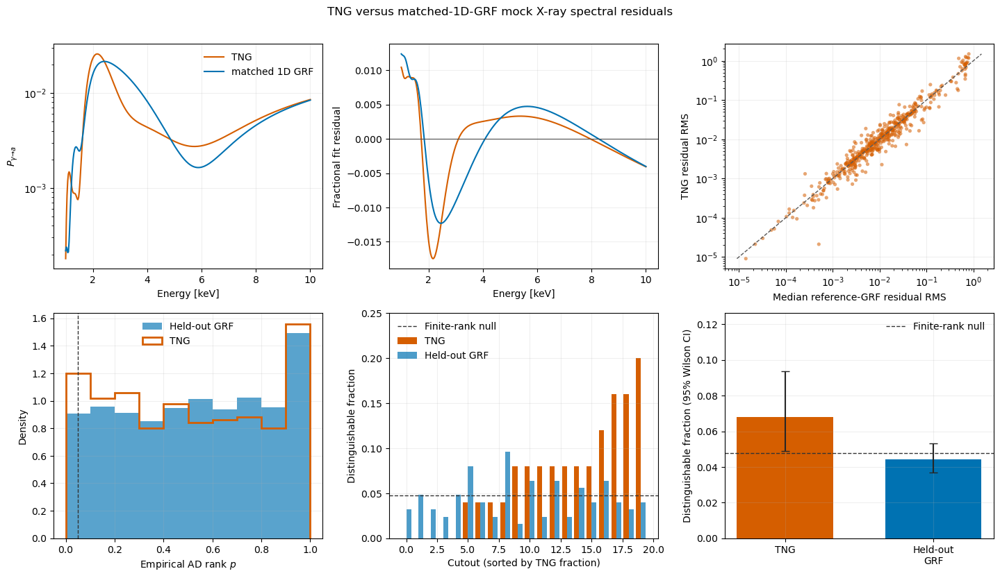

Saved to: /Users/Logan/Documents/New project/ALPs_IllustrisTNG_LoganPeschieras/spectral_proxy_results_independent_null


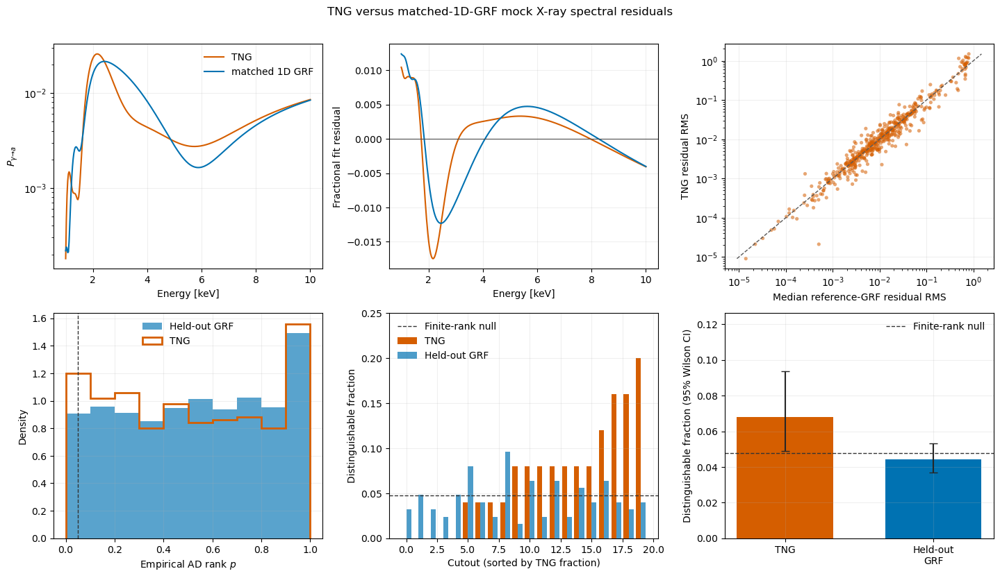

In [20]:
RUN_SPECTRAL_PROXY = True
SAVE_SPECTRAL_PROXY_RESULTS = True

if RUN_SPECTRAL_PROXY:
    spectral_result = run_spectral_residual_proxy(SP_CFG)
    display(spectral_result["summary"].to_frame())
    display(spectral_result["quality_counts"].to_frame())
    display(
        spectral_result["sightline_table"]
        .groupby("model")[["residual_rms", "residual_min", "residual_max_abs", "fit_photon_index"]]
        .agg(["count", "median", "mean", "std"])
    )
    spectral_figure = plot_spectral_residual_proxy(spectral_result)
    plt.show()
    if SAVE_SPECTRAL_PROXY_RESULTS:
        print("Saved to:", save_spectral_proxy_results(spectral_result))

